
**Identifying Temporal Customer-Perception Patterns Associated with Business Closure: An LLM-Based Review Analysis with a Multimodal Extension**

Aslihan Berber  
03798114  
Master in Management and Technology  
Technical University of Munich (TUM)

# **1) Environment and Data Setup**

In [ ]:

# Imports


from pathlib import Path
import os
from google.colab import drive

import zipfile
import tarfile

import pandas as pd
import numpy as np

import json

import matplotlib.pyplot as plt

import time

In [ ]:

# Mounting Google Drive


drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:

# Yelp Dataset: Initial File Setup and Archive Inspection


# In this first step, I mount Google Drive and check whether my downloaded
# Yelp dataset files are stored correctly in my thesis project folder.
# The Yelp download files are ZIP files, but inside them there are TAR archives.
# Therefore, before loading any data, I first inspect the archive structure.


# Defining project folder paths

# Main thesis folder in Google Drive
BASE_DIR = Path("/content/drive/MyDrive/TUM_thesis_digital_marketing")

# Raw data folders
RAW_DIR = BASE_DIR / "raw"
JSON_DIR = RAW_DIR / "json"
PHOTOS_DIR = RAW_DIR / "photos"

# ZIP files downloaded from Yelp
json_zip_path = JSON_DIR / "Yelp-JSON.zip"
photos_zip_path = PHOTOS_DIR / "Yelp-Photos.zip"

# Folders where my extracted files will be stored
json_zip_extract_dir = JSON_DIR / "zip_extracted"
json_tar_extract_dir = JSON_DIR / "tar_extracted"

# Create extraction folders if they do not already exist
json_zip_extract_dir.mkdir(parents=True, exist_ok=True)
json_tar_extract_dir.mkdir(parents=True, exist_ok=True)


# Checking whether the main folders and ZIP files exist

print("Folder checks:")
print("BASE_DIR exists:", BASE_DIR.exists())
print("RAW_DIR exists:", RAW_DIR.exists())
print("JSON_DIR exists:", JSON_DIR.exists())
print("PHOTOS_DIR exists:", PHOTOS_DIR.exists())

print("\nFile checks:")
print("JSON ZIP exists:", json_zip_path.exists())
print("Photos ZIP exists:", photos_zip_path.exists())

print("\nJSON ZIP path:")
print(json_zip_path)

print("\nPhotos ZIP path:")
print(photos_zip_path)

# Stop the code if the JSON ZIP file cannot be found
if not json_zip_path.exists():
    raise FileNotFoundError(f"JSON ZIP file was not found at: {json_zip_path}")


# The size of the JSON ZIP file

json_zip_size_gb = json_zip_path.stat().st_size / (1024**3)
print("\nJSON ZIP size:", round(json_zip_size_gb, 2), "GB")


# The ZIP file should contain a documentation PDF and a TAR archive.
# The actual JSON dataset files are inside the TAR archive.

print("\nContents of Yelp-JSON.zip:")

with zipfile.ZipFile(json_zip_path, "r") as zip_file:
    zip_members = zip_file.infolist()

    print("Number of items inside ZIP:", len(zip_members))

    total_uncompressed_size_gb = sum(item.file_size for item in zip_members) / (1024**3)
    print("Total uncompressed size:", round(total_uncompressed_size_gb, 2), "GB")

    for item in zip_members:
        item_size_mb = item.file_size / (1024**2)
        print(item.filename, "|", round(item_size_mb, 2), "MB")


# I first check whether the real TAR file already exists.
# This avoids extracting the ZIP again when I run the notebook multiple times.

existing_tar_files = [
    file for file in json_zip_extract_dir.rglob("*.tar")
    if "__MACOSX" not in str(file)
]

if len(existing_tar_files) == 0:
    print("\nNo TAR file found yet, so I am extracting the JSON ZIP file.")

    with zipfile.ZipFile(json_zip_path, "r") as zip_file:
        zip_file.extractall(json_zip_extract_dir)

    print("ZIP file extraction completed.")
else:
    print("\nTAR file already exists, so I do not need to extract the ZIP again.")



# The ZIP also contains some __MACOSX files, which are only metadata files.
# I exclude those and keep only the real Yelp TAR archive.

tar_files = [
    file for file in json_zip_extract_dir.rglob("*.tar")
    if "__MACOSX" not in str(file)
]

print("\nTAR files found:")

for file in tar_files:
    file_size_gb = file.stat().st_size / (1024**3)
    print(file, "|", round(file_size_gb, 2), "GB")

if len(tar_files) == 0:
    raise FileNotFoundError("No real TAR file was found after extracting the ZIP file.")

# Use the first real TAR file found
json_tar_path = tar_files[0]

print("\nTAR file selected for inspection:")
print(json_tar_path)


# This step shows the actual JSON files available in the dataset.
# I only inspect the TAR contents here; I do not extract them yet.

print("\nContents of the Yelp JSON TAR file:")

with tarfile.open(json_tar_path, "r") as tar_file:
    tar_members = tar_file.getmembers()

    print("Number of items inside TAR:", len(tar_members))

    for item in tar_members:
        item_size_mb = item.size / (1024**2)
        print(item.name, "|", round(item_size_mb, 2), "MB")

Folder checks:
BASE_DIR exists: True
RAW_DIR exists: True
JSON_DIR exists: True
PHOTOS_DIR exists: True

File checks:
JSON ZIP exists: True
Photos ZIP exists: True

JSON ZIP path:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/json/Yelp-JSON.zip

Photos ZIP path:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/Yelp-Photos.zip

JSON ZIP size: 4.05 GB

Contents of Yelp-JSON.zip:
Number of items inside ZIP: 5
Total uncompressed size: 4.05 GB
Yelp JSON/ | 0.0 MB
Yelp JSON/Yelp Dataset Documentation & ToS copy.pdf | 0.12 MB
__MACOSX/Yelp JSON/._Yelp Dataset Documentation & ToS copy.pdf | 0.0 MB
Yelp JSON/yelp_dataset.tar | 4142.66 MB
__MACOSX/Yelp JSON/._yelp_dataset.tar | 0.0 MB

TAR file already exists, so I do not need to extract the ZIP again.

TAR files found:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/json/zip_extracted/Yelp JSON/yelp_dataset.tar | 4.05 GB

TAR file selected for inspection:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/js

In [ ]:
# Extracting Yelp JSON TAR Archive


import tarfile
from pathlib import Path

# These paths ae defined in the previous cell,
# but I define them again to make this cell safer to rerun.
BASE_DIR = Path("/content/drive/MyDrive/TUM_thesis_digital_marketing")

RAW_DIR = BASE_DIR / "raw"
JSON_DIR = RAW_DIR / "json"

json_zip_extract_dir = JSON_DIR / "zip_extracted"
json_tar_extract_dir = JSON_DIR / "tar_extracted"

# Locating the real TAR file, excluding the unnecessary __MACOSX metadata files
tar_files = [
    file for file in json_zip_extract_dir.rglob("*.tar")
    if "__MACOSX" not in str(file)
]

if len(tar_files) == 0:
    raise FileNotFoundError("No real TAR file was found. Please check the previous extraction step.")

json_tar_path = tar_files[0]

print("TAR file to extract:")
print(json_tar_path)

print("\nExtraction folder:")
print(json_tar_extract_dir)

# Checking whether JSON files have already been extracted
existing_json_files = list(json_tar_extract_dir.glob("*.json"))

if len(existing_json_files) == 0:
    print("\nNo JSON files found yet, so I am extracting the TAR archive.")

    with tarfile.open(json_tar_path, "r") as tar_file:
        tar_file.extractall(json_tar_extract_dir)

    print("TAR extraction completed.")
else:
    print("\nJSON files already exist, so I do not need to extract the TAR again.")

# Show the files now available after extraction
print("\nFiles in the TAR extraction folder:")

for file in json_tar_extract_dir.iterdir():
    if file.is_file():
        file_size_mb = file.stat().st_size / (1024**2)
        print(file.name, "|", round(file_size_mb, 2), "MB")

TAR file to extract:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/json/zip_extracted/Yelp JSON/yelp_dataset.tar

Extraction folder:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/json/tar_extracted

JSON files already exist, so I do not need to extract the TAR again.

Files in the TAR extraction folder:
yelp_academic_dataset_business.json | 113.36 MB
yelp_academic_dataset_user.json | 3207.52 MB
yelp_academic_dataset_checkin.json | 273.67 MB
yelp_academic_dataset_tip.json | 172.24 MB
yelp_academic_dataset_review.json | 5094.4 MB
Dataset_User_Agreement.pdf | 0.08 MB


In [ ]:
# Final Project paths

# Main thesis project folder
BASE_DIR = Path("/content/drive/MyDrive/TUM_thesis_digital_marketing")

# Raw data folders
RAW_DIR = BASE_DIR / "raw"
JSON_DIR = RAW_DIR / "json"
PHOTOS_DIR = RAW_DIR / "photos"

# Extracted JSON folder
json_tar_extract_dir = JSON_DIR / "tar_extracted"

# Individual extracted Yelp JSON files
business_path = json_tar_extract_dir / "yelp_academic_dataset_business.json"
review_path = json_tar_extract_dir / "yelp_academic_dataset_review.json"
checkin_path = json_tar_extract_dir / "yelp_academic_dataset_checkin.json"
tip_path = json_tar_extract_dir / "yelp_academic_dataset_tip.json"
user_path = json_tar_extract_dir / "yelp_academic_dataset_user.json"

print("business_path exists:", business_path.exists())
print("review_path exists:", review_path.exists())
print("checkin_path exists:", checkin_path.exists())
print("tip_path exists:", tip_path.exists())
print("user_path exists:", user_path.exists())

business_path exists: True
review_path exists: True
checkin_path exists: True
tip_path exists: True
user_path exists: True


# **2) Business Dataset Exploration**

In [ ]:
# The Yelp JSON files are JSON-lines files.
# This means each row is one separate JSON object.
# Therefore, I use lines=True when loading the file with pandas.

business_df = pd.read_json(business_path, lines=True)

print("business_df loaded.")
print("Shape:", business_df.shape)

business_df.head()

# Show all column names in the business dataset

business_df.columns.tolist()

# Show data types and non-null counts for each column

business_df.info()


business_df loaded.
Shape: (150346, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150346 entries, 0 to 150345
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   business_id   150346 non-null  object 
 1   name          150346 non-null  object 
 2   address       150346 non-null  object 
 3   city          150346 non-null  object 
 4   state         150346 non-null  object 
 5   postal_code   150346 non-null  object 
 6   latitude      150346 non-null  float64
 7   longitude     150346 non-null  float64
 8   stars         150346 non-null  float64
 9   review_count  150346 non-null  int64  
 10  is_open       150346 non-null  int64  
 11  attributes    136602 non-null  object 
 12  categories    150243 non-null  object 
 13  hours         127123 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 16.1+ MB


In [ ]:
# View the most relevant columns for this thesis

business_df[
    [
        "business_id",
        "name",
        "city",
        "state",
        "stars",
        "review_count",
        "is_open",
        "categories"
    ]
].head(10)

,business_id,name,city,state,stars,review_count,is_open,categories
0,Pns2l4eNsfO8kk83dixA6A,"Abby Rappoport, LAC, CMQ",Santa Barbara,CA,5.0,7,0,"Doctors, Traditional Chinese Medicine, Naturop..."
1,mpf3x-BjTdTEA3yCZrAYPw,The UPS Store,Affton,MO,3.0,15,1,"Shipping Centers, Local Services, Notaries, Ma..."
2,tUFrWirKiKi_TAnsVWINQQ,Target,Tucson,AZ,3.5,22,0,"Department Stores, Shopping, Fashion, Home & G..."
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,Philadelphia,PA,4.0,80,1,"Restaurants, Food, Bubble Tea, Coffee & Tea, B..."
4,mWMc6_wTdE0EUBKIGXDVfA,Perkiomen Valley Brewery,Green Lane,PA,4.5,13,1,"Brewpubs, Breweries, Food"
5,CF33F8-E6oudUQ46HnavjQ,Sonic Drive-In,Ashland City,TN,2.0,6,1,"Burgers, Fast Food, Sandwiches, Food, Ice Crea..."
6,n_0UpQx1hsNbnPUSlodU8w,Famous Footwear,Brentwood,MO,2.5,13,1,"Sporting Goods, Fashion, Shoe Stores, Shopping..."
7,qkRM_2X51Yqxk3btlwAQIg,Temple Beth-El,St. Petersburg,FL,3.5,5,1,"Synagogues, Religious Organizations"
8,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,Affton,MO,3.0,19,0,"Pubs, Restaurants, Italian, Bars, American (Tr..."
9,bBDDEgkFA1Otx9Lfe7BZUQ,Sonic Drive-In,Nashville,TN,1.5,10,1,"Ice Cream & Frozen Yogurt, Fast Food, Burgers,..."


In [ ]:
# Open vs. closed businesses

# Yelp uses is_open = 1 for open businesses and is_open = 0 for closed businesses.
# Later, I will transform this into a closure outcome variable.

print("Open vs. closed businesses:")
print(business_df["is_open"].value_counts())

print("\nOpen vs. closed businesses in percentage:")
print((business_df["is_open"].value_counts(normalize=True) * 100).round(2))

Open vs. closed businesses:
is_open
1    119698
0     30648
Name: count, dtype: int64

Open vs. closed businesses in percentage:
is_open
1    79.62
0    20.38
Name: proportion, dtype: float64


In [ ]:
# Missing values

missing_counts = business_df.isna().sum().sort_values(ascending=False)
missing_percentages = (business_df.isna().mean() * 100).sort_values(ascending=False).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": missing_percentages
})

missing_summary

,missing_count,missing_percentage
hours,23223,15.45
attributes,13744,9.14
categories,103,0.07
address,0,0.00
business_id,0,0.00
name,0,0.00
postal_code,0,0.00
state,0,0.00
city,0,0.00
latitude,0,0.00


In [ ]:
# Location distribution

print("Number of unique states:", business_df["state"].nunique())
print("Number of unique cities:", business_df["city"].nunique())

print("\nTop 20 states by number of businesses:")
print(business_df["state"].value_counts().head(20))

print("\nTop 20 cities by number of businesses:")
print(business_df["city"].value_counts().head(20))

Number of unique states: 27
Number of unique cities: 1416

Top 20 states by number of businesses:
state
PA    34039
FL    26330
TN    12056
IN    11247
MO    10913
LA     9924
AZ     9912
NJ     8536
NV     7715
AB     5573
CA     5203
ID     4467
DE     2265
IL     2145
TX        4
CO        3
HI        2
MA        2
WA        2
UT        1
Name: count, dtype: int64

Top 20 cities by number of businesses:
city
Philadelphia        14569
Tucson               9250
Tampa                9050
Indianapolis         7540
Nashville            6971
New Orleans          6209
Reno                 5935
Edmonton             5054
Saint Louis          4827
Santa Barbara        3829
Boise                2937
Clearwater           2221
Saint Petersburg     1663
Metairie             1643
Sparks               1624
Wilmington           1446
Franklin             1414
St. Louis            1255
St. Petersburg       1185
Meridian             1043
Name: count, dtype: int64


In [ ]:
# Stars and review counts

print(business_df[["stars", "review_count"]].describe())

# Distribution of star ratings

print(business_df["stars"].value_counts().sort_index())

# Businesses with the highest number of reviews

print(business_df[
    [
        "business_id",
        "name",
        "city",
        "state",
        "stars",
        "review_count",
        "is_open",
        "categories"
    ]
].sort_values("review_count", ascending=False).head(20))



               stars   review_count
count  150346.000000  150346.000000
mean        3.596724      44.866561
std         0.974421     121.120136
min         1.000000       5.000000
25%         3.000000       8.000000
50%         3.500000      15.000000
75%         4.500000      37.000000
max         5.000000    7568.000000
stars
1.0     1986
1.5     4932
2.0     9527
2.5    14316
3.0    18453
3.5    26519
4.0    31125
4.5    27181
5.0    16307
Name: count, dtype: int64
                   business_id                                name  \
113731  _ab50qdWOk0DdB6XOrBitw                   Acme Oyster House   
112552  ac1AeYqs8Z4_e2X5M3if2A                        Oceana Grill   
91757   GXFMD0Z4jEVZBCsbPf4CTQ  Hattie B’s Hot Chicken - Nashville   
143157  ytynqOUb3hjKeJfRj5Tshw             Reading Terminal Market   
147081  oBNrLz4EDhiscSlbOl8uAw          Ruby Slipper - New Orleans   
100024  iSRTaT9WngzB8JJ2YKJUig                 Mother's Restaurant   
31033   VQcCL9PiNL_wkGf-uF3fjg       

In [ ]:
# Creating restaurant subset

# I filter the business dataset to keep only businesses
# whose category field contains the word "Restaurants".

restaurants_df = business_df[
    business_df["categories"].notna() &
    business_df["categories"].str.contains("Restaurants", case=False, na=False)
].copy()

print("Total number of businesses:", len(business_df))
print("Total number of restaurant businesses:", len(restaurants_df))

print("\nOpen vs. closed restaurants:")
print(restaurants_df["is_open"].value_counts())

print("\nOpen vs. closed restaurants in percentage:")
print((restaurants_df["is_open"].value_counts(normalize=True) * 100).round(2))

Total number of businesses: 150346
Total number of restaurant businesses: 52268

Open vs. closed restaurants:
is_open
1    34987
0    17281
Name: count, dtype: int64

Open vs. closed restaurants in percentage:
is_open
1    66.94
0    33.06
Name: proportion, dtype: float64


In [ ]:
# Inspecting restaurant subset

restaurants_df[
    [
        "business_id",
        "name",
        "city",
        "state",
        "stars",
        "review_count",
        "is_open",
        "categories"
    ]
].head(20)

,business_id,name,city,state,stars,review_count,is_open,categories
3,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,Philadelphia,PA,4.0,80,1,"Restaurants, Food, Bubble Tea, Coffee & Tea, B..."
5,CF33F8-E6oudUQ46HnavjQ,Sonic Drive-In,Ashland City,TN,2.0,6,1,"Burgers, Fast Food, Sandwiches, Food, Ice Crea..."
8,k0hlBqXX-Bt0vf1op7Jr1w,Tsevi's Pub And Grill,Affton,MO,3.0,19,0,"Pubs, Restaurants, Italian, Bars, American (Tr..."
9,bBDDEgkFA1Otx9Lfe7BZUQ,Sonic Drive-In,Nashville,TN,1.5,10,1,"Ice Cream & Frozen Yogurt, Fast Food, Burgers,..."
11,eEOYSgkmpB90uNA7lDOMRA,Vietnamese Food Truck,Tampa Bay,FL,4.0,10,1,"Vietnamese, Food, Restaurants, Food Trucks"
12,il_Ro8jwPlHresjw9EGmBg,Denny's,Indianapolis,IN,2.5,28,1,"American (Traditional), Restaurants, Diners, B..."
14,0bPLkL0QhhPO5kt1_EXmNQ,Zio's Italian Market,Largo,FL,4.5,100,0,"Food, Delis, Italian, Bakeries, Restaurants"
15,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,Philadelphia,PA,4.0,245,1,"Sushi Bars, Restaurants, Japanese"
19,ROeacJQwBeh05Rqg7F6TCg,BAP,Philadelphia,PA,4.5,205,1,"Korean, Restaurants"
20,WKMJwqnfZKsAae75RMP6jA,Roast Coffeehouse and Wine Bar,Edmonton,AB,4.0,40,0,"Coffee & Tea, Food, Cafes, Bars, Wine Bars, Re..."


In [ ]:
# Restaurant subset: location distribution

print("Restaurant dataframe shape:", restaurants_df.shape)

print("\nTop 20 restaurant states:")
print(restaurants_df["state"].value_counts().head(20))

print("\nTop 20 restaurant cities:")
print(restaurants_df["city"].value_counts().head(20))

Restaurant dataframe shape: (52268, 14)

Top 20 restaurant states:
state
PA     12641
FL      8731
TN      4352
MO      4247
IN      4150
LA      3640
NJ      3341
AZ      2671
AB      2410
NV      1673
ID      1302
CA      1161
IL       983
DE       961
NC         1
CO         1
HI         1
MT         1
XMS        1
Name: count, dtype: int64

Top 20 restaurant cities:
city
Philadelphia        5852
Tampa               2960
Indianapolis        2862
Nashville           2502
Tucson              2466
New Orleans         2259
Edmonton            2166
Saint Louis         1790
Reno                1286
Boise                847
Santa Barbara        767
Clearwater           678
Wilmington           619
St. Louis            543
Metairie             522
Saint Petersburg     491
Franklin             444
St. Petersburg       404
Sparks               334
Brandon              326
Name: count, dtype: int64


In [ ]:
# Restaurant subset: rating and review count summary

restaurants_df[["stars", "review_count"]].describe()

,stars,review_count
count,52268.000000,52268.000000
mean,3.515172,87.267142
std,0.829593,188.939711
min,1.000000,5.000000
25%,3.000000,13.000000
50%,3.500000,33.000000
75%,4.000000,89.000000
max,5.000000,7568.000000


In [ ]:
# Exploring Italian restaurants in the full Yelp restaurant dataset

# Here I check whether using all Italian restaurants in the dataset


italian_all_df = restaurants_df[
    restaurants_df["categories"].notna() &
    restaurants_df["categories"].str.contains("Italian", case=False, regex=False)
].copy()

print("Total restaurants in full restaurant dataset:", len(restaurants_df))
print("Total Italian restaurants in full dataset:", len(italian_all_df))

print("\nOpen vs. closed Italian restaurants:")
print(italian_all_df["is_open"].value_counts())

print("\nOpen vs. closed Italian restaurants in percentage:")
print((italian_all_df["is_open"].value_counts(normalize=True) * 100).round(2))

print("\nItalian restaurants: stars and review count summary")
display(italian_all_df[["stars", "review_count"]].describe())

Total restaurants in full restaurant dataset: 52268
Total Italian restaurants in full dataset: 4573

Open vs. closed Italian restaurants:
is_open
1    2953
0    1620
Name: count, dtype: int64

Open vs. closed Italian restaurants in percentage:
is_open
1    64.57
0    35.43
Name: proportion, dtype: float64

Italian restaurants: stars and review count summary


,stars,review_count
count,4573.000000,4573.000000
mean,3.510059,92.396676
std,0.783139,156.779313
min,1.000000,5.000000
25%,3.000000,18.000000
50%,3.500000,44.000000
75%,4.000000,108.000000
max,5.000000,4250.000000


In [ ]:
# Creating Pennsylvania Italian restaurant subset

# This subset keeps restaurants that:
# 1. are in Pennsylvania (state == "PA")
# 2. have "Italian" in their category labels

pa_italian_df = restaurants_df[
    (restaurants_df["state"] == "PA") &
    (restaurants_df["categories"].notna()) &
    (restaurants_df["categories"].str.contains("Italian", case=False, regex=False))
].copy()

print("Total restaurants in full restaurant dataset:", len(restaurants_df))
print("Total Italian restaurants in full dataset:", len(italian_all_df))
print("Pennsylvania Italian restaurants:", len(pa_italian_df))

print("\nOpen vs. closed Pennsylvania Italian restaurants:")
print(pa_italian_df["is_open"].value_counts())

print("\nOpen vs. closed Pennsylvania Italian restaurants in percentage:")
print((pa_italian_df["is_open"].value_counts(normalize=True) * 100).round(2))

print("\nPennsylvania Italian restaurants: stars and review count summary")
display(pa_italian_df[["stars", "review_count"]].describe())

Total restaurants in full restaurant dataset: 52268
Total Italian restaurants in full dataset: 4573
Pennsylvania Italian restaurants: 1433

Open vs. closed Pennsylvania Italian restaurants:
is_open
1    909
0    524
Name: count, dtype: int64

Open vs. closed Pennsylvania Italian restaurants in percentage:
is_open
1    63.43
0    36.57
Name: proportion, dtype: float64

Pennsylvania Italian restaurants: stars and review count summary


,stars,review_count
count,1433.000000,1433.000000
mean,3.553385,96.762038
std,0.740944,200.136071
min,1.000000,5.000000
25%,3.000000,21.000000
50%,3.500000,45.000000
75%,4.000000,103.000000
max,5.000000,4250.000000


In [ ]:
# Pennsylvania Italian restaurants by city

print("Top 30 cities for Pennsylvania Italian restaurants:")
print(pa_italian_df["city"].value_counts().head(30))

Top 30 cities for Pennsylvania Italian restaurants:
city
Philadelphia         505
West Chester          37
Levittown             22
King of Prussia       21
Doylestown            21
Downingtown           21
Conshohocken          20
Exton                 18
Bensalem              18
Phoenixville          17
Lansdale              17
Wayne                 17
Malvern               16
Norristown            16
Havertown             16
Pottstown             15
Newtown               15
Langhorne             14
Hatboro               14
Media                 14
Springfield           13
Kennett Square        13
Glen Mills            13
North Wales           13
Glenside              13
Warminster            12
Ardmore               12
Huntingdon Valley     12
Drexel Hill           11
Blue Bell             11
Name: count, dtype: int64


# **3) Final Restaurant Sample Construction**

In [ ]:
# Loading reviews only for Pennsylvania Italian restaurants

# The full review file is very large.
# So instead of loading all reviews into memory, I read it in chunks
# and keep only reviews that belong to the Pennsylvania Italian restaurant sample.

pa_italian_business_ids = set(pa_italian_df["business_id"])

review_chunks = []

chunk_size = 100_000

for chunk in pd.read_json(review_path, lines=True, chunksize=chunk_size):
    filtered_chunk = chunk[chunk["business_id"].isin(pa_italian_business_ids)].copy()

    if len(filtered_chunk) > 0:
        review_chunks.append(filtered_chunk)

pa_italian_reviews_df = pd.concat(review_chunks, ignore_index=True)

print("PA Italian reviews loaded.")
print("Shape:", pa_italian_reviews_df.shape)

pa_italian_reviews_df.head()

PA Italian reviews loaded.
Shape: (143951, 9)


,review_id,user_id,business_id,stars,useful,funny,cool,text,date
0,8JFGBuHMoiNDyfcxuWNtrA,smOvOajNG0lS4Pq7d8g4JQ,RZtGWDLCAtuipwaZ-UfjmQ,4,0,0,0,Good food--loved the gnocchi with marinara\nth...,2009-10-14 19:57:14
1,DyrAIuKl60j_X8Yrrv-kpg,mNsVyC9tQVYtzLOCbh2Piw,MWmXGQ98KbRo3vsS5nZhMA,5,1,0,0,I recently had dinner here with my wife over t...,2014-10-27 02:47:28
2,-P5E9BYUaK7s3PwBF5oAyg,Jha0USGDMefGFRLik_xFQg,bMratNjTG5ZFEA6hVyr-xQ,5,0,0,0,First time there and it was excellent!!! It fe...,2017-02-19 13:32:05
3,jSoo6p_GpvYRHG2QK6WE2g,EfG0nInFMbiO9Hy7A6B2cQ,fGYnHzFr1z2kv7bPRW6VMA,3,1,0,0,Sometimes this food is very very good. Unfort...,2017-08-08 01:37:37
4,YmDYCDkRl3cof1yGdllW2Q,9oHOoqk-HlwDS2DlHLi_0g,TttFjRQ-8Iz8by4hsD7iOQ,5,0,0,0,Last night we tried to get into the oldest Ita...,2017-11-06 17:26:43


In [ ]:

# Basic review date inspection

pa_italian_reviews_df["date"] = pd.to_datetime(pa_italian_reviews_df["date"])

print("Earliest review date:", pa_italian_reviews_df["date"].min())
print("Latest review date:", pa_italian_reviews_df["date"].max())

print("\nReviews per year:")
print(pa_italian_reviews_df["date"].dt.year.value_counts().sort_index())

Earliest review date: 2005-02-16 04:06:26
Latest review date: 2022-01-19 19:27:53

Reviews per year:
date
2005       19
2006      137
2007      578
2008     1733
2009     3013
2010     5117
2011     7398
2012     9366
2013    10899
2014    12575
2015    14494
2016    14860
2017    15382
2018    15268
2019    15289
2020     8642
2021     8757
2022      424
Name: count, dtype: int64


In [ ]:
# Review coverage per restaurant

review_coverage_df = (
    pa_italian_reviews_df
    .groupby("business_id")
    .agg(
        actual_review_count=("review_id", "count"),
        first_review_date=("date", "min"),
        last_review_date=("date", "max")
    )
    .reset_index()
)

review_coverage_df["review_period_days"] = (
    review_coverage_df["last_review_date"] - review_coverage_df["first_review_date"]
).dt.days

review_coverage_df["review_period_years"] = (
    review_coverage_df["review_period_days"] / 365.25
).round(2)

review_coverage_df.describe()

,actual_review_count,first_review_date,last_review_date,review_period_days,review_period_years
count,1433.000000,1433,1433,1433.000000,1433.000000
mean,100.454292,2012-01-23 15:06:57.625959424,2020-01-09 15:05:07.498255360,2907.503140,7.960412
min,5.000000,2005-02-16 04:06:26,2008-09-07 19:54:21,38.000000,0.100000
25%,22.000000,2008-11-25 16:58:01,2018-12-09 09:55:31,1445.000000,3.960000
50%,48.000000,2011-03-06 16:12:26,2021-08-14 00:51:13,2971.000000,8.130000
75%,107.000000,2014-10-02 22:47:00,2021-12-19 00:57:38,4330.000000,11.850000
max,4293.000000,2021-11-21 22:49:32,2022-01-19 19:27:53,6170.000000,16.890000
std,204.757967,NaN,NaN,1627.786237,4.456615


In [ ]:
# Review coverage summary

review_coverage_numeric_summary = review_coverage_df[
    [
        "actual_review_count",
        "review_period_days",
        "review_period_years"
    ]
].describe().round(2)

review_coverage_numeric_summary

,actual_review_count,review_period_days,review_period_years
count,1433.00,1433.00,1433.00
mean,100.45,2907.50,7.96
std,204.76,1627.79,4.46
min,5.00,38.00,0.10
25%,22.00,1445.00,3.96
50%,48.00,2971.00,8.13
75%,107.00,4330.00,11.85
max,4293.00,6170.00,16.89


In [ ]:
# Review date range summary

print("Earliest first review date:", review_coverage_df["first_review_date"].min())
print("Latest first review date:", review_coverage_df["first_review_date"].max())

print("\nEarliest last review date:", review_coverage_df["last_review_date"].min())
print("Latest last review date:", review_coverage_df["last_review_date"].max())

print("\nMedian first review date:", review_coverage_df["first_review_date"].median())
print("Median last review date:", review_coverage_df["last_review_date"].median())

Earliest first review date: 2005-02-16 04:06:26
Latest first review date: 2021-11-21 22:49:32

Earliest last review date: 2008-09-07 19:54:21
Latest last review date: 2022-01-19 19:27:53

Median first review date: 2011-03-06 16:12:26
Median last review date: 2021-08-14 00:51:13


In [ ]:
# Merging review coverage with business-level information

pa_italian_coverage_df = review_coverage_df.merge(
    pa_italian_df[
        [
            "business_id",
            "name",
            "city",
            "state",
            "stars",
            "review_count",
            "is_open",
            "categories"
        ]
    ],
    on="business_id",
    how="left"
)

print("Merged coverage dataframe shape:", pa_italian_coverage_df.shape)

pa_italian_coverage_df.head()

Merged coverage dataframe shape: (1433, 13)


,business_id,actual_review_count,first_review_date,last_review_date,review_period_days,review_period_years,name,city,state,stars,review_count,is_open,categories
0,-7wXZWnKe26iwJY_5z_AAw,121,2019-02-02 04:30:51,2022-01-10 14:06:08,1073,2.94,La Fava Restaurant and Bar,Glen Mills,PA,4.0,115,1,"Event Planning & Services, Wine Bars, Nightlif..."
1,-8gGD85_jZvapnmb3EvU3w,38,2009-08-05 19:52:39,2021-11-18 22:37:44,4488,12.29,Lew's Seafood Takeout Shop,Glenside,PA,3.0,38,1,"Seafood Markets, Sandwiches, Restaurants, Bars..."
2,-DcRlgZdSCM0nQu4w4UI7g,22,2014-12-09 15:16:10,2019-06-13 15:38:42,1647,4.51,Pizza Hut,Upper Darby,PA,2.0,20,0,"Italian, Chicken Wings, Restaurants, Pizza"
3,-HoCrhW2f7610NWGDemnjw,53,2008-07-06 14:31:09,2020-06-22 17:09:27,4369,11.96,Brazzo Pizza,Harleysville,PA,3.5,51,0,"Restaurants, Pizza, Italian, Sandwiches"
4,-HxLFWKVgXSU8JlR21PBkg,10,2010-05-02 02:32:25,2011-02-28 19:25:56,302,0.83,Carluccio's,Philadelphia,PA,4.0,9,0,"Italian, Restaurants"


# **4) Four-Period Review Dataset & Review-Based Feature Construction**

In [ ]:
# Defining Four Equal 9-Month Periods

# In this section, I define four equal nine-month periods for the final temporal design.
# The four periods cover 36 months in total:
# 1. Early pre-COVID: initial baseline and cohort-selection period
# 2. Late pre-COVID: immediate pre-shock baseline
# 3. COVID shock: main external-shock period
# 4. Adaptation/recovery: initial recovery and adjustment period


# Making sure the review date column is stored as datetime
pa_italian_reviews_df["date"] = pd.to_datetime(
    pa_italian_reviews_df["date"]
)


# Defining the four equal 9-month periods


period_definitions_4_equal = {
    "early_pre": {
        "start": pd.Timestamp("2018-09-01"),
        "end": pd.Timestamp("2019-05-31")
    },
    "late_pre": {
        "start": pd.Timestamp("2019-06-01"),
        "end": pd.Timestamp("2020-02-29")
    },
    "shock": {
        "start": pd.Timestamp("2020-03-01"),
        "end": pd.Timestamp("2020-11-30")
    },
    "adaptation_recovery": {
        "start": pd.Timestamp("2020-12-01"),
        "end": pd.Timestamp("2021-08-31")
    }
}

# Storing the full observation boundaries separately for later filtering
equal_window_start = pd.Timestamp("2018-09-01")
equal_window_end = pd.Timestamp("2021-08-31")

print("Revised four-period design:")
print("-" * 70)

for period_name, dates in period_definitions_4_equal.items():
    # Calculate the number of calendar months included in each period
    month_count = (
        (dates["end"].year - dates["start"].year) * 12
        + dates["end"].month
        - dates["start"].month
        + 1
    )

    print(
        f"{period_name:22s} | "
        f"start: {dates['start'].date()} | "
        f"end: {dates['end'].date()} | "
        f"months: {month_count}"
    )

print("-" * 70)
print("Full equal-window observation period:")
print("Start:", equal_window_start.date())
print("End:  ", equal_window_end.date())


# Checking whether the periods overlap or leave gaps

period_names_equal = list(period_definitions_4_equal.keys())

for i in range(len(period_names_equal) - 1):
    current_period = period_names_equal[i]
    next_period = period_names_equal[i + 1]

    current_end = period_definitions_4_equal[current_period]["end"]
    next_start = period_definitions_4_equal[next_period]["start"]

    expected_next_start = current_end + pd.Timedelta(days=1)

    if next_start == expected_next_start:
        print(
            f"{current_period} → {next_period}: "
            "continuous, with no overlap or gap"
        )
    else:
        print(
            f"WARNING: {current_period} → {next_period} "
            "contains a gap or overlap"
        )

Revised four-period design:
----------------------------------------------------------------------
early_pre              | start: 2018-09-01 | end: 2019-05-31 | months: 9
late_pre               | start: 2019-06-01 | end: 2020-02-29 | months: 9
shock                  | start: 2020-03-01 | end: 2020-11-30 | months: 9
adaptation_recovery    | start: 2020-12-01 | end: 2021-08-31 | months: 9
----------------------------------------------------------------------
Full equal-window observation period:
Start: 2018-09-01
End:   2021-08-31
early_pre → late_pre: continuous, with no overlap or gap
late_pre → shock: continuous, with no overlap or gap
shock → adaptation_recovery: continuous, with no overlap or gap


In [ ]:
# Creating the Fixed Baseline Cohort


# In this step, I define the restaurant cohort only once.

# A restaurant enters the cohort if:
# - it belongs to the Pennsylvania Italian restaurant subset, and
# - it has at least one Yelp review during the early pre-COVID window.
#
# After this selection, I freeze the business_ids.
# Restaurants that first appear in later windows are not added.

# The cohort includes both:
# - restaurants marked open at the Yelp dataset endpoint, and
# - restaurants marked closed at the Yelp dataset endpoint.

# This allows me to compare the later review patterns of restaurants
# that were already observable before the COVID shock.


# Selecting reviews from the first 9-month window


early_pre_reviews_equal_df = pa_italian_reviews_df[
    (pa_italian_reviews_df["date"] >= period_definitions_4_equal["early_pre"]["start"]) &
    (pa_italian_reviews_df["date"] <= period_definitions_4_equal["early_pre"]["end"])
].copy()

print("Early pre-COVID review dataset shape:")
print(early_pre_reviews_equal_df.shape)

print("\nEarly pre-COVID review date range:")
print("Start:", early_pre_reviews_equal_df["date"].min())
print("End:  ", early_pre_reviews_equal_df["date"].max())


# Identifying restaurants observable in the first window


equal_cohort_business_ids = (
    early_pre_reviews_equal_df["business_id"]
    .dropna()
    .unique()
)

print("\nRestaurants with at least one review in early pre-COVID:")
print(len(equal_cohort_business_ids))


#  Creating the fixed restaurant-level cohort


equal_4period_cohort_df = pa_italian_df[
    pa_italian_df["business_id"].isin(equal_cohort_business_ids)
].copy()

# Create the endpoint closure outcome.
# closed = 1 means Yelp marks the restaurant as closed
# closed = 0 means Yelp marks the restaurant as open
equal_4period_cohort_df["closed"] = (
    1 - equal_4period_cohort_df["is_open"]
)

print("\nFixed four-period cohort size:")
print(len(equal_4period_cohort_df))

print("\nEndpoint open/closed counts:")
print(
    equal_4period_cohort_df["is_open"]
    .value_counts()
    .sort_index()
)

print("\nEndpoint closure outcome counts:")
print(
    equal_4period_cohort_df["closed"]
    .value_counts()
    .sort_index()
)

print("\nEndpoint closure percentages:")
print(
    (
        equal_4period_cohort_df["closed"]
        .value_counts(normalize=True)
        .sort_index()
        * 100
    ).round(2)
)


#  Filtering reviews to the fixed cohort and 36-month period

equal_cohort_id_set = set(
    equal_4period_cohort_df["business_id"]
)

equal_4period_reviews_df = pa_italian_reviews_df[
    (pa_italian_reviews_df["business_id"].isin(equal_cohort_id_set)) &
    (pa_italian_reviews_df["date"] >= equal_window_start) &
    (pa_italian_reviews_df["date"] <= equal_window_end)
].copy()

print("\nFixed-cohort review dataset shape:")
print(equal_4period_reviews_df.shape)

print("\nFixed-cohort review date range:")
print("Start:", equal_4period_reviews_df["date"].min())
print("End:  ", equal_4period_reviews_df["date"].max())


# Attaching endpoint closure status to every review


equal_4period_reviews_df = equal_4period_reviews_df.merge(
    equal_4period_cohort_df[
        ["business_id", "is_open", "closed"]
    ],
    on="business_id",
    how="left"
)

print("\nReviews by endpoint closure status:")
print(
    equal_4period_reviews_df["closed"]
    .value_counts()
    .sort_index()
)

Early pre-COVID review dataset shape:
(11253, 9)

Early pre-COVID review date range:
Start: 2018-09-01 00:19:25
End:   2019-05-30 23:56:00

Restaurants with at least one review in early pre-COVID:
957

Fixed four-period cohort size:
957

Endpoint open/closed counts:
is_open
0    168
1    789
Name: count, dtype: int64

Endpoint closure outcome counts:
closed
0    789
1    168
Name: count, dtype: int64

Endpoint closure percentages:
closed
0    82.45
1    17.55
Name: proportion, dtype: float64

Fixed-cohort review dataset shape:
(32595, 9)

Fixed-cohort review date range:
Start: 2018-09-01 00:19:25
End:   2021-08-30 23:57:13

Reviews by endpoint closure status:
closed
0    29209
1     3386
Name: count, dtype: int64


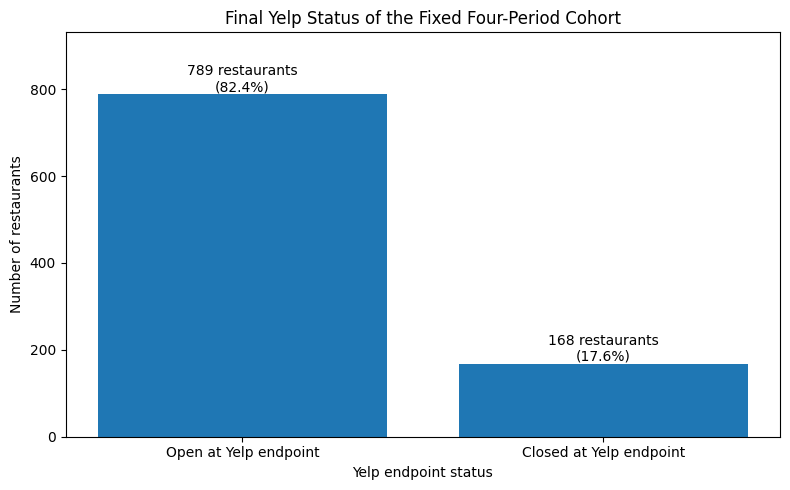

,closed,restaurant_count,status_label,percentage
0,0,789,Open at Yelp endpoint,82.45
1,1,168,Closed at Yelp endpoint,17.55


In [ ]:

# Plotting the Fixed Cohort Composition


# In this plot, I show the final Yelp status of the restaurants included in my fixed four-period cohort.

# The cohort contains only Pennsylvania Italian restaurants that
# already had at least one review during the early pre-COVID window.

# This plot does not show when a restaurant closed. It only shows whether Yelp marks it as open or closed at the dataset endpoint.


# a small summary table
equal_cohort_status_plot_df = (
    equal_4period_cohort_df["closed"]
    .value_counts()
    .sort_index()
    .rename_axis("closed")
    .reset_index(name="restaurant_count")
)

# status labels
equal_cohort_status_plot_df["status_label"] = (
    equal_cohort_status_plot_df["closed"]
    .map({
        0: "Open at Yelp endpoint",
        1: "Closed at Yelp endpoint"
    })
)

# percentages
equal_cohort_status_plot_df["percentage"] = (
    equal_cohort_status_plot_df["restaurant_count"]
    / equal_cohort_status_plot_df["restaurant_count"].sum()
    * 100
)


# Creating the bar plot


plt.figure(figsize=(8, 5))

bars = plt.bar(
    equal_cohort_status_plot_df["status_label"],
    equal_cohort_status_plot_df["restaurant_count"]
)

plt.title("Final Yelp Status of the Fixed Four-Period Cohort")
plt.xlabel("Yelp endpoint status")
plt.ylabel("Number of restaurants")

# Adding count and percentage labels above each bar
for bar, count, percentage in zip(
    bars,
    equal_cohort_status_plot_df["restaurant_count"],
    equal_cohort_status_plot_df["percentage"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count} restaurants\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.ylim(
    0,
    equal_cohort_status_plot_df["restaurant_count"].max() * 1.18
)

plt.tight_layout()



plt.show()

display(equal_cohort_status_plot_df.round(2))

In [ ]:
# Assigning Reviews to the Four Equal Periods

# In this step, I assign every review in the fixed-cohort dataset to one of the four equal nine-month periods.

# I continue using only the 957 Pennsylvania Italian restaurants selected from the early pre-COVID window. No restaurant that first
# appears in a later period can enter the cohort.

# This step allows me to check:
# - how many reviews are available in each period,
# - how many cohort restaurants have reviews in each period,
# - how many endpoint-open and endpoint-closed restaurants remain
#   observable in each period,
# - and whether all reviews fall correctly within the four windows.


# reating a function that assigns one period to each review


def assign_equal_4period(date):
    """
    Assign a review date to one of the four equal nine-month periods
    Dates outside the 36-month observation window will return NaN.
    """
    for period_name, dates in period_definitions_4_equal.items():
        if dates["start"] <= date <= dates["end"]:
            return period_name

    return np.nan


equal_4period_reviews_df["equal_period_4"] = (
    equal_4period_reviews_df["date"]
    .apply(assign_equal_4period)
)


# Checking that every review received a period label


print("Missing period assignments:")
print(equal_4period_reviews_df["equal_period_4"].isna().sum())

print("\nReview counts by assigned period:")
print(
    equal_4period_reviews_df["equal_period_4"]
    .value_counts()
    .reindex([
        "early_pre",
        "late_pre",
        "shock",
        "adaptation_recovery"
    ])
)


# Summary of review and restaurant coverage in each period


equal_period_coverage_df = (
    equal_4period_reviews_df
    .dropna(subset=["equal_period_4"])
    .groupby("equal_period_4")
    .agg(
        review_count=("review_id", "count"),
        restaurant_count=("business_id", "nunique"),
        first_review_date=("date", "min"),
        last_review_date=("date", "max")
    )
    .reindex([
        "early_pre",
        "late_pre",
        "shock",
        "adaptation_recovery"
    ])
    .reset_index()
)

print("\nOverall coverage by equal nine-month period:")
display(equal_period_coverage_df)


# Open and closed restaurants represented in each period


equal_period_status_coverage_df = (
    equal_4period_reviews_df
    .dropna(subset=["equal_period_4"])
    .groupby(["equal_period_4", "closed"])["business_id"]
    .nunique()
    .unstack(fill_value=0)
    .reindex([
        "early_pre",
        "late_pre",
        "shock",
        "adaptation_recovery"
    ])
    .reset_index()
)

equal_period_status_coverage_df = (
    equal_period_status_coverage_df
    .rename(columns={
        0: "open_restaurant_count",
        1: "closed_restaurant_count"
    })
)

print("\nRestaurant coverage by period and endpoint status:")
display(equal_period_status_coverage_df)


equal_period_coverage_complete_df = (
    equal_period_coverage_df
    .merge(
        equal_period_status_coverage_df,
        on="equal_period_4",
        how="left"
    )
)

# Calculating what share of the fixed cohort appears in each period
equal_period_coverage_complete_df["cohort_coverage_share"] = (
    equal_period_coverage_complete_df["restaurant_count"]
    / len(equal_4period_cohort_df)
)

print("\nComplete period coverage summary:")
display(
    equal_period_coverage_complete_df.round({
        "cohort_coverage_share": 3
    })
)

Missing period assignments:
95

Review counts by assigned period:
equal_period_4
early_pre              11253
late_pre               10471
shock                   5176
adaptation_recovery     5600
Name: count, dtype: int64

Overall coverage by equal nine-month period:


,equal_period_4,review_count,restaurant_count,first_review_date,last_review_date
0,early_pre,11253,957,2018-09-01 00:19:25,2019-05-30 23:56:00
1,late_pre,10471,877,2019-06-01 00:01:39,2020-02-28 23:48:00
2,shock,5176,771,2020-03-01 00:14:54,2020-11-29 23:42:19
3,adaptation_recovery,5600,749,2020-12-01 00:05:34,2021-08-30 23:57:13



Restaurant coverage by period and endpoint status:


closed,equal_period_4,open_restaurant_count,closed_restaurant_count
0,early_pre,789,168
1,late_pre,753,124
2,shock,713,58
3,adaptation_recovery,715,34



Complete period coverage summary:


,equal_period_4,review_count,restaurant_count,first_review_date,last_review_date,open_restaurant_count,closed_restaurant_count,cohort_coverage_share
0,early_pre,11253,957,2018-09-01 00:19:25,2019-05-30 23:56:00,789,168,1.000
1,late_pre,10471,877,2019-06-01 00:01:39,2020-02-28 23:48:00,753,124,0.916
2,shock,5176,771,2020-03-01 00:14:54,2020-11-29 23:42:19,713,58,0.806
3,adaptation_recovery,5600,749,2020-12-01 00:05:34,2021-08-30 23:57:13,715,34,0.783


In [ ]:
# Creating Baseline Features by Equal Period

# In this step, I summarize the ordinary Yelp review information separately for every restaurant and every nine-month period.

# The resulting variables describe:
# - how many reviews the restaurant received,
# - its average star rating,
# - how much its ratings varied,
# - the share of low-star and high-star reviews,
# - and the average useful, funny, and cool votes.

# I first create a long-format table with one row for each
# business_id x period combination. I then convert it to a wide
# restaurant-level table with separate columns for all four periods.


# Aggregating review metadata by restaurant and period

equal_period_features_long_df = (
    equal_4period_reviews_df
    .dropna(subset=["equal_period_4"])
    .groupby(["business_id", "equal_period_4"])
    .agg(
        period_review_count=("review_id", "count"),
        period_avg_stars=("stars", "mean"),
        period_std_stars=("stars", "std"),
        period_low_star_share=(
            "stars",
            lambda x: (x <= 2).mean()
        ),
        period_high_star_share=(
            "stars",
            lambda x: (x >= 4).mean()
        ),
        period_avg_useful=("useful", "mean"),
        period_avg_funny=("funny", "mean"),
        period_avg_cool=("cool", "mean")
    )
    .reset_index()
)

# When a restaurant has only one review in a period, the standard deviation is undefined. I replace it with 0 because no variation
# can be observed within that single-review period.
equal_period_features_long_df["period_std_stars"] = (
    equal_period_features_long_df["period_std_stars"]
    .fillna(0)
)

print("Long restaurant-period feature table shape:")
print(equal_period_features_long_df.shape)

print("\nExample rows from the long table:")
display(equal_period_features_long_df.head(10))


equal_period_order = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

equal_period_features_long_df["equal_period_4"] = pd.Categorical(
    equal_period_features_long_df["equal_period_4"],
    categories=equal_period_order,
    ordered=True
)

equal_period_features_long_df = (
    equal_period_features_long_df
    .sort_values(["business_id", "equal_period_4"])
)


equal_period_features_wide_df = (
    equal_period_features_long_df
    .pivot(
        index="business_id",
        columns="equal_period_4",
        values=[
            "period_review_count",
            "period_avg_stars",
            "period_std_stars",
            "period_low_star_share",
            "period_high_star_share",
            "period_avg_useful",
            "period_avg_funny",
            "period_avg_cool"
        ]
    )
)

# Flattening the two-level column names created by the pivot.
# Example:
# ("period_avg_stars", "shock")
# becomes:
# period_avg_stars_shock
equal_period_features_wide_df.columns = [
    f"{feature}_{period}"
    for feature, period in equal_period_features_wide_df.columns
]

equal_period_features_wide_df = (
    equal_period_features_wide_df
    .reset_index()
)

print("\nWide restaurant-level feature table shape:")
print(equal_period_features_wide_df.shape)

print("\nExample rows from the wide table:")
display(equal_period_features_wide_df.head())


# Merging the period features with the fixed restaurant cohort


equal_4period_baseline_df = (
    equal_4period_cohort_df
    .merge(
        equal_period_features_wide_df,
        on="business_id",
        how="left"
    )
)


# Filling missing review counts with zero

# A missing review count means that no review was observed for that restaurant in the period. Therefore, I safely represent it as 0.


review_count_columns_equal = [
    f"period_review_count_{period}"
    for period in equal_period_order
]

for column in review_count_columns_equal:
    if column in equal_4period_baseline_df.columns:
        equal_4period_baseline_df[column] = (
            equal_4period_baseline_df[column]
            .fillna(0)
            .astype(int)
        )



# These indicators show whether a restaurant received at least one review in each period. They will later help me measure continuity and
# the number of active review periods.

for period in equal_period_order:
    equal_4period_baseline_df[f"has_reviews_{period}"] = (
        equal_4period_baseline_df[
            f"period_review_count_{period}"
        ] > 0
    ).astype(int)

equal_4period_baseline_df["periods_with_reviews"] = (
    equal_4period_baseline_df[
        [
            f"has_reviews_{period}"
            for period in equal_period_order
        ]
    ]
    .sum(axis=1)
)

equal_4period_baseline_df["has_all_4_periods"] = (
    equal_4period_baseline_df["periods_with_reviews"] == 4
).astype(int)

# the resulting analysis table

print("\nFour-period baseline dataset shape:")
print(equal_4period_baseline_df.shape)

print("\nNumber of periods with reviews per restaurant:")
print(
    equal_4period_baseline_df["periods_with_reviews"]
    .value_counts()
    .sort_index()
)

print("\nComplete four-period coverage by endpoint status:")
display(
    pd.crosstab(
        equal_4period_baseline_df["closed"],
        equal_4period_baseline_df["periods_with_reviews"],
        margins=True
    )
)

inspection_columns = [
    "business_id",
    "name",
    "city",
    "closed",
    "period_review_count_early_pre",
    "period_review_count_late_pre",
    "period_review_count_shock",
    "period_review_count_adaptation_recovery",
    "period_avg_stars_early_pre",
    "period_avg_stars_late_pre",
    "period_avg_stars_shock",
    "period_avg_stars_adaptation_recovery",
    "periods_with_reviews",
    "has_all_4_periods"
]

print("\nExample restaurants in the four-period baseline dataset:")
display(
    equal_4period_baseline_df[
        inspection_columns
    ].head(10)
)

Long restaurant-period feature table shape:
(3354, 10)

Example rows from the long table:


,business_id,equal_period_4,period_review_count,period_avg_stars,period_std_stars,period_low_star_share,period_high_star_share,period_avg_useful,period_avg_funny,period_avg_cool
0,-7wXZWnKe26iwJY_5z_AAw,adaptation_recovery,29,3.620690,1.612757,0.275862,0.551724,0.551724,0.034483,0.000000
1,-7wXZWnKe26iwJY_5z_AAw,early_pre,26,4.192308,1.233507,0.153846,0.769231,0.961538,0.038462,0.076923
2,-7wXZWnKe26iwJY_5z_AAw,late_pre,42,3.833333,1.359998,0.190476,0.666667,0.785714,0.071429,0.119048
3,-7wXZWnKe26iwJY_5z_AAw,shock,17,4.117647,1.363926,0.117647,0.764706,0.529412,0.000000,0.000000
4,-8gGD85_jZvapnmb3EvU3w,adaptation_recovery,3,2.333333,1.527525,0.666667,0.333333,3.333333,2.333333,2.666667
5,-8gGD85_jZvapnmb3EvU3w,early_pre,5,1.800000,1.788854,0.800000,0.200000,0.800000,1.200000,0.200000
6,-8gGD85_jZvapnmb3EvU3w,late_pre,1,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
7,-8gGD85_jZvapnmb3EvU3w,shock,2,3.000000,2.828427,0.500000,0.500000,2.000000,0.000000,0.000000
8,-DcRlgZdSCM0nQu4w4UI7g,early_pre,1,5.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
9,-DcRlgZdSCM0nQu4w4UI7g,late_pre,1,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000



Wide restaurant-level feature table shape:
(957, 33)

Example rows from the wide table:


,business_id,period_review_count_early_pre,period_review_count_late_pre,period_review_count_shock,period_review_count_adaptation_recovery,period_avg_stars_early_pre,period_avg_stars_late_pre,period_avg_stars_shock,period_avg_stars_adaptation_recovery,period_std_stars_early_pre,...,period_avg_useful_shock,period_avg_useful_adaptation_recovery,period_avg_funny_early_pre,period_avg_funny_late_pre,period_avg_funny_shock,period_avg_funny_adaptation_recovery,period_avg_cool_early_pre,period_avg_cool_late_pre,period_avg_cool_shock,period_avg_cool_adaptation_recovery
0,-7wXZWnKe26iwJY_5z_AAw,26.0,42.0,17.0,29.0,4.192308,3.833333,4.117647,3.620690,1.233507,...,0.529412,0.551724,0.038462,0.071429,0.0,0.034483,0.076923,0.119048,0.0,0.000000
1,-8gGD85_jZvapnmb3EvU3w,5.0,1.0,2.0,3.0,1.800000,1.000000,3.000000,2.333333,1.788854,...,2.000000,3.333333,1.200000,0.000000,0.0,2.333333,0.200000,0.000000,0.0,2.666667
2,-DcRlgZdSCM0nQu4w4UI7g,1.0,1.0,NaN,NaN,5.000000,1.000000,NaN,NaN,0.000000,...,NaN,NaN,0.000000,0.000000,NaN,NaN,1.000000,0.000000,NaN,NaN
3,-HoCrhW2f7610NWGDemnjw,2.0,2.0,3.0,NaN,1.500000,4.500000,5.000000,NaN,0.707107,...,0.666667,NaN,0.500000,0.000000,0.0,NaN,0.500000,0.000000,0.0,NaN
4,-IOWVdmqsfd02_G-nJACdQ,6.0,5.0,1.0,NaN,3.666667,4.600000,5.000000,NaN,1.751190,...,1.000000,NaN,0.166667,0.000000,1.0,NaN,0.000000,0.200000,1.0,NaN



Four-period baseline dataset shape:
(957, 53)

Number of periods with reviews per restaurant:
periods_with_reviews
1     46
2    100
3    136
4    675
Name: count, dtype: int64

Complete four-period coverage by endpoint status:


periods_with_reviews,1,2,3,4,All
closed,,,,,
0,5,35,101,648,789
1,41,65,35,27,168
All,46,100,136,675,957



Example restaurants in the four-period baseline dataset:


,business_id,name,city,closed,period_review_count_early_pre,period_review_count_late_pre,period_review_count_shock,period_review_count_adaptation_recovery,period_avg_stars_early_pre,period_avg_stars_late_pre,period_avg_stars_shock,period_avg_stars_adaptation_recovery,periods_with_reviews,has_all_4_periods
0,QdN72BWoyFypdGJhhI5r7g,Bar One,Philadelphia,1,8,9,0,0,4.125000,3.666667,NaN,NaN,2,0
1,RsTF2skxLcp6qo9FdnA5PA,Pizza Hut,Langhorne,1,2,2,0,0,1.000000,2.000000,NaN,NaN,2,0
2,0sr1EyOc6Td1C-962QW88w,La Cucina Italian Eatery,Conshohocken,0,3,3,1,3,3.333333,4.000000,4.000000,4.333333,4,1
3,rF0xI_3jjlsEKp3N0Z0BuQ,Trattoria Totaro,Conshohocken,0,11,15,4,7,3.090909,3.266667,4.750000,3.428571,4,1
4,LVteL0Rnh2E_yOFCLJUPhg,Double Decker Pizza - Media,Media,0,7,5,8,7,3.428571,3.600000,4.875000,3.000000,4,1
5,wUEbysNWCtMSQAio6Ktn6Q,Lucianis Pizzeria & GRILL,Fort Washington,0,3,4,0,1,2.333333,3.000000,NaN,5.000000,3,0
6,joeRm-_7T0XTkMdKo2nbaA,Paola's Pizzeria,Wayne,0,13,8,9,7,4.384615,4.875000,4.555556,5.000000,4,1
7,isbeaPln-E0DdffLRsuFhw,Francisco's On The River,Washington Crossing,0,5,13,7,5,4.400000,3.846154,4.142857,3.800000,4,1
8,QkyEr9j7il9lJqseTbPe5w,Spasso Italian Grill,Media,0,16,22,5,9,4.125000,3.318182,3.800000,3.888889,4,1
9,-JStjL-8mRZq4ov4uI1FaQ,Luberto's Brickoven Pizza,Dublin,0,9,10,6,7,3.444444,4.100000,5.000000,4.285714,4,1


In [ ]:
# Creating Monthly Indicators Within Each Nine-Month Period


# In this step, I create an alternative monthly version of the review-based indicators.

# Instead of aggregating all reviews directly across each complete nine-month period, I first calculate the indicators separately
# for each restaurant and calendar month. I then average the monthly values within the corresponding nine-month period.

# This gives each observed calendar month equal weight. The resulting variables I kept separately from the main period-level variables
# and can later use as an alternative robustness check.



monthly_review_source_df = (
    equal_4period_reviews_df
    .dropna(subset=["equal_period_4"])
    .copy()
)

# Confirm that the review date is stored as datetime
monthly_review_source_df["date"] = pd.to_datetime(
    monthly_review_source_df["date"]
)

# Assigning each review to the first day of its calendar month
monthly_review_source_df["calendar_month"] = (
    monthly_review_source_df["date"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

print("Reviews used for monthly feature construction:")
print(len(monthly_review_source_df))

print("\nMonthly review date range:")
print(
    monthly_review_source_df["calendar_month"].min(),
    "to",
    monthly_review_source_df["calendar_month"].max()
)


# Calculating review indicators by restaurant and month


monthly_features_observed_df = (
    monthly_review_source_df
    .groupby(
        [
            "business_id",
            "equal_period_4",
            "calendar_month"
        ],
        observed=True
    )
    .agg(
        monthly_review_count=("review_id", "count"),
        monthly_avg_stars=("stars", "mean"),
        monthly_std_stars=("stars", "std"),
        monthly_low_star_share=(
            "stars",
            lambda x: (x <= 2).mean()
        ),
        monthly_high_star_share=(
            "stars",
            lambda x: (x >= 4).mean()
        ),
        monthly_avg_useful=("useful", "mean"),
        monthly_avg_funny=("funny", "mean"),
        monthly_avg_cool=("cool", "mean")
    )
    .reset_index()
)


monthly_features_observed_df["monthly_std_stars"] = (
    monthly_features_observed_df["monthly_std_stars"]
    .fillna(0)
)

print("\nObserved restaurant-month feature table shape:")
print(monthly_features_observed_df.shape)


# Creating all 36 calendar months for every cohort restaurant


# The complete grid makes sure that months with no reviews are retained. Review count is set to zero for such months, while
# ratings and customer-evaluation measures remain missing.

period_month_rows = []

for period_name in equal_period_order:

    period_start = pd.to_datetime(
        period_definitions_4_equal[period_name]["start"]
    )

    period_end = pd.to_datetime(
        period_definitions_4_equal[period_name]["end"]
    )

    months_in_period = pd.period_range(
        start=period_start,
        end=period_end,
        freq="M"
    ).to_timestamp()

    print(
        period_name,
        "- number of calendar months:",
        len(months_in_period)
    )

    for calendar_month in months_in_period:
        period_month_rows.append({
            "equal_period_4": period_name,
            "calendar_month": calendar_month
        })

period_month_grid_df = pd.DataFrame(period_month_rows)

# Cross-joining every fixed-cohort restaurant with all period-months
restaurant_month_grid_df = (
    equal_4period_cohort_df[["business_id"]]
    .drop_duplicates()
    .merge(
        period_month_grid_df,
        how="cross"
    )
)

print("\nComplete restaurant-month grid shape:")
print(restaurant_month_grid_df.shape)



# Merging observed monthly features into the complete


monthly_features_complete_df = (
    restaurant_month_grid_df
    .merge(
        monthly_features_observed_df,
        on=[
            "business_id",
            "equal_period_4",
            "calendar_month"
        ],
        how="left"
    )
)

# No review row means that the restaurant received zero Yelp reviews during that calendar month.
monthly_features_complete_df["monthly_review_count"] = (
    monthly_features_complete_df["monthly_review_count"]
    .fillna(0)
    .astype(int)
)

monthly_features_complete_df["has_reviews_in_month"] = (
    monthly_features_complete_df["monthly_review_count"] > 0
).astype(int)

print("\nComplete monthly feature table shape:")
print(monthly_features_complete_df.shape)



monthly_period_features_long_df = (
    monthly_features_complete_df
    .groupby(
        ["business_id", "equal_period_4"],
        observed=True
    )
    .agg(
        # Mean monthly review count includes zero-review months
        avg_monthly_review_count=(
            "monthly_review_count",
            "mean"
        ),

        # Number and share of months with at least one review
        active_review_months=(
            "has_reviews_in_month",
            "sum"
        ),
        active_review_month_share=(
            "has_reviews_in_month",
            "mean"
        ),

        # These indicators are averaged across observed months.

        avg_of_monthly_avg_stars=(
            "monthly_avg_stars",
            "mean"
        ),
        avg_of_monthly_std_stars=(
            "monthly_std_stars",
            "mean"
        ),
        avg_of_monthly_low_star_share=(
            "monthly_low_star_share",
            "mean"
        ),
        avg_of_monthly_high_star_share=(
            "monthly_high_star_share",
            "mean"
        ),
        avg_of_monthly_useful=(
            "monthly_avg_useful",
            "mean"
        ),
        avg_of_monthly_funny=(
            "monthly_avg_funny",
            "mean"
        ),
        avg_of_monthly_cool=(
            "monthly_avg_cool",
            "mean"
        )
    )
    .reset_index()
)

monthly_period_features_long_df["equal_period_4"] = (
    pd.Categorical(
        monthly_period_features_long_df["equal_period_4"],
        categories=equal_period_order,
        ordered=True
    )
)

monthly_period_features_long_df = (
    monthly_period_features_long_df
    .sort_values(
        ["business_id", "equal_period_4"]
    )
)

print("\nMonthly indicators averaged by nine-month period:")
print(monthly_period_features_long_df.shape)

display(
    monthly_period_features_long_df.head(12)
)


monthly_period_features_wide_df = (
    monthly_period_features_long_df
    .pivot(
        index="business_id",
        columns="equal_period_4",
        values=[
            "avg_monthly_review_count",
            "active_review_months",
            "active_review_month_share",
            "avg_of_monthly_avg_stars",
            "avg_of_monthly_std_stars",
            "avg_of_monthly_low_star_share",
            "avg_of_monthly_high_star_share",
            "avg_of_monthly_useful",
            "avg_of_monthly_funny",
            "avg_of_monthly_cool"
        ]
    )
)

monthly_period_features_wide_df.columns = [
    f"{feature}_{period}"
    for feature, period
    in monthly_period_features_wide_df.columns
]

monthly_period_features_wide_df = (
    monthly_period_features_wide_df
    .reset_index()
)

print("\nWide monthly-based feature table shape:")
print(monthly_period_features_wide_df.shape)

# Merging with the fixed cohort


equal_4period_monthly_baseline_df = (
    equal_4period_cohort_df
    .merge(
        monthly_period_features_wide_df,
        on="business_id",
        how="left"
    )
)

print("\nMonthly alternative baseline dataset shape:")
print(equal_4period_monthly_baseline_df.shape)


# Checking the monthly review-count calculation

# Every period contains nine months. Therefore, the average monthly review count multiplied by nine should equal the original period
# review count, apart from very small floating-point differences.

monthly_count_check_df = (
    equal_4period_baseline_df[
        [
            "business_id",
            "period_review_count_early_pre",
            "period_review_count_late_pre",
            "period_review_count_shock",
            "period_review_count_adaptation_recovery"
        ]
    ]
    .merge(
        equal_4period_monthly_baseline_df[
            [
                "business_id",
                "avg_monthly_review_count_early_pre",
                "avg_monthly_review_count_late_pre",
                "avg_monthly_review_count_shock",
                "avg_monthly_review_count_adaptation_recovery"
            ]
        ],
        on="business_id",
        how="left"
    )
)

for period in equal_period_order:

    monthly_count_check_df[
        f"reconstructed_review_count_{period}"
    ] = (
        monthly_count_check_df[
            f"avg_monthly_review_count_{period}"
        ] * 9
    )

    monthly_count_check_df[
        f"count_difference_{period}"
    ] = (
        monthly_count_check_df[
            f"reconstructed_review_count_{period}"
        ]
        -
        monthly_count_check_df[
            f"period_review_count_{period}"
        ]
    )

print("\nMaximum absolute review-count reconstruction difference:")

for period in equal_period_order:
    print(
        period,
        monthly_count_check_df[
            f"count_difference_{period}"
        ].abs().max()
    )



monthly_inspection_columns = [
    "business_id",
    "name",
    "closed",
    "avg_monthly_review_count_early_pre",
    "avg_monthly_review_count_late_pre",
    "avg_monthly_review_count_shock",
    "avg_monthly_review_count_adaptation_recovery",
    "active_review_months_early_pre",
    "active_review_months_late_pre",
    "active_review_months_shock",
    "active_review_months_adaptation_recovery",
    "avg_of_monthly_avg_stars_early_pre",
    "avg_of_monthly_avg_stars_late_pre",
    "avg_of_monthly_avg_stars_shock",
    "avg_of_monthly_avg_stars_adaptation_recovery"
]

print("\nExample monthly-based restaurant indicators:")

display(
    equal_4period_monthly_baseline_df[
        monthly_inspection_columns
    ].head(10)
)

Reviews used for monthly feature construction:
32500

Monthly review date range:
2018-09-01 00:00:00 to 2021-08-01 00:00:00

Observed restaurant-month feature table shape:
(14626, 11)
early_pre - number of calendar months: 9
late_pre - number of calendar months: 9
shock - number of calendar months: 9
adaptation_recovery - number of calendar months: 9

Complete restaurant-month grid shape:
(34452, 3)

Complete monthly feature table shape:
(34452, 12)

Monthly indicators averaged by nine-month period:
(3828, 12)


,business_id,equal_period_4,avg_monthly_review_count,active_review_months,active_review_month_share,avg_of_monthly_avg_stars,avg_of_monthly_std_stars,avg_of_monthly_low_star_share,avg_of_monthly_high_star_share,avg_of_monthly_useful,avg_of_monthly_funny,avg_of_monthly_cool
1,-7wXZWnKe26iwJY_5z_AAw,early_pre,2.888889,4,0.444444,4.232143,1.148989,0.133929,0.794643,0.959821,0.035714,0.071429
2,-7wXZWnKe26iwJY_5z_AAw,late_pre,4.666667,9,1.000000,3.802525,0.977789,0.190572,0.644613,0.799158,0.047138,0.092593
3,-7wXZWnKe26iwJY_5z_AAw,shock,1.888889,8,0.888889,3.875000,0.606671,0.187500,0.739583,0.593750,0.000000,0.000000
0,-7wXZWnKe26iwJY_5z_AAw,adaptation_recovery,3.222222,9,1.000000,3.823016,0.931271,0.187302,0.573810,0.380159,0.022222,0.000000
5,-8gGD85_jZvapnmb3EvU3w,early_pre,0.555556,5,0.555556,1.800000,0.000000,0.800000,0.200000,0.800000,1.200000,0.200000
6,-8gGD85_jZvapnmb3EvU3w,late_pre,0.111111,1,0.111111,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
7,-8gGD85_jZvapnmb3EvU3w,shock,0.222222,2,0.222222,3.000000,0.000000,0.500000,0.500000,2.000000,0.000000,0.000000
4,-8gGD85_jZvapnmb3EvU3w,adaptation_recovery,0.333333,3,0.333333,2.333333,0.000000,0.666667,0.333333,3.333333,2.333333,2.666667
9,-DcRlgZdSCM0nQu4w4UI7g,early_pre,0.111111,1,0.111111,5.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000
10,-DcRlgZdSCM0nQu4w4UI7g,late_pre,0.111111,1,0.111111,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000



Wide monthly-based feature table shape:
(957, 41)

Monthly alternative baseline dataset shape:
(957, 55)

Maximum absolute review-count reconstruction difference:
early_pre 0.0
late_pre 0.0
shock 0.0
adaptation_recovery 0.0

Example monthly-based restaurant indicators:


,business_id,name,closed,avg_monthly_review_count_early_pre,avg_monthly_review_count_late_pre,avg_monthly_review_count_shock,avg_monthly_review_count_adaptation_recovery,active_review_months_early_pre,active_review_months_late_pre,active_review_months_shock,active_review_months_adaptation_recovery,avg_of_monthly_avg_stars_early_pre,avg_of_monthly_avg_stars_late_pre,avg_of_monthly_avg_stars_shock,avg_of_monthly_avg_stars_adaptation_recovery
0,QdN72BWoyFypdGJhhI5r7g,Bar One,1,0.888889,1.000000,0.000000,0.000000,5.0,6.0,0.0,0.0,4.050000,3.888889,NaN,NaN
1,RsTF2skxLcp6qo9FdnA5PA,Pizza Hut,1,0.222222,0.222222,0.000000,0.000000,1.0,2.0,0.0,0.0,1.000000,2.000000,NaN,NaN
2,0sr1EyOc6Td1C-962QW88w,La Cucina Italian Eatery,0,0.333333,0.333333,0.111111,0.333333,3.0,3.0,1.0,3.0,3.333333,4.000000,4.000000,4.333333
3,rF0xI_3jjlsEKp3N0Z0BuQ,Trattoria Totaro,0,1.222222,1.666667,0.444444,0.777778,6.0,8.0,2.0,5.0,3.375000,3.250000,4.833333,3.400000
4,LVteL0Rnh2E_yOFCLJUPhg,Double Decker Pizza - Media,0,0.777778,0.555556,0.888889,0.777778,6.0,3.0,6.0,5.0,3.416667,4.000000,4.916667,2.900000
5,wUEbysNWCtMSQAio6Ktn6Q,Lucianis Pizzeria & GRILL,0,0.333333,0.444444,0.000000,0.111111,3.0,3.0,0.0,1.0,2.333333,2.833333,NaN,5.000000
6,joeRm-_7T0XTkMdKo2nbaA,Paola's Pizzeria,0,1.444444,0.888889,1.000000,0.777778,7.0,5.0,6.0,5.0,4.238095,4.900000,4.750000,5.000000
7,isbeaPln-E0DdffLRsuFhw,Francisco's On The River,0,0.555556,1.444444,0.777778,0.555556,4.0,8.0,4.0,5.0,4.250000,3.875000,4.083333,3.800000
8,QkyEr9j7il9lJqseTbPe5w,Spasso Italian Grill,0,1.777778,2.444444,0.555556,1.000000,8.0,8.0,4.0,4.0,4.000000,3.247917,3.625000,3.550000
9,-JStjL-8mRZq4ov4uI1FaQ,Luberto's Brickoven Pizza,0,1.000000,1.111111,0.666667,0.777778,7.0,5.0,6.0,4.0,3.000000,4.300000,5.000000,3.875000


In [ ]:
# Creating Dynamic, Resilience, and Repetition Variables


# In this step, I transform the separate period-level review features into variables that describe changes over time.

# I distinguish between:

# 1. Pre-existing trend:
#    Did the restaurant already improve or deteriorate between
#    the early and late pre-COVID periods?

# 2. COVID shock response:
#    What changed between late pre-COVID and the shock period?

# 3. Adaptation or recovery:
#    What changed between the shock period and the following
#    adaptation/recovery period?

# 4. Repetition:
#    In how many periods did a restaurant repeatedly show a
#    negative signal, such as a high share of low-star reviews?

# 5. Review continuity:
#    Did Yelp-visible review activity continue across the periods?

# These variables are based only on ordinary Yelp metadata.


equal_4period_dynamic_df = equal_4period_baseline_df.copy()


# Average-rating changes


# Pre-existing rating trend:
# Positive = ratings improved before COVID
# Negative = ratings deteriorated before COVID
equal_4period_dynamic_df["rating_change_early_to_late_pre"] = (
    equal_4period_dynamic_df["period_avg_stars_late_pre"]
    - equal_4period_dynamic_df["period_avg_stars_early_pre"]
)

# COVID-shock rating change:
# Positive = ratings improved during the shock
# Negative = ratings deteriorated during the shock
equal_4period_dynamic_df["rating_change_late_pre_to_shock"] = (
    equal_4period_dynamic_df["period_avg_stars_shock"]
    - equal_4period_dynamic_df["period_avg_stars_late_pre"]
)

# Adaptation/recovery rating change:
# Positive = ratings improved after the shock
# Negative = ratings became worse after the shock
equal_4period_dynamic_df["rating_change_shock_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_avg_stars_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_avg_stars_shock"]
)

# Overall rating change from the first to the final period
equal_4period_dynamic_df["rating_change_early_pre_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_avg_stars_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_avg_stars_early_pre"]
)


# Changes in low-star review share


# Positive values indicate that the share of 1–2-star reviews
# increased. Negative values indicate that the low-star share fell.

equal_4period_dynamic_df["low_star_change_early_to_late_pre"] = (
    equal_4period_dynamic_df["period_low_star_share_late_pre"]
    - equal_4period_dynamic_df["period_low_star_share_early_pre"]
)

equal_4period_dynamic_df["low_star_change_late_pre_to_shock"] = (
    equal_4period_dynamic_df["period_low_star_share_shock"]
    - equal_4period_dynamic_df["period_low_star_share_late_pre"]
)

equal_4period_dynamic_df["low_star_change_shock_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_low_star_share_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_low_star_share_shock"]
)

equal_4period_dynamic_df["low_star_change_early_pre_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_low_star_share_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_low_star_share_early_pre"]
)


# Absolute changes in review volume


# Because every period lasts nine months, these raw review-count differences can be compared directly.

equal_4period_dynamic_df["review_count_change_early_to_late_pre"] = (
    equal_4period_dynamic_df["period_review_count_late_pre"]
    - equal_4period_dynamic_df["period_review_count_early_pre"]
)

equal_4period_dynamic_df["review_count_change_late_pre_to_shock"] = (
    equal_4period_dynamic_df["period_review_count_shock"]
    - equal_4period_dynamic_df["period_review_count_late_pre"]
)

equal_4period_dynamic_df["review_count_change_shock_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_review_count_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_review_count_shock"]
)

equal_4period_dynamic_df["review_count_change_early_pre_to_recovery"] = (
    equal_4period_dynamic_df[
        "period_review_count_adaptation_recovery"
    ]
    - equal_4period_dynamic_df["period_review_count_early_pre"]
)


# Review-volume ratios


# A ratio of 1 means the number of reviews stayed the same.
# A ratio below 1 means review activity declined.
# A ratio above 1 means review activity increased.
#
# I add 1 to both sides to keep the calculation stable when a later period contains zero reviews.

equal_4period_dynamic_df["review_volume_late_vs_early_pre_ratio"] = (
    (
        equal_4period_dynamic_df["period_review_count_late_pre"] + 1
    )
    /
    (
        equal_4period_dynamic_df["period_review_count_early_pre"] + 1
    )
)

equal_4period_dynamic_df["review_volume_shock_vs_late_pre_ratio"] = (
    (
        equal_4period_dynamic_df["period_review_count_shock"] + 1
    )
    /
    (
        equal_4period_dynamic_df["period_review_count_late_pre"] + 1
    )
)

equal_4period_dynamic_df["review_volume_recovery_vs_shock_ratio"] = (
    (
        equal_4period_dynamic_df[
            "period_review_count_adaptation_recovery"
        ] + 1
    )
    /
    (
        equal_4period_dynamic_df["period_review_count_shock"] + 1
    )
)

equal_4period_dynamic_df["review_volume_recovery_vs_early_pre_ratio"] = (
    (
        equal_4period_dynamic_df[
            "period_review_count_adaptation_recovery"
        ] + 1
    )
    /
    (
        equal_4period_dynamic_df["period_review_count_early_pre"] + 1
    )
)


# Repetition of a high low-star share

# For this first metadata-based repetition measure, I define a negative period as one in which at least 30% of the restaurant's
# reviews received 1 or 2 stars.

# A 30% threshold is used to define a period with a high low-star share.

LOW_STAR_THRESHOLD = 0.30

low_star_share_columns = [
    "period_low_star_share_early_pre",
    "period_low_star_share_late_pre",
    "period_low_star_share_shock",
    "period_low_star_share_adaptation_recovery"
]

# Creating one flag for each period.
# Missing values remain missing at this stage because no reviews means that the low-star share could not be observed.

for period in equal_period_order:
    source_column = f"period_low_star_share_{period}"
    output_column = f"high_low_star_share_{period}"

    equal_4period_dynamic_df[output_column] = np.where(
        equal_4period_dynamic_df[source_column].notna(),
        (
            equal_4period_dynamic_df[source_column]
            >= LOW_STAR_THRESHOLD
        ).astype(int),
        np.nan
    )

high_low_star_flag_columns = [
    f"high_low_star_share_{period}"
    for period in equal_period_order
]

# Number of observed periods with a high low-star share
equal_4period_dynamic_df["repeated_high_low_star_periods"] = (
    equal_4period_dynamic_df[
        high_low_star_flag_columns
    ]
    .sum(axis=1, min_count=1)
)

# Number of periods in which the low-star share was observable
equal_4period_dynamic_df["low_star_periods_observed"] = (
    equal_4period_dynamic_df[
        low_star_share_columns
    ]
    .notna()
    .sum(axis=1)
)

# Proportion of observed periods showing the negative signal.
# This helps distinguish, for example, 2 negative periods out of 2 observed periods from 2 negative periods out of 4.
equal_4period_dynamic_df["high_low_star_repetition_rate"] = (
    equal_4period_dynamic_df["repeated_high_low_star_periods"]
    /
    equal_4period_dynamic_df["low_star_periods_observed"]
    .replace(0, np.nan)
)


# Review-activity continuity variables

# Here I add more specific continuity indicators.

equal_4period_dynamic_df["has_late_pre_reviews"] = (
    equal_4period_dynamic_df["period_review_count_late_pre"] > 0
).astype(int)

equal_4period_dynamic_df["has_shock_reviews"] = (
    equal_4period_dynamic_df["period_review_count_shock"] > 0
).astype(int)

equal_4period_dynamic_df["has_recovery_reviews"] = (
    equal_4period_dynamic_df[
        "period_review_count_adaptation_recovery"
    ] > 0
).astype(int)

# This flag identifies restaurants that were visible immediately before COVID and also remained visible during the shock.
equal_4period_dynamic_df["observable_late_pre_and_shock"] = (
    (
        equal_4period_dynamic_df[
            "period_review_count_late_pre"
        ] > 0
    )
    &
    (
        equal_4period_dynamic_df[
            "period_review_count_shock"
        ] > 0
    )
).astype(int)

# This flag identifies restaurants with review activity during both the shock and adaptation/recovery periods.
equal_4period_dynamic_df["observable_shock_and_recovery"] = (
    (
        equal_4period_dynamic_df[
            "period_review_count_shock"
        ] > 0
    )
    &
    (
        equal_4period_dynamic_df[
            "period_review_count_adaptation_recovery"
        ] > 0
    )
).astype(int)



dynamic_columns_equal = [
    "rating_change_early_to_late_pre",
    "rating_change_late_pre_to_shock",
    "rating_change_shock_to_recovery",
    "rating_change_early_pre_to_recovery",
    "low_star_change_early_to_late_pre",
    "low_star_change_late_pre_to_shock",
    "low_star_change_shock_to_recovery",
    "review_count_change_early_to_late_pre",
    "review_count_change_late_pre_to_shock",
    "review_count_change_shock_to_recovery",
    "review_volume_late_vs_early_pre_ratio",
    "review_volume_shock_vs_late_pre_ratio",
    "review_volume_recovery_vs_shock_ratio",
    "review_volume_recovery_vs_early_pre_ratio",
    "repeated_high_low_star_periods",
    "low_star_periods_observed",
    "high_low_star_repetition_rate",
    "periods_with_reviews",
    "has_all_4_periods",
    "has_shock_reviews",
    "has_recovery_reviews"
]

print("Four-period dynamic dataset shape:")
print(equal_4period_dynamic_df.shape)

print("\nSummary of dynamic and repetition variables:")
display(
    equal_4period_dynamic_df[
        dynamic_columns_equal
    ]
    .describe()
    .round(3)
)

print("\nMean dynamic values by Yelp endpoint status:")
display(
    equal_4period_dynamic_df
    .groupby("closed")[dynamic_columns_equal]
    .mean()
    .round(3)
)

print("\nAvailable sample size for period comparisons:")
print(
    "Late pre-COVID → shock rating comparison:",
    equal_4period_dynamic_df[
        "rating_change_late_pre_to_shock"
    ].notna().sum()
)

print(
    "Shock → adaptation/recovery rating comparison:",
    equal_4period_dynamic_df[
        "rating_change_shock_to_recovery"
    ].notna().sum()
)

print(
    "Restaurants with low-star information in all 4 periods:",
    (
        equal_4period_dynamic_df[
            "low_star_periods_observed"
        ] == 4
    ).sum()
)

Four-period dynamic dataset shape:
(957, 81)

Summary of dynamic and repetition variables:


,rating_change_early_to_late_pre,rating_change_late_pre_to_shock,rating_change_shock_to_recovery,rating_change_early_pre_to_recovery,low_star_change_early_to_late_pre,low_star_change_late_pre_to_shock,low_star_change_shock_to_recovery,review_count_change_early_to_late_pre,review_count_change_late_pre_to_shock,review_count_change_shock_to_recovery,...,review_volume_shock_vs_late_pre_ratio,review_volume_recovery_vs_shock_ratio,review_volume_recovery_vs_early_pre_ratio,repeated_high_low_star_periods,low_star_periods_observed,high_low_star_repetition_rate,periods_with_reviews,has_all_4_periods,has_shock_reviews,has_recovery_reviews
count,877.000,746.000,693.000,749.000,877.000,746.000,693.000,957.000,957.000,957.000,...,957.000,957.000,957.000,957.000,957.000,957.000,957.000,957.000,957.000,957.000
mean,-0.007,0.107,-0.103,0.038,-0.002,-0.021,0.025,-0.817,-5.533,0.443,...,0.820,1.199,0.694,1.427,3.505,0.422,3.505,0.705,0.806,0.783
std,1.104,1.129,1.120,1.190,0.316,0.324,0.315,9.605,14.210,4.698,...,0.711,0.842,0.696,1.280,0.865,0.364,0.865,0.456,0.396,0.413
min,-4.000,-4.000,-4.000,-4.000,-1.000,-1.000,-1.000,-65.000,-203.000,-22.000,...,0.033,0.071,0.006,0.000,1.000,0.000,1.000,0.000,0.000,0.000
25%,-0.500,-0.466,-0.733,-0.500,-0.143,-0.182,-0.133,-3.000,-6.000,-2.000,...,0.375,0.667,0.333,0.000,3.000,0.000,3.000,0.000,1.000,1.000
50%,0.000,0.143,-0.041,0.062,0.000,0.000,0.000,-1.000,-2.000,0.000,...,0.636,1.000,0.526,1.000,4.000,0.333,4.000,1.000,1.000,1.000
75%,0.500,0.714,0.500,0.714,0.125,0.125,0.200,2.000,0.000,2.000,...,1.000,1.500,0.909,2.000,4.000,0.750,4.000,1.000,1.000,1.000
max,4.000,4.000,4.000,4.000,1.000,1.000,1.000,157.000,11.000,50.000,...,6.000,7.000,12.500,4.000,4.000,1.000,4.000,1.000,1.000,1.000



Mean dynamic values by Yelp endpoint status:


,rating_change_early_to_late_pre,rating_change_late_pre_to_shock,rating_change_shock_to_recovery,rating_change_early_pre_to_recovery,low_star_change_early_to_late_pre,low_star_change_late_pre_to_shock,low_star_change_shock_to_recovery,review_count_change_early_to_late_pre,review_count_change_late_pre_to_shock,review_count_change_shock_to_recovery,...,review_volume_shock_vs_late_pre_ratio,review_volume_recovery_vs_shock_ratio,review_volume_recovery_vs_early_pre_ratio,repeated_high_low_star_periods,low_star_periods_observed,high_low_star_repetition_rate,periods_with_reviews,has_all_4_periods,has_shock_reviews,has_recovery_reviews
closed,,,,,,,,,,,,,,,,,,,,,
0,0.011,0.106,-0.099,0.036,-0.006,-0.021,0.024,-0.274,-5.544,0.672,...,0.868,1.262,0.776,1.502,3.764,0.403,3.764,0.821,0.904,0.906
1,-0.117,0.114,-0.192,0.084,0.021,-0.021,0.042,-3.369,-5.482,-0.631,...,0.594,0.906,0.311,1.077,2.286,0.510,2.286,0.161,0.345,0.202



Available sample size for period comparisons:
Late pre-COVID → shock rating comparison: 746
Shock → adaptation/recovery rating comparison: 693
Restaurants with low-star information in all 4 periods: 675


In [ ]:
# Prepaing the Review-Level LLM Dataset


# In this step, I prepare the review-level dataset that I will later use for LLM annotation.


# The dataset contains:
# - reviews from the fixed Pennsylvania Italian restaurant cohort,
# - reviews within the four equal nine-month periods,
# - the restaurant's Yelp endpoint status,
# - and the review text and ordinary Yelp metadata.

# I remove reviews with missing or empty text because the language model cannot extract customer-perception indicators from them.

# I keep every usable review at this stage. In the next steps, I will decide how to construct a smaller and balanced validation sample
# before running the full annotation.


# Selecting the review-level columns needed for LLM annotation


llm_review_columns = [
    "review_id",
    "business_id",
    "date",
    "equal_period_4",
    "stars",
    "text",
    "useful",
    "funny",
    "cool",
    "is_open",
    "closed"
]

equal_4period_llm_reviews_df = (
    equal_4period_reviews_df[llm_review_columns]
    .copy()
)


# 2. Cleaning the review text


# Converting the text column to a consistent string format.
# Missing values are temporarily represented as empty strings.
equal_4period_llm_reviews_df["text"] = (
    equal_4period_llm_reviews_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Removing reviews that contain no usable text.
equal_4period_llm_reviews_df = (
    equal_4period_llm_reviews_df[
        equal_4period_llm_reviews_df["text"].str.len() > 0
    ]
    .copy()
)

# Adding simple text-length variables

# These variables help me understand how short or long the reviews are before deciding whether any additional filtering is needed.

equal_4period_llm_reviews_df["text_character_count"] = (
    equal_4period_llm_reviews_df["text"].str.len()
)

equal_4period_llm_reviews_df["text_word_count"] = (
    equal_4period_llm_reviews_df["text"]
    .str.split()
    .str.len()
)


# Preserving the chronological order of the four periods

equal_4period_llm_reviews_df["equal_period_4"] = pd.Categorical(
    equal_4period_llm_reviews_df["equal_period_4"],
    categories=[
        "early_pre",
        "late_pre",
        "shock",
        "adaptation_recovery"
    ],
    ordered=True
)

equal_4period_llm_reviews_df = (
    equal_4period_llm_reviews_df
    .sort_values(
        ["business_id", "date", "review_id"]
    )
    .reset_index(drop=True)
)


# Summarizing LLM-review coverage by period and endpoint status


llm_review_coverage_df = (
    equal_4period_llm_reviews_df
    .groupby(
        ["equal_period_4", "closed"],
        observed=True
    )
    .agg(
        review_count=("review_id", "count"),
        restaurant_count=("business_id", "nunique"),
        median_word_count=("text_word_count", "median"),
        mean_word_count=("text_word_count", "mean")
    )
    .reset_index()
)

llm_review_coverage_df["endpoint_status"] = (
    llm_review_coverage_df["closed"]
    .map({
        0: "Open at endpoint",
        1: "Closed at endpoint"
    })
)


print("Review-level LLM candidate dataset shape:")
print(equal_4period_llm_reviews_df.shape)

print("\nNumber of usable reviews:")
print(len(equal_4period_llm_reviews_df))

print("\nNumber of fixed-cohort restaurants represented:")
print(
    equal_4period_llm_reviews_df["business_id"].nunique()
)

print("\nReview date range:")
print(
    "Start:",
    equal_4period_llm_reviews_df["date"].min()
)
print(
    "End:  ",
    equal_4period_llm_reviews_df["date"].max()
)

print("\nReview-text length summary:")
display(
    equal_4period_llm_reviews_df[
        [
            "text_character_count",
            "text_word_count"
        ]
    ]
    .describe()
    .round(1)
)

print("\nLLM-review coverage by period and endpoint status:")
display(
    llm_review_coverage_df[
        [
            "equal_period_4",
            "endpoint_status",
            "review_count",
            "restaurant_count",
            "median_word_count",
            "mean_word_count"
        ]
    ].round(1)
)

print("\nExample reviews prepared for later annotation:")
display(
    equal_4period_llm_reviews_df[
        [
            "business_id",
            "date",
            "equal_period_4",
            "stars",
            "closed",
            "text_word_count",
            "text"
        ]
    ].head(5)
)

Review-level LLM candidate dataset shape:
(32595, 13)

Number of usable reviews:
32595

Number of fixed-cohort restaurants represented:
957

Review date range:
Start: 2018-09-01 00:19:25
End:   2021-08-30 23:57:13

Review-text length summary:


,text_character_count,text_word_count
count,32595.0,32595.0
mean,519.8,94.8
std,469.6,86.5
min,31.0,1.0
25%,212.0,38.0
50%,376.0,68.0
75%,662.5,121.0
max,4994.0,965.0



LLM-review coverage by period and endpoint status:


,equal_period_4,endpoint_status,review_count,restaurant_count,median_word_count,mean_word_count
0,early_pre,Open at endpoint,9497,789,72.0,98.5
1,early_pre,Closed at endpoint,1756,168,79.0,105.6
2,late_pre,Open at endpoint,9281,753,70.0,96.5
3,late_pre,Closed at endpoint,1190,124,77.0,105.1
4,shock,Open at endpoint,4907,713,61.0,87.2
5,shock,Closed at endpoint,269,58,66.0,90.1
6,adaptation_recovery,Open at endpoint,5437,715,62.0,86.7
7,adaptation_recovery,Closed at endpoint,163,34,78.0,95.0



Example reviews prepared for later annotation:


,business_id,date,equal_period_4,stars,closed,text_word_count,text
0,-7wXZWnKe26iwJY_5z_AAw,2019-02-02 04:30:51,early_pre,5,0,30,We will be Back!\nHad dinner with 3 other coup...
1,-7wXZWnKe26iwJY_5z_AAw,2019-02-11 13:49:39,early_pre,5,0,54,We will be Back!\nHad dinner with 3 other coup...
2,-7wXZWnKe26iwJY_5z_AAw,2019-02-13 01:22:29,early_pre,4,0,174,I really wish I took a picture of the menu! La...
3,-7wXZWnKe26iwJY_5z_AAw,2019-02-16 01:19:48,early_pre,5,0,27,"Amazing food, great staff. Me and my fiancé a..."
4,-7wXZWnKe26iwJY_5z_AAw,2019-02-18 01:04:28,early_pre,3,0,55,Brand new. 3 weeks old. A different menu. Non ...


In [ ]:
# Checking Review Duplicates and Text Quality

# In this step, I check the review-level LLM candidate dataset for possible data-quality issues before selecting validation cases.

# I examine:
# - whether review_id is unique,
# - whether the same business has duplicate review IDs,
# - whether exactly repeated review texts exist,
# - whether repeated texts come from the same or different restaurants,
# - and how many reviews are extremely short.

# I do not remove any observations in this cell. I first inspectthe results because similar or repeated texts may still represent
# legitimate reviews from different users.

import re

llm_review_quality_df = equal_4period_llm_reviews_df.copy()


# review_id uniqueness


duplicate_review_id_mask = (
    llm_review_quality_df["review_id"]
    .duplicated(keep=False)
)

duplicate_review_id_rows_df = (
    llm_review_quality_df[
        duplicate_review_id_mask
    ]
    .sort_values(["review_id", "date"])
    .copy()
)

print("Total review rows:")
print(len(llm_review_quality_df))

print("\nUnique review IDs:")
print(llm_review_quality_df["review_id"].nunique())

print("\nRows belonging to duplicated review IDs:")
print(len(duplicate_review_id_rows_df))

print("\nNumber of duplicated review_id values:")
print(
    duplicate_review_id_rows_df["review_id"].nunique()
)


# Creating a normalized text version for duplicate checking


# Normalization removes differences caused only by uppercase letters, repeated spaces, and line breaks. The original review text remains
# unchanged and will still be used for LLM annotation.

def normalize_review_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()


llm_review_quality_df["normalized_text"] = (
    llm_review_quality_df["text"]
    .apply(normalize_review_text)
)


# Identifying exact repeated texts

exact_duplicate_text_mask = (
    llm_review_quality_df["normalized_text"]
    .duplicated(keep=False)
)

exact_duplicate_text_rows_df = (
    llm_review_quality_df[
        exact_duplicate_text_mask
    ]
    .sort_values(
        ["normalized_text", "business_id", "date"]
    )
    .copy()
)

duplicate_text_summary_df = (
    exact_duplicate_text_rows_df
    .groupby("normalized_text")
    .agg(
        occurrence_count=("review_id", "count"),
        unique_review_ids=("review_id", "nunique"),
        unique_restaurants=("business_id", "nunique"),
        unique_periods=("equal_period_4", "nunique"),
        first_date=("date", "min"),
        last_date=("date", "max"),
        example_text=("text", "first")
    )
    .reset_index(drop=True)
    .sort_values(
        ["occurrence_count", "unique_restaurants"],
        ascending=False
    )
)

print("\nRows containing an exactly repeated normalized text:")
print(len(exact_duplicate_text_rows_df))

print("\nNumber of distinct repeated text groups:")
print(len(duplicate_text_summary_df))

print("\nRepeated text groups appearing within one restaurant:")
print(
    (
        duplicate_text_summary_df["unique_restaurants"] == 1
    ).sum()
)

print("\nRepeated text groups appearing across different restaurants:")
print(
    (
        duplicate_text_summary_df["unique_restaurants"] > 1
    ).sum()
)

# Checking very short reviews


# I inspect several possible length thresholds rather than choosing one exclusion rule immediately.

short_review_summary_df = pd.DataFrame({
    "length_rule": [
        "1–2 words",
        "3–4 words",
        "5–9 words",
        "10 or more words"
    ],
    "review_count": [
        (llm_review_quality_df["text_word_count"] <= 2).sum(),
        (
            llm_review_quality_df["text_word_count"]
            .between(3, 4)
        ).sum(),
        (
            llm_review_quality_df["text_word_count"]
            .between(5, 9)
        ).sum(),
        (llm_review_quality_df["text_word_count"] >= 10).sum()
    ]
})

short_review_summary_df["share"] = (
    short_review_summary_df["review_count"]
    / len(llm_review_quality_df)
)

print("\nReview-length categories:")
display(short_review_summary_df.round({"share": 4}))

# Displayig examples requiring inspection


if len(duplicate_review_id_rows_df) > 0:
    print("\nExamples of duplicated review IDs:")
    display(
        duplicate_review_id_rows_df[
            [
                "review_id",
                "business_id",
                "date",
                "equal_period_4",
                "stars",
                "text"
            ]
        ].head(10)
    )
else:
    print("\nNo duplicated review IDs were found.")

if len(duplicate_text_summary_df) > 0:
    print("\nLargest exact repeated-text groups:")
    display(
        duplicate_text_summary_df[
            [
                "occurrence_count",
                "unique_review_ids",
                "unique_restaurants",
                "unique_periods",
                "first_date",
                "last_date",
                "example_text"
            ]
        ].head(15)
    )
else:
    print("\nNo exactly repeated normalized review texts were found.")

print("\nExamples of extremely short reviews:")
display(
    llm_review_quality_df[
        llm_review_quality_df["text_word_count"] <= 4
    ][
        [
            "review_id",
            "business_id",
            "equal_period_4",
            "stars",
            "closed",
            "text_word_count",
            "text"
        ]
    ]
    .sort_values("text_word_count")
    .head(20)
)


# Compact quality summary


review_quality_summary_df = pd.DataFrame({
    "quality_check": [
        "Total review rows",
        "Unique review IDs",
        "Rows with duplicated review IDs",
        "Rows with repeated normalized text",
        "Distinct repeated-text groups",
        "Reviews with 1–2 words",
        "Reviews with 3–4 words"
    ],
    "value": [
        len(llm_review_quality_df),
        llm_review_quality_df["review_id"].nunique(),
        len(duplicate_review_id_rows_df),
        len(exact_duplicate_text_rows_df),
        len(duplicate_text_summary_df),
        (llm_review_quality_df["text_word_count"] <= 2).sum(),
        (
            llm_review_quality_df["text_word_count"]
            .between(3, 4)
        ).sum()
    ]
})

print("\nCompact review-quality summary:")
display(review_quality_summary_df)

Total review rows:
32595

Unique review IDs:
32595

Rows belonging to duplicated review IDs:
0

Number of duplicated review_id values:
0

Rows containing an exactly repeated normalized text:
140

Number of distinct repeated text groups:
69

Repeated text groups appearing within one restaurant:
61

Repeated text groups appearing across different restaurants:
8

Review-length categories:


,length_rule,review_count,share
0,1–2 words,3,0.0001
1,3–4 words,0,0.0000
2,5–9 words,30,0.0009
3,10 or more words,32562,0.9990



No duplicated review IDs were found.

Largest exact repeated-text groups:


,occurrence_count,unique_review_ids,unique_restaurants,unique_periods,first_date,last_date,example_text
8,3,3,3,1,2018-12-26 16:34:37,2018-12-26 16:36:06,Both Christmas gifts that we ordered were ship...
7,3,3,1,1,2019-09-03 19:03:10,2019-09-25 02:16:57,Best pizza in city ... so glad I came inside a...
1,2,2,2,1,2020-11-27 03:22:30,2020-11-27 04:28:20,"As I sit her with my pants tight, my heart is..."
17,2,2,2,1,2018-09-04 00:56:47,2018-09-04 00:58:53,Food is great. Everything else... awful. \n\nC...
25,2,2,2,1,2019-12-04 03:42:11,2019-12-04 03:53:10,I grew up with an Italian grandmother so I'm p...
50,2,2,2,1,2019-11-20 02:30:59,2019-11-20 02:31:18,Really they were a zero. Bought a bunch. Threw...
52,2,2,2,1,2021-06-06 22:05:13,2021-06-06 22:05:46,So there's a difference between the Bistro and...
56,2,2,2,1,2019-03-16 20:01:32,2019-03-16 20:01:50,This place is incredible. We've been here doze...
59,2,2,2,1,2019-06-11 18:24:21,2019-06-11 18:24:40,Total scumbags here! They think it's appropria...
0,2,2,1,1,2019-05-13 02:24:21,2019-05-18 01:20:40,Amazing Mother's Day Brunch!! Food was delicio...



Examples of extremely short reviews:


,review_id,business_id,equal_period_4,stars,closed,text_word_count,text
17620,k4hfBOORafdNtlueeCZQfg,YNzyPt4RdhDGUDlwxFtTQQ,early_pre,4,1,1,学生が多くて騒がしい雰囲気。店内は広くて綺麗。日本人感覚と同じ感じの大きさの料理が運ばれてき...
9931,XhVbcXgrdtN09AsAt1kJSg,GoYSJ-YY-YwbxdgasHuq-Q,early_pre,3,0,2,エビのパエリアはボリュームたっぷり、少しベタッとしているが味はいい。ステーキはボリュームたっ...
13563,ORkRFZS6UhAk_CkJza-aFQ,PP3BBaVxZLcJU54uP_wL6Q,late_pre,4,0,2,來芝加哥就不要錯過，幾乎每個遊客都會來吃Geno跟Pat's King然後做個比較，我個人是...



Compact review-quality summary:


,quality_check,value
0,Total review rows,32595
1,Unique review IDs,32595
2,Rows with duplicated review IDs,0
3,Rows with repeated normalized text,140
4,Distinct repeated-text groups,69
5,Reviews with 1–2 words,3
6,Reviews with 3–4 words,0


In [ ]:
# Creating a Stratified LLM Validation Set


# In this step, I create a small and diverse review sample for
# validating the revised LLM prompt.

# I do not want to draw a completely random sample because the full
# dataset contains many more reviews from endpoint-open restaurants
# and from the pre-COVID periods. A simple random sample would
# therefore provide poor coverage of the less common cases.

# I stratify the sample using:
# - the four equal study periods,
# - Yelp endpoint open/closed status,
# - star-rating group,
# - and review-text length.

# The purpose is to test whether the prompt behaves sensibly across
# positive, mixed, negative, short, and detailed reviews from all
# parts of the study design.

# This validation sample is not used for statistical analysis.
# It is only used to inspect and improve the LLM annotation process.


# 1. Starting from the cleaned review-quality dataset


review_validation_pool_df = llm_review_quality_df.copy()

# Removing the temporary normalized-text column from the validation
# table because the original text is what the LLM will read.
review_validation_pool_df = review_validation_pool_df.drop(
    columns=["normalized_text"],
    errors="ignore"
)


# 2. Createing interpretable star-rating groups


# Low:    1–2 stars
# Middle: 3 stars
# High:   4–5 stars

review_validation_pool_df["star_group"] = pd.cut(
    review_validation_pool_df["stars"],
    bins=[0, 2, 3, 5],
    labels=["low_1_2", "middle_3", "high_4_5"],
    include_lowest=True
)


# 3. Creating review-length groups


# These groups give the validation set a mixture of concise and
# detailed customer reviews.
#
# Short:  1–39 words
# Medium: 40–119 words
# Long:   120 words or more

review_validation_pool_df["length_group"] = pd.cut(
    review_validation_pool_df["text_word_count"],
    bins=[0, 39, 119, np.inf],
    labels=["short", "medium", "long"],
    include_lowest=True
)

# 4. Inspecting the available strata before sampling


validation_strata_availability_df = (
    review_validation_pool_df
    .groupby(
        [
            "equal_period_4",
            "closed",
            "star_group",
            "length_group"
        ],
        observed=True
    )
    .agg(
        available_reviews=("review_id", "count"),
        available_restaurants=("business_id", "nunique")
    )
    .reset_index()
)

print("Number of available validation strata:")
print(len(validation_strata_availability_df))

print("\nSmallest available strata:")
display(
    validation_strata_availability_df
    .sort_values(
        ["available_reviews", "available_restaurants"]
    )
    .head(15)
)


# 5. Selecting a diverse sample within each period and endpoint group


# I aim for six reviews from every period x endpoint-status group:

# - one short low-star review
# - one medium low-star review
# - one medium three-star review
# - one long three-star review
# - one medium high-star review
# - one long high-star review

# With four periods and two endpoint groups, the intended maximum
# sample size is:

# 4 periods x 2 statuses x 6 review profiles = 48 reviews

# If a particular combination does not exist, the code skips that
# profile rather than causing an error.

validation_profiles = [
    {"star_group": "low_1_2", "length_group": "short"},
    {"star_group": "low_1_2", "length_group": "medium"},
    {"star_group": "middle_3", "length_group": "medium"},
    {"star_group": "middle_3", "length_group": "long"},
    {"star_group": "high_4_5", "length_group": "medium"},
    {"star_group": "high_4_5", "length_group": "long"}
]

period_order_validation = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

selected_validation_rows = []

RANDOM_SEED = 42

for period in period_order_validation:
    for closed_status in [0, 1]:

        # Tracking restaurants already selected within this period-status
        # group so that the validation cases are not unnecessarily
        # concentrated within one restaurant.
        selected_businesses_in_group = set()

        for profile_index, profile in enumerate(validation_profiles):

            candidates = review_validation_pool_df[
                (
                    review_validation_pool_df["equal_period_4"]
                    == period
                )
                &
                (
                    review_validation_pool_df["closed"]
                    == closed_status
                )
                &
                (
                    review_validation_pool_df["star_group"]
                    .astype(str)
                    == profile["star_group"]
                )
                &
                (
                    review_validation_pool_df["length_group"]
                    .astype(str)
                    == profile["length_group"]
                )
            ].copy()

            # Prefering a restaurant that has not already been selected
            # within the current period and endpoint-status group.
            unused_restaurant_candidates = candidates[
                ~candidates["business_id"].isin(
                    selected_businesses_in_group
                )
            ]

            if len(unused_restaurant_candidates) > 0:
                candidates = unused_restaurant_candidates

            if len(candidates) == 0:
                continue

            selected_row = candidates.sample(
                n=1,
                random_state=(
                    RANDOM_SEED
                    + profile_index
                    + closed_status * 100
                    + period_order_validation.index(period) * 1000
                )
            )

            selected_validation_rows.append(selected_row)

            selected_businesses_in_group.add(
                selected_row.iloc[0]["business_id"]
            )

# Combining all selected rows
if len(selected_validation_rows) > 0:
    review_llm_validation_df = (
        pd.concat(
            selected_validation_rows,
            ignore_index=True
        )
        .drop_duplicates(subset=["review_id"])
        .copy()
    )
else:
    review_llm_validation_df = pd.DataFrame(
        columns=review_validation_pool_df.columns
    )


# 6. Adding readable labels and validation-case numbers


review_llm_validation_df["endpoint_status"] = (
    review_llm_validation_df["closed"]
    .map({
        0: "Open at endpoint",
        1: "Closed at endpoint"
    })
)

review_llm_validation_df["validation_case_id"] = [
    f"REV_VAL_{number:03d}"
    for number in range(
        1,
        len(review_llm_validation_df) + 1
    )
]

# Keeping the validation cases in an understandable order
review_llm_validation_df["equal_period_4"] = pd.Categorical(
    review_llm_validation_df["equal_period_4"],
    categories=period_order_validation,
    ordered=True
)

review_llm_validation_df = (
    review_llm_validation_df
    .sort_values(
        [
            "equal_period_4",
            "closed",
            "star_group",
            "length_group"
        ]
    )
    .reset_index(drop=True)
)

# Recreating case IDs after sorting
review_llm_validation_df["validation_case_id"] = [
    f"REV_VAL_{number:03d}"
    for number in range(
        1,
        len(review_llm_validation_df) + 1
    )
]

# 7. Inspecting the validation-set composition


print("Review LLM validation-set shape:")
print(review_llm_validation_df.shape)

print("\nValidation cases by period and endpoint status:")
display(
    pd.crosstab(
        review_llm_validation_df["equal_period_4"],
        review_llm_validation_df["endpoint_status"],
        margins=True
    )
)

print("\nValidation cases by star and length group:")
display(
    pd.crosstab(
        review_llm_validation_df["star_group"],
        review_llm_validation_df["length_group"],
        margins=True
    )
)

print("\nNumber of unique restaurants represented:")
print(
    review_llm_validation_df["business_id"].nunique()
)

print("\nValidation sample:")
display(
    review_llm_validation_df[
        [
            "validation_case_id",
            "business_id",
            "date",
            "equal_period_4",
            "endpoint_status",
            "stars",
            "star_group",
            "text_word_count",
            "length_group",
            "text"
        ]
    ]
)

Number of available validation strata:
72

Smallest available strata:


,equal_period_4,closed,star_group,length_group,available_reviews,available_restaurants
66,adaptation_recovery,1,middle_3,short,1,1
48,shock,1,middle_3,short,2,2
63,adaptation_recovery,1,low_1_2,short,5,4
68,adaptation_recovery,1,middle_3,long,6,4
50,shock,1,middle_3,long,10,9
67,adaptation_recovery,1,middle_3,medium,11,6
45,shock,1,low_1_2,short,12,11
65,adaptation_recovery,1,low_1_2,long,14,12
30,late_pre,1,middle_3,short,16,11
49,shock,1,middle_3,medium,16,12


Review LLM validation-set shape:
(48, 17)

Validation cases by period and endpoint status:


endpoint_status,Closed at endpoint,Open at endpoint,All
equal_period_4,,,
early_pre,6,6,12
late_pre,6,6,12
shock,6,6,12
adaptation_recovery,6,6,12
All,24,24,48



Validation cases by star and length group:


length_group,short,medium,long,All
star_group,,,,
low_1_2,8,8,0,16
middle_3,0,8,8,16
high_4_5,0,8,8,16
All,8,24,16,48



Number of unique restaurants represented:
42

Validation sample:


,validation_case_id,business_id,date,equal_period_4,endpoint_status,stars,star_group,text_word_count,length_group,text
0,REV_VAL_001,jt1TfLJQN20aoVskD_8DuQ,2019-01-05 02:35:58,early_pre,Open at endpoint,2,low_1_2,15,short,"If you're closed for a month, then stop taking..."
1,REV_VAL_002,ktMvtPI3TBkTOpSf1sTXWw,2019-01-04 06:31:05,early_pre,Open at endpoint,1,low_1_2,78,medium,This place should be called Heffe home of horr...
2,REV_VAL_003,zAxWNkDWBvgNfIwTAyCBMw,2018-10-08 02:09:57,early_pre,Open at endpoint,3,middle_3,65,medium,This place is a pretty average pizza spot. Not...
3,REV_VAL_004,oW0t4UaKmQGTlyT6F9j-hg,2019-04-06 21:35:46,early_pre,Open at endpoint,3,middle_3,153,long,"After hearing so many good things, I was so di..."
4,REV_VAL_005,luv3Y2AjoOhxYRY_u5tRJA,2018-11-10 23:46:06,early_pre,Open at endpoint,5,high_4_5,105,medium,The only thing better than the pizza here was ...
5,REV_VAL_006,LaEnUeazBtFdu8_IJlH97w,2018-11-15 17:28:11,early_pre,Open at endpoint,5,high_4_5,182,long,Let's start off by saying Carlucci's is amazin...
6,REV_VAL_007,aca4m9TSqTxQsEQ2H0KSwA,2018-09-14 14:02:38,early_pre,Closed at endpoint,1,low_1_2,29,short,Yikes! Is that the best they could do to decor...
7,REV_VAL_008,-t5dx3X0O63jCUuFEd-FcA,2019-02-17 15:51:10,early_pre,Closed at endpoint,1,low_1_2,40,medium,My wife and I were The Palm 2/16/19. Major dis...
8,REV_VAL_009,edglJsudUEULkxm-rLtQbg,2019-04-27 00:19:46,early_pre,Closed at endpoint,3,middle_3,59,medium,Pizza: 4 stars (5 stars flavor but skimpy topp...
9,REV_VAL_010,8XjxHeV66F4eoIy06rW0pA,2019-03-14 21:30:20,early_pre,Closed at endpoint,3,middle_3,291,long,I've been to Porta after hours many times but ...


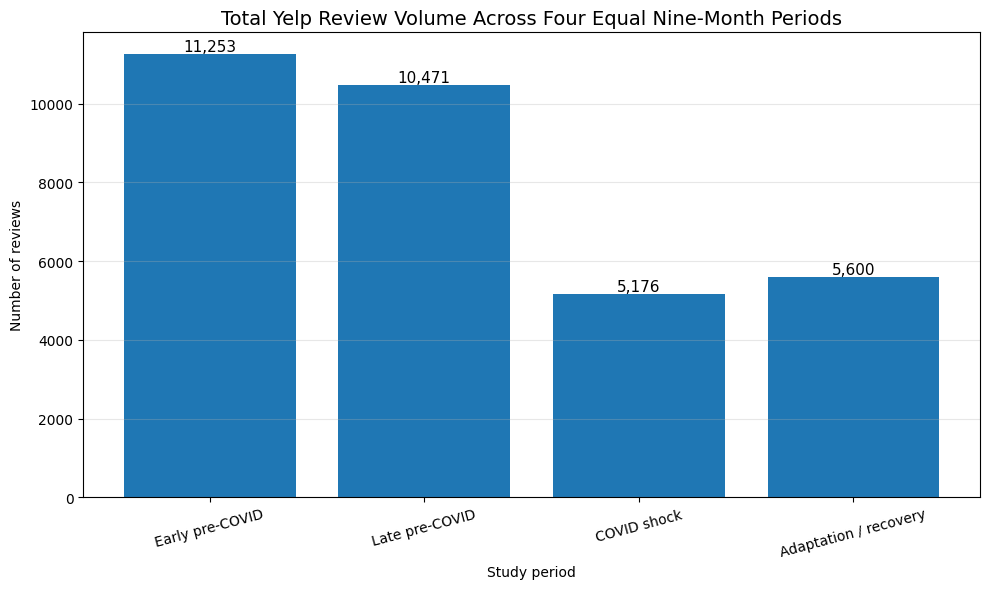

,period_label,review_count
0,Early pre-COVID,11253
1,Late pre-COVID,10471
2,COVID shock,5176
3,Adaptation / recovery,5600


In [ ]:
# Plotting Total Review Volume Across the Four Equal Periods

# In this figure, I compare the total number of Yelp reviews
# recorded in each of the four equal nine-month study periods.

# Since all periods have the same duration, differences in review
# counts are not caused by unequal observation windows.

# This is a descriptive figure. It shows overall Yelp-visible
# customer activity in the fixed cohort, but it does not yet test
# whether the differences are statistically significant.


# 1. Preparing the plotting table


period_order = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

period_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation / recovery"
}

review_volume_plot_df = (
    equal_4period_reviews_df
    .groupby("equal_period_4", observed=True)
    .size()
    .reindex(period_order)
    .reset_index(name="review_count")
)

review_volume_plot_df["period_label"] = (
    review_volume_plot_df["equal_period_4"]
    .astype(str)
    .map(period_labels)
)


# 2. Creating the bar chart


fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    review_volume_plot_df["period_label"],
    review_volume_plot_df["review_count"]
)

ax.set_title(
    "Total Yelp Review Volume Across Four Equal Nine-Month Periods",
    fontsize=14
)

ax.set_xlabel("Study period")
ax.set_ylabel("Number of reviews")

ax.tick_params(
    axis="x",
    rotation=15
)

ax.grid(
    axis="y",
    alpha=0.3
)


# 3. Adding exact review counts above the bars


for bar, review_count in zip(
    bars,
    review_volume_plot_df["review_count"]
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(review_count):,}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()


display(
    review_volume_plot_df[
        [
            "period_label",
            "review_count"
        ]
    ]
)

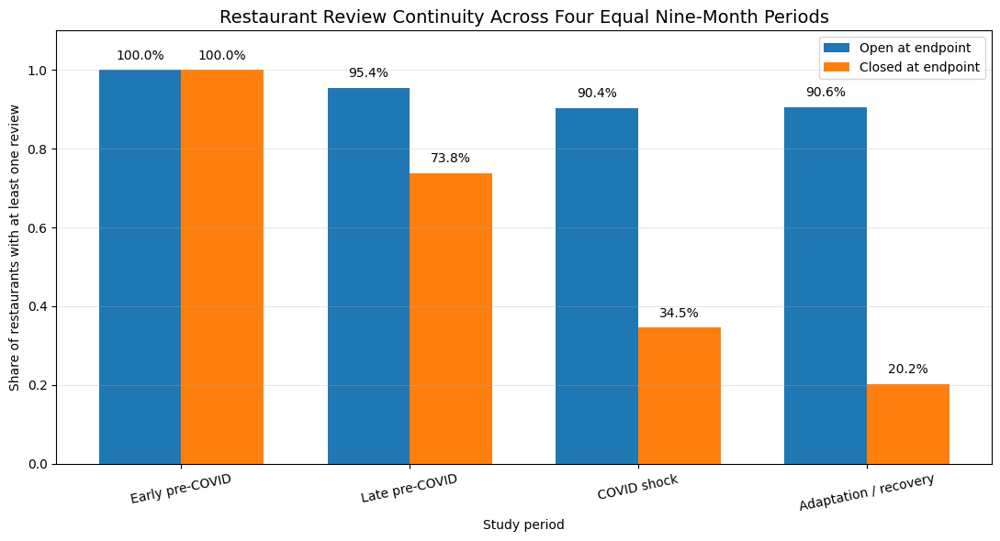

Review continuity by period and Yelp endpoint status:


,period_label,endpoint_status,restaurant_count,restaurants_with_reviews,continuity_share
0,Early pre-COVID,Open at endpoint,789,789,1.000
1,Early pre-COVID,Closed at endpoint,168,168,1.000
2,Late pre-COVID,Open at endpoint,789,753,0.954
3,Late pre-COVID,Closed at endpoint,168,124,0.738
4,COVID shock,Open at endpoint,789,713,0.904
5,COVID shock,Closed at endpoint,168,58,0.345
6,Adaptation / recovery,Open at endpoint,789,715,0.906
7,Adaptation / recovery,Closed at endpoint,168,34,0.202


In [ ]:

# Plotting Review Activity Continuity by Yelp Endpoint Status


# In this figure, I examine whether the restaurants in the fixed cohort
# continued to receive at least one Yelp review in each nine-month period.

# I calculate this separately for:
# - restaurants marked open at the Yelp dataset endpoint;
# - restaurants marked closed at the Yelp dataset endpoint.

# All 957 restaurants remain in their original endpoint-status group.
# A restaurant that has no reviews in a later period is therefore not
# removed. Instead, it receives an activity value of zero for that period.

# The figure measures continuity of Yelp-visible customer activity.
# It does not identify the exact date on which a restaurant closed.



# 1. Defining the four periods and their review-count columns


period_count_columns = {
    "early_pre": "period_review_count_early_pre",
    "late_pre": "period_review_count_late_pre",
    "shock": "period_review_count_shock",
    "adaptation_recovery": (
        "period_review_count_adaptation_recovery"
    )
}

period_order = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

period_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation / recovery"
}



# 2. Confirming that the required columns exist

required_columns = [
    "business_id",
    "closed"
] + list(period_count_columns.values())

missing_columns = [
    column
    for column in required_columns
    if column not in equal_4period_baseline_df.columns
]

if missing_columns:
    raise KeyError(
        "The following required columns are missing from "
        f"equal_4period_baseline_df: {missing_columns}"
    )


# 3. Creating the restaurant-level continuity table


review_continuity_source_df = (
    equal_4period_baseline_df[required_columns]
    .copy()
)

# A missing period review count means that the restaurant received
# no review in that period. I therefore replace missing counts with zero.
review_continuity_source_df[
    list(period_count_columns.values())
] = (
    review_continuity_source_df[
        list(period_count_columns.values())
    ]
    .fillna(0)
)

# Creating a binary indicator for whether each restaurant received
# at least one review in each period.
for period, count_column in period_count_columns.items():

    review_continuity_source_df[
        f"has_reviews_{period}"
    ] = (
        review_continuity_source_df[count_column] > 0
    ).astype(int)


# 4. Calculating continuity by period and endpoint status


continuity_rows = []

for period in period_order:

    activity_column = f"has_reviews_{period}"

    for closed_status in [0, 1]:

        status_group_df = (
            review_continuity_source_df[
                review_continuity_source_df["closed"]
                == closed_status
            ]
        )

        restaurant_count = len(status_group_df)

        restaurants_with_reviews = int(
            status_group_df[activity_column].sum()
        )

        continuity_share = (
            restaurants_with_reviews / restaurant_count
            if restaurant_count > 0
            else np.nan
        )

        continuity_rows.append({
            "period": period,
            "period_label": period_labels[period],
            "closed": closed_status,
            "endpoint_status": (
                "Open at endpoint"
                if closed_status == 0
                else "Closed at endpoint"
            ),
            "restaurant_count": restaurant_count,
            "restaurants_with_reviews": (
                restaurants_with_reviews
            ),
            "continuity_share": continuity_share
        })

review_continuity_plot_df = pd.DataFrame(
    continuity_rows
)



# 5. Preparing the values for grouped bars


open_values = (
    review_continuity_plot_df[
        review_continuity_plot_df["closed"] == 0
    ]
    .set_index("period")
    .reindex(period_order)["continuity_share"]
    .to_numpy()
)

closed_values = (
    review_continuity_plot_df[
        review_continuity_plot_df["closed"] == 1
    ]
    .set_index("period")
    .reindex(period_order)["continuity_share"]
    .to_numpy()
)

x_positions = np.arange(len(period_order))
bar_width = 0.36



# 6. Creating the grouped bar chart


fig, ax = plt.subplots(figsize=(11, 6))

open_bars = ax.bar(
    x_positions - bar_width / 2,
    open_values,
    width=bar_width,
    label="Open at endpoint"
)

closed_bars = ax.bar(
    x_positions + bar_width / 2,
    closed_values,
    width=bar_width,
    label="Closed at endpoint"
)

ax.set_title(
    "Restaurant Review Continuity Across Four Equal "
    "Nine-Month Periods",
    fontsize=14
)

ax.set_xlabel("Study period")

ax.set_ylabel(
    "Share of restaurants with at least one review"
)

ax.set_xticks(x_positions)

ax.set_xticklabels(
    [
        period_labels[period]
        for period in period_order
    ],
    rotation=12
)

ax.set_ylim(0, 1.10)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)


# 7. Adding percentage labels above each bar


for bars in [open_bars, closed_bars]:

    for bar in bars:

        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + 0.02,
            f"{value:.1%}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.tight_layout()
plt.show()




print(
    "Review continuity by period and Yelp endpoint status:"
)

display(
    review_continuity_plot_df[
        [
            "period_label",
            "endpoint_status",
            "restaurant_count",
            "restaurants_with_reviews",
            "continuity_share"
        ]
    ]
    .round({
        "continuity_share": 3
    })
)

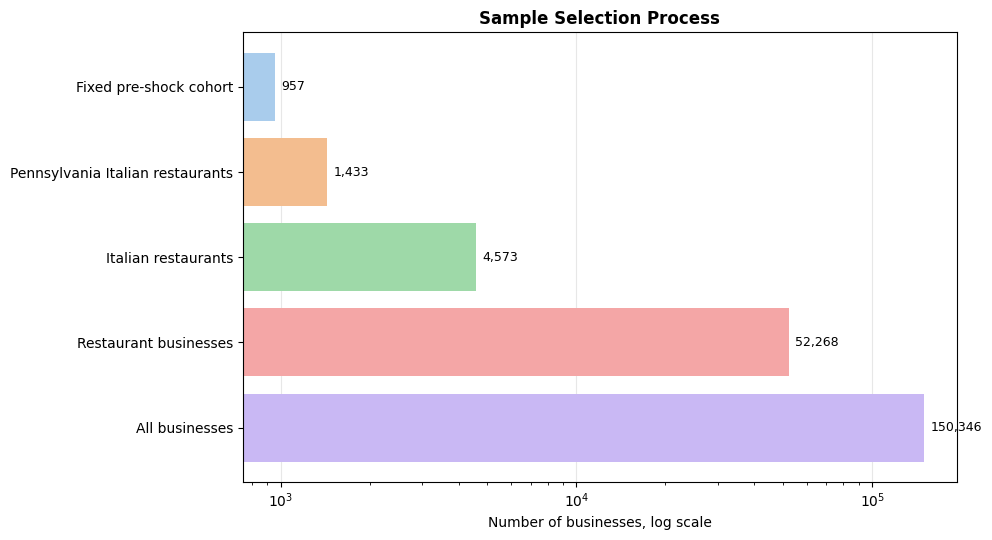

In [ ]:
# Ploting the updated sample selection process with pastel colors


sample_stages = [
    "All businesses",
    "Restaurant businesses",
    "Italian restaurants",
    "Pennsylvania Italian restaurants",
    "Fixed pre-shock cohort"
]

business_counts = [
    150_346,
    52_268,
    4_573,
    1_433,
    957
]

pastel_colors = [
    "#c9b8f4",  # pastel purple
    "#f4a6a6",  # pastel red
    "#9ed9a8",  # pastel green
    "#f3bd8f",  # pastel orange
    "#a9ccec"   # pastel blue
]

fig, ax = plt.subplots(figsize=(10, 5.5))

bars = ax.barh(
    sample_stages,
    business_counts,
    color=pastel_colors
)

# Using a logarithmic scale because the sample sizes differ greatly
ax.set_xscale("log")

ax.set_title("Sample Selection Process", fontweight="bold")
ax.set_xlabel("Number of businesses, log scale")

# Adding exact values next to the bars
for bar, value in zip(bars, business_counts):
    ax.text(
        value * 1.05,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,}",
        va="center",
        fontsize=9
    )

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    "sample_selection_process.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **5) Yelp Photo Dataset Preparation**

In [ ]:

# Inspecting Yelp Photos ZIP and TAR structure


# In this step, I inspect the photo dataset.
# The goal is to understand what is inside the Yelp-Photos.zip file
# before extracting the actual image files.

# Yelp photo metadata does not include upload dates.
# Therefore, images cannot be assigned to the four nine-month periods
# and are used only as restaurant-level indicators in the post-hoc analysis.

from pathlib import Path
import zipfile
import tarfile

# Photo dataset paths
photos_zip_path = PHOTOS_DIR / "Yelp-Photos.zip"

photos_zip_extract_dir = PHOTOS_DIR / "zip_extracted"
photos_tar_extract_dir = PHOTOS_DIR / "tar_extracted"

photos_zip_extract_dir.mkdir(parents=True, exist_ok=True)
photos_tar_extract_dir.mkdir(parents=True, exist_ok=True)

print("Photos ZIP exists:", photos_zip_path.exists())
print("Photos ZIP path:", photos_zip_path)

if not photos_zip_path.exists():
    raise FileNotFoundError(f"Photos ZIP file was not found at: {photos_zip_path}")

print("\nPhotos ZIP size:", round(photos_zip_path.stat().st_size / (1024**3), 2), "GB")

# ZIP contents
print("\nContents of Yelp-Photos.zip:")

with zipfile.ZipFile(photos_zip_path, "r") as zip_file:
    zip_members = zip_file.infolist()

    print("Number of items inside ZIP:", len(zip_members))
    print("Total uncompressed size:", round(sum(item.file_size for item in zip_members) / (1024**3), 2), "GB")

    for item in zip_members:
        item_size_mb = item.file_size / (1024**2)
        print(item.filename, "|", round(item_size_mb, 2), "MB")

Photos ZIP exists: True
Photos ZIP path: /content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/Yelp-Photos.zip

Photos ZIP size: 6.94 GB

Contents of Yelp-Photos.zip:
Number of items inside ZIP: 5
Total uncompressed size: 6.93 GB
Yelp Photos/ | 0.0 MB
Yelp Photos/yelp_photos.tar | 7099.94 MB
__MACOSX/Yelp Photos/._yelp_photos.tar | 0.0 MB
Yelp Photos/Yelp Dataset Documentation & ToS.pdf | 0.12 MB
__MACOSX/Yelp Photos/._Yelp Dataset Documentation & ToS.pdf | 0.0 MB


In [ ]:
# Extracting Yelp Photos ZIP and inspecting TAR contents

# First I check whether the real photo TAR file already exists.
# This avoids extracting the ZIP again if I rerun the notebook.

existing_photo_tar_files = [
    file for file in photos_zip_extract_dir.rglob("*.tar")
    if "__MACOSX" not in str(file)
]

if len(existing_photo_tar_files) == 0:
    print("No photo TAR file found yet, so I am extracting the Photos ZIP file.")

    with zipfile.ZipFile(photos_zip_path, "r") as zip_file:
        zip_file.extractall(photos_zip_extract_dir)

    print("Photos ZIP extraction completed.")
else:
    print("Photo TAR file already exists, so I do not need to extract the ZIP again.")

# Locating the real photo TAR file
photo_tar_files = [
    file for file in photos_zip_extract_dir.rglob("*.tar")
    if "__MACOSX" not in str(file)
]

print("\nPhoto TAR files found:")

for file in photo_tar_files:
    file_size_gb = file.stat().st_size / (1024**3)
    print(file, "|", round(file_size_gb, 2), "GB")

if len(photo_tar_files) == 0:
    raise FileNotFoundError("No real photo TAR file was found after extracting the Photos ZIP file.")

photo_tar_path = photo_tar_files[0]

print("\nPhoto TAR file selected for inspection:")
print(photo_tar_path)

# Inspecting TAR contents without extracting everything yet
print("\nInspecting first items inside the photo TAR file:")

with tarfile.open(photo_tar_path, "r") as tar_file:
    members = tar_file.getmembers()

    print("Number of items inside TAR:", len(members))

    for item in members[:30]:
        item_size_mb = item.size / (1024**2)
        print(item.name, "|", round(item_size_mb, 2), "MB")

Photo TAR file already exists, so I do not need to extract the ZIP again.

Photo TAR files found:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/zip_extracted/Yelp Photos/yelp_photos.tar | 6.93 GB

Photo TAR file selected for inspection:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/zip_extracted/Yelp Photos/yelp_photos.tar

Inspecting first items inside the photo TAR file:
Number of items inside TAR: 200101
photos | 0.0 MB
photos/mj3HHurG_-Lzui2DohAQFQ.jpg | 0.02 MB
photos/bdrWrP2m0kqNa7Zm_YRAsg.jpg | 0.03 MB
photos/ev2tFCk5rpdPIS5cAxz8QA.jpg | 0.02 MB
photos/ZfhRwIIbZoUqFgTGWmropQ.jpg | 0.03 MB
photos/7fIlVVJ3NfD8X0WoxbczjQ.jpg | 0.03 MB
photos/jz3BDPTe9OtK42GR4rHQqg.jpg | 0.04 MB
photos/fMGXpn-00V9nhj6Was4_hQ.jpg | 0.05 MB
photos/bUnOAfbr2ncnarbK8TNACQ.jpg | 0.03 MB
photos/LwpK8WJ3tXf0SMgm8HLlRQ.jpg | 0.04 MB
photos/nLOsgUAy5R8IDDEdipql2w.jpg | 0.02 MB
photos/yZHhVnZuY6bFu8EZxr-QvA.jpg | 0.03 MB
photos/Q7gebtMsYDI6gKzMOTXKZg.jpg | 0.02 MB
photos/QSR_

In [ ]:
# Finding metadata files inside the photo TAR archive


# The first items inside the photo TAR were mostly image files.
# Here I search the full TAR member list for JSON or text files,
# because the photo metadata file may appear later in the archive.

with tarfile.open(photo_tar_path, "r") as tar_file:
    members = tar_file.getmembers()

metadata_candidates = [
    item for item in members
    if item.name.lower().endswith((".json", ".txt", ".pdf"))
]

print("Metadata-like files found:")

for item in metadata_candidates:
    item_size_mb = item.size / (1024**2)
    print(item.name, "|", round(item_size_mb, 2), "MB")

Metadata-like files found:
photos.json | 24.47 MB
Dataset_User_Agreement.pdf | 0.08 MB


In [ ]:
# Extracting only the photo metadata file

# I do not extract all image files yet because there are around 200,000 images.
# First, I only extract the photo metadata JSON file, if it exists.

json_metadata_files = [
    item for item in metadata_candidates
    if item.name.lower().endswith(".json")
]

print("JSON metadata files found:")

for item in json_metadata_files:
    print(item.name)

if len(json_metadata_files) == 0:
    print("No JSON metadata file found inside the photo TAR.")
else:
    photo_metadata_member = json_metadata_files[0]

    print("\nExtracting metadata file:")
    print(photo_metadata_member.name)

    with tarfile.open(photo_tar_path, "r") as tar_file:
        tar_file.extract(photo_metadata_member, path=photos_tar_extract_dir)

    print("\nMetadata extraction completed.")

JSON metadata files found:
photos.json

Extracting metadata file:
photos.json


/tmp/ipykernel_495/1900725459.py:25: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar_file.extract(photo_metadata_member, path=photos_tar_extract_dir)



Metadata extraction completed.


In [ ]:
# Loading photo metadata

# After extracting the JSON metadata file, I locate it and load it with pandas.

photo_json_files = list(photos_tar_extract_dir.rglob("*.json"))

print("Extracted photo JSON files:")

for file in photo_json_files:
    print(file)

if len(photo_json_files) == 0:
    raise FileNotFoundError("No extracted photo JSON file was found.")

photo_metadata_path = photo_json_files[0]

photo_df = pd.read_json(photo_metadata_path, lines=True)

print("\nPhoto metadata loaded.")
print("Shape:", photo_df.shape)

photo_df.head()

Extracted photo JSON files:
/content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/tar_extracted/photos.json

Photo metadata loaded.
Shape: (200100, 4)


,photo_id,business_id,caption,label
0,zsvj7vloL4L5jhYyPIuVwg,Nk-SJhPlDBkAZvfsADtccA,Nice rock artwork everywhere and craploads of ...,inside
1,HCUdRJHHm_e0OCTlZetGLg,yVZtL5MmrpiivyCIrVkGgA,,outside
2,vkr8T0scuJmGVvN2HJelEA,_ab50qdWOk0DdB6XOrBitw,oyster shooter,drink
3,pve7D6NUrafHW3EAORubyw,SZU9c8V2GuREDN5KgyHFJw,Shrimp scampi,food
4,H52Er-uBg6rNrHcReWTD2w,Gzur0f0XMkrVxIwYJvOt2g,,food


In [ ]:
# Inspecting photo metadata columns


print("Photo metadata columns:")
print(photo_df.columns.tolist())

print("\nPhoto metadata info:")
photo_df.info()

Photo metadata columns:
['photo_id', 'business_id', 'caption', 'label']

Photo metadata info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200100 entries, 0 to 200099
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   photo_id     200100 non-null  object
 1   business_id  200100 non-null  object
 2   caption      200100 non-null  object
 3   label        200100 non-null  object
dtypes: object(4)
memory usage: 6.1+ MB


In [ ]:
# Inspecting Photo Coverage in the Fixed Cohort

# In this step, I return to the original Yelp photo metadata table
# and filter it using the 957 restaurant IDs in the revised fixed
# cohort.

# This cell checks:
# - how many cohort restaurants have at least one photo,
# - how many photos are available in total,
# - whether photo availability differs by Yelp endpoint status,
# - how many photos each restaurant has,
# - which Yelp photo labels are represented,
# - and how often captions are available.


# 1. Filtering the original photo metadata to the revised cohort


fixed_cohort_business_ids = set(
    equal_4period_cohort_df["business_id"]
)

equal_4period_photos_df = (
    photo_df[
        photo_df["business_id"].isin(
            fixed_cohort_business_ids
        )
    ]
    .copy()
    .reset_index(drop=True)
)

print("Photo metadata rows in revised fixed cohort:")
print(len(equal_4period_photos_df))

print("\nCohort restaurants with at least one photo:")
print(
    equal_4period_photos_df["business_id"].nunique()
)

print("\nTotal restaurants in fixed cohort:")
print(
    equal_4period_cohort_df["business_id"].nunique()
)


# 2. Adding endpoint status to the photo metadata

photo_status_columns = [
    "business_id",
    "is_open",
    "closed"
]

equal_4period_photos_df = (
    equal_4period_photos_df
    .merge(
        equal_4period_cohort_df[
            photo_status_columns
        ].drop_duplicates("business_id"),
        on="business_id",
        how="left",
        validate="many_to_one"
    )
)

# 3. Creating restaurant-level photo counts

restaurant_photo_counts_df = (
    equal_4period_photos_df
    .groupby("business_id")
    .agg(
        photo_count=("photo_id", "count"),
        captioned_photo_count=(
            "caption",
            lambda x: (
                x.fillna("")
                .astype(str)
                .str.strip()
                .ne("")
                .sum()
            )
        )
    )
    .reset_index()
)

# Merging with the full cohort so that restaurants with no photos
# are retained and correctly receive a photo count of zero.
restaurant_photo_coverage_df = (
    equal_4period_cohort_df[
        [
            "business_id",
            "name",
            "city",
            "is_open",
            "closed"
        ]
    ]
    .merge(
        restaurant_photo_counts_df,
        on="business_id",
        how="left"
    )
)

restaurant_photo_coverage_df[
    [
        "photo_count",
        "captioned_photo_count"
    ]
] = (
    restaurant_photo_coverage_df[
        [
            "photo_count",
            "captioned_photo_count"
        ]
    ]
    .fillna(0)
    .astype(int)
)

restaurant_photo_coverage_df["has_photos"] = (
    restaurant_photo_coverage_df["photo_count"] > 0
).astype(int)


# 4. Summarizing coverage by endpoint status


photo_coverage_by_status_df = (
    restaurant_photo_coverage_df
    .groupby("closed")
    .agg(
        restaurant_count=("business_id", "nunique"),
        restaurants_with_photos=("has_photos", "sum"),
        mean_photo_count=("photo_count", "mean"),
        median_photo_count=("photo_count", "median"),
        total_photos=("photo_count", "sum")
    )
    .reset_index()
)

photo_coverage_by_status_df["photo_coverage_share"] = (
    photo_coverage_by_status_df[
        "restaurants_with_photos"
    ]
    / photo_coverage_by_status_df[
        "restaurant_count"
    ]
)

photo_coverage_by_status_df["endpoint_status"] = (
    photo_coverage_by_status_df["closed"]
    .map({
        0: "Open at endpoint",
        1: "Closed at endpoint"
    })
)

print("\nPhoto coverage by Yelp endpoint status:")
display(
    photo_coverage_by_status_df[
        [
            "endpoint_status",
            "restaurant_count",
            "restaurants_with_photos",
            "photo_coverage_share",
            "total_photos",
            "mean_photo_count",
            "median_photo_count"
        ]
    ].round(3)
)

# 5. Inspecting photos per restaurant


print("\nPhoto-count distribution across all cohort restaurants:")
display(
    restaurant_photo_coverage_df[
        "photo_count"
    ]
    .describe(
        percentiles=[
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
    .round(2)
)

print("\nNumber of restaurants by photo-count range:")
photo_count_range_df = pd.DataFrame({
    "photo_count_range": [
        "0 photos",
        "1 photo",
        "2–5 photos",
        "6–10 photos",
        "More than 10 photos"
    ],
    "restaurant_count": [
        (restaurant_photo_coverage_df["photo_count"] == 0).sum(),
        (restaurant_photo_coverage_df["photo_count"] == 1).sum(),
        (
            restaurant_photo_coverage_df["photo_count"]
            .between(2, 5)
        ).sum(),
        (
            restaurant_photo_coverage_df["photo_count"]
            .between(6, 10)
        ).sum(),
        (restaurant_photo_coverage_df["photo_count"] > 10).sum()
    ]
})

photo_count_range_df["cohort_share"] = (
    photo_count_range_df["restaurant_count"]
    / len(restaurant_photo_coverage_df)
)

display(
    photo_count_range_df.round({
        "cohort_share": 3
    })
)

# 6. Inspecting Yelp photo labels


photo_label_summary_df = (
    equal_4period_photos_df["label"]
    .fillna("missing")
    .value_counts()
    .rename_axis("label")
    .reset_index(name="photo_count")
)

photo_label_summary_df["photo_share"] = (
    photo_label_summary_df["photo_count"]
    / len(equal_4period_photos_df)
)

print("\nPhoto distribution by Yelp label:")
display(
    photo_label_summary_df.round({
        "photo_share": 3
    })
)


# 7. Inspecting caption availability


equal_4period_photos_df["has_caption"] = (
    equal_4period_photos_df["caption"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
).astype(int)

caption_summary_df = pd.DataFrame({
    "measure": [
        "Total photos",
        "Photos with captions",
        "Photos without captions",
        "Caption availability share"
    ],
    "value": [
        len(equal_4period_photos_df),
        equal_4period_photos_df["has_caption"].sum(),
        (equal_4period_photos_df["has_caption"] == 0).sum(),
        equal_4period_photos_df["has_caption"].mean()
    ]
})

print("\nCaption availability:")
display(caption_summary_df)


# 8. Overall coverage summary

overall_photo_summary_df = pd.DataFrame({
    "measure": [
        "Fixed-cohort restaurants",
        "Restaurants with at least one photo",
        "Restaurants without photos",
        "Restaurant photo-coverage share",
        "Total cohort photos"
    ],
    "value": [
        len(restaurant_photo_coverage_df),
        restaurant_photo_coverage_df["has_photos"].sum(),
        (
            restaurant_photo_coverage_df["has_photos"] == 0
        ).sum(),
        restaurant_photo_coverage_df["has_photos"].mean(),
        len(equal_4period_photos_df)
    ]
})

print("\nOverall fixed-cohort photo summary:")
display(overall_photo_summary_df)

Photo metadata rows in revised fixed cohort:
3654

Cohort restaurants with at least one photo:
643

Total restaurants in fixed cohort:
957

Photo coverage by Yelp endpoint status:


,endpoint_status,restaurant_count,restaurants_with_photos,photo_coverage_share,total_photos,mean_photo_count,median_photo_count
0,Open at endpoint,789,535,0.678,3070,3.891,2.0
1,Closed at endpoint,168,108,0.643,584,3.476,1.0



Photo-count distribution across all cohort restaurants:


,photo_count
count,957.00
mean,3.82
std,7.63
min,0.00
25%,0.00
50%,1.00
75%,4.00
90%,10.00
95%,15.00
max,88.00



Number of restaurants by photo-count range:


,photo_count_range,restaurant_count,cohort_share
0,0 photos,314,0.328
1,1 photo,169,0.177
2,2–5 photos,288,0.301
3,6–10 photos,100,0.104
4,More than 10 photos,86,0.090


... (2 outputs left out)


Caption availability:


,measure,value
0,Total photos,3654.0000
1,Photos with captions,1789.0000
2,Photos without captions,1865.0000
3,Caption availability share,0.4896



Overall fixed-cohort photo summary:


,measure,value
0,Fixed-cohort restaurants,957.000000
1,Restaurants with at least one photo,643.000000
2,Restaurants without photos,314.000000
3,Restaurant photo-coverage share,0.671891
4,Total cohort photos,3654.000000


In [ ]:
# Creating Category-Diverse Capped Photo Sample

# Sampling strategy:
# 1. Exclude menu photos.
# 2. Select one photo from every available category:
#       food, inside, outside, drink
# 3. Fill remaining slots up to a maximum of five photos per
#    restaurant using the restaurant's remaining eligible photos.
# 4. Use a fixed random seed for reproducibility.

PHOTO_CAP_PER_RESTAURANT = 5
PHOTO_RANDOM_SEED = 42

eligible_photo_labels = [
    "food",
    "inside",
    "outside",
    "drink"
]


# 1. Keeping eligible non-menu photos


eligible_photos_df = (
    equal_4period_photos_df[
        equal_4period_photos_df["label"].isin(
            eligible_photo_labels
        )
    ]
    .copy()
)

# Removing any accidental duplicate photo records
eligible_photos_df = (
    eligible_photos_df
    .drop_duplicates(subset=["photo_id"])
    .reset_index(drop=True)
)

print(
    "Fixed-cohort photo metadata rows:",
    len(equal_4period_photos_df)
)

print(
    "Eligible non-menu photos:",
    len(eligible_photos_df)
)

print(
    "Restaurants with eligible non-menu photos:",
    eligible_photos_df["business_id"].nunique()
)

# 2. Assigning reproducible random values

rng = np.random.default_rng(PHOTO_RANDOM_SEED)

eligible_photos_df["_random_order"] = rng.random(
    len(eligible_photos_df)
)


# 3. Selecting one photo from each available category

category_representative_photos_df = (
    eligible_photos_df
    .sort_values(
        [
            "business_id",
            "label",
            "_random_order"
        ]
    )
    .drop_duplicates(
        subset=["business_id", "label"],
        keep="first"
    )
    .copy()
)

category_representative_photos_df[
    "selection_stage"
] = "category_representative"

print(
    "\nPhotos selected as category representatives:",
    len(category_representative_photos_df)
)

# Since there are only four eligible categories, each restaurant
# can receive at most four category-representative photos.

category_count_per_restaurant = (
    category_representative_photos_df
    .groupby("business_id")
    .size()
    .rename("category_representative_count")
    .reset_index()
)


# 4. Identifying remaining eligible photos


selected_representative_ids = set(
    category_representative_photos_df["photo_id"]
)

remaining_photos_df = (
    eligible_photos_df[
        ~eligible_photos_df["photo_id"].isin(
            selected_representative_ids
        )
    ]
    .copy()
)

remaining_photos_df = (
    remaining_photos_df
    .merge(
        category_count_per_restaurant,
        on="business_id",
        how="left"
    )
)

remaining_photos_df[
    "category_representative_count"
] = (
    remaining_photos_df[
        "category_representative_count"
    ]
    .fillna(0)
    .astype(int)
)

remaining_photos_df["remaining_slots"] = (
    PHOTO_CAP_PER_RESTAURANT
    -
    remaining_photos_df[
        "category_representative_count"
    ]
)

# 5. Filling the remaining slots up to the five-photo cap


remaining_photos_df = (
    remaining_photos_df
    .sort_values(
        ["business_id", "_random_order"]
    )
    .copy()
)

remaining_photos_df["fill_rank"] = (
    remaining_photos_df
    .groupby("business_id")
    .cumcount()
    + 1
)

fill_photos_df = (
    remaining_photos_df[
        remaining_photos_df["fill_rank"]
        <= remaining_photos_df["remaining_slots"]
    ]
    .copy()
)

fill_photos_df["selection_stage"] = "remaining_slot"

print(
    "Additional photos selected to fill remaining slots:",
    len(fill_photos_df)
)


# 6. Combining both selection stages

category_diverse_photos_df = pd.concat(
    [
        category_representative_photos_df,
        fill_photos_df[
            category_representative_photos_df.columns
        ]
    ],
    ignore_index=True
)

category_diverse_photos_df = (
    category_diverse_photos_df
    .sort_values(
        [
            "business_id",
            "selection_stage",
            "label",
            "_random_order"
        ]
    )
    .reset_index(drop=True)
)


assert (
    category_diverse_photos_df["photo_id"].is_unique
), "Duplicate photo IDs exist in the selected sample."

assert (
    category_diverse_photos_df
    .groupby("business_id")
    .size()
    .max()
    <= PHOTO_CAP_PER_RESTAURANT
), "At least one restaurant exceeds the five-photo cap."

# Using this as the final metadata table for image extraction
capped_photos_df = (
    category_diverse_photos_df
    .drop(
        columns=[
            "_random_order"
        ],
        errors="ignore"
    )
    .copy()
)



selected_photo_counts_df = (
    capped_photos_df
    .groupby("business_id")
    .size()
    .rename("selected_photo_count")
    .reset_index()
)

selected_label_distribution_df = (
    capped_photos_df["label"]
    .value_counts()
    .rename_axis("label")
    .reset_index(name="photo_count")
)

selected_label_distribution_df["photo_share"] = (
    selected_label_distribution_df["photo_count"]
    / len(capped_photos_df)
)

selected_photo_count_distribution_df = (
    selected_photo_counts_df[
        "selected_photo_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("selected_photo_count")
    .reset_index(name="restaurant_count")
)

selected_photo_count_distribution_df[
    "share_of_represented_restaurants"
] = (
    selected_photo_count_distribution_df[
        "restaurant_count"
    ]
    / selected_photo_counts_df["business_id"].nunique()
)

category_coverage_df = (
    capped_photos_df
    .groupby("business_id")["label"]
    .nunique()
    .rename("selected_category_count")
    .reset_index()
)

category_coverage_distribution_df = (
    category_coverage_df[
        "selected_category_count"
    ]
    .value_counts()
    .sort_index()
    .rename_axis("selected_category_count")
    .reset_index(name="restaurant_count")
)

category_coverage_distribution_df[
    "share_of_represented_restaurants"
] = (
    category_coverage_distribution_df[
        "restaurant_count"
    ]
    / category_coverage_df["business_id"].nunique()
)

category_diverse_summary_df = pd.DataFrame({
    "measure": [
        "Fixed-cohort photo metadata rows",
        "Restaurants with at least one photo",
        "Eligible non-menu photos",
        "Restaurants with eligible non-menu photos",
        "Maximum photos per restaurant",
        "Selected photos after category-diverse cap",
        "Restaurants represented after cap",
        "Mean selected photos per represented restaurant",
        "Median selected photos per represented restaurant",
        "Mean selected categories per represented restaurant",
        "Median selected categories per represented restaurant"
    ],
    "value": [
        len(equal_4period_photos_df),
        equal_4period_photos_df["business_id"].nunique(),
        len(eligible_photos_df),
        eligible_photos_df["business_id"].nunique(),
        PHOTO_CAP_PER_RESTAURANT,
        len(capped_photos_df),
        capped_photos_df["business_id"].nunique(),
        selected_photo_counts_df[
            "selected_photo_count"
        ].mean(),
        selected_photo_counts_df[
            "selected_photo_count"
        ].median(),
        category_coverage_df[
            "selected_category_count"
        ].mean(),
        category_coverage_df[
            "selected_category_count"
        ].median()
    ]
})

print("\nCategory-diverse capped image sample summary:")
display(category_diverse_summary_df)

print("\nSelected-photo label distribution:")
display(selected_label_distribution_df)

print("\nSelected photos per represented restaurant:")
display(selected_photo_count_distribution_df)

print("\nNumber of represented categories per restaurant:")
display(category_coverage_distribution_df)

print("\nSelection-stage distribution:")
display(
    capped_photos_df["selection_stage"]
    .value_counts()
    .rename_axis("selection_stage")
    .reset_index(name="photo_count")
)

print("\nExample selected photos:")
display(
    capped_photos_df[
        [
            "business_id",
            "photo_id",
            "label",
            "caption",
            "selection_stage"
        ]
    ].head(20)
)

Fixed-cohort photo metadata rows: 3654
Eligible non-menu photos: 3637
Restaurants with eligible non-menu photos: 639

Photos selected as category representatives: 1077
Additional photos selected to fill remaining slots: 880

Category-diverse capped image sample summary:


,measure,value
0,Fixed-cohort photo metadata rows,3654.000000
1,Restaurants with at least one photo,643.000000
2,Eligible non-menu photos,3637.000000
3,Restaurants with eligible non-menu photos,639.000000
4,Maximum photos per restaurant,5.000000
5,Selected photos after category-diverse cap,1957.000000
6,Restaurants represented after cap,639.000000
7,Mean selected photos per represented restaurant,3.062598
8,Median selected photos per represented restaurant,3.000000
9,Mean selected categories per represented resta...,1.685446



Selected-photo label distribution:


,label,photo_count,photo_share
0,food,1194,0.610118
1,inside,489,0.249872
2,outside,185,0.094532
3,drink,89,0.045478



Selected photos per represented restaurant:


,selected_photo_count,restaurant_count,share_of_represented_restaurants
0,1,167,0.261346
1,2,123,0.192488
2,3,72,0.112676
3,4,57,0.089202
4,5,220,0.344288


... (2 outputs left out)


Selection-stage distribution:


,selection_stage,photo_count
0,category_representative,1077
1,remaining_slot,880



Example selected photos:


,business_id,photo_id,label,caption,selection_stage
0,-7wXZWnKe26iwJY_5z_AAw,-oD2pKFgJy4mb5SLQ-_LbQ,drink,,category_representative
1,-7wXZWnKe26iwJY_5z_AAw,MV5DkPkAWnbb09qfHF_rbw,food,,category_representative
2,-7wXZWnKe26iwJY_5z_AAw,lda-27yAv0lo_jSoR3q3Iw,inside,,category_representative
3,-7wXZWnKe26iwJY_5z_AAw,k61TdpcVCSvml4Aj1-K_zg,outside,,category_representative
4,-7wXZWnKe26iwJY_5z_AAw,klhsqbMR4u3ke9paKmIcBQ,inside,,remaining_slot
5,-DcRlgZdSCM0nQu4w4UI7g,PKmY2muOR7REpgg7ttkeaw,food,,category_representative
6,-DcRlgZdSCM0nQu4w4UI7g,tY1GBkwI7-2Jc2laAXI_yA,inside,,category_representative
7,-DcRlgZdSCM0nQu4w4UI7g,EexVvS42OQpPpBxRjVciJw,food,,remaining_slot
8,-HoCrhW2f7610NWGDemnjw,DNR0I_0rGWNbIUZnILcREw,inside,,category_representative
9,-JStjL-8mRZq4ov4uI1FaQ,t_ALrn46VXOhfATn98Le8g,inside,Make sure your entire party is with you or you...,category_representative


In [ ]:
# Running only when creating or rebuilding the selected image dataset
'''
# ============================================================
# Match and Extract Selected Yelp Photo Files
# ============================================================

# In this step, I match the selected photo IDs in capped_photos_df
# to the actual image files stored inside the Yelp photo TAR archive.
#
# Only the 1,957 selected images are extracted.
# The full archive is not extracted.

import tarfile
import shutil
from pathlib import Path

# ------------------------------------------------------------
# 1. Define output folder for selected images
# ------------------------------------------------------------

SELECTED_IMAGES_DIR = (
    PHOTOS_DIR / "selected_category_diverse_images"
)

SELECTED_IMAGES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Photo TAR path:")
print(photo_tar_path)

print("\nSelected-image output folder:")
print(SELECTED_IMAGES_DIR)

if not photo_tar_path.exists():
    raise FileNotFoundError(
        f"Photo TAR file was not found: {photo_tar_path}"
    )

# ------------------------------------------------------------
# 2. Prepare selected photo IDs
# ------------------------------------------------------------

selected_photo_ids = set(
    capped_photos_df["photo_id"]
    .astype(str)
)

print("\nSelected photo IDs:")
print(len(selected_photo_ids))

if len(selected_photo_ids) != len(capped_photos_df):
    raise ValueError(
        "The number of unique selected photo IDs does not match "
        "the number of rows in capped_photos_df."
    )

# Yelp image files are expected to use the photo ID as the filename.
# Common extensions are checked in a case-insensitive way.

valid_image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp"
}

# ------------------------------------------------------------
# 3. Scan the TAR archive and match selected files
# ------------------------------------------------------------

matched_tar_members = {}
duplicate_tar_matches = {}

with tarfile.open(photo_tar_path, "r") as tar_file:

    for member in tar_file:

        if not member.isfile():
            continue

        member_path = Path(member.name)
        extension = member_path.suffix.lower()

        if extension not in valid_image_extensions:
            continue

        member_photo_id = member_path.stem

        if member_photo_id in selected_photo_ids:

            if member_photo_id not in matched_tar_members:
                matched_tar_members[member_photo_id] = member
            else:
                duplicate_tar_matches.setdefault(
                    member_photo_id,
                    []
                ).append(member.name)

print("\nSelected photo IDs matched inside TAR:")
print(len(matched_tar_members))

print("Selected photo IDs not matched inside TAR:")
print(
    len(selected_photo_ids)
    - len(matched_tar_members)
)

print("Photo IDs with duplicate TAR matches:")
print(len(duplicate_tar_matches))

# ------------------------------------------------------------
# 4. Extract only the matched selected images
# ------------------------------------------------------------

extracted_photo_records = []
extraction_errors = []

with tarfile.open(photo_tar_path, "r") as tar_file:

    for photo_id, member in matched_tar_members.items():

        source_file = tar_file.extractfile(member)

        if source_file is None:
            extraction_errors.append({
                "photo_id": photo_id,
                "tar_member": member.name,
                "error": "tarfile.extractfile returned None"
            })
            continue

        file_extension = Path(member.name).suffix.lower()

        # Save every selected image directly in one clean folder
        output_path = (
            SELECTED_IMAGES_DIR
            / f"{photo_id}{file_extension}"
        )

        try:
            with open(output_path, "wb") as destination_file:
                shutil.copyfileobj(
                    source_file,
                    destination_file
                )

            extracted_photo_records.append({
                "photo_id": photo_id,
                "tar_member": member.name,
                "image_path": str(output_path),
                "image_filename": output_path.name,
                "image_extension": file_extension
            })

        except Exception as error:
            extraction_errors.append({
                "photo_id": photo_id,
                "tar_member": member.name,
                "error": str(error)
            })

extracted_photos_df = pd.DataFrame(
    extracted_photo_records
)

extraction_errors_df = pd.DataFrame(
    extraction_errors
)

print("\nSuccessfully extracted image files:")
print(len(extracted_photos_df))

print("Extraction errors:")
print(len(extraction_errors_df))

# ------------------------------------------------------------
# 5. Merge image paths into the selected-photo table
# ------------------------------------------------------------

capped_photos_with_paths_df = (
    capped_photos_df
    .merge(
        extracted_photos_df,
        on="photo_id",
        how="left"
    )
)

capped_photos_with_paths_df["image_found"] = (
    capped_photos_with_paths_df[
        "image_path"
    ].notna()
)

# Verify that the extracted files actually exist on disk
capped_photos_with_paths_df[
    "image_exists_on_disk"
] = (
    capped_photos_with_paths_df[
        "image_path"
    ]
    .apply(
        lambda path:
        Path(path).exists()
        if pd.notna(path)
        else False
    )
)

# This becomes the final image metadata table
capped_photos_df = (
    capped_photos_with_paths_df
    .copy()
)

# ------------------------------------------------------------
# 6. Create missing-image table
# ------------------------------------------------------------

missing_selected_photos_df = (
    capped_photos_df[
        ~capped_photos_df[
            "image_exists_on_disk"
        ]
    ]
    [
        [
            "business_id",
            "photo_id",
            "label",
            "caption",
            "selection_stage"
        ]
    ]
    .copy()
)

# ------------------------------------------------------------
# 7. Final extraction checks
# ------------------------------------------------------------

extraction_summary_df = pd.DataFrame({
    "measure": [
        "Selected photo metadata rows",
        "Unique selected photo IDs",
        "Photo IDs matched inside TAR",
        "Successfully extracted image files",
        "Missing selected image files",
        "Extraction errors",
        "Restaurants represented by extracted images"
    ],
    "value": [
        len(capped_photos_df),
        capped_photos_df["photo_id"].nunique(),
        len(matched_tar_members),
        int(
            capped_photos_df[
                "image_exists_on_disk"
            ].sum()
        ),
        int(
            (
                ~capped_photos_df[
                    "image_exists_on_disk"
                ]
            ).sum()
        ),
        len(extraction_errors_df),
        capped_photos_df.loc[
            capped_photos_df[
                "image_exists_on_disk"
            ],
            "business_id"
        ].nunique()
    ]
})

print("\nSelected-image extraction summary:")
display(extraction_summary_df)

print("\nImage availability by Yelp photo label:")

image_availability_by_label_df = (
    capped_photos_df
    .groupby("label")
    .agg(
        selected_photos=("photo_id", "count"),
        extracted_photos=(
            "image_exists_on_disk",
            "sum"
        )
    )
    .reset_index()
)

image_availability_by_label_df[
    "extraction_share"
] = (
    image_availability_by_label_df[
        "extracted_photos"
    ]
    /
    image_availability_by_label_df[
        "selected_photos"
    ]
)

display(image_availability_by_label_df)

print("\nExample selected photos with image paths:")

display(
    capped_photos_df[
        [
            "business_id",
            "photo_id",
            "label",
            "selection_stage",
            "image_path",
            "image_exists_on_disk"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 8. Strict final assertion
# ------------------------------------------------------------

if len(missing_selected_photos_df) == 0:
    print(
        "\nSUCCESS: Every selected photo was matched and "
        "successfully extracted."
    )
else:
    print(
        "\nWARNING:",
        len(missing_selected_photos_df),
        "selected photos could not be extracted."
    )

    display(
        missing_selected_photos_df.head(20)
    )

'''

'\n# ============================================================\n# Match and Extract Selected Yelp Photo Files\n# ============================================================\n\n# In this step, I match the selected photo IDs in capped_photos_df\n# to the actual image files stored inside the Yelp photo TAR archive.\n#\n# Only the 1,957 selected images are extracted.\n# The full archive is not extracted.\n\nimport tarfile\nimport shutil\nfrom pathlib import Path\n\n# ------------------------------------------------------------\n# 1. Define output folder for selected images\n# ------------------------------------------------------------\n\nSELECTED_IMAGES_DIR = (\n    PHOTOS_DIR / "selected_category_diverse_images"\n)\n\nSELECTED_IMAGES_DIR.mkdir(\n    parents=True,\n    exist_ok=True\n)\n\nprint("Photo TAR path:")\nprint(photo_tar_path)\n\nprint("\nSelected-image output folder:")\nprint(SELECTED_IMAGES_DIR)\n\nif not photo_tar_path.exists():\n    raise FileNotFoundError(\n        f"Pho

In [ ]:
# Reloading Final Capped Photo Metadata


from pathlib import Path
import pandas as pd

BASE_DIR = Path(
    "/content/drive/MyDrive/TUM_thesis_digital_marketing"
)

PROCESSED_DIR = BASE_DIR / "processed"

CAPPED_PHOTOS_OUTPUT_PATH = (
    PROCESSED_DIR
    / "category_diverse_capped_photos_with_paths.csv"
)

if not CAPPED_PHOTOS_OUTPUT_PATH.exists():
    raise FileNotFoundError(
        "Saved capped-photo metadata was not found. "
        "Run the sampling and extraction cells first."
    )

capped_photos_df = pd.read_csv(
    CAPPED_PHOTOS_OUTPUT_PATH
)

# Convert the saved path column back into usable path strings
capped_photos_df["image_exists_on_disk"] = (
    capped_photos_df["image_path"]
    .apply(
        lambda path:
        Path(path).exists()
        if pd.notna(path)
        else False
    )
)

print("Reloaded capped photo metadata:")
print(capped_photos_df.shape)

print("Image files currently available:")
print(
    int(
        capped_photos_df[
            "image_exists_on_disk"
        ].sum()
    )
)

print("Restaurants represented:")
print(
    capped_photos_df.loc[
        capped_photos_df[
            "image_exists_on_disk"
        ],
        "business_id"
    ].nunique()
)

Reloaded capped photo metadata:
(1957, 14)
Image files currently available:
1957
Restaurants represented:
639


In [ ]:
# Saving Final Category-Diverse Image Sample

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/TUM_thesis_digital_marketing"
)

PROCESSED_DIR = BASE_DIR / "processed"
PROCESSED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CAPPED_PHOTOS_OUTPUT_PATH = (
    PROCESSED_DIR
    / "category_diverse_capped_photos_with_paths.csv"
)

capped_photos_df.to_csv(
    CAPPED_PHOTOS_OUTPUT_PATH,
    index=False
)

print("Saved final capped photo metadata to:")
print(CAPPED_PHOTOS_OUTPUT_PATH)

print("\nSaved rows:")
print(len(capped_photos_df))

print("Rows with valid image files:")
print(
    int(
        capped_photos_df[
            "image_exists_on_disk"
        ].sum()
    )
)

Saved final capped photo metadata to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/category_diverse_capped_photos_with_paths.csv

Saved rows:
1957
Rows with valid image files:
1957


# **6) LLM Annotation**

In [ ]:

# Qwen2.5-VL setup: required packages
# RUNNING ONLY ONCE PER NEW RUNTIME
!pip install -q -U accelerate bitsandbytes qwen-vl-utils
!pip install -q -U git+https://github.com/huggingface/transformers

print("Package installation completed.")
print("IMPORTANT: After this cell finishes, restart the runtime if Colab asks you to.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 29.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 69.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 51.6 MB/s eta 0:00:00
Package installation completed.
IMPORTANT: After this cell finishes, restart the runtime if Colab asks you to.


In [ ]:
# Loading Qwen2.5-VL-7B-Instruct

import torch
from transformers import Qwen2_5_VLForConditionalGeneration, AutoProcessor

MODEL_ID = "Qwen/Qwen2.5-VL-7B-Instruct"

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory allocated before loading:", round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
    print("GPU memory reserved before loading:", round(torch.cuda.memory_reserved(0) / 1024**3, 2), "GB")

# Loading model
# torch_dtype=torch.bfloat16 is suitable for A100/L4.
# device_map="auto" automatically places the model on available GPU memory.
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_ID,
    torch_dtype=torch.bfloat16,
    device_map="auto",
    trust_remote_code=True
)

# Loading processor
processor = AutoProcessor.from_pretrained(
    MODEL_ID,
    trust_remote_code=True
)

model.eval()

print("\nModel and processor loaded successfully.")

if torch.cuda.is_available():
    print("GPU memory allocated after loading:", round(torch.cuda.memory_allocated(0) / 1024**3, 2), "GB")
    print("GPU memory reserved after loading:", round(torch.cuda.memory_reserved(0) / 1024**3, 2), "GB")

CUDA available: True
GPU: NVIDIA A100-SXM4-80GB
GPU memory allocated before loading: 0.0 GB
GPU memory reserved before loading: 0.0 GB


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/57.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


Model and processor loaded successfully.
GPU memory allocated after loading: 15.45 GB
GPU memory reserved after loading: 15.45 GB


In [ ]:
# Helper function: run Qwen on one text prompt


import torch

def run_qwen_text_prompt(prompt, max_new_tokens=512):
    """
    Runs Qwen2.5-VL on a text-only prompt and returns the generated text.
    """

    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": prompt}
            ],
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=[text],
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    # Remove input tokens from output
    generated_ids_trimmed = [
        out_ids[len(in_ids):]
        for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]

    output_text = processor.batch_decode(
        generated_ids_trimmed,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    return output_text.strip()

In [ ]:
# Defining the Final Review-Text Annotation Prompt

# In this step, I define a concise and reproducible prompt for
# annotating Yelp reviews with standardized customer-perception
# indicators.

# The prompt provides clear construct definitions and scoring rules
# without attempting to encode every possible phrase or edge case.

import json
import pandas as pd


REVIEW_INDICATORS = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]


REVIEW_OUTPUT_TEMPLATE = {
    "food_quality": None,
    "price_value": None,
    "cleanliness": None,
    "service_reliability": None,
    "atmosphere": None,
    "environment": None,
    "warmth": None,
    "visual_appeal": None,
    "overall_sentiment": 0.0,
    "complaint_intensity": 0.0,
    "confidence": 0.0
}


def build_review_annotation_prompt(review_text):
    """
    Build a standardized prompt for annotating one Yelp review.
    """

    if pd.isna(review_text):
        review_text = ""

    review_text = str(review_text).strip()

    output_schema = json.dumps(
        REVIEW_OUTPUT_TEMPLATE,
        indent=2
    )

    prompt = f"""
You are annotating one Yelp restaurant review for an academic study.

Transform the complete review into standardized customer-perception
indicators.

The model is used only for annotation and feature extraction. Do not
predict whether the restaurant will remain open or close.

GENERAL RULES

The following indicators are nullable:

- food_quality
- price_value
- cleanliness
- service_reliability
- atmosphere
- environment
- warmth
- visual_appeal

For each nullable indicator:

- return null when the review contains no meaningful evidence;
- return one numeric score between -1 and 1 when evidence exists;
- use negative values for negative perceptions;
- use positive values for positive perceptions;
- use values near 0 only for genuinely neutral, mixed, weak, or
  uncertain evidence.

Do not use 0 as a substitute for missing evidence.

Return exactly one value for each indicator.

When the review contains positive and negative evidence about the same
indicator, combine the evidence into one overall score.

Base every score on the review text. Do not infer a specific indicator
only from the overall star rating or general sentiment.

INDICATOR DEFINITIONS

food_quality:
Perceived quality of food or drinks, including taste, flavour,
freshness, preparation, temperature, texture, ingredients,
authenticity, consistency, and portion satisfaction.

price_value:
Perceived affordability and value for money, including whether the
quality or quantity received was reasonable for the amount paid.

Do not assign price_value unless the review provides price, cost,
affordability, or value-related evidence.

cleanliness:
Perceived hygiene, sanitation, cleanliness, dirtiness, food-safety
practices, visible mess, unpleasant smells, bathroom condition, or
general maintenance.

service_reliability:
Perceived operational quality of service, including attentiveness,
professionalism, responsiveness, speed, waiting time, order accuracy,
availability, delivery performance, fulfilment, and consistency.

warmth and service_reliability are related but distinct. Operational
performance belongs under service_reliability.

atmosphere:
Perceived ambience or emotional character of the restaurant, including
comfort, noise, music, lighting, decor, mood, energy, intimacy, and
liveliness.

environment:
Perceived physical or surrounding conditions, including location,
accessibility, parking, neighbourhood, outdoor setting, crowding,
seating arrangements, and other physical dining circumstances.

Do not use environment as a general substitute for atmosphere.

warmth:
Perceived interpersonal treatment from staff or owners, including
friendliness, hospitality, politeness, care, kindness, welcoming
behaviour, rudeness, hostility, dismissiveness, or coldness.

Interpersonal behaviour belongs under warmth. Efficient or accurate
service alone does not necessarily indicate warmth.

visual_appeal:
Perceived visual appearance or presentation of food, drinks, plating,
interior, exterior, decor, or the physical setting.

Do not infer visual appeal from taste, freshness, portion size, or
general satisfaction unless appearance or presentation is discussed.

overall_sentiment:
The overall evaluative tone of the complete review.

Always return one numeric score between -1 and 1:

- -1 represents extremely negative sentiment;
- 0 represents neutral or genuinely balanced sentiment;
- 1 represents extremely positive sentiment.

Intermediate values are allowed.

complaint_intensity:
The strength and severity of dissatisfaction expressed in the review.

Always return one numeric score between 0 and 1:

- 0 means no meaningful complaint;
- values near 0 indicate minor criticism;
- moderate values indicate a clear complaint;
- values near 1 indicate severe or strongly expressed dissatisfaction.

A mostly positive review may still receive a small positive complaint
intensity when it contains a genuine criticism.

confidence:
Your confidence that the complete annotation is supported by the review.

Always return one numeric score between 0 and 1.

Use lower confidence when the review is ambiguous, contradictory,
insufficient, or difficult to interpret.

OUTPUT REQUIREMENTS

Return only valid JSON.

Use exactly the keys and flat structure shown below.

Each nullable indicator must contain either one numeric value or null.

overall_sentiment, complaint_intensity, and confidence must always be
numeric.

Do not use nested objects.

Do not use arrays.

Do not add explanations, comments, code fences, or extra keys.

{output_schema}

REVIEW TEXT

{review_text}
"""

    return prompt.strip()


print("Final concise review annotation prompt created.")

print(
    "Indicators:",
    REVIEW_INDICATORS
)

print("\nRequired output structure:")

print(
    json.dumps(
        REVIEW_OUTPUT_TEMPLATE,
        indent=2
    )
)

Final concise review annotation prompt created.
Indicators: ['food_quality', 'price_value', 'cleanliness', 'service_reliability', 'atmosphere', 'environment', 'warmth', 'visual_appeal', 'overall_sentiment', 'complaint_intensity']

Required output structure:
{
  "food_quality": null,
  "price_value": null,
  "cleanliness": null,
  "service_reliability": null,
  "atmosphere": null,
  "environment": null,
  "warmth": null,
  "visual_appeal": null,
  "overall_sentiment": 0.0,
  "complaint_intensity": 0.0,
  "confidence": 0.0
}


In [ ]:

# Parsing and Validating Review-Annotation Outputs

# In this step, I define functions that extract the JSON object
# returned by Qwen and validate it against the final review
# annotation schema.
#
# I check that all required keys are present, no extra keys exist,
# nullable indicators contain either a number or null, and all
# numeric values fall within their required ranges.

import json
import re
import numbers


NULLABLE_REVIEW_INDICATORS = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal"
]


ALWAYS_NUMERIC_REVIEW_INDICATORS = [
    "overall_sentiment",
    "complaint_intensity",
    "confidence"
]


EXPECTED_REVIEW_KEYS = (
    NULLABLE_REVIEW_INDICATORS
    + ALWAYS_NUMERIC_REVIEW_INDICATORS
)


def extract_json_object(output_text):
    """
    Extract one JSON object from a Qwen response.
    """

    if output_text is None:
        return None, "missing_output"

    output_text = str(output_text).strip()

    if not output_text:
        return None, "empty_output"

    # I first attempt to parse the complete response directly.
    try:

        parsed_object = json.loads(
            output_text
        )

        return parsed_object, "direct_parse"

    except json.JSONDecodeError:
        pass

    # I next check for a JSON object inside a Markdown code fence.
    code_fence_match = re.search(
        r"```(?:json)?\s*(\{.*?\})\s*```",
        output_text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if code_fence_match:

        try:

            parsed_object = json.loads(
                code_fence_match.group(1)
            )

            return parsed_object, "code_fence_parse"

        except json.JSONDecodeError:
            pass

    # I finally search for the first balanced JSON object.
    object_start = output_text.find("{")

    if object_start == -1:
        return None, "no_json_object"

    nesting_level = 0
    inside_string = False
    escape_next_character = False

    for character_index in range(
        object_start,
        len(output_text)
    ):

        character = output_text[
            character_index
        ]

        if escape_next_character:

            escape_next_character = False
            continue

        if character == "\\" and inside_string:

            escape_next_character = True
            continue

        if character == '"':

            inside_string = not inside_string
            continue

        if inside_string:
            continue

        if character == "{":

            nesting_level += 1

        elif character == "}":

            nesting_level -= 1

            if nesting_level == 0:

                candidate_object = output_text[
                    object_start:
                    character_index + 1
                ]

                try:

                    parsed_object = json.loads(
                        candidate_object
                    )

                    return (
                        parsed_object,
                        "balanced_object_parse"
                    )

                except json.JSONDecodeError:

                    return (
                        None,
                        "invalid_balanced_object"
                    )

    return None, "incomplete_json_object"


def is_valid_number(value):
    """
    Check whether a value is a real number but not a Boolean.
    """

    return (
        isinstance(
            value,
            numbers.Real
        )
        and not isinstance(
            value,
            bool
        )
    )


def validate_review_annotation(annotation):
    """
    Validate one parsed review annotation.
    """

    validation_errors = []

    schema_valid = True
    range_valid = True
    logic_valid = True

    if not isinstance(
        annotation,
        dict
    ):

        return {
            "schema_valid": False,
            "range_valid": False,
            "logic_valid": False,
            "fully_valid": False,
            "validation_errors": [
                "The parsed output must be a JSON object."
            ],
            "standardized_annotation": None
        }

    annotation_keys = set(
        annotation.keys()
    )

    expected_keys = set(
        EXPECTED_REVIEW_KEYS
    )

    missing_keys = sorted(
        expected_keys
        - annotation_keys
    )

    extra_keys = sorted(
        annotation_keys
        - expected_keys
    )

    if missing_keys:

        schema_valid = False

        validation_errors.append(
            "Missing keys: "
            + ", ".join(
                missing_keys
            )
        )

    if extra_keys:

        schema_valid = False

        validation_errors.append(
            "Unexpected keys: "
            + ", ".join(
                extra_keys
            )
        )

    standardized_annotation = {}

    # I validate nullable indicators as numeric values or null.
    for indicator in (
        NULLABLE_REVIEW_INDICATORS
    ):

        if indicator not in annotation:
            continue

        indicator_value = annotation[
            indicator
        ]

        if indicator_value is None:

            standardized_annotation[
                indicator
            ] = None

        elif is_valid_number(
            indicator_value
        ):

            numeric_value = float(
                indicator_value
            )

            standardized_annotation[
                indicator
            ] = numeric_value

            if not (
                -1.0
                <= numeric_value
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    f"{indicator} must be "
                    "between -1 and 1."
                )

        else:

            schema_valid = False

            validation_errors.append(
                f"{indicator} must be "
                "numeric or null."
            )

            standardized_annotation[
                indicator
            ] = None

    # I validate overall sentiment as an always-present numeric score.
    if "overall_sentiment" in annotation:

        overall_sentiment = annotation[
            "overall_sentiment"
        ]

        if is_valid_number(
            overall_sentiment
        ):

            overall_sentiment = float(
                overall_sentiment
            )

            standardized_annotation[
                "overall_sentiment"
            ] = overall_sentiment

            if not (
                -1.0
                <= overall_sentiment
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    "overall_sentiment must be "
                    "between -1 and 1."
                )

        else:

            schema_valid = False

            validation_errors.append(
                "overall_sentiment must be numeric."
            )

            standardized_annotation[
                "overall_sentiment"
            ] = None

    # I validate complaint intensity as a numeric score from 0 to 1.
    if "complaint_intensity" in annotation:

        complaint_intensity = annotation[
            "complaint_intensity"
        ]

        if is_valid_number(
            complaint_intensity
        ):

            complaint_intensity = float(
                complaint_intensity
            )

            standardized_annotation[
                "complaint_intensity"
            ] = complaint_intensity

            if not (
                0.0
                <= complaint_intensity
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    "complaint_intensity must be "
                    "between 0 and 1."
                )

        else:

            schema_valid = False

            validation_errors.append(
                "complaint_intensity must be numeric."
            )

            standardized_annotation[
                "complaint_intensity"
            ] = None

    # I validate confidence as a numeric score from 0 to 1.
    if "confidence" in annotation:

        confidence = annotation[
            "confidence"
        ]

        if is_valid_number(
            confidence
        ):

            confidence = float(
                confidence
            )

            standardized_annotation[
                "confidence"
            ] = confidence

            if not (
                0.0
                <= confidence
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    "confidence must be "
                    "between 0 and 1."
                )

        else:

            schema_valid = False

            validation_errors.append(
                "confidence must be numeric."
            )

            standardized_annotation[
                "confidence"
            ] = None

    # I place the fields in the exact expected output order.
    standardized_annotation = {
        key: standardized_annotation.get(
            key
        )
        for key in EXPECTED_REVIEW_KEYS
    }

    fully_valid = (
        schema_valid
        and range_valid
        and logic_valid
    )

    return {
        "schema_valid": schema_valid,
        "range_valid": range_valid,
        "logic_valid": logic_valid,
        "fully_valid": fully_valid,
        "validation_errors": validation_errors,
        "standardized_annotation": (
            standardized_annotation
        )
    }


def parse_and_validate_review_output(
    output_text
):
    """
    Extract, standardize, and validate one Qwen response.
    """

    parsed_annotation, parse_method = (
        extract_json_object(
            output_text
        )
    )

    parse_success = (
        parsed_annotation is not None
    )

    if not parse_success:

        return {
            "parse_success": False,
            "parse_method": parse_method,
            "schema_valid": False,
            "range_valid": False,
            "logic_valid": False,
            "fully_valid": False,
            "validation_errors": [
                "The model response could not be "
                "parsed as valid JSON."
            ],
            "parsed_annotation": None,
            "standardized_annotation": None
        }

    validation_result = (
        validate_review_annotation(
            parsed_annotation
        )
    )

    return {
        "parse_success": True,
        "parse_method": parse_method,
        "schema_valid": validation_result[
            "schema_valid"
        ],
        "range_valid": validation_result[
            "range_valid"
        ],
        "logic_valid": validation_result[
            "logic_valid"
        ],
        "fully_valid": validation_result[
            "fully_valid"
        ],
        "validation_errors": validation_result[
            "validation_errors"
        ],
        "parsed_annotation": parsed_annotation,
        "standardized_annotation": (
            validation_result[
                "standardized_annotation"
            ]
        )
    }


print(
    "Review-output parser and validator created."
)

print(
    "Expected output keys:",
    EXPECTED_REVIEW_KEYS
)

Review-output parser and validator created.
Expected output keys: ['food_quality', 'price_value', 'cleanliness', 'service_reliability', 'atmosphere', 'environment', 'warmth', 'visual_appeal', 'overall_sentiment', 'complaint_intensity', 'confidence']


In [ ]:
# Testing the Final Review-Output Parser and Validator

# In this step, I test the parser and validator with several
# controlled examples before applying the prompt to real reviews.

# The tests cover a valid response, nullable values, missing and
# extra keys, invalid data types, out-of-range values, Markdown
# code fences, and the removed revisit_intention field.

import json


valid_annotation = {
    "food_quality": 0.8,
    "price_value": None,
    "cleanliness": None,
    "service_reliability": -0.4,
    "atmosphere": 0.5,
    "environment": None,
    "warmth": -0.6,
    "visual_appeal": None,
    "overall_sentiment": -0.2,
    "complaint_intensity": 0.5,
    "confidence": 0.9
}


parser_test_cases = {
    "valid_direct_json": json.dumps(
        valid_annotation
    ),

    "valid_code_fence_json": (
        "```json\n"
        + json.dumps(
            valid_annotation,
            indent=2
        )
        + "\n```"
    ),

    "valid_all_nullable_missing": json.dumps(
        {
            "food_quality": None,
            "price_value": None,
            "cleanliness": None,
            "service_reliability": None,
            "atmosphere": None,
            "environment": None,
            "warmth": None,
            "visual_appeal": None,
            "overall_sentiment": 0.0,
            "complaint_intensity": 0.0,
            "confidence": 0.5
        }
    ),

    "missing_required_key": json.dumps(
        {
            key: value
            for key, value in valid_annotation.items()
            if key != "food_quality"
        }
    ),

    "unexpected_revisit_intention_key": json.dumps(
        {
            **valid_annotation,
            "revisit_intention": 0.8
        }
    ),

    "invalid_nullable_type": json.dumps(
        {
            **valid_annotation,
            "food_quality": {
                "pizza": 0.8
            }
        }
    ),

    "invalid_overall_sentiment_type": json.dumps(
        {
            **valid_annotation,
            "overall_sentiment": None
        }
    ),

    "invalid_nullable_range": json.dumps(
        {
            **valid_annotation,
            "warmth": -1.5
        }
    ),

    "invalid_complaint_range": json.dumps(
        {
            **valid_annotation,
            "complaint_intensity": 1.3
        }
    ),

    "invalid_confidence_range": json.dumps(
        {
            **valid_annotation,
            "confidence": -0.2
        }
    )
}


expected_validity = {
    "valid_direct_json": True,
    "valid_code_fence_json": True,
    "valid_all_nullable_missing": True,
    "missing_required_key": False,
    "unexpected_revisit_intention_key": False,
    "invalid_nullable_type": False,
    "invalid_overall_sentiment_type": False,
    "invalid_nullable_range": False,
    "invalid_complaint_range": False,
    "invalid_confidence_range": False
}


parser_test_results = []

for test_name, test_output in (
    parser_test_cases.items()
):

    test_result = (
        parse_and_validate_review_output(
            test_output
        )
    )

    actual_validity = bool(
        test_result[
            "fully_valid"
        ]
    )

    expected_result = (
        expected_validity[
            test_name
        ]
    )

    test_passed = (
        actual_validity
        == expected_result
    )

    parser_test_results.append(
        {
            "test_name": test_name,
            "expected_fully_valid": (
                expected_result
            ),
            "actual_fully_valid": (
                actual_validity
            ),
            "parse_success": test_result[
                "parse_success"
            ],
            "parse_method": test_result[
                "parse_method"
            ],
            "schema_valid": test_result[
                "schema_valid"
            ],
            "range_valid": test_result[
                "range_valid"
            ],
            "logic_valid": test_result[
                "logic_valid"
            ],
            "test_passed": test_passed,
            "validation_errors": " | ".join(
                test_result[
                    "validation_errors"
                ]
            )
        }
    )


parser_test_results_df = pd.DataFrame(
    parser_test_results
)


print(
    "Parser and validator tests completed."
)

print(
    "Tests passed:",
    int(
        parser_test_results_df[
            "test_passed"
        ].sum()
    ),
    "out of",
    len(
        parser_test_results_df
    )
)

display(
    parser_test_results_df
)


assert parser_test_results_df[
    "test_passed"
].all(), (
    "At least one parser or validator "
    "test did not produce the expected result."
)


print(
    "\nAll parser and validator tests passed."
)

Parser and validator tests completed.
Tests passed: 10 out of 10


,test_name,expected_fully_valid,actual_fully_valid,parse_success,parse_method,schema_valid,range_valid,logic_valid,test_passed,validation_errors
0,valid_direct_json,True,True,True,direct_parse,True,True,True,True,
1,valid_code_fence_json,True,True,True,code_fence_parse,True,True,True,True,
2,valid_all_nullable_missing,True,True,True,direct_parse,True,True,True,True,
3,missing_required_key,False,False,True,direct_parse,False,True,True,True,Missing keys: food_quality
4,unexpected_revisit_intention_key,False,False,True,direct_parse,False,True,True,True,Unexpected keys: revisit_intention
5,invalid_nullable_type,False,False,True,direct_parse,False,True,True,True,food_quality must be numeric or null.
6,invalid_overall_sentiment_type,False,False,True,direct_parse,False,True,True,True,overall_sentiment must be numeric.
7,invalid_nullable_range,False,False,True,direct_parse,True,False,True,True,warmth must be between -1 and 1.
8,invalid_complaint_range,False,False,True,direct_parse,True,False,True,True,complaint_intensity must be between 0 and 1.
9,invalid_confidence_range,False,False,True,direct_parse,True,False,True,True,confidence must be between 0 and 1.



All parser and validator tests passed.


In [ ]:
# Testing the Final Prompt on One Real Yelp Review

# In this step, I apply the prompt to one real Yelp review and validate the model output with the new parser.

# This confirms that the prompt, Qwen function, and final schema work
# together before I run a larger validation sample.

import json
import pandas as pd
import time


# 1. Selecting one review for the test


single_review_candidates_df = (
    equal_4period_reviews_df
    .dropna(
        subset=[
            "review_id",
            "business_id",
            "text",
            "stars",
            "equal_period_4"
        ]
    )
    .copy()
)

single_review_candidates_df["text"] = (
    single_review_candidates_df[
        "text"
    ]
    .astype(str)
    .str.strip()
)

single_review_candidates_df[
    "text_length"
] = (
    single_review_candidates_df[
        "text"
    ]
    .str.len()
)

single_review_candidates_df = (
    single_review_candidates_df[
        single_review_candidates_df[
            "text_length"
        ].between(120, 1200)
    ]
    .copy()
)

single_review_row = (
    single_review_candidates_df
    .sample(
        n=1,
        random_state=42
    )
    .iloc[0]
)


print("Selected one Yelp review for the final prompt test.")

display(
    pd.DataFrame(
        [
            {
                "review_id": single_review_row[
                    "review_id"
                ],
                "business_id": single_review_row[
                    "business_id"
                ],
                "stars": int(
                    single_review_row[
                        "stars"
                    ]
                ),
                "equal_period_4": single_review_row[
                    "equal_period_4"
                ],
                "text_length": int(
                    single_review_row[
                        "text_length"
                    ]
                )
            }
        ]
    )
)


# 2. Building the prompt and run Qwen

single_review_prompt = (
    build_review_annotation_prompt(
        single_review_row[
            "text"
        ]
    )
)

start_time = time.time()

single_review_raw_output = (
    run_qwen_text_prompt(
        single_review_prompt,
        max_new_tokens=400
    )
)

single_review_processing_seconds = round(
    time.time() - start_time,
    2
)


# 3. Parsing and validating the model output

single_review_validation = (
    parse_and_validate_review_output(
        single_review_raw_output
    )
)

single_review_annotation = (
    single_review_validation[
        "standardized_annotation"
    ]
)


# 4. Displaying the complete test result

print("\n" + "=" * 100)
print("FINAL SINGLE-REVIEW PROMPT TEST")
print("=" * 100)

print(
    "Yelp rating:",
    int(
        single_review_row[
            "stars"
        ]
    )
)

print(
    "Study period:",
    single_review_row[
        "equal_period_4"
    ]
)

print(
    "Review ID:",
    single_review_row[
        "review_id"
    ]
)

print("\nREVIEW TEXT")
print("-" * 100)

print(
    single_review_row[
        "text"
    ]
)

print("\nRAW QWEN OUTPUT")
print("-" * 100)

print(
    single_review_raw_output
)

print("\nSTANDARDIZED ANNOTATION")
print("-" * 100)

print(
    json.dumps(
        single_review_annotation,
        indent=2,
        ensure_ascii=False
    )
    if single_review_annotation
    is not None
    else None
)

print("\nTECHNICAL VALIDATION")
print("-" * 100)

print(
    "Parse successful:",
    single_review_validation[
        "parse_success"
    ]
)

print(
    "Parse method:",
    single_review_validation[
        "parse_method"
    ]
)

print(
    "Schema valid:",
    single_review_validation[
        "schema_valid"
    ]
)

print(
    "Range valid:",
    single_review_validation[
        "range_valid"
    ]
)

print(
    "Logic valid:",
    single_review_validation[
        "logic_valid"
    ]
)

print(
    "Fully valid:",
    single_review_validation[
        "fully_valid"
    ]
)

print(
    "Processing time:",
    single_review_processing_seconds,
    "seconds"
)

if single_review_validation[
    "validation_errors"
]:

    print(
        "Validation errors:",
        " | ".join(
            single_review_validation[
                "validation_errors"
            ]
        )
    )

Selected one Yelp review for the final prompt test.


,review_id,business_id,stars,equal_period_4,text_length
0,tQR8WLg2Y5EVr1X291LJMg,sTaTtPf4omKw4WVLyKhYVw,2,early_pre,216



FINAL SINGLE-REVIEW PROMPT TEST
Yelp rating: 2
Study period: early_pre
Review ID: tQR8WLg2Y5EVr1X291LJMg

REVIEW TEXT
----------------------------------------------------------------------------------------------------
Service is horrible. Very rude over the phone and constantly puts me on hold in the middle of a conversation to go to another call. Can hardly hear them over the phone will all the background noise. Food is mediocre.

RAW QWEN OUTPUT
----------------------------------------------------------------------------------------------------
```json
{
  "food_quality": -0.5,
  "price_value": null,
  "cleanliness": null,
  "service_reliability": -1.0,
  "atmosphere": null,
  "environment": null,
  "warmth": -1.0,
  "visual_appeal": null,
  "overall_sentiment": -0.5,
  "complaint_intensity": 0.8,
  "confidence": 0.8
}
```

STANDARDIZED ANNOTATION
----------------------------------------------------------------------------------------------------
{
  "food_quality": -0.5,
  "price_

In [ ]:
# Validating the Final Prompt on 40 Balanced Yelp Reviews

# In this step, I create a balanced validation sample containing
# two reviews for every combination of five Yelp star ratings and
# four study periods.

# I exclude the review used in the single-review test, apply the
# final prompt to all 40 reviews, validate the outputs, save the
# detailed results, and summarize the annotation patterns.


# 1. Preparing eligible review candidates

review_validation_candidates_df = (
    equal_4period_reviews_df
    .dropna(
        subset=[
            "review_id",
            "business_id",
            "text",
            "stars",
            "equal_period_4"
        ]
    )
    .copy()
)

review_validation_candidates_df["text"] = (
    review_validation_candidates_df[
        "text"
    ]
    .astype(str)
    .str.strip()
)

review_validation_candidates_df[
    "text_length"
] = (
    review_validation_candidates_df[
        "text"
    ]
    .str.len()
)

review_validation_candidates_df["stars"] = (
    review_validation_candidates_df[
        "stars"
    ]
    .astype(int)
)

# I retain reviews that are long enough for meaningful evaluation
# but short enough for efficient validation.
review_validation_candidates_df = (
    review_validation_candidates_df[
        review_validation_candidates_df[
            "text_length"
        ].between(80, 2000)
    ]
    .copy()
)



# 2. Excluding the review used in the single-review test

previous_test_review_ids = {
    str(
        single_review_row[
            "review_id"
        ]
    )
}

review_validation_candidates_df = (
    review_validation_candidates_df[
        ~review_validation_candidates_df[
            "review_id"
        ]
        .astype(str)
        .isin(
            previous_test_review_ids
        )
    ]
    .copy()
)

print(
    "Reviews excluded from earlier tests:",
    len(previous_test_review_ids)
)

print(
    "Eligible reviews for validation:",
    len(review_validation_candidates_df)
)


# 3. Selecting two reviews per star-rating and period combination

study_period_order = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

selected_validation_groups = []

validation_seed = 42

for period_number, study_period in enumerate(
    study_period_order,
    start=1
):

    for star_rating in [
        1,
        2,
        3,
        4,
        5
    ]:

        group_candidates_df = (
            review_validation_candidates_df[
                (
                    review_validation_candidates_df[
                        "equal_period_4"
                    ] == study_period
                )
                & (
                    review_validation_candidates_df[
                        "stars"
                    ] == star_rating
                )
            ]
            .copy()
        )

        if len(group_candidates_df) < 2:

            raise ValueError(
                f"Only {len(group_candidates_df)} eligible reviews "
                f"were found for period={study_period}, "
                f"stars={star_rating}. Two are required."
            )

        group_seed = (
            validation_seed
            + period_number * 100
            + star_rating
        )

        selected_group_df = (
            group_candidates_df
            .sample(
                n=2,
                random_state=group_seed
            )
            .copy()
        )

        selected_validation_groups.append(
            selected_group_df
        )


review_validation_40_df = (
    pd.concat(
        selected_validation_groups,
        ignore_index=True
    )
)

review_validation_40_df[
    "period_order"
] = (
    review_validation_40_df[
        "equal_period_4"
    ]
    .map(
        {
            period: index
            for index, period in enumerate(
                study_period_order
            )
        }
    )
)

review_validation_40_df = (
    review_validation_40_df
    .sort_values(
        [
            "period_order",
            "stars",
            "review_id"
        ]
    )
    .drop(
        columns=[
            "period_order"
        ]
    )
    .reset_index(
        drop=True
    )
)

review_validation_40_df[
    "validation_order"
] = range(
    1,
    len(review_validation_40_df) + 1
)

assert len(
    review_validation_40_df
) == 40

assert (
    review_validation_40_df
    .groupby(
        [
            "equal_period_4",
            "stars"
        ]
    )
    .size()
    .eq(2)
    .all()
)

print(
    "\nBalanced 40-review sample created."
)

display(
    review_validation_40_df
    .groupby(
        [
            "equal_period_4",
            "stars"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        study_period_order
    )
)


# 4. Applying Qwen to the 40 selected reviews

review_validation_40_results = []

for _, review_row in (
    review_validation_40_df
    .iterrows()
):

    validation_order = int(
        review_row[
            "validation_order"
        ]
    )

    print(
        f"Processing review "
        f"{validation_order:02d} of 40 | "
        f"{int(review_row['stars'])} stars | "
        f"{review_row['equal_period_4']}"
    )

    review_prompt = (
        build_review_annotation_prompt(
            review_row[
                "text"
            ]
        )
    )

    start_time = time.time()

    try:

        raw_output = (
            run_qwen_text_prompt(
                review_prompt,
                max_new_tokens=400
            )
        )

        validation_result = (
            parse_and_validate_review_output(
                raw_output
            )
        )

        processing_error = None

    except Exception as error:

        raw_output = None

        validation_result = {
            "parse_success": False,
            "parse_method": None,
            "schema_valid": False,
            "range_valid": False,
            "logic_valid": False,
            "fully_valid": False,
            "validation_errors": [
                "Model processing failed."
            ],
            "parsed_annotation": None,
            "standardized_annotation": None
        }

        processing_error = str(
            error
        )

    processing_seconds = round(
        time.time() - start_time,
        2
    )

    standardized_annotation = (
        validation_result[
            "standardized_annotation"
        ]
    )

    result_row = {
        "validation_order": validation_order,
        "review_id": str(
            review_row[
                "review_id"
            ]
        ),
        "business_id": str(
            review_row[
                "business_id"
            ]
        ),
        "stars": int(
            review_row[
                "stars"
            ]
        ),
        "equal_period_4": review_row[
            "equal_period_4"
        ],
        "text_length": int(
            review_row[
                "text_length"
            ]
        ),
        "text": review_row[
            "text"
        ],
        "raw_output": raw_output,
        "parse_success": validation_result[
            "parse_success"
        ],
        "parse_method": validation_result[
            "parse_method"
        ],
        "schema_valid": validation_result[
            "schema_valid"
        ],
        "range_valid": validation_result[
            "range_valid"
        ],
        "logic_valid": validation_result[
            "logic_valid"
        ],
        "fully_valid": validation_result[
            "fully_valid"
        ],
        "validation_errors": " | ".join(
            validation_result[
                "validation_errors"
            ]
        ),
        "processing_error": processing_error,
        "processing_seconds": processing_seconds,
        "annotation_json": (
            json.dumps(
                standardized_annotation,
                ensure_ascii=False
            )
            if standardized_annotation
            is not None
            else None
        )
    }

    # I store every indicator in a separate dataframe column.
    for indicator in REVIEW_INDICATORS:

        result_row[indicator] = (
            standardized_annotation.get(
                indicator
            )
            if standardized_annotation
            is not None
            else None
        )

    result_row["confidence"] = (
        standardized_annotation.get(
            "confidence"
        )
        if standardized_annotation
        is not None
        else None
    )

    review_validation_40_results.append(
        result_row
    )


review_validation_40_results_df = (
    pd.DataFrame(
        review_validation_40_results
    )
    .sort_values(
        "validation_order"
    )
    .reset_index(
        drop=True
    )
)


# ------------------------------------------------------------
# 5. Save the detailed validation results
# ------------------------------------------------------------

review_validation_output_path = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_validation_40_final_concise_prompt.csv"
)

review_validation_output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

review_validation_40_results_df.to_csv(
    review_validation_output_path,
    index=False
)

print(
    "\nSaved detailed validation results to:"
)

print(
    review_validation_output_path
)


# 6. Summarizing technical validation performance

technical_summary = pd.Series(
    {
        "Reviews processed": len(
            review_validation_40_results_df
        ),
        "Parse successful": int(
            review_validation_40_results_df[
                "parse_success"
            ]
            .fillna(False)
            .sum()
        ),
        "Schema valid": int(
            review_validation_40_results_df[
                "schema_valid"
            ]
            .fillna(False)
            .sum()
        ),
        "Range valid": int(
            review_validation_40_results_df[
                "range_valid"
            ]
            .fillna(False)
            .sum()
        ),
        "Logic valid": int(
            review_validation_40_results_df[
                "logic_valid"
            ]
            .fillna(False)
            .sum()
        ),
        "Fully valid": int(
            review_validation_40_results_df[
                "fully_valid"
            ]
            .fillna(False)
            .sum()
        ),
        "Mean processing seconds": round(
            review_validation_40_results_df[
                "processing_seconds"
            ]
            .mean(),
            2
        )
    }
)

print("\n" + "=" * 100)
print("TECHNICAL VALIDATION SUMMARY")
print("=" * 100)

display(
    technical_summary.to_frame(
        name="Value"
    )
)


# 7. Summarizing average indicator values by star rating

indicator_summary_by_stars = (
    review_validation_40_results_df
    .groupby(
        "stars"
    )[
        REVIEW_INDICATORS
        + ["confidence"]
    ]
    .mean()
    .round(3)
)

print("\n" + "=" * 100)
print("AVERAGE INDICATOR VALUES BY YELP STAR RATING")
print("=" * 100)

display(
    indicator_summary_by_stars
)


# 8. Summarizing non-null coverage for nullable indicators

nullable_coverage_by_stars = (
    review_validation_40_results_df
    .groupby(
        "stars"
    )[
        NULLABLE_REVIEW_INDICATORS
    ]
    .agg(
        lambda column: (
            column.notna().mean()
        )
    )
    .round(3)
)

print("\n" + "=" * 100)
print("NON-NULL INDICATOR COVERAGE BY YELP STAR RATING")
print("=" * 100)

display(
    nullable_coverage_by_stars
)

# 9. Displaying technically invalid outputs

invalid_review_outputs_df = (
    review_validation_40_results_df[
        ~review_validation_40_results_df[
            "fully_valid"
        ]
        .fillna(False)
    ]
    .copy()
)

print("\n" + "=" * 100)
print("INVALID OUTPUT CHECK")
print("=" * 100)

print(
    "Technically invalid outputs:",
    len(
        invalid_review_outputs_df
    )
)

if not invalid_review_outputs_df.empty:

    display(
        invalid_review_outputs_df[
            [
                "validation_order",
                "review_id",
                "stars",
                "equal_period_4",
                "parse_method",
                "validation_errors",
                "processing_error",
                "raw_output"
            ]
        ]
    )


# 10. Displaying the compact validation result table

print("\n" + "=" * 100)
print("FORTY-REVIEW VALIDATION RESULT TABLE")
print("=" * 100)

display(
    review_validation_40_results_df[
        [
            "validation_order",
            "review_id",
            "stars",
            "equal_period_4",
            "parse_success",
            "schema_valid",
            "range_valid",
            "logic_valid",
            "fully_valid",
            "confidence",
            "processing_seconds",
            "validation_errors",
            "processing_error"
        ]
    ]
)

Reviews excluded from earlier tests: 1
Eligible reviews for validation: 31856

Balanced 40-review sample created.


stars,1,2,3,4,5
equal_period_4,,,,,
early_pre,2,2,2,2,2
late_pre,2,2,2,2,2
shock,2,2,2,2,2
adaptation_recovery,2,2,2,2,2


Processing review 01 of 40 | 1 stars | early_pre
Processing review 02 of 40 | 1 stars | early_pre
Processing review 03 of 40 | 2 stars | early_pre
Processing review 04 of 40 | 2 stars | early_pre
Processing review 05 of 40 | 3 stars | early_pre
Processing review 06 of 40 | 3 stars | early_pre
Processing review 07 of 40 | 4 stars | early_pre
Processing review 08 of 40 | 4 stars | early_pre
Processing review 09 of 40 | 5 stars | early_pre
Processing review 10 of 40 | 5 stars | early_pre
Processing review 11 of 40 | 1 stars | late_pre
Processing review 12 of 40 | 1 stars | late_pre
Processing review 13 of 40 | 2 stars | late_pre
Processing review 14 of 40 | 2 stars | late_pre
Processing review 15 of 40 | 3 stars | late_pre
Processing review 16 of 40 | 3 stars | late_pre
Processing review 17 of 40 | 4 stars | late_pre
Processing review 18 of 40 | 4 stars | late_pre
Processing review 19 of 40 | 5 stars | late_pre
Processing review 20 of 40 | 5 stars | late_pre
Processing review 21 of 40 | 1

,Value
Reviews processed,40.0
Parse successful,40.0
Schema valid,40.0
Range valid,40.0
Logic valid,40.0
Fully valid,40.0
Mean processing seconds,3.7



AVERAGE INDICATOR VALUES BY YELP STAR RATING


,food_quality,price_value,cleanliness,service_reliability,atmosphere,environment,warmth,visual_appeal,overall_sentiment,complaint_intensity,confidence
stars,,,,,,,,,,,
1,-0.714,-0.833,-1.00,-0.900,-0.833,-0.75,-0.875,-1.0,-0.812,0.900,0.850
2,-0.143,-0.800,NaN,-0.667,-1.000,NaN,-0.667,-1.0,-0.594,0.791,0.769
3,-0.088,-0.300,-0.20,-0.125,0.120,-0.30,0.100,NaN,0.056,0.412,0.688
4,0.675,NaN,NaN,0.700,0.625,NaN,0.760,0.5,0.806,0.094,0.900
5,0.725,1.000,0.75,0.883,0.833,0.50,0.850,NaN,0.888,0.050,0.950



NON-NULL INDICATOR COVERAGE BY YELP STAR RATING


,food_quality,price_value,cleanliness,service_reliability,atmosphere,environment,warmth,visual_appeal
stars,,,,,,,,
1,0.875,0.375,0.250,0.625,0.375,0.250,0.500,0.125
2,0.875,0.625,0.000,0.375,0.125,0.000,0.375,0.125
3,1.000,0.125,0.125,0.500,0.625,0.125,0.250,0.000
4,1.000,0.000,0.000,0.500,0.500,0.000,0.625,0.125
5,1.000,0.250,0.250,0.750,0.375,0.125,0.750,0.000



INVALID OUTPUT CHECK
Technically invalid outputs: 0

FORTY-REVIEW VALIDATION RESULT TABLE


,validation_order,review_id,stars,equal_period_4,parse_success,schema_valid,range_valid,logic_valid,fully_valid,confidence,processing_seconds,validation_errors,processing_error
0,1,HHovHiLHGrG5HSDW5OT5Pg,1,early_pre,True,True,True,True,True,1.00,3.60,,None
1,2,Xc4TYGzIvKseWDOux2algA,1,early_pre,True,True,True,True,True,0.70,4.28,,None
2,3,I9xzJvFo-UtGJZq_SanesA,2,early_pre,True,True,True,True,True,0.70,3.96,,None
3,4,Z6QTRRCPP8ghST7vQGJ73Q,2,early_pre,True,True,True,True,True,0.80,3.66,,None
4,5,DP2fm4q6_QKEsp5lVltV7A,3,early_pre,True,True,True,True,True,0.70,3.52,,None
5,6,JYxgwBO25yICwqu8BdkEGQ,3,early_pre,True,True,True,True,True,0.70,3.85,,None
6,7,9vJ-ndAkI9UqvoA8-Lf2JA,4,early_pre,True,True,True,True,True,1.00,3.56,,None
7,8,B4tRe-c7eWhPcxVLWOoLuA,4,early_pre,True,True,True,True,True,0.80,3.80,,None
8,9,4rzA_SJXZsHEqYoD1lflyg,5,early_pre,True,True,True,True,True,1.00,3.72,,None
9,10,GMxTpXFLJsS3hBljk_6Vbw,5,early_pre,True,True,True,True,True,1.00,3.72,,None


In [ ]:
# Displaying the Final 40 Reviews for Manual Inspection

# In this step, I display every validation review together with its
# final annotation so that I can inspect whether the extracted scores
# are substantively supported by the review text.

# I use this as the final qualitative check before applying the prompt
# to the complete review dataset.



for _, result_row in (
    review_validation_40_results_df
    .sort_values(
        "validation_order"
    )
    .iterrows()
):

    print("\n" + "=" * 110)

    print(
        f"VALIDATION REVIEW "
        f"{int(result_row['validation_order'])} OF 40"
    )

    print("=" * 110)

    print(
        "Yelp rating:",
        int(
            result_row[
                "stars"
            ]
        )
    )

    print(
        "Study period:",
        result_row[
            "equal_period_4"
        ]
    )

    print(
        "Review ID:",
        result_row[
            "review_id"
        ]
    )

    print(
        "Text length:",
        int(
            result_row[
                "text_length"
            ]
        )
    )

    print("\nREVIEW TEXT")
    print("-" * 110)

    print(
        result_row[
            "text"
        ]
    )

    print("\nMODEL ANNOTATION")
    print("-" * 110)

    annotation_display = {}

    for indicator in REVIEW_INDICATORS:

        indicator_value = result_row[
            indicator
        ]

        annotation_display[
            indicator
        ] = (
            None
            if pd.isna(
                indicator_value
            )
            else float(
                indicator_value
            )
        )

    confidence_value = result_row[
        "confidence"
    ]

    annotation_display[
        "confidence"
    ] = (
        None
        if pd.isna(
            confidence_value
        )
        else float(
            confidence_value
        )
    )

    print(
        json.dumps(
            annotation_display,
            indent=2,
            ensure_ascii=False
        )
    )

    print("\nTECHNICAL VALIDATION")
    print("-" * 110)

    print(
        "Fully valid:",
        bool(
            result_row[
                "fully_valid"
            ]
        )
    )

    print(
        "Parse method:",
        result_row[
            "parse_method"
        ]
    )

    print(
        "Processing time:",
        result_row[
            "processing_seconds"
        ],
        "seconds"
    )

    validation_errors = str(
        result_row[
            "validation_errors"
        ]
    ).strip()

    if validation_errors:

        print(
            "Validation errors:",
            validation_errors
        )

    if pd.notna(
        result_row[
            "processing_error"
        ]
    ):

        print(
            "Processing error:",
            result_row[
                "processing_error"
            ]
        )


print("\n" + "=" * 110)
print("END OF FINAL MANUAL VALIDATION DISPLAY")
print("=" * 110)


VALIDATION REVIEW 1 OF 40
Yelp rating: 1
Study period: early_pre
Review ID: HHovHiLHGrG5HSDW5OT5Pg
Text length: 298

REVIEW TEXT
--------------------------------------------------------------------------------------------------------------
Today I ordered food from here, I never received my food.  I provided these photos because when I got there to pick my food up they told me they never had an order for me. As you can see I have the correct number and you can see how long i was on the phone with them. Super disappointed. Do better.

MODEL ANNOTATION
--------------------------------------------------------------------------------------------------------------
{
  "food_quality": null,
  "price_value": null,
  "cleanliness": null,
  "service_reliability": -1.0,
  "atmosphere": null,
  "environment": null,
  "warmth": null,
  "visual_appeal": null,
  "overall_sentiment": -1.0,
  "complaint_intensity": 1.0,
  "confidence": 1.0
}

TECHNICAL VALIDATION
-------------------------------------

In [ ]:
# Annotating the Full Review Dataset with Checkpoint Saving

# In this step, I annotate the complete review dataset in restartable
# chunks and save progress regularly to Google Drive.
#
# I skip reviews that already have a fully valid annotation, retry
# failed model outputs, and save the checkpoint atomically so that an
# interrupted write does not damage the previous saved results.
#
# I can run this same cell again after a Colab interruption. It will
# reload the checkpoint and continue with the remaining reviews.

import json
import os
import time
from datetime import datetime
from pathlib import Path

import pandas as pd



# 1. Setting processing and checkpoint parameters


CHECKPOINT_EVERY = 25

MAX_REVIEWS_THIS_RUN = 6000

MAX_ATTEMPTS_PER_REVIEW = 3

MAX_NEW_TOKENS = 400


CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_checkpoint.csv"
)

FINAL_OUTPUT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_final.csv"
)

CHECKPOINT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# 2. Preparing the deterministic full annotation dataset


full_review_annotation_df = (
    equal_4period_reviews_df
    .dropna(
        subset=[
            "review_id",
            "business_id",
            "text",
            "stars",
            "equal_period_4"
        ]
    )
    .copy()
)

full_review_annotation_df["review_id"] = (
    full_review_annotation_df[
        "review_id"
    ]
    .astype(str)
)

full_review_annotation_df["business_id"] = (
    full_review_annotation_df[
        "business_id"
    ]
    .astype(str)
)

full_review_annotation_df["text"] = (
    full_review_annotation_df[
        "text"
    ]
    .astype(str)
    .str.strip()
)

full_review_annotation_df["stars"] = (
    full_review_annotation_df[
        "stars"
    ]
    .astype(int)
)

full_review_annotation_df["text_length"] = (
    full_review_annotation_df[
        "text"
    ]
    .str.len()
)

full_review_annotation_df = (
    full_review_annotation_df[
        full_review_annotation_df[
            "text_length"
        ] > 0
    ]
    .drop_duplicates(
        subset=[
            "review_id"
        ],
        keep="first"
    )
    .sort_values(
        [
            "equal_period_4",
            "business_id",
            "review_id"
        ]
    )
    .reset_index(
        drop=True
    )
)

full_review_annotation_df[
    "annotation_order"
] = range(
    1,
    len(full_review_annotation_df) + 1
)


print(
    "Reviews prepared for full annotation:",
    len(full_review_annotation_df)
)

print(
    "Unique review IDs:",
    full_review_annotation_df[
        "review_id"
    ].nunique()
)

display(
    full_review_annotation_df[
        "equal_period_4"
    ]
    .value_counts()
    .reindex(
        [
            "early_pre",
            "late_pre",
            "shock",
            "adaptation_recovery"
        ]
    )
    .rename(
        "review_count"
    )
    .to_frame()
)


# 3. Defining the checkpoint column structure


checkpoint_columns = [
    "annotation_order",
    "review_id",
    "business_id",
    "stars",
    "equal_period_4",
    "text_length",
    "text",
    "raw_output",
    "parse_success",
    "parse_method",
    "schema_valid",
    "range_valid",
    "logic_valid",
    "fully_valid",
    "validation_errors",
    "processing_error",
    "attempts_used",
    "processing_seconds",
    "annotation_timestamp",
    "annotation_json"
] + REVIEW_INDICATORS + [
    "confidence"
]


# 4. Defining an atomic checkpoint-saving function


def save_review_annotation_checkpoint(
    checkpoint_df,
    output_path
):
    """
    Save the checkpoint without replacing the existing file
    until the new file has been written successfully.
    """

    checkpoint_df = (
        checkpoint_df
        .drop_duplicates(
            subset=[
                "review_id"
            ],
            keep="last"
        )
        .sort_values(
            "annotation_order"
        )
        .reset_index(
            drop=True
        )
    )

    checkpoint_df = checkpoint_df.reindex(
        columns=checkpoint_columns
    )

    temporary_path = output_path.with_suffix(
        output_path.suffix + ".tmp"
    )

    checkpoint_df.to_csv(
        temporary_path,
        index=False
    )

    os.replace(
        temporary_path,
        output_path
    )


# 5. Loading any existing checkpoint


if CHECKPOINT_PATH.exists():

    existing_checkpoint_df = pd.read_csv(
        CHECKPOINT_PATH,
        low_memory=False
    )

    existing_checkpoint_df["review_id"] = (
        existing_checkpoint_df[
            "review_id"
        ]
        .astype(str)
    )

    existing_checkpoint_df = (
        existing_checkpoint_df
        .drop_duplicates(
            subset=[
                "review_id"
            ],
            keep="last"
        )
        .copy()
    )

    if "fully_valid" in existing_checkpoint_df.columns:

        existing_checkpoint_df["fully_valid"] = (
            existing_checkpoint_df[
                "fully_valid"
            ]
            .astype(str)
            .str.lower()
            .map(
                {
                    "true": True,
                    "false": False
                }
            )
            .fillna(False)
        )

    else:

        existing_checkpoint_df[
            "fully_valid"
        ] = False

    print(
        "\nExisting checkpoint loaded:"
    )

    print(
        CHECKPOINT_PATH
    )

    print(
        "Rows in checkpoint:",
        len(existing_checkpoint_df)
    )

else:

    existing_checkpoint_df = pd.DataFrame(
        columns=checkpoint_columns
    )

    print(
        "\nNo existing checkpoint was found."
    )

    print(
        "A new checkpoint will be created."
    )


# 6. Identifying completed and pending reviews

completed_review_ids = set(
    existing_checkpoint_df.loc[
        existing_checkpoint_df[
            "fully_valid"
        ] == True,
        "review_id"
    ]
    .astype(str)
    .tolist()
)

pending_review_df = (
    full_review_annotation_df[
        ~full_review_annotation_df[
            "review_id"
        ]
        .isin(
            completed_review_ids
        )
    ]
    .copy()
)

if (
    MAX_REVIEWS_THIS_RUN is not None
):

    current_run_df = (
        pending_review_df
        .head(
            MAX_REVIEWS_THIS_RUN
        )
        .copy()
    )

else:

    current_run_df = (
        pending_review_df
        .copy()
    )


print("\n" + "=" * 100)
print("FULL ANNOTATION STATUS")
print("=" * 100)

print(
    "Total reviews:",
    len(full_review_annotation_df)
)

print(
    "Already completed:",
    len(completed_review_ids)
)

print(
    "Remaining before this run:",
    len(pending_review_df)
)

print(
    "Scheduled in this run:",
    len(current_run_df)
)

if len(current_run_df) > 0:

    estimated_minutes = (
        len(current_run_df)
        * 4.25
        / 60
    )

    print(
        "Estimated time for this run:",
        round(
            estimated_minutes,
            1
        ),
        "minutes"
    )


# 7. Defining a function for one review with retries

def annotate_one_review_with_retries(
    review_text,
    max_attempts=3
):
    """
    Annotate one review and retry when the response is invalid
    or the model call raises an error.
    """

    last_raw_output = None
    last_validation_result = None
    last_processing_error = None

    total_processing_seconds = 0.0

    for attempt_number in range(
        1,
        max_attempts + 1
    ):

        attempt_start_time = time.time()

        try:

            review_prompt = (
                build_review_annotation_prompt(
                    review_text
                )
            )

            last_raw_output = (
                run_qwen_text_prompt(
                    review_prompt,
                    max_new_tokens=MAX_NEW_TOKENS
                )
            )

            last_validation_result = (
                parse_and_validate_review_output(
                    last_raw_output
                )
            )

            last_processing_error = None

        except Exception as error:

            last_validation_result = {
                "parse_success": False,
                "parse_method": None,
                "schema_valid": False,
                "range_valid": False,
                "logic_valid": False,
                "fully_valid": False,
                "validation_errors": [
                    "Model processing failed."
                ],
                "parsed_annotation": None,
                "standardized_annotation": None
            }

            last_processing_error = str(
                error
            )

        total_processing_seconds += (
            time.time()
            - attempt_start_time
        )

        if last_validation_result[
            "fully_valid"
        ]:

            return {
                "raw_output": last_raw_output,
                "validation_result": (
                    last_validation_result
                ),
                "processing_error": None,
                "attempts_used": attempt_number,
                "processing_seconds": round(
                    total_processing_seconds,
                    2
                )
            }

        if attempt_number < max_attempts:

            time.sleep(
                1
            )

    return {
        "raw_output": last_raw_output,
        "validation_result": (
            last_validation_result
        ),
        "processing_error": (
            last_processing_error
        ),
        "attempts_used": max_attempts,
        "processing_seconds": round(
            total_processing_seconds,
            2
        )
    }


# 8. Processing the scheduled reviews


checkpoint_records = (
    existing_checkpoint_df
    .to_dict(
        orient="records"
    )
)

processed_in_current_run = 0

run_start_time = time.time()


try:

    for _, review_row in (
        current_run_df.iterrows()
    ):

        processed_in_current_run += 1

        review_id = str(
            review_row[
                "review_id"
            ]
        )

        annotation_order = int(
            review_row[
                "annotation_order"
            ]
        )

        print(
            f"[{processed_in_current_run:04d}/"
            f"{len(current_run_df):04d}] "
            f"Overall {annotation_order:05d}/"
            f"{len(full_review_annotation_df):05d} | "
            f"{int(review_row['stars'])} stars | "
            f"{review_row['equal_period_4']}"
        )

        annotation_attempt = (
            annotate_one_review_with_retries(
                review_text=review_row[
                    "text"
                ],
                max_attempts=(
                    MAX_ATTEMPTS_PER_REVIEW
                )
            )
        )

        validation_result = (
            annotation_attempt[
                "validation_result"
            ]
        )

        standardized_annotation = (
            validation_result[
                "standardized_annotation"
            ]
        )

        result_record = {
            "annotation_order": (
                annotation_order
            ),
            "review_id": review_id,
            "business_id": str(
                review_row[
                    "business_id"
                ]
            ),
            "stars": int(
                review_row[
                    "stars"
                ]
            ),
            "equal_period_4": (
                review_row[
                    "equal_period_4"
                ]
            ),
            "text_length": int(
                review_row[
                    "text_length"
                ]
            ),
            "text": review_row[
                "text"
            ],
            "raw_output": (
                annotation_attempt[
                    "raw_output"
                ]
            ),
            "parse_success": (
                validation_result[
                    "parse_success"
                ]
            ),
            "parse_method": (
                validation_result[
                    "parse_method"
                ]
            ),
            "schema_valid": (
                validation_result[
                    "schema_valid"
                ]
            ),
            "range_valid": (
                validation_result[
                    "range_valid"
                ]
            ),
            "logic_valid": (
                validation_result[
                    "logic_valid"
                ]
            ),
            "fully_valid": (
                validation_result[
                    "fully_valid"
                ]
            ),
            "validation_errors": " | ".join(
                validation_result[
                    "validation_errors"
                ]
            ),
            "processing_error": (
                annotation_attempt[
                    "processing_error"
                ]
            ),
            "attempts_used": (
                annotation_attempt[
                    "attempts_used"
                ]
            ),
            "processing_seconds": (
                annotation_attempt[
                    "processing_seconds"
                ]
            ),
            "annotation_timestamp": (
                datetime.now()
                .isoformat(
                    timespec="seconds"
                )
            ),
            "annotation_json": (
                json.dumps(
                    standardized_annotation,
                    ensure_ascii=False
                )
                if standardized_annotation
                is not None
                else None
            )
        }

        for indicator in REVIEW_INDICATORS:

            result_record[
                indicator
            ] = (
                standardized_annotation.get(
                    indicator
                )
                if standardized_annotation
                is not None
                else None
            )

        result_record[
            "confidence"
        ] = (
            standardized_annotation.get(
                "confidence"
            )
            if standardized_annotation
            is not None
            else None
        )

        # I replace an earlier failed record for the same review
        # rather than creating duplicate checkpoint rows.
        checkpoint_records = [
            record
            for record in checkpoint_records
            if str(
                record.get(
                    "review_id"
                )
            ) != review_id
        ]

        checkpoint_records.append(
            result_record
        )

        if (
            processed_in_current_run
            % CHECKPOINT_EVERY
            == 0
        ):

            current_checkpoint_df = (
                pd.DataFrame(
                    checkpoint_records
                )
            )

            save_review_annotation_checkpoint(
                current_checkpoint_df,
                CHECKPOINT_PATH
            )

            valid_count = int(
                current_checkpoint_df[
                    "fully_valid"
                ]
                .fillna(False)
                .sum()
            )

            elapsed_minutes = (
                time.time()
                - run_start_time
            ) / 60

            print(
                f"  Checkpoint saved | "
                f"Valid total: {valid_count}/"
                f"{len(full_review_annotation_df)} | "
                f"Run time: "
                f"{elapsed_minutes:.1f} minutes"
            )


finally:

    # I always save progress when the loop finishes or is interrupted.
    current_checkpoint_df = pd.DataFrame(
        checkpoint_records
    )

    save_review_annotation_checkpoint(
        current_checkpoint_df,
        CHECKPOINT_PATH
    )

    print(
        "\nCheckpoint saved at the end of the run:"
    )

    print(
        CHECKPOINT_PATH
    )


# 9. Reporting the progress after the current run


current_checkpoint_df = pd.read_csv(
    CHECKPOINT_PATH,
    low_memory=False
)

current_checkpoint_df["fully_valid"] = (
    current_checkpoint_df[
        "fully_valid"
    ]
    .astype(str)
    .str.lower()
    .map(
        {
            "true": True,
            "false": False
        }
    )
    .fillna(False)
)

valid_review_count = int(
    current_checkpoint_df[
        "fully_valid"
    ].sum()
)

invalid_review_count = int(
    (
        ~current_checkpoint_df[
            "fully_valid"
        ]
    ).sum()
)

remaining_review_count = (
    len(full_review_annotation_df)
    - valid_review_count
)

run_elapsed_minutes = (
    time.time()
    - run_start_time
) / 60


print("\n" + "=" * 100)
print("ANNOTATION RUN SUMMARY")
print("=" * 100)

print(
    "Reviews attempted in this run:",
    processed_in_current_run
)

print(
    "Fully valid annotations saved:",
    valid_review_count
)

print(
    "Saved invalid or failed records:",
    invalid_review_count
)

print(
    "Reviews still remaining:",
    remaining_review_count
)

print(
    "Current-run duration:",
    round(
        run_elapsed_minutes,
        2
    ),
    "minutes"
)

print(
    "Checkpoint path:",
    CHECKPOINT_PATH
)


# 10. Creating the final file when every review is complete


if (
    valid_review_count
    == len(
        full_review_annotation_df
    )
):

    final_annotation_df = (
        current_checkpoint_df[
            current_checkpoint_df[
                "fully_valid"
            ]
        ]
        .drop_duplicates(
            subset=[
                "review_id"
            ],
            keep="last"
        )
        .sort_values(
            "annotation_order"
        )
        .reset_index(
            drop=True
        )
    )

    save_review_annotation_checkpoint(
        final_annotation_df,
        FINAL_OUTPUT_PATH
    )

    print("\n" + "=" * 100)
    print("FULL REVIEW ANNOTATION COMPLETED")
    print("=" * 100)

    print(
        "Final annotations:",
        len(
            final_annotation_df
        )
    )

    print(
        "Final output saved to:"
    )

    print(
        FINAL_OUTPUT_PATH
    )

else:

    print(
        "\nThe full annotation is not complete yet."
    )

    print(
        "Run this same cell again to continue "
        "from the saved checkpoint."
    )

Reviews prepared for full annotation: 32500
Unique review IDs: 32500


,review_count
equal_period_4,
early_pre,11253
late_pre,10471
shock,5176
adaptation_recovery,5600



Existing checkpoint loaded:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_text_annotations_checkpoint.csv
Rows in checkpoint: 32500

FULL ANNOTATION STATUS
Total reviews: 32500
Already completed: 32500
Remaining before this run: 0
Scheduled in this run: 0

Checkpoint saved at the end of the run:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_text_annotations_checkpoint.csv

ANNOTATION RUN SUMMARY
Reviews attempted in this run: 0
Fully valid annotations saved: 32500
Saved invalid or failed records: 0
Reviews still remaining: 0
Current-run duration: 0.04 minutes
Checkpoint path: /content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_text_annotations_checkpoint.csv

FULL REVIEW ANNOTATION COMPLETED
Final annotations: 32500
Final output saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_text_annotations_final.csv


In [ ]:
# Inspect the Remaining Invalid Review Annotation

# In this step, I load the review checkpoint and identify the
# annotation that is still invalid.

# I display the review text, raw Qwen output, validation errors,
# processing error, and all technical validation fields so that I can
# determine why the annotation failed.



REVIEW_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_checkpoint.csv"
)


# 1. Loading the complete review checkpoint

review_checkpoint_df = pd.read_csv(
    REVIEW_CHECKPOINT_PATH,
    low_memory=False
)

review_checkpoint_df["review_id"] = (
    review_checkpoint_df[
        "review_id"
    ]
    .astype(str)
)

# 2. Converting validation columns to Boolean values


boolean_columns = [
    "parse_success",
    "schema_valid",
    "range_valid",
    "logic_valid",
    "fully_valid"
]

for column in boolean_columns:

    if column in review_checkpoint_df.columns:

        review_checkpoint_df[column] = (
            review_checkpoint_df[
                column
            ]
            .astype(str)
            .str.lower()
            .map(
                {
                    "true": True,
                    "false": False
                }
            )
            .fillna(False)
        )


# 3. Identifying invalid or failed annotations

invalid_review_annotations_df = (
    review_checkpoint_df[
        ~review_checkpoint_df[
            "fully_valid"
        ]
    ]
    .copy()
)


print(
    "Rows in checkpoint:",
    len(
        review_checkpoint_df
    )
)

print(
    "Fully valid annotations:",
    int(
        review_checkpoint_df[
            "fully_valid"
        ].sum()
    )
)

print(
    "Invalid or failed annotations:",
    len(
        invalid_review_annotations_df
    )
)


# 4. Displaying the invalid record summary

if invalid_review_annotations_df.empty:

    print(
        "\nNo invalid review annotations remain."
    )

else:

    summary_columns = [
        "annotation_order",
        "review_id",
        "business_id",
        "stars",
        "equal_period_4",
        "text_length",
        "parse_success",
        "parse_method",
        "schema_valid",
        "range_valid",
        "logic_valid",
        "fully_valid",
        "attempts_used",
        "processing_seconds",
        "validation_errors",
        "processing_error"
    ]

    display(
        invalid_review_annotations_df[
            summary_columns
        ]
    )


# 5. Displaying the complete review and model response

for _, invalid_row in (
    invalid_review_annotations_df
    .iterrows()
):

    print("\n" + "=" * 110)

    print(
        "INVALID REVIEW ANNOTATION"
    )

    print("=" * 110)

    print(
        "Annotation order:",
        invalid_row[
            "annotation_order"
        ]
    )

    print(
        "Review ID:",
        invalid_row[
            "review_id"
        ]
    )

    print(
        "Business ID:",
        invalid_row[
            "business_id"
        ]
    )

    print(
        "Yelp rating:",
        invalid_row[
            "stars"
        ]
    )

    print(
        "Study period:",
        invalid_row[
            "equal_period_4"
        ]
    )

    print("\nREVIEW TEXT")
    print("-" * 110)

    print(
        invalid_row[
            "text"
        ]
    )

    print("\nRAW QWEN OUTPUT")
    print("-" * 110)

    print(
        invalid_row[
            "raw_output"
        ]
    )

    print("\nVALIDATION DETAILS")
    print("-" * 110)

    print(
        "Parse successful:",
        invalid_row[
            "parse_success"
        ]
    )

    print(
        "Parse method:",
        invalid_row[
            "parse_method"
        ]
    )

    print(
        "Schema valid:",
        invalid_row[
            "schema_valid"
        ]
    )

    print(
        "Range valid:",
        invalid_row[
            "range_valid"
        ]
    )

    print(
        "Logic valid:",
        invalid_row[
            "logic_valid"
        ]
    )

    print(
        "Fully valid:",
        invalid_row[
            "fully_valid"
        ]
    )

    print(
        "Attempts used:",
        invalid_row[
            "attempts_used"
        ]
    )

    print(
        "Validation errors:",
        invalid_row[
            "validation_errors"
        ]
    )

    print(
        "Processing error:",
        invalid_row[
            "processing_error"
        ]
    )

    print(
        "Annotation JSON:",
        invalid_row[
            "annotation_json"
        ]
    )

Rows in checkpoint: 32500
Fully valid annotations: 32500
Invalid or failed annotations: 0

No invalid review annotations remain.


In [ ]:
'''

# Repairing the Nested Review Output and Finalize Text Annotations


# In this step, I repair the remaining invalid annotation by
# extracting the complete annotation that Qwen placed inside an
# unnecessary outer object.

# I validate the repaired annotation, replace only the affected
# checkpoint row, save the corrected checkpoint atomically, and
# create the final review-annotation file.

import json
import os
from datetime import datetime
from pathlib import Path

import pandas as pd


# 1. Defining the checkpoint and final output paths


REVIEW_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_checkpoint.csv"
)

REVIEW_FINAL_OUTPUT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_final.csv"
)


# 2. Loading the review checkpoint

review_checkpoint_df = pd.read_csv(
    REVIEW_CHECKPOINT_PATH,
    low_memory=False
)

review_checkpoint_df["review_id"] = (
    review_checkpoint_df[
        "review_id"
    ]
    .astype(str)
)


# 3. Identifying the remaining invalid annotation


review_checkpoint_df["fully_valid"] = (
    review_checkpoint_df[
        "fully_valid"
    ]
    .astype(str)
    .str.lower()
    .map(
        {
            "true": True,
            "false": False
        }
    )
    .fillna(False)
)

invalid_mask = (
    ~review_checkpoint_df[
        "fully_valid"
    ]
)

invalid_rows_df = (
    review_checkpoint_df[
        invalid_mask
    ]
    .copy()
)

assert len(
    invalid_rows_df
) == 1, (
    "This repair cell expects exactly one "
    "remaining invalid annotation."
)

invalid_index = (
    invalid_rows_df.index[0]
)

invalid_review_id = str(
    review_checkpoint_df.loc[
        invalid_index,
        "review_id"
    ]
)

print(
    "Review selected for repair:",
    invalid_review_id
)


# 4. Extracting the nested annotation from the raw output

raw_output = review_checkpoint_df.loc[
    invalid_index,
    "raw_output"
]

parsed_outer_object, parse_method = (
    extract_json_object(
        raw_output
    )
)

assert isinstance(
    parsed_outer_object,
    dict
), (
    "The raw output could not be parsed "
    "as a JSON object."
)

assert (
    set(
        parsed_outer_object.keys()
    )
    == {
        "food_quality"
    }
), (
    "The output does not have the expected "
    "single nested-object structure."
)

repaired_annotation = (
    parsed_outer_object[
        "food_quality"
    ]
)

assert isinstance(
    repaired_annotation,
    dict
), (
    "The nested food_quality value is not "
    "a complete annotation object."
)


# 5. Validating the repaired annotation

repair_validation = (
    validate_review_annotation(
        repaired_annotation
    )
)

print(
    "\nRepair validation:"
)

print(
    "Schema valid:",
    repair_validation[
        "schema_valid"
    ]
)

print(
    "Range valid:",
    repair_validation[
        "range_valid"
    ]
)

print(
    "Logic valid:",
    repair_validation[
        "logic_valid"
    ]
)

print(
    "Fully valid:",
    repair_validation[
        "fully_valid"
    ]
)

print(
    "Validation errors:",
    repair_validation[
        "validation_errors"
    ]
)

assert repair_validation[
    "fully_valid"
], (
    "The extracted inner annotation is "
    "still not valid."
)

standardized_annotation = (
    repair_validation[
        "standardized_annotation"
    ]
)


# 6. Replacing the invalid checkpoint row

review_checkpoint_df.loc[
    invalid_index,
    "raw_output"
] = json.dumps(
    repaired_annotation,
    ensure_ascii=False
)

review_checkpoint_df.loc[
    invalid_index,
    "parse_success"
] = True

review_checkpoint_df.loc[
    invalid_index,
    "parse_method"
] = "nested_object_repair"

review_checkpoint_df.loc[
    invalid_index,
    "schema_valid"
] = True

review_checkpoint_df.loc[
    invalid_index,
    "range_valid"
] = True

review_checkpoint_df.loc[
    invalid_index,
    "logic_valid"
] = True

review_checkpoint_df.loc[
    invalid_index,
    "fully_valid"
] = True

review_checkpoint_df.loc[
    invalid_index,
    "validation_errors"
] = ""

review_checkpoint_df.loc[
    invalid_index,
    "processing_error"
] = None

review_checkpoint_df.loc[
    invalid_index,
    "annotation_timestamp"
] = (
    datetime.now()
    .isoformat(
        timespec="seconds"
    )
)

review_checkpoint_df.loc[
    invalid_index,
    "annotation_json"
] = json.dumps(
    standardized_annotation,
    ensure_ascii=False
)

for indicator in EXPECTED_REVIEW_KEYS:

    review_checkpoint_df.loc[
        invalid_index,
        indicator
    ] = standardized_annotation[
        indicator
    ]


# 7. Confirming that every review is now valid

review_checkpoint_df["fully_valid"] = (
    review_checkpoint_df[
        "fully_valid"
    ]
    .astype(str)
    .str.lower()
    .map(
        {
            "true": True,
            "false": False
        }
    )
    .fillna(False)
)

valid_review_count = int(
    review_checkpoint_df[
        "fully_valid"
    ].sum()
)

invalid_review_count = int(
    (
        ~review_checkpoint_df[
            "fully_valid"
        ]
    ).sum()
)

print(
    "\nFully valid annotations:",
    valid_review_count
)

print(
    "Invalid annotations:",
    invalid_review_count
)

assert valid_review_count == 32500

assert invalid_review_count == 0

assert (
    review_checkpoint_df[
        "review_id"
    ].nunique()
    == 32500
)


# 8. Saving the corrected checkpoint atomically

temporary_checkpoint_path = (
    REVIEW_CHECKPOINT_PATH.with_suffix(
        REVIEW_CHECKPOINT_PATH.suffix
        + ".tmp"
    )
)

review_checkpoint_df.to_csv(
    temporary_checkpoint_path,
    index=False
)

os.replace(
    temporary_checkpoint_path,
    REVIEW_CHECKPOINT_PATH
)


# 9. Creating the final review-annotation file

final_review_annotation_df = (
    review_checkpoint_df[
        review_checkpoint_df[
            "fully_valid"
        ]
    ]
    .drop_duplicates(
        subset=[
            "review_id"
        ],
        keep="last"
    )
    .sort_values(
        "annotation_order"
    )
    .reset_index(
        drop=True
    )
)

temporary_final_path = (
    REVIEW_FINAL_OUTPUT_PATH.with_suffix(
        REVIEW_FINAL_OUTPUT_PATH.suffix
        + ".tmp"
    )
)

final_review_annotation_df.to_csv(
    temporary_final_path,
    index=False
)

os.replace(
    temporary_final_path,
    REVIEW_FINAL_OUTPUT_PATH
)


print("\n" + "=" * 100)
print("FULL REVIEW ANNOTATION COMPLETED")
print("=" * 100)

print(
    "Final review annotations:",
    len(
        final_review_annotation_df
    )
)

print(
    "Corrected checkpoint saved to:"
)

print(
    REVIEW_CHECKPOINT_PATH
)

print(
    "\nFinal annotation file saved to:"
)

print(
    REVIEW_FINAL_OUTPUT_PATH
)

print(
    "\nRepaired annotation:"
)

print(
    json.dumps(
        standardized_annotation,
        indent=2,
        ensure_ascii=False
    )
)
'''

'\n\n# Repairing the Nested Review Output and Finalize Text Annotations\n\n\n# In this step, I repair the remaining invalid annotation by\n# extracting the complete annotation that Qwen placed inside an\n# unnecessary outer object.\n\n# I validate the repaired annotation, replace only the affected\n# checkpoint row, save the corrected checkpoint atomically, and\n# create the final review-annotation file.\n\nimport json\nimport os\nfrom datetime import datetime\nfrom pathlib import Path\n\nimport pandas as pd\n\n\n# 1. Defining the checkpoint and final output paths\n\n\nREVIEW_CHECKPOINT_PATH = Path(\n    "/content/drive/MyDrive/"\n    "TUM_thesis_digital_marketing/"\n    "processed/"\n    "review_text_annotations_checkpoint.csv"\n)\n\nREVIEW_FINAL_OUTPUT_PATH = Path(\n    "/content/drive/MyDrive/"\n    "TUM_thesis_digital_marketing/"\n    "processed/"\n    "review_text_annotations_final.csv"\n)\n\n\n# 2. Loading the review checkpoint\n\nreview_checkpoint_df = pd.read_csv(\n    REVIEW_C

In [ ]:
# Annotating the Selected Yelp Photos with Checkpoint Saving

# In this step, I annotate the selected restaurant photos with
# standardized visual-perception indicators.

# I save progress regularly to Google Drive, retry invalid outputs,
# and skip photos that already have a fully valid annotation.

# I can run this same cell again after an interruption. It will
# continue from the existing checkpoint.

import json
import numbers
import os
import re
import time

from datetime import datetime
from pathlib import Path

import pandas as pd
import torch

from qwen_vl_utils import process_vision_info


# 1. Defining the final image-annotation schema

NULLABLE_IMAGE_SCORE_INDICATORS = [
    "visual_food_appeal",
    "presentation_quality",
    "portion_signal",
    "visual_cleanliness",
    "atmosphere_visual",
    "environment_visual",
    "exterior_condition"
]

NULLABLE_IMAGE_ZERO_ONE_INDICATORS = [
    "crowding_signal"
]

ALWAYS_NUMERIC_IMAGE_INDICATORS = [
    "negative_signals",
    "confidence"
]

EXPECTED_IMAGE_KEYS = (
    NULLABLE_IMAGE_SCORE_INDICATORS
    + NULLABLE_IMAGE_ZERO_ONE_INDICATORS
    + ALWAYS_NUMERIC_IMAGE_INDICATORS
)

IMAGE_OUTPUT_TEMPLATE = {
    "visual_food_appeal": None,
    "presentation_quality": None,
    "portion_signal": None,
    "visual_cleanliness": None,
    "atmosphere_visual": None,
    "environment_visual": None,
    "exterior_condition": None,
    "crowding_signal": None,
    "negative_signals": 0.0,
    "confidence": 0.0
}



# 2. Defining the final image-annotation prompt


def build_image_annotation_prompt(
    photo_label=None,
    photo_caption=None
):
    """
    Build a standardized prompt for annotating one Yelp photo.
    """

    photo_label = (
        ""
        if pd.isna(photo_label)
        else str(photo_label).strip()
    )

    photo_caption = (
        ""
        if pd.isna(photo_caption)
        else str(photo_caption).strip()
    )

    output_schema = json.dumps(
        IMAGE_OUTPUT_TEMPLATE,
        indent=2
    )

    prompt = f"""
You are annotating one customer-uploaded Yelp restaurant photo for an
academic study.

Transform the visible content of the image into standardized visual
indicators.

The model is used only for annotation and feature extraction. Do not
predict whether the restaurant will remain open or close.

AVAILABLE METADATA

Yelp photo category: {photo_label or "not provided"}
Customer caption: {photo_caption or "not provided"}

Use the image as the primary source of evidence. The category and
caption may help interpret the image, but they are not proof of
something that is not visibly supported.

GENERAL SCORING RULES

Return null when an indicator cannot be meaningfully assessed from the
image.

Do not use 0 as a substitute for missing visual evidence.

For indicators scored from -1 to 1:

- negative values indicate visually negative evidence;
- positive values indicate visually positive evidence;
- values near 0 indicate genuinely neutral, mixed, weak, or uncertain
  visible evidence.

Use moderate values unless the visual evidence is especially clear and
strong.

INDICATOR DEFINITIONS

visual_food_appeal:
The visible attractiveness and appetizing appearance of food or drinks.

Return null when food or drinks cannot be meaningfully evaluated.

presentation_quality:
The visible care, organization, plating, arrangement, and presentation
quality of food or drinks.

Return null when presentation cannot be meaningfully evaluated.

portion_signal:
The apparent portion size relative to what is visibly shown.

Use values near -1 for clearly small or insufficient-looking portions,
values near 0 for ordinary portions, and values near 1 for clearly
large or generous portions.

Return null when portion size cannot be meaningfully assessed.

visual_cleanliness:
Visible cleanliness, hygiene, orderliness, maintenance, dirt, stains,
clutter, waste, or sanitation-related conditions.

Return null when cleanliness cannot be meaningfully evaluated.

atmosphere_visual:
The visually perceived ambience or emotional character of the dining
setting, including comfort, warmth, style, intimacy, energy, decor, and
lighting.

Return null when the dining atmosphere is not visible.

environment_visual:
The visible quality and condition of the broader physical setting,
including seating arrangements, layout, outdoor areas, surroundings,
and spatial conditions.

Return null when the broader physical setting cannot be assessed.

exterior_condition:
The visible condition, upkeep, attractiveness, and maintenance of the
restaurant exterior, storefront, entrance, or building.

Return null when no exterior is visible.

crowding_signal:
The visible degree of crowding or spatial congestion.

Return a value between 0 and 1:

- 0 means visibly uncrowded;
- values near 0.5 indicate moderate crowding;
- 1 means visibly very crowded or congested.

Return null when people, seating occupancy, or spatial congestion
cannot be meaningfully evaluated.

negative_signals:
The overall strength of clearly visible negative cues in the image,
such as poor presentation, dirt, damage, neglect, severe clutter,
unappealing food, or other adverse visual conditions.

Always return a value between 0 and 1.

Use 0 when no meaningful negative visual signal is present. Do not
treat an ordinary or visually neutral image as negative.

confidence:
Your confidence that the complete annotation is supported by the
visible image.

Always return a value between 0 and 1.

Use lower confidence when the image is unclear, obstructed,
low-resolution, ambiguous, or not relevant to the indicators.

OUTPUT REQUIREMENTS

Return only valid JSON.

Use exactly the keys and flat structure shown below.

Each nullable indicator must contain either one numeric value or null.

negative_signals and confidence must always be numeric.

Do not use nested objects.

Do not use arrays.

Do not add explanations, comments, code fences, or extra keys.

{output_schema}
"""

    return prompt.strip()


# 3. Defining the Qwen image-inference function


def run_qwen_image_prompt(
    image_path,
    prompt,
    max_new_tokens=400
):
    """
    Run Qwen2.5-VL on one local image and one text prompt.
    """

    image_path = Path(
        image_path
    )

    if not image_path.exists():

        raise FileNotFoundError(
            f"Image file does not exist: {image_path}"
        )

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": (
                        "file://"
                        + str(
                            image_path.resolve()
                        )
                    )
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    formatted_text = (
        processor.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )
    )

    image_inputs, video_inputs = (
        process_vision_info(
            messages
        )
    )

    model_inputs = processor(
        text=[
            formatted_text
        ],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    )

    model_inputs = model_inputs.to(
        model.device
    )

    with torch.inference_mode():

        generated_ids = model.generate(
            **model_inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    generated_ids_trimmed = [
        complete_output[
            len(input_ids):
        ]
        for input_ids, complete_output
        in zip(
            model_inputs.input_ids,
            generated_ids
        )
    ]

    decoded_output = (
        processor.batch_decode(
            generated_ids_trimmed,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False
        )[0]
    )

    return decoded_output.strip()


# 4. Defining the JSON extraction function


def extract_image_json_object(
    output_text
):
    """
    Extract one JSON object from a Qwen image response.
    """

    if output_text is None:

        return None, "missing_output"

    output_text = str(
        output_text
    ).strip()

    if not output_text:

        return None, "empty_output"

    try:

        parsed_object = json.loads(
            output_text
        )

        return parsed_object, "direct_parse"

    except json.JSONDecodeError:
        pass

    code_fence_match = re.search(
        r"```(?:json)?\s*(\{.*?\})\s*```",
        output_text,
        flags=re.DOTALL | re.IGNORECASE
    )

    if code_fence_match:

        try:

            parsed_object = json.loads(
                code_fence_match.group(1)
            )

            return (
                parsed_object,
                "code_fence_parse"
            )

        except json.JSONDecodeError:
            pass

    object_start = output_text.find(
        "{"
    )

    if object_start == -1:

        return None, "no_json_object"

    nesting_level = 0
    inside_string = False
    escape_next = False

    for character_index in range(
        object_start,
        len(output_text)
    ):

        character = output_text[
            character_index
        ]

        if escape_next:

            escape_next = False
            continue

        if (
            character == "\\"
            and inside_string
        ):

            escape_next = True
            continue

        if character == '"':

            inside_string = (
                not inside_string
            )

            continue

        if inside_string:

            continue

        if character == "{":

            nesting_level += 1

        elif character == "}":

            nesting_level -= 1

            if nesting_level == 0:

                candidate_json = (
                    output_text[
                        object_start:
                        character_index + 1
                    ]
                )

                try:

                    parsed_object = json.loads(
                        candidate_json
                    )

                    return (
                        parsed_object,
                        "balanced_object_parse"
                    )

                except json.JSONDecodeError:

                    return (
                        None,
                        "invalid_balanced_object"
                    )

    return None, "incomplete_json_object"


# 5. Defining the image-output validator


def is_valid_image_number(
    value
):
    """
    Check whether a value is numeric but not Boolean.
    """

    return (
        isinstance(
            value,
            numbers.Real
        )
        and not isinstance(
            value,
            bool
        )
    )


def validate_image_annotation(
    annotation
):
    """
    Validate one parsed image annotation.
    """

    validation_errors = []

    schema_valid = True
    range_valid = True

    if not isinstance(
        annotation,
        dict
    ):

        return {
            "schema_valid": False,
            "range_valid": False,
            "fully_valid": False,
            "validation_errors": [
                "The parsed output must be a JSON object."
            ],
            "standardized_annotation": None
        }

    annotation_keys = set(
        annotation.keys()
    )

    expected_keys = set(
        EXPECTED_IMAGE_KEYS
    )

    missing_keys = sorted(
        expected_keys
        - annotation_keys
    )

    extra_keys = sorted(
        annotation_keys
        - expected_keys
    )

    if missing_keys:

        schema_valid = False

        validation_errors.append(
            "Missing keys: "
            + ", ".join(
                missing_keys
            )
        )

    if extra_keys:

        schema_valid = False

        validation_errors.append(
            "Unexpected keys: "
            + ", ".join(
                extra_keys
            )
        )

    standardized_annotation = {}

    # I validate nullable indicators scored from -1 to 1.
    for indicator in (
        NULLABLE_IMAGE_SCORE_INDICATORS
    ):

        if indicator not in annotation:
            continue

        value = annotation[
            indicator
        ]

        if value is None:

            standardized_annotation[
                indicator
            ] = None

        elif is_valid_image_number(
            value
        ):

            numeric_value = float(
                value
            )

            standardized_annotation[
                indicator
            ] = numeric_value

            if not (
                -1.0
                <= numeric_value
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    f"{indicator} must be "
                    "between -1 and 1."
                )

        else:

            schema_valid = False

            standardized_annotation[
                indicator
            ] = None

            validation_errors.append(
                f"{indicator} must be "
                "numeric or null."
            )

    # I validate nullable crowding scores from 0 to 1.
    for indicator in (
        NULLABLE_IMAGE_ZERO_ONE_INDICATORS
    ):

        if indicator not in annotation:
            continue

        value = annotation[
            indicator
        ]

        if value is None:

            standardized_annotation[
                indicator
            ] = None

        elif is_valid_image_number(
            value
        ):

            numeric_value = float(
                value
            )

            standardized_annotation[
                indicator
            ] = numeric_value

            if not (
                0.0
                <= numeric_value
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    f"{indicator} must be "
                    "between 0 and 1."
                )

        else:

            schema_valid = False

            standardized_annotation[
                indicator
            ] = None

            validation_errors.append(
                f"{indicator} must be "
                "numeric or null."
            )

    # I validate indicators that must always be numeric.
    for indicator in (
        ALWAYS_NUMERIC_IMAGE_INDICATORS
    ):

        if indicator not in annotation:
            continue

        value = annotation[
            indicator
        ]

        if is_valid_image_number(
            value
        ):

            numeric_value = float(
                value
            )

            standardized_annotation[
                indicator
            ] = numeric_value

            if not (
                0.0
                <= numeric_value
                <= 1.0
            ):

                range_valid = False

                validation_errors.append(
                    f"{indicator} must be "
                    "between 0 and 1."
                )

        else:

            schema_valid = False

            standardized_annotation[
                indicator
            ] = None

            validation_errors.append(
                f"{indicator} must be numeric."
            )

    standardized_annotation = {
        key: standardized_annotation.get(
            key
        )
        for key in EXPECTED_IMAGE_KEYS
    }

    fully_valid = (
        schema_valid
        and range_valid
    )

    return {
        "schema_valid": schema_valid,
        "range_valid": range_valid,
        "fully_valid": fully_valid,
        "validation_errors": validation_errors,
        "standardized_annotation": (
            standardized_annotation
        )
    }


def parse_and_validate_image_output(
    output_text
):
    """
    Parse and validate one Qwen image response.
    """

    parsed_annotation, parse_method = (
        extract_image_json_object(
            output_text
        )
    )

    if parsed_annotation is None:

        return {
            "parse_success": False,
            "parse_method": parse_method,
            "schema_valid": False,
            "range_valid": False,
            "fully_valid": False,
            "validation_errors": [
                "The model response could not be parsed."
            ],
            "standardized_annotation": None
        }

    validation_result = (
        validate_image_annotation(
            parsed_annotation
        )
    )

    return {
        "parse_success": True,
        "parse_method": parse_method,
        "schema_valid": validation_result[
            "schema_valid"
        ],
        "range_valid": validation_result[
            "range_valid"
        ],
        "fully_valid": validation_result[
            "fully_valid"
        ],
        "validation_errors": validation_result[
            "validation_errors"
        ],
        "standardized_annotation": (
            validation_result[
                "standardized_annotation"
            ]
        )
    }


# 6. Setting checkpoint and processing parameters

IMAGE_CHECKPOINT_EVERY = 10

MAX_PHOTOS_THIS_RUN = 2000

MAX_IMAGE_ATTEMPTS = 3

IMAGE_MAX_NEW_TOKENS = 400


IMAGE_CHECKPOINT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "photo_annotations_checkpoint.csv"
)

IMAGE_FINAL_OUTPUT_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "photo_annotations_final.csv"
)

IMAGE_CHECKPOINT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)


# 7. Identifying the image-path column

possible_image_path_columns = [
    "image_path",
    "local_image_path",
    "selected_image_path",
    "photo_path"
]

image_path_column = next(
    (
        column
        for column in possible_image_path_columns
        if column in capped_photos_df.columns
    ),
    None
)

if image_path_column is None:

    raise ValueError(
        "No image-path column was found in capped_photos_df. "
        "Available columns are: "
        + ", ".join(
            capped_photos_df.columns
        )
    )

print(
    "Image-path column:",
    image_path_column
)



# 8. Preparing the deterministic photo table

full_photo_annotation_df = (
    capped_photos_df
    .copy()
)

full_photo_annotation_df[
    "photo_id"
] = (
    full_photo_annotation_df[
        "photo_id"
    ]
    .astype(str)
)

full_photo_annotation_df[
    "business_id"
] = (
    full_photo_annotation_df[
        "business_id"
    ]
    .astype(str)
)

full_photo_annotation_df[
    image_path_column
] = (
    full_photo_annotation_df[
        image_path_column
    ]
    .astype(str)
)

full_photo_annotation_df[
    "image_exists_on_disk"
] = (
    full_photo_annotation_df[
        image_path_column
    ]
    .map(
        lambda path: Path(
            path
        ).exists()
    )
)

missing_image_files_df = (
    full_photo_annotation_df[
        ~full_photo_annotation_df[
            "image_exists_on_disk"
        ]
    ]
    .copy()
)

if not missing_image_files_df.empty:

    print(
        "Photos missing from disk:",
        len(
            missing_image_files_df
        )
    )

    display(
        missing_image_files_df[
            [
                "photo_id",
                "business_id",
                image_path_column
            ]
        ].head(20)
    )

    raise FileNotFoundError(
        "At least one selected image is missing from disk."
    )

full_photo_annotation_df = (
    full_photo_annotation_df
    .drop_duplicates(
        subset=[
            "photo_id"
        ],
        keep="first"
    )
    .sort_values(
        [
            "business_id",
            "photo_id"
        ]
    )
    .reset_index(
        drop=True
    )
)

full_photo_annotation_df[
    "annotation_order"
] = range(
    1,
    len(
        full_photo_annotation_df
    ) + 1
)


print(
    "\nPhotos prepared for annotation:",
    len(
        full_photo_annotation_df
    )
)

print(
    "Unique photo IDs:",
    full_photo_annotation_df[
        "photo_id"
    ].nunique()
)

print(
    "Restaurants represented:",
    full_photo_annotation_df[
        "business_id"
    ].nunique()
)

if "label" in full_photo_annotation_df.columns:

    display(
        full_photo_annotation_df[
            "label"
        ]
        .value_counts(
            dropna=False
        )
        .rename(
            "photo_count"
        )
        .to_frame()
    )


# 9. Defining the checkpoint structure and saving function


image_checkpoint_columns = [
    "annotation_order",
    "photo_id",
    "business_id",
    "label",
    "caption",
    "image_path",
    "raw_output",
    "parse_success",
    "parse_method",
    "schema_valid",
    "range_valid",
    "fully_valid",
    "validation_errors",
    "processing_error",
    "attempts_used",
    "processing_seconds",
    "annotation_timestamp",
    "annotation_json"
] + EXPECTED_IMAGE_KEYS


def save_image_checkpoint(
    checkpoint_df,
    output_path
):
    """
    Save the image checkpoint atomically.
    """

    checkpoint_df = (
        checkpoint_df
        .drop_duplicates(
            subset=[
                "photo_id"
            ],
            keep="last"
        )
        .sort_values(
            "annotation_order"
        )
        .reset_index(
            drop=True
        )
        .reindex(
            columns=image_checkpoint_columns
        )
    )

    temporary_path = output_path.with_suffix(
        output_path.suffix + ".tmp"
    )

    checkpoint_df.to_csv(
        temporary_path,
        index=False
    )

    os.replace(
        temporary_path,
        output_path
    )



# 10. Loading any existing image checkpoint

if IMAGE_CHECKPOINT_PATH.exists():

    existing_image_checkpoint_df = (
        pd.read_csv(
            IMAGE_CHECKPOINT_PATH,
            low_memory=False
        )
    )

    existing_image_checkpoint_df[
        "photo_id"
    ] = (
        existing_image_checkpoint_df[
            "photo_id"
        ]
        .astype(str)
    )

    existing_image_checkpoint_df = (
        existing_image_checkpoint_df
        .drop_duplicates(
            subset=[
                "photo_id"
            ],
            keep="last"
        )
        .copy()
    )

    existing_image_checkpoint_df[
        "fully_valid"
    ] = (
        existing_image_checkpoint_df[
            "fully_valid"
        ]
        .astype(str)
        .str.lower()
        .map(
            {
                "true": True,
                "false": False
            }
        )
        .fillna(False)
    )

    print(
        "\nExisting photo checkpoint loaded:"
    )

    print(
        IMAGE_CHECKPOINT_PATH
    )

    print(
        "Rows in checkpoint:",
        len(
            existing_image_checkpoint_df
        )
    )

else:

    existing_image_checkpoint_df = (
        pd.DataFrame(
            columns=image_checkpoint_columns
        )
    )

    print(
        "\nNo existing photo checkpoint was found."
    )

    print(
        "A new photo checkpoint will be created."
    )


# 11. Identifyinng completed and pending photos

completed_photo_ids = set(
    existing_image_checkpoint_df.loc[
        existing_image_checkpoint_df[
            "fully_valid"
        ] == True,
        "photo_id"
    ]
    .astype(str)
    .tolist()
)

pending_photo_df = (
    full_photo_annotation_df[
        ~full_photo_annotation_df[
            "photo_id"
        ]
        .isin(
            completed_photo_ids
        )
    ]
    .copy()
)

current_photo_run_df = (
    pending_photo_df
    .head(
        MAX_PHOTOS_THIS_RUN
    )
    .copy()
)


print("\n" + "=" * 100)
print("PHOTO ANNOTATION STATUS")
print("=" * 100)

print(
    "Total photos:",
    len(
        full_photo_annotation_df
    )
)

print(
    "Already completed:",
    len(
        completed_photo_ids
    )
)

print(
    "Remaining before this run:",
    len(
        pending_photo_df
    )
)

print(
    "Scheduled in this run:",
    len(
        current_photo_run_df
    )
)


# 12. Defining photo annotation with retries


def annotate_one_photo_with_retries(
    image_path,
    photo_label=None,
    photo_caption=None,
    max_attempts=3
):
    """
    Annotate one image and retry invalid or failed responses.
    """

    last_raw_output = None
    last_validation_result = None
    last_processing_error = None

    total_processing_seconds = 0.0

    for attempt_number in range(
        1,
        max_attempts + 1
    ):

        attempt_start_time = time.time()

        try:

            image_prompt = (
                build_image_annotation_prompt(
                    photo_label=photo_label,
                    photo_caption=photo_caption
                )
            )

            last_raw_output = (
                run_qwen_image_prompt(
                    image_path=image_path,
                    prompt=image_prompt,
                    max_new_tokens=(
                        IMAGE_MAX_NEW_TOKENS
                    )
                )
            )

            last_validation_result = (
                parse_and_validate_image_output(
                    last_raw_output
                )
            )

            last_processing_error = None

        except Exception as error:

            last_validation_result = {
                "parse_success": False,
                "parse_method": None,
                "schema_valid": False,
                "range_valid": False,
                "fully_valid": False,
                "validation_errors": [
                    "Image processing failed."
                ],
                "standardized_annotation": None
            }

            last_processing_error = str(
                error
            )

        total_processing_seconds += (
            time.time()
            - attempt_start_time
        )

        if last_validation_result[
            "fully_valid"
        ]:

            return {
                "raw_output": last_raw_output,
                "validation_result": (
                    last_validation_result
                ),
                "processing_error": None,
                "attempts_used": attempt_number,
                "processing_seconds": round(
                    total_processing_seconds,
                    2
                )
            }

        if attempt_number < max_attempts:

            time.sleep(
                1
            )

    return {
        "raw_output": last_raw_output,
        "validation_result": (
            last_validation_result
        ),
        "processing_error": (
            last_processing_error
        ),
        "attempts_used": max_attempts,
        "processing_seconds": round(
            total_processing_seconds,
            2
        )
    }


# 13. Processing the selected photos

image_checkpoint_records = (
    existing_image_checkpoint_df
    .to_dict(
        orient="records"
    )
)

processed_photos_this_run = 0

photo_run_start_time = time.time()


try:

    for _, photo_row in (
        current_photo_run_df
        .iterrows()
    ):

        processed_photos_this_run += 1

        photo_id = str(
            photo_row[
                "photo_id"
            ]
        )

        annotation_order = int(
            photo_row[
                "annotation_order"
            ]
        )

        photo_label = photo_row.get(
            "label",
            None
        )

        photo_caption = photo_row.get(
            "caption",
            None
        )

        image_path = photo_row[
            image_path_column
        ]

        print(
            f"[{processed_photos_this_run:04d}/"
            f"{len(current_photo_run_df):04d}] "
            f"Overall {annotation_order:04d}/"
            f"{len(full_photo_annotation_df):04d} | "
            f"Label: {photo_label}"
        )

        annotation_attempt = (
            annotate_one_photo_with_retries(
                image_path=image_path,
                photo_label=photo_label,
                photo_caption=photo_caption,
                max_attempts=(
                    MAX_IMAGE_ATTEMPTS
                )
            )
        )

        validation_result = (
            annotation_attempt[
                "validation_result"
            ]
        )

        standardized_annotation = (
            validation_result[
                "standardized_annotation"
            ]
        )

        result_record = {
            "annotation_order": (
                annotation_order
            ),
            "photo_id": photo_id,
            "business_id": str(
                photo_row[
                    "business_id"
                ]
            ),
            "label": photo_label,
            "caption": photo_caption,
            "image_path": str(
                image_path
            ),
            "raw_output": (
                annotation_attempt[
                    "raw_output"
                ]
            ),
            "parse_success": (
                validation_result[
                    "parse_success"
                ]
            ),
            "parse_method": (
                validation_result[
                    "parse_method"
                ]
            ),
            "schema_valid": (
                validation_result[
                    "schema_valid"
                ]
            ),
            "range_valid": (
                validation_result[
                    "range_valid"
                ]
            ),
            "fully_valid": (
                validation_result[
                    "fully_valid"
                ]
            ),
            "validation_errors": " | ".join(
                validation_result[
                    "validation_errors"
                ]
            ),
            "processing_error": (
                annotation_attempt[
                    "processing_error"
                ]
            ),
            "attempts_used": (
                annotation_attempt[
                    "attempts_used"
                ]
            ),
            "processing_seconds": (
                annotation_attempt[
                    "processing_seconds"
                ]
            ),
            "annotation_timestamp": (
                datetime.now()
                .isoformat(
                    timespec="seconds"
                )
            ),
            "annotation_json": (
                json.dumps(
                    standardized_annotation,
                    ensure_ascii=False
                )
                if standardized_annotation
                is not None
                else None
            )
        }

        for indicator in EXPECTED_IMAGE_KEYS:

            result_record[
                indicator
            ] = (
                standardized_annotation.get(
                    indicator
                )
                if standardized_annotation
                is not None
                else None
            )

        # I replace any earlier failed record for this photo.
        image_checkpoint_records = [
            record
            for record in image_checkpoint_records
            if str(
                record.get(
                    "photo_id"
                )
            ) != photo_id
        ]

        image_checkpoint_records.append(
            result_record
        )

        if (
            processed_photos_this_run
            % IMAGE_CHECKPOINT_EVERY
            == 0
        ):

            current_image_checkpoint_df = (
                pd.DataFrame(
                    image_checkpoint_records
                )
            )

            save_image_checkpoint(
                current_image_checkpoint_df,
                IMAGE_CHECKPOINT_PATH
            )

            valid_photo_count = int(
                current_image_checkpoint_df[
                    "fully_valid"
                ]
                .fillna(False)
                .sum()
            )

            elapsed_minutes = (
                time.time()
                - photo_run_start_time
            ) / 60

            print(
                f"  Checkpoint saved | "
                f"Valid total: "
                f"{valid_photo_count}/"
                f"{len(full_photo_annotation_df)} | "
                f"Run time: "
                f"{elapsed_minutes:.1f} minutes"
            )


finally:

    # I always save progress when the loop finishes or is interrupted.
    current_image_checkpoint_df = (
        pd.DataFrame(
            image_checkpoint_records
        )
    )

    save_image_checkpoint(
        current_image_checkpoint_df,
        IMAGE_CHECKPOINT_PATH
    )

    print(
        "\nPhoto checkpoint saved:"
    )

    print(
        IMAGE_CHECKPOINT_PATH
    )


# 14. Reporting progress after the current run

current_image_checkpoint_df = pd.read_csv(
    IMAGE_CHECKPOINT_PATH,
    low_memory=False
)

current_image_checkpoint_df[
    "fully_valid"
] = (
    current_image_checkpoint_df[
        "fully_valid"
    ]
    .astype(str)
    .str.lower()
    .map(
        {
            "true": True,
            "false": False
        }
    )
    .fillna(False)
)

valid_photo_count = int(
    current_image_checkpoint_df[
        "fully_valid"
    ].sum()
)

invalid_photo_count = int(
    (
        ~current_image_checkpoint_df[
            "fully_valid"
        ]
    ).sum()
)

remaining_photo_count = (
    len(
        full_photo_annotation_df
    )
    - valid_photo_count
)

photo_run_minutes = (
    time.time()
    - photo_run_start_time
) / 60


print("\n" + "=" * 100)
print("PHOTO ANNOTATION RUN SUMMARY")
print("=" * 100)

print(
    "Photos attempted in this run:",
    processed_photos_this_run
)

print(
    "Fully valid photo annotations:",
    valid_photo_count
)

print(
    "Saved invalid or failed records:",
    invalid_photo_count
)

print(
    "Photos still remaining:",
    remaining_photo_count
)

print(
    "Current-run duration:",
    round(
        photo_run_minutes,
        2
    ),
    "minutes"
)

print(
    "Checkpoint path:",
    IMAGE_CHECKPOINT_PATH
)


# 15. Creating the final file when every photo is valid

if (
    valid_photo_count
    == len(
        full_photo_annotation_df
    )
):

    final_photo_annotation_df = (
        current_image_checkpoint_df[
            current_image_checkpoint_df[
                "fully_valid"
            ]
        ]
        .drop_duplicates(
            subset=[
                "photo_id"
            ],
            keep="last"
        )
        .sort_values(
            "annotation_order"
        )
        .reset_index(
            drop=True
        )
    )

    save_image_checkpoint(
        final_photo_annotation_df,
        IMAGE_FINAL_OUTPUT_PATH
    )

    print("\n" + "=" * 100)
    print("FULL PHOTO ANNOTATION COMPLETED")
    print("=" * 100)

    print(
        "Final photo annotations:",
        len(
            final_photo_annotation_df
        )
    )

    print(
        "Final output saved to:"
    )

    print(
        IMAGE_FINAL_OUTPUT_PATH
    )

else:

    print(
        "\nThe full photo annotation is not complete yet."
    )

    print(
        "Run this same cell again to continue "
        "from the saved checkpoint."
    )

Image-path column: image_path

Photos prepared for annotation: 1957
Unique photo IDs: 1957
Restaurants represented: 639


,photo_count
label,
food,1194
inside,489
outside,185
drink,89



Existing photo checkpoint loaded:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/photo_annotations_checkpoint.csv
Rows in checkpoint: 1957

PHOTO ANNOTATION STATUS
Total photos: 1957
Already completed: 1957
Remaining before this run: 0
Scheduled in this run: 0

Photo checkpoint saved:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/photo_annotations_checkpoint.csv

PHOTO ANNOTATION RUN SUMMARY
Photos attempted in this run: 0
Fully valid photo annotations: 1957
Saved invalid or failed records: 0
Photos still remaining: 0
Current-run duration: 0.0 minutes
Checkpoint path: /content/drive/MyDrive/TUM_thesis_digital_marketing/processed/photo_annotations_checkpoint.csv

FULL PHOTO ANNOTATION COMPLETED
Final photo annotations: 1957
Final output saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/photo_annotations_final.csv


In [ ]:
# Final Quality Control for Review and Photo Annotations

# In this step, I verify that the completed review and photo
# annotation files are structurally complete and internally valid.

# I also summarize indicator coverage, missingness, confidence,
# and category distributions so that I can report final annotation
# statistics consistently in the thesis report.


# 1. Defining the final annotation file paths


REVIEW_FINAL_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_final.csv"
)

PHOTO_FINAL_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "photo_annotations_final.csv"
)


# 2. Loading the completed annotation files


review_annotations_df = pd.read_csv(
    REVIEW_FINAL_PATH,
    low_memory=False
)

photo_annotations_df = pd.read_csv(
    PHOTO_FINAL_PATH,
    low_memory=False
)


print("=" * 100)
print("FINAL ANNOTATION FILES LOADED")
print("=" * 100)

print(
    "Review annotations:",
    review_annotations_df.shape
)

print(
    "Photo annotations:",
    photo_annotations_df.shape
)


# 3. Defining the final indicator schemas

REVIEW_NULLABLE_INDICATORS = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal"
]

REVIEW_ALWAYS_NUMERIC = [
    "overall_sentiment",
    "complaint_intensity",
    "confidence"
]

REVIEW_INDICATORS = (
    REVIEW_NULLABLE_INDICATORS
    + REVIEW_ALWAYS_NUMERIC
)


PHOTO_NULLABLE_MINUS_ONE_TO_ONE = [
    "visual_food_appeal",
    "presentation_quality",
    "portion_signal",
    "visual_cleanliness",
    "atmosphere_visual",
    "environment_visual",
    "exterior_condition"
]

PHOTO_NULLABLE_ZERO_TO_ONE = [
    "crowding_signal"
]

PHOTO_ALWAYS_NUMERIC = [
    "negative_signals",
    "confidence"
]

PHOTO_INDICATORS = (
    PHOTO_NULLABLE_MINUS_ONE_TO_ONE
    + PHOTO_NULLABLE_ZERO_TO_ONE
    + PHOTO_ALWAYS_NUMERIC
)


# 4. Checking required columns

required_review_columns = [
    "review_id",
    "business_id",
    "stars",
    "equal_period_4",
    "fully_valid"
] + REVIEW_INDICATORS

required_photo_columns = [
    "photo_id",
    "business_id",
    "label",
    "fully_valid"
] + PHOTO_INDICATORS


missing_review_columns = [
    column
    for column in required_review_columns
    if column not in review_annotations_df.columns
]

missing_photo_columns = [
    column
    for column in required_photo_columns
    if column not in photo_annotations_df.columns
]


print("\n" + "=" * 100)
print("REQUIRED COLUMN CHECK")
print("=" * 100)

print(
    "Missing review columns:",
    missing_review_columns
)

print(
    "Missing photo columns:",
    missing_photo_columns
)

assert not missing_review_columns
assert not missing_photo_columns


# 5. Normalizing validity columns

for dataframe in [
    review_annotations_df,
    photo_annotations_df
]:

    dataframe["fully_valid"] = (
        dataframe[
            "fully_valid"
        ]
        .astype(str)
        .str.lower()
        .map(
            {
                "true": True,
                "false": False
            }
        )
        .fillna(False)
    )


# 6. Verifying final review counts and uniqueness

review_row_count = len(
    review_annotations_df
)

review_unique_ids = (
    review_annotations_df[
        "review_id"
    ].nunique()
)

review_duplicate_count = (
    review_annotations_df[
        "review_id"
    ].duplicated().sum()
)

review_valid_count = int(
    review_annotations_df[
        "fully_valid"
    ].sum()
)

review_invalid_count = (
    review_row_count
    - review_valid_count
)


print("\n" + "=" * 100)
print("REVIEW ANNOTATION COMPLETENESS")
print("=" * 100)

print(
    "Rows:",
    review_row_count
)

print(
    "Unique review IDs:",
    review_unique_ids
)

print(
    "Duplicate review IDs:",
    review_duplicate_count
)

print(
    "Fully valid:",
    review_valid_count
)

print(
    "Invalid:",
    review_invalid_count
)


assert review_row_count == 32500
assert review_unique_ids == 32500
assert review_duplicate_count == 0
assert review_valid_count == 32500
assert review_invalid_count == 0


# 7. Verifying review period counts

review_period_counts = (
    review_annotations_df[
        "equal_period_4"
    ]
    .value_counts()
    .reindex(
        [
            "early_pre",
            "late_pre",
            "shock",
            "adaptation_recovery"
        ]
    )
)

print("\nReview counts by study period:")

display(
    review_period_counts
    .rename(
        "review_count"
    )
    .to_frame()
)


expected_period_counts = {
    "early_pre": 11253,
    "late_pre": 10471,
    "shock": 5176,
    "adaptation_recovery": 5600
}

for period, expected_count in (
    expected_period_counts.items()
):

    assert (
        review_period_counts[
            period
        ]
        == expected_count
    )


# 8. Checking review indicator ranges

review_range_checks = []


for indicator in REVIEW_NULLABLE_INDICATORS:

    valid_values = (
        review_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < -1)
            | (valid_values > 1)
        )
        .sum()
    )

    review_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[-1, 1] or null",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


for indicator in [
    "overall_sentiment"
]:

    valid_values = (
        review_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < -1)
            | (valid_values > 1)
        )
        .sum()
    )

    review_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[-1, 1]",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


for indicator in [
    "complaint_intensity",
    "confidence"
]:

    valid_values = (
        review_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < 0)
            | (valid_values > 1)
        )
        .sum()
    )

    review_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[0, 1]",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


review_range_check_df = pd.DataFrame(
    review_range_checks
)


print("\n" + "=" * 100)
print("REVIEW RANGE CHECK")
print("=" * 100)

display(
    review_range_check_df
)

assert (
    review_range_check_df[
        "out_of_range_values"
    ].sum()
    == 0
)


# 9. Summarizing review indicator coverage

review_coverage_records = []


for indicator in REVIEW_INDICATORS:

    non_null_count = (
        review_annotations_df[
            indicator
        ]
        .notna()
        .sum()
    )

    null_count = (
        review_annotations_df[
            indicator
        ]
        .isna()
        .sum()
    )

    coverage_rate = (
        non_null_count
        / review_row_count
    )

    review_coverage_records.append(
        {
            "indicator": indicator,
            "non_null_count": int(
                non_null_count
            ),
            "null_count": int(
                null_count
            ),
            "coverage_rate": round(
                coverage_rate,
                4
            ),
            "mean": round(
                review_annotations_df[
                    indicator
                ].mean(),
                4
            ),
            "std": round(
                review_annotations_df[
                    indicator
                ].std(),
                4
            )
        }
    )


review_coverage_df = pd.DataFrame(
    review_coverage_records
)


print("\n" + "=" * 100)
print("REVIEW INDICATOR COVERAGE")
print("=" * 100)

display(
    review_coverage_df
)


# 10. Summarizing review annotation confidence


print("\n" + "=" * 100)
print("REVIEW CONFIDENCE SUMMARY")
print("=" * 100)

display(
    review_annotations_df[
        "confidence"
    ]
    .describe()
    .to_frame(
        name="review_confidence"
    )
)


# 11. Verifying final photo counts and uniqueness

photo_row_count = len(
    photo_annotations_df
)

photo_unique_ids = (
    photo_annotations_df[
        "photo_id"
    ].nunique()
)

photo_duplicate_count = (
    photo_annotations_df[
        "photo_id"
    ].duplicated().sum()
)

photo_valid_count = int(
    photo_annotations_df[
        "fully_valid"
    ].sum()
)

photo_invalid_count = (
    photo_row_count
    - photo_valid_count
)

photo_restaurant_count = (
    photo_annotations_df[
        "business_id"
    ].nunique()
)


print("\n" + "=" * 100)
print("PHOTO ANNOTATION COMPLETENESS")
print("=" * 100)

print(
    "Rows:",
    photo_row_count
)

print(
    "Unique photo IDs:",
    photo_unique_ids
)

print(
    "Duplicate photo IDs:",
    photo_duplicate_count
)

print(
    "Restaurants represented:",
    photo_restaurant_count
)

print(
    "Fully valid:",
    photo_valid_count
)

print(
    "Invalid:",
    photo_invalid_count
)


assert photo_row_count == 1957
assert photo_unique_ids == 1957
assert photo_duplicate_count == 0
assert photo_restaurant_count == 639
assert photo_valid_count == 1957
assert photo_invalid_count == 0


# 12. Verifying photo-label distribution

photo_label_counts = (
    photo_annotations_df[
        "label"
    ]
    .value_counts()
    .reindex(
        [
            "food",
            "inside",
            "outside",
            "drink"
        ]
    )
)


print("\nPhoto counts by Yelp label:")

display(
    photo_label_counts
    .rename(
        "photo_count"
    )
    .to_frame()
)


expected_photo_label_counts = {
    "food": 1194,
    "inside": 489,
    "outside": 185,
    "drink": 89
}

for label, expected_count in (
    expected_photo_label_counts.items()
):

    assert (
        photo_label_counts[
            label
        ]
        == expected_count
    )


# 13. Checking photo indicator ranges

photo_range_checks = []


for indicator in (
    PHOTO_NULLABLE_MINUS_ONE_TO_ONE
):

    valid_values = (
        photo_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < -1)
            | (valid_values > 1)
        )
        .sum()
    )

    photo_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[-1, 1] or null",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


for indicator in (
    PHOTO_NULLABLE_ZERO_TO_ONE
):

    valid_values = (
        photo_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < 0)
            | (valid_values > 1)
        )
        .sum()
    )

    photo_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[0, 1] or null",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


for indicator in (
    PHOTO_ALWAYS_NUMERIC
):

    valid_values = (
        photo_annotations_df[
            indicator
        ]
        .dropna()
    )

    out_of_range_count = (
        (
            (valid_values < 0)
            | (valid_values > 1)
        )
        .sum()
    )

    photo_range_checks.append(
        {
            "indicator": indicator,
            "expected_range": "[0, 1]",
            "out_of_range_values": int(
                out_of_range_count
            )
        }
    )


photo_range_check_df = pd.DataFrame(
    photo_range_checks
)


print("\n" + "=" * 100)
print("PHOTO RANGE CHECK")
print("=" * 100)

display(
    photo_range_check_df
)

assert (
    photo_range_check_df[
        "out_of_range_values"
    ].sum()
    == 0
)


# 14. Summarizing photo indicator coverage


photo_coverage_records = []


for indicator in PHOTO_INDICATORS:

    non_null_count = (
        photo_annotations_df[
            indicator
        ]
        .notna()
        .sum()
    )

    null_count = (
        photo_annotations_df[
            indicator
        ]
        .isna()
        .sum()
    )

    coverage_rate = (
        non_null_count
        / photo_row_count
    )

    photo_coverage_records.append(
        {
            "indicator": indicator,
            "non_null_count": int(
                non_null_count
            ),
            "null_count": int(
                null_count
            ),
            "coverage_rate": round(
                coverage_rate,
                4
            ),
            "mean": round(
                photo_annotations_df[
                    indicator
                ].mean(),
                4
            ),
            "std": round(
                photo_annotations_df[
                    indicator
                ].std(),
                4
            )
        }
    )


photo_coverage_df = pd.DataFrame(
    photo_coverage_records
)


print("\n" + "=" * 100)
print("PHOTO INDICATOR COVERAGE")
print("=" * 100)

display(
    photo_coverage_df
)


# 15. Summarizing photo confidence


print("\n" + "=" * 100)
print("PHOTO CONFIDENCE SUMMARY")
print("=" * 100)

display(
    photo_annotations_df[
        "confidence"
    ]
    .describe()
    .to_frame(
        name="photo_confidence"
    )
)


# 16. Summarizing photo indicators by Yelp label


photo_label_summary_df = (
    photo_annotations_df
    .groupby(
        "label"
    )[
        PHOTO_INDICATORS
    ]
    .mean()
    .round(
        3
    )
)


print("\n" + "=" * 100)
print("MEAN PHOTO INDICATORS BY YELP LABEL")
print("=" * 100)

display(
    photo_label_summary_df
)



# 17. Creating final annotation summary


final_annotation_summary_df = pd.DataFrame(
    {
        "measure": [
            "Annotated reviews",
            "Valid review annotations",
            "Unique restaurants in review annotations",
            "Annotated photos",
            "Valid photo annotations",
            "Restaurants represented by annotated photos"
        ],
        "value": [
            review_row_count,
            review_valid_count,
            review_annotations_df[
                "business_id"
            ].nunique(),
            photo_row_count,
            photo_valid_count,
            photo_restaurant_count
        ]
    }
)


print("\n" + "=" * 100)
print("FINAL ANNOTATION SUMMARY")
print("=" * 100)

display(
    final_annotation_summary_df
)


# 18. Saving QC summary tables for later reporting


QC_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "annotation_qc"
)

QC_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


review_coverage_df.to_csv(
    QC_OUTPUT_DIR
    / "review_annotation_coverage_summary.csv",
    index=False
)

photo_coverage_df.to_csv(
    QC_OUTPUT_DIR
    / "photo_annotation_coverage_summary.csv",
    index=False
)

review_range_check_df.to_csv(
    QC_OUTPUT_DIR
    / "review_annotation_range_check.csv",
    index=False
)

photo_range_check_df.to_csv(
    QC_OUTPUT_DIR
    / "photo_annotation_range_check.csv",
    index=False
)

photo_label_summary_df.to_csv(
    QC_OUTPUT_DIR
    / "photo_annotation_means_by_label.csv"
)

final_annotation_summary_df.to_csv(
    QC_OUTPUT_DIR
    / "final_annotation_summary.csv",
    index=False
)


print("\n" + "=" * 100)
print("FINAL QC COMPLETED SUCCESSFULLY")
print("=" * 100)

print(
    "QC summary files saved to:"
)

print(
    QC_OUTPUT_DIR
)

FINAL ANNOTATION FILES LOADED
Review annotations: (32500, 31)
Photo annotations: (1957, 28)

REQUIRED COLUMN CHECK
Missing review columns: []
Missing photo columns: []

REVIEW ANNOTATION COMPLETENESS
Rows: 32500
Unique review IDs: 32500
Duplicate review IDs: 0
Fully valid: 32500
Invalid: 0

Review counts by study period:


,review_count
equal_period_4,
early_pre,11253
late_pre,10471
shock,5176
adaptation_recovery,5600



REVIEW RANGE CHECK


,indicator,expected_range,out_of_range_values
0,food_quality,"[-1, 1] or null",0
1,price_value,"[-1, 1] or null",0
2,cleanliness,"[-1, 1] or null",0
3,service_reliability,"[-1, 1] or null",0
4,atmosphere,"[-1, 1] or null",0
5,environment,"[-1, 1] or null",0
6,warmth,"[-1, 1] or null",0
7,visual_appeal,"[-1, 1] or null",0
8,overall_sentiment,"[-1, 1]",0
9,complaint_intensity,"[0, 1]",0



REVIEW INDICATOR COVERAGE


,indicator,non_null_count,null_count,coverage_rate,mean,std
0,food_quality,29220,3280,0.8991,0.5118,0.6649
1,price_value,7364,25136,0.2266,0.1599,0.7132
2,cleanliness,1752,30748,0.0539,0.1753,0.8041
3,service_reliability,18884,13616,0.5810,0.3644,0.7553
4,atmosphere,12225,20275,0.3762,0.6642,0.4378
5,environment,888,31612,0.0273,0.2813,0.5866
6,warmth,16897,15603,0.5199,0.5458,0.6398
7,visual_appeal,1843,30657,0.0567,0.6146,0.3822
8,overall_sentiment,32500,0,1.0000,0.4092,0.7226
9,complaint_intensity,32500,0,1.0000,0.2821,0.3670


... (11 outputs left out)

,visual_food_appeal,presentation_quality,portion_signal,visual_cleanliness,atmosphere_visual,environment_visual,exterior_condition,crowding_signal,negative_signals,confidence
label,,,,,,,,,,
drink,0.326,0.452,0.376,0.788,0.435,0.502,0.700,0.020,0.000,0.394
food,0.568,0.550,0.601,0.839,0.384,0.338,0.500,0.014,0.002,0.684
inside,0.425,0.453,0.571,0.786,0.448,0.638,0.700,0.068,0.001,0.408
outside,0.300,0.333,0.450,0.567,0.423,0.609,0.691,0.061,0.000,0.163



FINAL ANNOTATION SUMMARY


,measure,value
0,Annotated reviews,32500
1,Valid review annotations,32500
2,Unique restaurants in review annotations,957
3,Annotated photos,1957
4,Valid photo annotations,1957
5,Restaurants represented by annotated photos,639



FINAL QC COMPLETED SUCCESSFULLY
QC summary files saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/annotation_qc


Final photo annotations loaded: 1957
Unique restaurants: 639

Manual validation sample size: 24

Sample composition:


,photo_count
label,
food,6
inside,6
outside,6
drink,6



Images available on disk: 24 / 24

MANUAL PHOTO VALIDATION 1/24
Photo ID: thDaeHXjUD6Afhv_Iwb2lA
Business ID: QUtM06FGp9MyvAEzjPwbBQ
Yelp label: food
Caption: (no caption)
Image path: /content/drive/MyDrive/TUM_thesis_digital_marketing/raw/photos/selected_category_diverse_images/thDaeHXjUD6Afhv_Iwb2lA.jpg


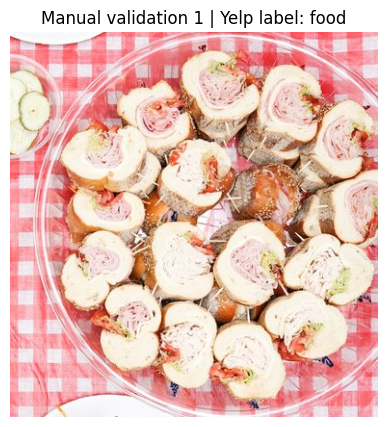


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.3
presentation_quality     : 0.7
portion_signal           : 0.5
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.3,
  "presentation_quality": 0.7,
  "portion_signal": 0.5,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.5
}
```

MANUAL PHOTO VALIDATION 2/24
Photo ID: BT9mpnWws2o7JJaRO6nuDQ
Business ID: UmqCcjR-UqXIn4ojeMuDwA
Yelp label: food
Caption: Zia

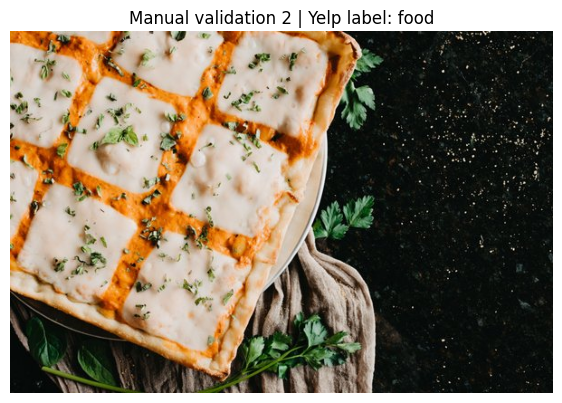


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.7
presentation_quality     : 0.8
portion_signal           : 0.6
visual_cleanliness       : 0.9
atmosphere_visual        : 0.4
environment_visual       : 0.2
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.8

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.7,
  "presentation_quality": 0.8,
  "portion_signal": 0.6,
  "visual_cleanliness": 0.9,
  "atmosphere_visual": 0.4,
  "environment_visual": 0.2,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.8
}
```

MANUAL PHOTO VALIDATION 3/24
Photo ID: rN-kDrZFaPpXSSLAthfP_Q
Business ID: X4M96ni5ay9ZmqWbgQxGZw
Yelp label: food
Caption: Cheesecake


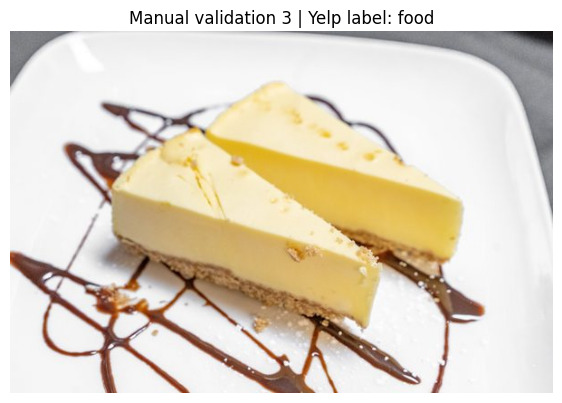


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.7
presentation_quality     : 0.8
portion_signal           : 0.6
visual_cleanliness       : 0.9
atmosphere_visual        : 0.4
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.7

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.7,
  "presentation_quality": 0.8,
  "portion_signal": 0.6,
  "visual_cleanliness": 0.9,
  "atmosphere_visual": 0.4,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.7
}
```

MANUAL PHOTO VALIDATION 4/24
Photo ID: RQfm-aQnmme7qh7thcwsMw
Business ID: 8xTHtLoNIwdpf0FEvIpQIw
Yelp label: food
Caption: Yummy!!
I

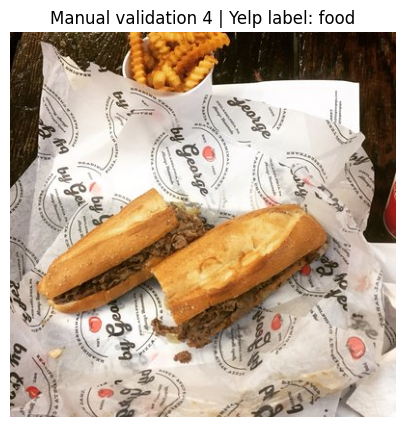


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.3
presentation_quality     : 0.2
portion_signal           : 0.7
visual_cleanliness       : 0.8
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.6

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": 0.3,
  "presentation_quality": 0.2,
  "portion_signal": 0.7,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.6
}

MANUAL PHOTO VALIDATION 5/24
Photo ID: lhi4gY_rMDoJ7pbtsTYq2w
Business ID: 25ZQ0blG4UNCYoa61tvLOQ
Yelp label: food
Caption: Lobster & Peach S

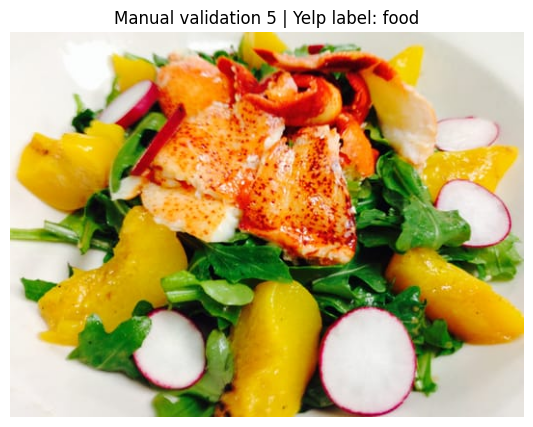


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.8
presentation_quality     : 0.7
portion_signal           : 0.6
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.9

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.8,
  "presentation_quality": 0.7,
  "portion_signal": 0.6,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.9
}
```

MANUAL PHOTO VALIDATION 6/24
Photo ID: CvI5YmNwTY6XPYYNVEkp6A
Business ID: BWITd9JUXP3gSi1z3Y-z8g
Yelp label: food
Caption: (no

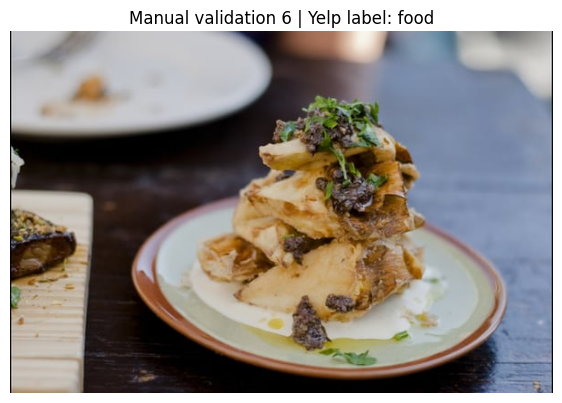


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.3
presentation_quality     : 0.4
portion_signal           : 0.2
visual_cleanliness       : 0.8
atmosphere_visual        : 0.1
environment_visual       : 0.2
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.6

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.3,
  "presentation_quality": 0.4,
  "portion_signal": 0.2,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": 0.1,
  "environment_visual": 0.2,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.6
}
```

MANUAL PHOTO VALIDATION 7/24
Photo ID: X2hoxjCPJmuYM89JPx6sxg
Business ID: u1aG60BpBh9CjuqT1_cWaw
Yelp label: inside
Caption: More of d

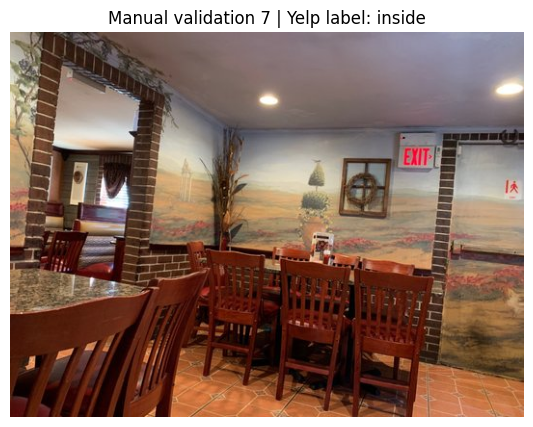


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : 0.3
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": 0.3,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.5
}
```

MANUAL PHOTO VALIDATION 8/24
Photo ID: cjd5vibsnwbw2Dn5kKFGCw
Business ID: 8wf4qYhu0miI6FzhZ5_mLQ
Yelp label: inside
Caption: (

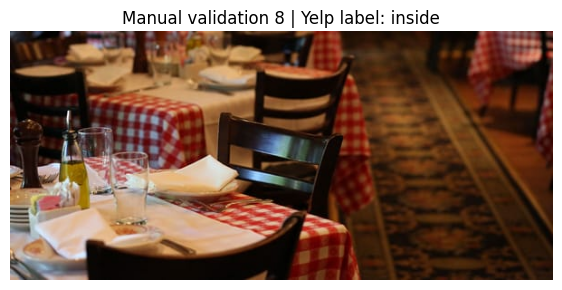


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : 0.2
environment_visual       : 0.8
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.7

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": 0.2,
  "environment_visual": 0.8,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.7
}
```

MANUAL PHOTO VALIDATION 9/24
Photo ID: Gwkzs5MmkmLBgYmxFLYCUQ
Business ID: rMuvtl4eluKRXx77j5WEMQ
Yelp label: inside
Caption: L

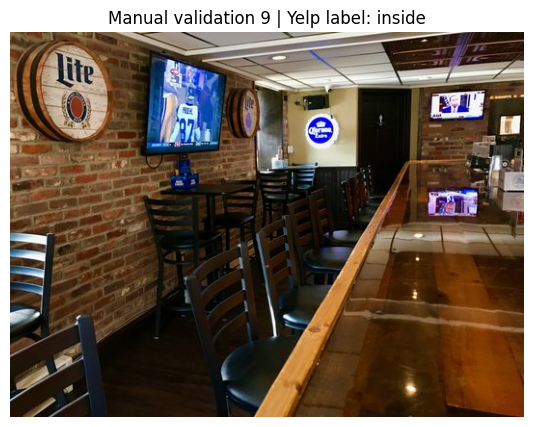


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : 0.2
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": 0.2,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.5
}
```

MANUAL PHOTO VALIDATION 10/24
Photo ID: CwxLiWoO2pMYngkO-3DN6w
Business ID: y4nAl5V6JU8tSB_IXqzvVQ
Yelp label: inside
Caption: 

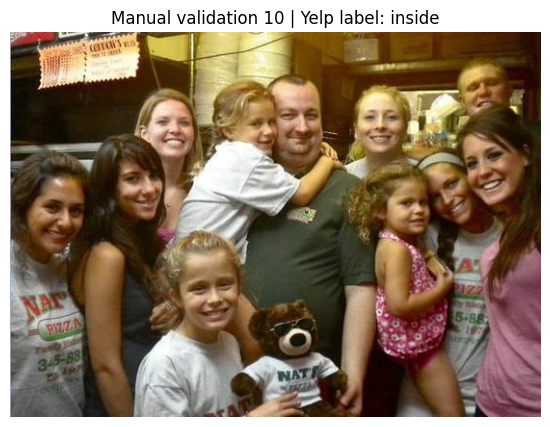


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.5
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.5,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 11/24
Photo ID: mDg_0Bsjp2ng7iXmW9ZpjQ
Business ID: qg6TJc2izTA52XFHAxdVjQ
Yelp label: inside
Capti

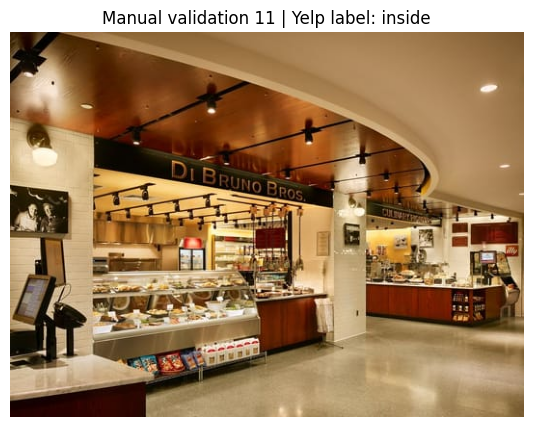


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.2
presentation_quality     : 0.3
portion_signal           : 0.5
visual_cleanliness       : 0.8
atmosphere_visual        : 0.6
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.8

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.2,
  "presentation_quality": 0.3,
  "portion_signal": 0.5,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": 0.6,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.8
}
```

MANUAL PHOTO VALIDATION 12/24
Photo ID: A62F3MxowNX5sXauzGWlxw
Business ID: eLbKuFpCtHEjCkoWkDDk7g
Yelp label: inside
Caption: (no capt

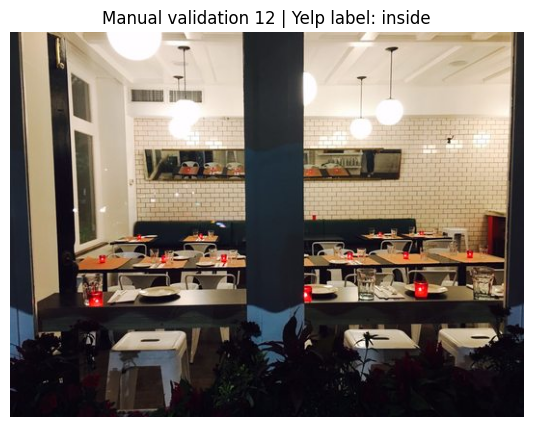


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 13/24
Photo ID: QektcobDbBLOyXS1C_7pUg
Business ID: 5kO9GPBD2TliR3cfpyN6jw
Yelp label: outside
Capt

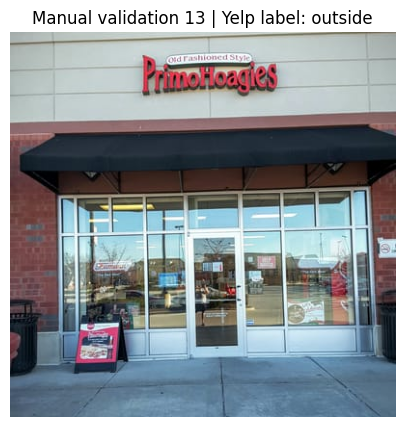


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.0
}

MANUAL PHOTO VALIDATION 14/24
Photo ID: K8VQUsDKxzlq9JmzZTInHg
Business ID: BHrKTazoosZdYUm2brFVaA
Yelp label: outside
Caption: (no cap

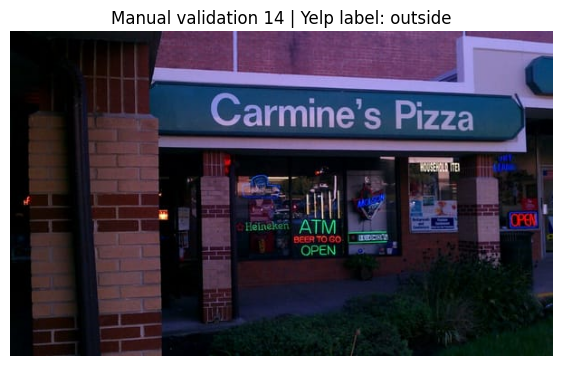


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.0
}

MANUAL PHOTO VALIDATION 15/24
Photo ID: Snlxz4YXo6T-CP2xV1pjXw
Business ID: pOvZxLj85yEOMFNRpZBtvw
Yelp label: outside
Caption: Anton

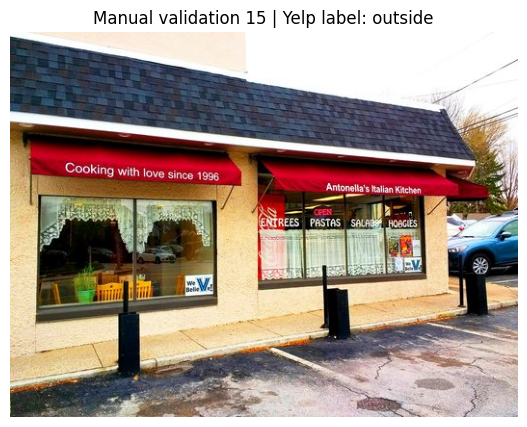


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 16/24
Photo ID: sD_i2dyJb9Q9FacUs3_I9g
Business ID: bMratNjTG5ZFEA6hVyr-xQ
Yelp label: outside
Ca

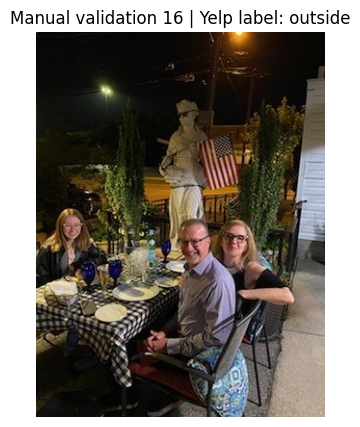


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : 0.3
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": 0.3,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.5
}
```

MANUAL PHOTO VALIDATION 17/24
Photo ID: vmKEKjyw__2UlNzHwHwcUw
Business ID: lYloPAiaWJwWgno4SdxD0Q
Yelp label: outside
Caption:

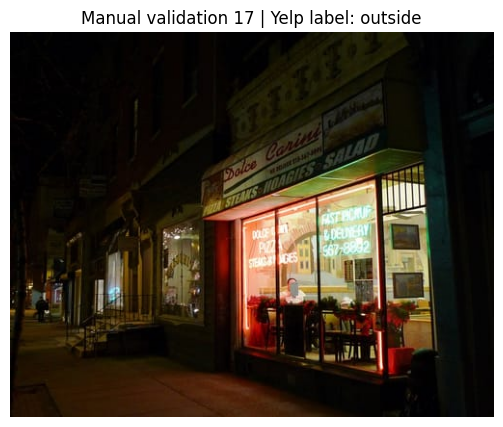


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 18/24
Photo ID: 6SqqzD9BxcOJgEYLsuTB3Q
Business ID: 4hv1n1VBzMvE-T4UtIcOcw
Yelp label: outside
Ca

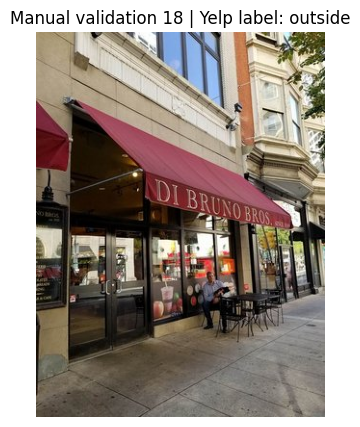


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 19/24
Photo ID: WCOgPOvKZl46Y1itp7HbBw
Business ID: T2NZEKXgfTIPothJrLyz2A
Yelp label: drink
Captio

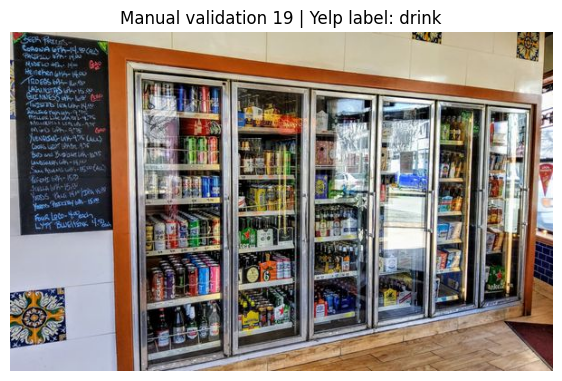


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : null
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": null,
  "negative_signals": 0.0,
  "confidence": 0.0
}
```

MANUAL PHOTO VALIDATION 20/24
Photo ID: qipfi2QVO-_a_l3ZtgTECw
Business ID: etFppnLk8foAeKcbQxGJ7w
Yelp label: drink
Capt

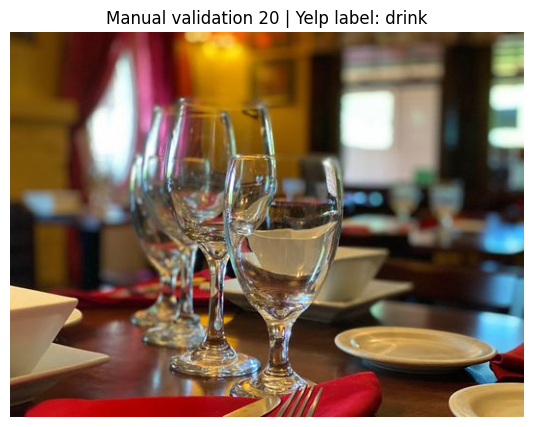


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : 0.2
portion_signal           : null
visual_cleanliness       : 0.8
atmosphere_visual        : 0.6
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": null,
  "presentation_quality": 0.2,
  "portion_signal": null,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": 0.6,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.5
}
```

MANUAL PHOTO VALIDATION 21/24
Photo ID: MFmZl1pkMeSijZXmns1Ekg
Business ID: OXFCsM7_GkJ9KC93_UIbuw
Yelp label: drink
Caption: (no c

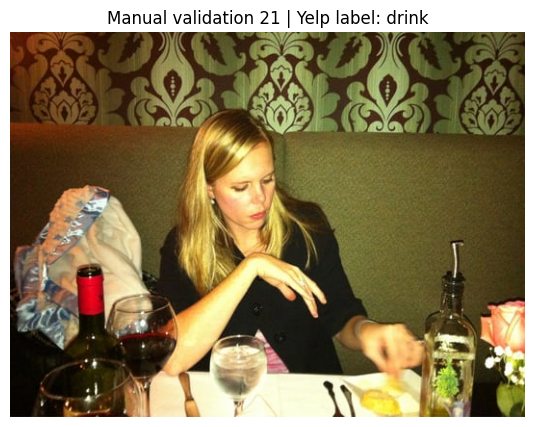


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.0
}

MANUAL PHOTO VALIDATION 22/24
Photo ID: JJUBcnez7kuoGhfaAh1sJg
Business ID: 5v9Voa4a5MON7mAQO3gV3A
Yelp label: drink
Caption: (no capti

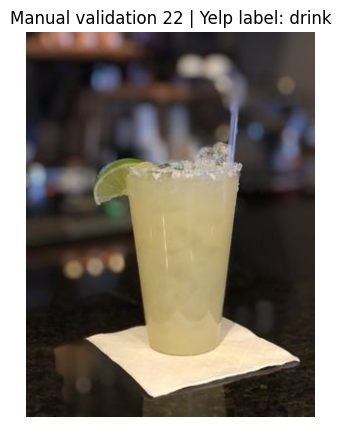


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.2
presentation_quality     : 0.3
portion_signal           : 0.4
visual_cleanliness       : 0.8
atmosphere_visual        : 0.6
environment_visual       : 0.7
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.5

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": 0.2,
  "presentation_quality": 0.3,
  "portion_signal": 0.4,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": 0.6,
  "environment_visual": 0.7,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.5
}

MANUAL PHOTO VALIDATION 23/24
Photo ID: 98RGdwG9M8cR5Gb6AHPWbQ
Business ID: b6IN3-jHnwlxwYoOXMZf0A
Yelp label: drink
Caption: Old Fashion happy hou

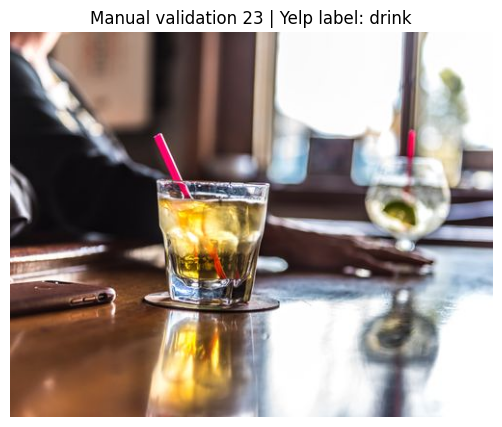


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : null
presentation_quality     : null
portion_signal           : null
visual_cleanliness       : null
atmosphere_visual        : null
environment_visual       : null
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.0

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
{
  "visual_food_appeal": null,
  "presentation_quality": null,
  "portion_signal": null,
  "visual_cleanliness": null,
  "atmosphere_visual": null,
  "environment_visual": null,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.0
}

MANUAL PHOTO VALIDATION 24/24
Photo ID: -oD2pKFgJy4mb5SLQ-_LbQ
Business ID: -7wXZWnKe26iwJY_5z_AAw
Yelp label: drink
Caption: (no capti

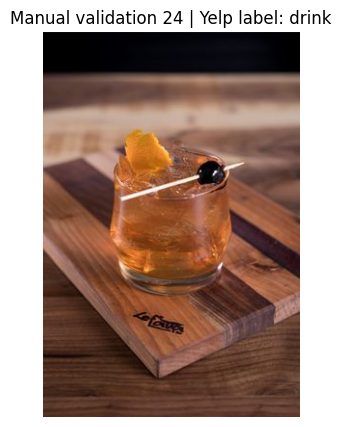


FINAL QWEN ANNOTATION
--------------------------------------------------------------------------------------------------------------
visual_food_appeal       : 0.3
presentation_quality     : 0.7
portion_signal           : 0.5
visual_cleanliness       : 0.8
atmosphere_visual        : 0.2
environment_visual       : 0.4
exterior_condition       : null
crowding_signal          : 0.0
negative_signals         : 0.0
confidence               : 0.6

RAW MODEL OUTPUT
--------------------------------------------------------------------------------------------------------------
```json
{
  "visual_food_appeal": 0.3,
  "presentation_quality": 0.7,
  "portion_signal": 0.5,
  "visual_cleanliness": 0.8,
  "atmosphere_visual": 0.2,
  "environment_visual": 0.4,
  "exterior_condition": null,
  "crowding_signal": 0.0,
  "negative_signals": 0.0,
  "confidence": 0.6
}
```

MANUAL VALIDATION SAMPLE CREATED
Photos displayed: 24
Validation sample saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/p

In [ ]:
# Manual Semantic Inspection of Final Photo Annotations


# In this step, I create a balanced manual validation sample
# from the completed image annotations.

# I display the selected Yelp photos together with their final
# Qwen annotations so that I can judge whether the visual scores
# are semantically reasonable.

# This cell does not modify the final annotation dataset.

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image


# 1. Setting the final photo annotation file


PHOTO_FINAL_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "photo_annotations_final.csv"
)


# 2. Loading the completed photo annotations

manual_photo_df = pd.read_csv(
    PHOTO_FINAL_PATH,
    low_memory=False
)


print(
    "Final photo annotations loaded:",
    len(
        manual_photo_df
    )
)

print(
    "Unique restaurants:",
    manual_photo_df[
        "business_id"
    ].nunique()
)


# 3. Defining the image indicators to inspect


MANUAL_IMAGE_INDICATORS = [
    "visual_food_appeal",
    "presentation_quality",
    "portion_signal",
    "visual_cleanliness",
    "atmosphere_visual",
    "environment_visual",
    "exterior_condition",
    "crowding_signal",
    "negative_signals",
    "confidence"
]


# 4. Selecting a balanced sample across Yelp photo labels

PHOTOS_PER_LABEL = 6

MANUAL_SAMPLE_RANDOM_STATE = 42

manual_validation_parts = []


for photo_label in [
    "food",
    "inside",
    "outside",
    "drink"
]:

    label_df = (
        manual_photo_df[
            manual_photo_df[
                "label"
            ] == photo_label
        ]
        .copy()
    )

    sampled_label_df = (
        label_df
        .sample(
            n=min(
                PHOTOS_PER_LABEL,
                len(
                    label_df
                )
            ),
            random_state=(
                MANUAL_SAMPLE_RANDOM_STATE
            )
        )
    )

    manual_validation_parts.append(
        sampled_label_df
    )


manual_validation_df = (
    pd.concat(
        manual_validation_parts,
        ignore_index=True
    )
    .reset_index(
        drop=True
    )
)


manual_validation_df[
    "manual_sample_id"
] = range(
    1,
    len(
        manual_validation_df
    ) + 1
)


print(
    "\nManual validation sample size:",
    len(
        manual_validation_df
    )
)

print(
    "\nSample composition:"
)

display(
    manual_validation_df[
        "label"
    ]
    .value_counts()
    .reindex(
        [
            "food",
            "inside",
            "outside",
            "drink"
        ]
    )
    .rename(
        "photo_count"
    )
    .to_frame()
)


# 5. Verifying that all sampled image files are available


manual_validation_df[
    "image_exists"
] = (
    manual_validation_df[
        "image_path"
    ]
    .astype(str)
    .map(
        lambda path: Path(
            path
        ).exists()
    )
)


print(
    "\nImages available on disk:",
    int(
        manual_validation_df[
            "image_exists"
        ].sum()
    ),
    "/",
    len(
        manual_validation_df
    )
)


assert (
    manual_validation_df[
        "image_exists"
    ].all()
)


# 6. Displaying each image with its annotation


for _, row in (
    manual_validation_df
    .iterrows()
):

    print("\n" + "=" * 110)

    print(
        "MANUAL PHOTO VALIDATION "
        f"{int(row['manual_sample_id'])}/"
        f"{len(manual_validation_df)}"
    )

    print("=" * 110)

    print(
        "Photo ID:",
        row[
            "photo_id"
        ]
    )

    print(
        "Business ID:",
        row[
            "business_id"
        ]
    )

    print(
        "Yelp label:",
        row[
            "label"
        ]
    )

    caption_value = row.get(
        "caption",
        None
    )

    if (
        pd.isna(
            caption_value
        )
        or str(
            caption_value
        ).strip() == ""
    ):

        caption_value = "(no caption)"

    print(
        "Caption:",
        caption_value
    )

    print(
        "Image path:",
        row[
            "image_path"
        ]
    )


    # I display the customer-uploaded Yelp image.
    image = Image.open(
        row[
            "image_path"
        ]
    )

    plt.figure(
        figsize=(
            7,
            5
        )
    )

    plt.imshow(
        image
    )

    plt.axis(
        "off"
    )

    plt.title(
        f"Manual validation {int(row['manual_sample_id'])} "
        f"| Yelp label: {row['label']}"
    )

    plt.show()


    print(
        "\nFINAL QWEN ANNOTATION"
    )

    print(
        "-" * 110
    )

    for indicator in (
        MANUAL_IMAGE_INDICATORS
    ):

        value = row[
            indicator
        ]

        if pd.isna(
            value
        ):

            value = "null"

        print(
            f"{indicator:25s}: {value}"
        )

    print(
        "\nRAW MODEL OUTPUT"
    )

    print(
        "-" * 110
    )

    print(
        row[
            "raw_output"
        ]
    )


# 7. Saving the sampled records for reproducibility


MANUAL_VALIDATION_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "annotation_qc/"
    "photo_manual_validation_24.csv"
)


manual_validation_df.to_csv(
    MANUAL_VALIDATION_PATH,
    index=False
)


print("\n" + "=" * 110)

print(
    "MANUAL VALIDATION SAMPLE CREATED"
)

print("=" * 110)

print(
    "Photos displayed:",
    len(
        manual_validation_df
    )
)

print(
    "Validation sample saved to:"
)

print(
    MANUAL_VALIDATION_PATH
)

# **7) LLM Feature Aggregation and Modeling Dataset**

In [ ]:
# Aggregating Final Review LLM Annotations to Restaurant-Period Level

# In this step, I aggregate the final review-level LLM annotations
# to one row per restaurant and analytical period.

# For nullable customer-perception indicators, I calculate the mean
# only from reviews where the construct was actually observed.

# I also calculate evidence counts and evidence shares so that missing
# evidence is not incorrectly treated as a neutral score of zero.


# 1. Setting input and output paths

REVIEW_ANNOTATION_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_text_annotations_final.csv"
)

REVIEW_PERIOD_AGG_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_llm_restaurant_period_final.csv"
)



# 2. Loading the final review annotations


review_llm_df = pd.read_csv(
    REVIEW_ANNOTATION_PATH,
    low_memory=False
)


print(
    "Review-level annotations loaded:",
    review_llm_df.shape
)

print(
    "Unique reviews:",
    review_llm_df[
        "review_id"
    ].nunique()
)

print(
    "Unique restaurants:",
    review_llm_df[
        "business_id"
    ].nunique()
)


# 3. Using the analytical-period column from the final dataset

period_col = "equal_period_4"


if period_col not in review_llm_df.columns:
    raise ValueError(
        f"Expected period column '{period_col}' was not found."
    )


print(
    "\nPeriod column used:",
    period_col
)

print(
    "\nPeriod values in final annotation dataset:"
)

display(
    review_llm_df[
        period_col
    ]
    .value_counts(
        dropna=False
    )
    .rename(
        "review_count"
    )
    .to_frame()
)


# 4. Defining the final review indicators and period order

nullable_review_indicators = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal"
]


always_numeric_review_indicators = [
    "overall_sentiment",
    "complaint_intensity",
    "confidence"
]


study_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]


period_order = {
    "early_pre": 1,
    "late_pre": 2,
    "shock": 3,
    "adaptation_recovery": 4
}


# 5. Checking that all required annotation columns exist

required_columns = (
    [
        "review_id",
        "business_id",
        period_col
    ]
    +
    nullable_review_indicators
    +
    always_numeric_review_indicators
)


missing_columns = [
    col
    for col in required_columns
    if col not in review_llm_df.columns
]


if missing_columns:
    raise ValueError(
        "Missing required columns: "
        + str(
            missing_columns
        )
    )


print(
    "\nAll required columns are available."
)



# 6. Keeping only reviews in the four analytical periods


review_llm_period_df = (
    review_llm_df[
        review_llm_df[
            period_col
        ].isin(
            study_periods
        )
    ]
    .copy()
)


print(
    "\nReviews in analytical periods:",
    len(
        review_llm_period_df
    )
)


print(
    "\nReview counts by period:"
)

display(
    review_llm_period_df[
        period_col
    ]
    .value_counts()
    .reindex(
        study_periods
    )
    .rename(
        "review_count"
    )
    .to_frame()
)


# 7. Checking that all 32,500 reviews remain

assert (
    len(
        review_llm_period_df
    )
    ==
    32500
), (
    "The final annotation file should contain exactly "
    "32,500 reviews in the four analytical periods."
)


assert (
    review_llm_period_df[
        "review_id"
    ].nunique()
    ==
    32500
), (
    "Review IDs should be unique."
)



# 8. Calculating total review count by restaurant and period

restaurant_period_base = (
    review_llm_period_df
    .groupby(
        [
            "business_id",
            period_col
        ],
        as_index=False
    )
    .agg(
        review_count=(
            "review_id",
            "count"
        )
    )
)


restaurant_period_llm = (
    restaurant_period_base
    .copy()
)

# 9. Aggregating nullable customer-perception indicators


# I calculate:
# - conditional mean among non-null annotations;
# - evidence count;
# - evidence share among all reviews in the restaurant-period.

for indicator in nullable_review_indicators:

    indicator_agg = (
        review_llm_period_df
        .groupby(
            [
                "business_id",
                period_col
            ]
        )[indicator]
        .agg(
            [
                "mean",
                "count"
            ]
        )
        .reset_index()
        .rename(
            columns={
                "mean": (
                    f"{indicator}_mean"
                ),
                "count": (
                    f"{indicator}_evidence_count"
                )
            }
        )
    )


    restaurant_period_llm = (
        restaurant_period_llm
        .merge(
            indicator_agg,
            on=[
                "business_id",
                period_col
            ],
            how="left"
        )
    )


    restaurant_period_llm[
        f"{indicator}_evidence_share"
    ] = (
        restaurant_period_llm[
            f"{indicator}_evidence_count"
        ]
        /
        restaurant_period_llm[
            "review_count"
        ]
    )


# 10. Aggregating indicators available for every review


always_numeric_agg = (
    review_llm_period_df
    .groupby(
        [
            "business_id",
            period_col
        ],
        as_index=False
    )
    .agg(
        overall_sentiment_mean=(
            "overall_sentiment",
            "mean"
        ),
        complaint_intensity_mean=(
            "complaint_intensity",
            "mean"
        ),
        confidence_mean=(
            "confidence",
            "mean"
        )
    )
)


restaurant_period_llm = (
    restaurant_period_llm
    .merge(
        always_numeric_agg,
        on=[
            "business_id",
            period_col
        ],
        how="left"
    )
)


# 11. Creating the complete 957 x 4 restaurant-period grid

all_business_ids = (
    review_llm_df[
        "business_id"
    ]
    .dropna()
    .drop_duplicates()
    .sort_values()
    .tolist()
)


complete_grid = (
    pd.MultiIndex
    .from_product(
        [
            all_business_ids,
            study_periods
        ],
        names=[
            "business_id",
            period_col
        ]
    )
    .to_frame(
        index=False
    )
)


restaurant_period_llm_complete = (
    complete_grid
    .merge(
        restaurant_period_llm,
        on=[
            "business_id",
            period_col
        ],
        how="left"
    )
)



# 12. Handling restaurant-periods with no reviews


# I record review count as zero when no reviews are present.

# I also record evidence counts as zero.

# Indicator means, evidence shares, overall sentiment, complaint
# intensity, and confidence remain missing because there was no
# review evidence in that restaurant-period.

restaurant_period_llm_complete[
    "review_count"
] = (
    restaurant_period_llm_complete[
        "review_count"
    ]
    .fillna(
        0
    )
    .astype(
        int
    )
)


for indicator in nullable_review_indicators:

    evidence_count_col = (
        f"{indicator}_evidence_count"
    )

    restaurant_period_llm_complete[
        evidence_count_col
    ] = (
        restaurant_period_llm_complete[
            evidence_count_col
        ]
        .fillna(
            0
        )
        .astype(
            int
        )
    )



# 13. Adding period order and sort the final long dataset

restaurant_period_llm_complete[
    "period_order"
] = (
    restaurant_period_llm_complete[
        period_col
    ]
    .map(
        period_order
    )
)


restaurant_period_llm_complete = (
    restaurant_period_llm_complete
    .sort_values(
        [
            "business_id",
            "period_order"
        ]
    )
    .reset_index(
        drop=True
    )
)


# 14. Checking final dimensions and uniqueness


expected_restaurants = 957
expected_periods = 4
expected_rows = (
    expected_restaurants
    *
    expected_periods
)


print(
    "\n" + "=" * 90
)

print(
    "RESTAURANT-PERIOD LLM AGGREGATION"
)

print(
    "=" * 90
)

print(
    "Restaurants:",
    len(
        all_business_ids
    )
)

print(
    "Periods:",
    len(
        study_periods
    )
)

print(
    "Expected rows:",
    expected_rows
)

print(
    "Actual rows:",
    len(
        restaurant_period_llm_complete
    )
)

print(
    "Columns:",
    restaurant_period_llm_complete.shape[
        1
    ]
)

print(
    "Duplicate restaurant-period rows:",
    restaurant_period_llm_complete
    .duplicated(
        subset=[
            "business_id",
            period_col
        ]
    )
    .sum()
)


assert (
    len(
        all_business_ids
    )
    ==
    expected_restaurants
)


assert (
    len(
        restaurant_period_llm_complete
    )
    ==
    expected_rows
)


assert (
    restaurant_period_llm_complete
    .duplicated(
        subset=[
            "business_id",
            period_col
        ]
    )
    .sum()
    ==
    0
)


# 15. Checking review totals and restaurant coverage by period


period_summary = (
    restaurant_period_llm_complete
    .groupby(
        period_col
    )
    .agg(
        restaurants=(
            "business_id",
            "nunique"
        ),
        restaurants_with_reviews=(
            "review_count",
            lambda x: int(
                (
                    x > 0
                ).sum()
            )
        ),
        total_reviews=(
            "review_count",
            "sum"
        )
    )
    .reindex(
        study_periods
    )
)


print(
    "\nPeriod-level aggregation summary:"
)

display(
    period_summary
)


# 16. Checking nullable-indicator evidence coverage

coverage_summary = []


for indicator in nullable_review_indicators:

    evidence_count_col = (
        f"{indicator}_evidence_count"
    )

    evidence_share_col = (
        f"{indicator}_evidence_share"
    )


    coverage_summary.append(
        {
            "indicator": indicator,

            "restaurant_periods_with_evidence": int(
                (
                    restaurant_period_llm_complete[
                        evidence_count_col
                    ]
                    > 0
                )
                .sum()
            ),

            "restaurant_period_evidence_coverage": (
                (
                    restaurant_period_llm_complete[
                        evidence_count_col
                    ]
                    > 0
                )
                .mean()
            ),

            "mean_evidence_share_when_reviews_exist": (
                restaurant_period_llm_complete
                .loc[
                    restaurant_period_llm_complete[
                        "review_count"
                    ]
                    > 0,
                    evidence_share_col
                ]
                .mean()
            )
        }
    )


coverage_summary_df = (
    pd.DataFrame(
        coverage_summary
    )
)


print(
    "\nLLM evidence coverage:"
)

display(
    coverage_summary_df
)


# 17. Checking that review totals reconstruct the original data


aggregated_review_total = int(
    restaurant_period_llm_complete[
        "review_count"
    ].sum()
)


print(
    "\nAggregated review total:",
    aggregated_review_total
)


assert (
    aggregated_review_total
    ==
    32500
)


# 18. Preview the final restaurant-period dataset


print(
    "\nPreview:"
)

display(
    restaurant_period_llm_complete.head(
        12
    )
)



# 19. Saving the restaurant-period LLM dataset


restaurant_period_llm_complete.to_csv(
    REVIEW_PERIOD_AGG_PATH,
    index=False
)


print(
    "\n" + "=" * 90
)

print(
    "AGGREGATION COMPLETE"
)

print(
    "=" * 90
)

print(
    "Final shape:",
    restaurant_period_llm_complete.shape
)

print(
    "Saved to:"
)

print(
    REVIEW_PERIOD_AGG_PATH
)

Review-level annotations loaded: (32500, 31)
Unique reviews: 32500
Unique restaurants: 957

Period column used: equal_period_4

Period values in final annotation dataset:


,review_count
equal_period_4,
early_pre,11253
late_pre,10471
adaptation_recovery,5600
shock,5176



All required columns are available.

Reviews in analytical periods: 32500

Review counts by period:


,review_count
equal_period_4,
early_pre,11253
late_pre,10471
shock,5176
adaptation_recovery,5600



RESTAURANT-PERIOD LLM AGGREGATION
Restaurants: 957
Periods: 4
Expected rows: 3828
Actual rows: 3828
Columns: 31
Duplicate restaurant-period rows: 0

Period-level aggregation summary:


,restaurants,restaurants_with_reviews,total_reviews
equal_period_4,,,
early_pre,957,957,11253
late_pre,957,877,10471
shock,957,771,5176
adaptation_recovery,957,749,5600



LLM evidence coverage:


,indicator,restaurant_periods_with_evidence,restaurant_period_evidence_coverage,mean_evidence_share_when_reviews_exist
0,food_quality,3257,0.850836,0.868766
1,price_value,2240,0.585162,0.223128
2,cleanliness,1088,0.284222,0.062847
3,service_reliability,2936,0.766980,0.541166
4,atmosphere,2116,0.552769,0.273569
5,environment,610,0.159352,0.025177
6,warmth,2774,0.724660,0.458755
7,visual_appeal,814,0.212644,0.037670



Aggregated review total: 32500

Preview:


,business_id,equal_period_4,review_count,food_quality_mean,food_quality_evidence_count,food_quality_evidence_share,price_value_mean,price_value_evidence_count,price_value_evidence_share,cleanliness_mean,...,warmth_mean,warmth_evidence_count,warmth_evidence_share,visual_appeal_mean,visual_appeal_evidence_count,visual_appeal_evidence_share,overall_sentiment_mean,complaint_intensity_mean,confidence_mean,period_order
0,-7wXZWnKe26iwJY_5z_AAw,early_pre,26,0.696154,26,1.000000,0.133333,3,0.115385,NaN,...,0.590476,21,0.807692,0.750000,2,0.076923,0.630769,0.169231,0.900000,1
1,-7wXZWnKe26iwJY_5z_AAw,late_pre,42,0.579487,39,0.928571,-0.123077,13,0.309524,-0.050,...,0.582353,34,0.809524,0.857143,7,0.166667,0.432143,0.278571,0.879762,2
2,-7wXZWnKe26iwJY_5z_AAw,shock,17,0.592857,14,0.823529,-0.080000,5,0.294118,1.000,...,0.833333,12,0.705882,0.750000,2,0.117647,0.488235,0.241176,0.905882,3
3,-7wXZWnKe26iwJY_5z_AAw,adaptation_recovery,29,0.391667,24,0.827586,-0.500000,8,0.275862,-0.025,...,0.290000,20,0.689655,NaN,0,0.000000,0.298276,0.346552,0.850000,4
4,-8gGD85_jZvapnmb3EvU3w,early_pre,5,-0.500000,4,0.800000,-0.250000,2,0.400000,0.000,...,0.000000,2,0.400000,-0.500000,2,0.400000,-0.500000,0.760000,0.940000,1
5,-8gGD85_jZvapnmb3EvU3w,late_pre,1,-1.000000,1,1.000000,-1.000000,1,1.000000,NaN,...,NaN,0,0.000000,NaN,0,0.000000,-1.000000,1.000000,1.000000,2
6,-8gGD85_jZvapnmb3EvU3w,shock,2,0.000000,2,1.000000,-1.000000,1,0.500000,NaN,...,0.000000,2,1.000000,NaN,0,0.000000,0.000000,0.450000,0.900000,3
7,-8gGD85_jZvapnmb3EvU3w,adaptation_recovery,3,-0.500000,3,1.000000,-1.000000,1,0.333333,NaN,...,0.500000,1,0.333333,NaN,0,0.000000,-0.233333,0.666667,0.833333,4
8,-DcRlgZdSCM0nQu4w4UI7g,early_pre,1,NaN,0,0.000000,NaN,0,0.000000,NaN,...,0.500000,1,1.000000,NaN,0,0.000000,0.500000,0.000000,0.800000,1
9,-DcRlgZdSCM0nQu4w4UI7g,late_pre,1,NaN,0,0.000000,NaN,0,0.000000,NaN,...,NaN,0,0.000000,NaN,0,0.000000,-1.000000,1.000000,1.000000,2



AGGREGATION COMPLETE
Final shape: (3828, 31)
Saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_llm_restaurant_period_final.csv


In [ ]:

# Creating Restaurant-Level Temporal LLM Features


# In this step, I transform the restaurant-period LLM dataset
# into one row per restaurant.

# I keep the four period-specific levels of each LLM indicator
# and calculate changes between the important study periods.

# For the nullable customer-perception indicators, I also keep
# evidence counts and evidence shares. This allows me to distinguish
# a score supported by many reviews from a score based on very little
# textual evidence.

# I do not replace missing customer-perception scores with zero.
# A missing value means that the construct was not observed or that
# the restaurant had no usable evidence for that construct.

# I also do not create repetition thresholds yet. I first create the
# continuous temporal features and inspect their distributions before
# deciding how repetition should be operationalized.



# 1. Setting input and output paths


REVIEW_PERIOD_AGG_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_llm_restaurant_period_final.csv"
)

REVIEW_TEMPORAL_FEATURES_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "review_llm_temporal_features_final.csv"
)


# 2. Loading the restaurant-period LLM dataset

restaurant_period_df = pd.read_csv(
    REVIEW_PERIOD_AGG_PATH,
    low_memory=False
)


print(
    "Restaurant-period dataset loaded:",
    restaurant_period_df.shape
)

print(
    "Unique restaurants:",
    restaurant_period_df[
        "business_id"
    ].nunique()
)

print(
    "Unique periods:",
    restaurant_period_df[
        "equal_period_4"
    ].nunique()
)


# 3. Defining the four analytical periods


study_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]


# 4. Defining the final LLM indicators


# These eight indicators can be missing when the review text
# contains no meaningful evidence for the construct.

nullable_indicators = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal"
]


# These two variables are available for every annotated review
# and are substantive customer-perception measures.

always_observed_substantive = [
    "overall_sentiment",
    "complaint_intensity"
]


# Confidence is retained as a quality-control measure.
# I keep it in the dataset, but I do not treat it as a substantive
# customer-perception predictor at this stage.

quality_indicator = [
    "confidence"
]



# 5. Defining the period-level columns to reshape


substantive_mean_columns = (
    [
        f"{indicator}_mean"
        for indicator in nullable_indicators
    ]
    +
    [
        f"{indicator}_mean"
        for indicator in always_observed_substantive
    ]
)


confidence_columns = [
    "confidence_mean"
]


evidence_count_columns = [
    f"{indicator}_evidence_count"
    for indicator in nullable_indicators
]


evidence_share_columns = [
    f"{indicator}_evidence_share"
    for indicator in nullable_indicators
]


# I also retain review counts for quality checks and later merging.

review_count_columns = [
    "review_count"
]


columns_to_reshape = (
    substantive_mean_columns
    +
    confidence_columns
    +
    evidence_count_columns
    +
    evidence_share_columns
    +
    review_count_columns
)



# 6. Checking that all required columns are available


required_columns = (
    [
        "business_id",
        "equal_period_4"
    ]
    +
    columns_to_reshape
)


missing_columns = [
    column
    for column in required_columns
    if column not in restaurant_period_df.columns
]


if missing_columns:
    raise ValueError(
        "Missing required columns: "
        + str(
            missing_columns
        )
    )


print(
    "\nAll required aggregation columns are available."
)



# 7. Checking the expected restaurant-period structure


expected_rows = 957 * 4


assert (
    len(
        restaurant_period_df
    )
    ==
    expected_rows
), (
    "The restaurant-period dataset should contain "
    "957 restaurants × 4 periods = 3,828 rows."
)


assert (
    restaurant_period_df
    .duplicated(
        subset=[
            "business_id",
            "equal_period_4"
        ]
    )
    .sum()
    ==
    0
), (
    "Restaurant-period combinations should be unique."
)



# 8. Converting period-level variables from long to wide format


# I create one row per restaurant
# For example:
# food_quality_mean + early_pre
# becomes:
# food_quality_mean_early_pre

wide_parts = []


for column in columns_to_reshape:

    wide_column = (
        restaurant_period_df
        .pivot(
            index="business_id",
            columns="equal_period_4",
            values=column
        )
        .reindex(
            columns=study_periods
        )
    )


    wide_column.columns = [
        f"{column}_{period}"
        for period in study_periods
    ]


    wide_parts.append(
        wide_column
    )


restaurant_llm_wide = (
    pd.concat(
        wide_parts,
        axis=1
    )
    .reset_index()
)


print(
    "\nWide restaurant-level dataset created:",
    restaurant_llm_wide.shape
)


# 9. Creating temporal changes for substantive LLM indicators

# I calculate four interpretable changes:

# 1. Early pre-shock -> Late pre-shock
#    Captures development before the external shock.

# 2. Late pre-shock -> Shock
#    Captures change associated with the shock period.

# 3. Shock -> Adaptation/recovery
#    Captures improvement or deterioration after the shock.

# 4. Early pre-shock -> Adaptation/recovery
#    Captures longer-term change across the full observation window.

# A positive change means that the later-period value is higher.
# A negative change means that the later-period value is lower.

# For complaint intensity, interpretation is reversed substantively:
# a positive change means complaints became more intense.

for column in substantive_mean_columns:

    restaurant_llm_wide[
        f"{column}_change_early_to_late_pre"
    ] = (
        restaurant_llm_wide[
            f"{column}_late_pre"
        ]
        -
        restaurant_llm_wide[
            f"{column}_early_pre"
        ]
    )


    restaurant_llm_wide[
        f"{column}_change_late_pre_to_shock"
    ] = (
        restaurant_llm_wide[
            f"{column}_shock"
        ]
        -
        restaurant_llm_wide[
            f"{column}_late_pre"
        ]
    )


    restaurant_llm_wide[
        f"{column}_change_shock_to_recovery"
    ] = (
        restaurant_llm_wide[
            f"{column}_adaptation_recovery"
        ]
        -
        restaurant_llm_wide[
            f"{column}_shock"
        ]
    )


    restaurant_llm_wide[
        f"{column}_change_early_pre_to_recovery"
    ] = (
        restaurant_llm_wide[
            f"{column}_adaptation_recovery"
        ]
        -
        restaurant_llm_wide[
            f"{column}_early_pre"
        ]
    )


# 10. Creating evidence-availability summaries

# For each nullable construct, I count how many of the four periods
# contain at least one review with evidence for that construct.

# This will later help me evaluate whether a temporal change is based
# on sufficiently observed information.

for indicator in nullable_indicators:

    evidence_period_columns = [
        f"{indicator}_evidence_count_{period}"
        for period in study_periods
    ]


    restaurant_llm_wide[
        f"{indicator}_periods_with_evidence"
    ] = (
        restaurant_llm_wide[
            evidence_period_columns
        ]
        .gt(
            0
        )
        .sum(
            axis=1
        )
    )


# 11. Creating general review-period availability


# I count the number of study periods in which each restaurant
# actually has at least one review.

review_period_columns = [
    f"review_count_{period}"
    for period in study_periods
]


restaurant_llm_wide[
    "llm_periods_with_reviews"
] = (
    restaurant_llm_wide[
        review_period_columns
    ]
    .gt(
        0
    )
    .sum(
        axis=1
    )
)


# 12. Checking the final restaurant-level structure

print(
    "\n" + "=" * 95
)

print(
    "RESTAURANT-LEVEL TEMPORAL LLM FEATURES"
)

print(
    "=" * 95
)


print(
    "Restaurants:",
    restaurant_llm_wide[
        "business_id"
    ].nunique()
)

print(
    "Rows:",
    len(
        restaurant_llm_wide
    )
)

print(
    "Columns:",
    restaurant_llm_wide.shape[
        1
    ]
)

print(
    "Duplicate business IDs:",
    restaurant_llm_wide[
        "business_id"
    ].duplicated().sum()
)


assert (
    len(
        restaurant_llm_wide
    )
    ==
    957
)


assert (
    restaurant_llm_wide[
        "business_id"
    ].nunique()
    ==
    957
)


assert (
    restaurant_llm_wide[
        "business_id"
    ].duplicated().sum()
    ==
    0
)


# 13. Inspecting availability of the temporal LLM changes


change_columns = [
    column
    for column in restaurant_llm_wide.columns
    if "_change_" in column
]


change_availability = (
    pd.DataFrame(
        {
            "feature": change_columns,
            "available_restaurants": [
                restaurant_llm_wide[
                    column
                ].notna().sum()
                for column in change_columns
            ]
        }
    )
)


change_availability[
    "coverage"
] = (
    change_availability[
        "available_restaurants"
    ]
    /
    957
)


print(
    "\nAvailability of temporal LLM change variables:"
)

display(
    change_availability
)


# 14. Inspecting construct evidence across the four periods

evidence_period_summary = []


for indicator in nullable_indicators:

    periods_column = (
        f"{indicator}_periods_with_evidence"
    )


    evidence_period_summary.append(
        {
            "indicator": indicator,

            "mean_periods_with_evidence": (
                restaurant_llm_wide[
                    periods_column
                ]
                .mean()
            ),

            "restaurants_with_evidence_all_4_periods": int(
                (
                    restaurant_llm_wide[
                        periods_column
                    ]
                    ==
                    4
                )
                .sum()
            ),

            "restaurants_with_evidence_3plus_periods": int(
                (
                    restaurant_llm_wide[
                        periods_column
                    ]
                    >=
                    3
                )
                .sum()
            ),

            "restaurants_with_no_evidence": int(
                (
                    restaurant_llm_wide[
                        periods_column
                    ]
                    ==
                    0
                )
                .sum()
            )
        }
    )


evidence_period_summary_df = pd.DataFrame(
    evidence_period_summary
)


print(
    "\nEvidence availability across periods:"
)

display(
    evidence_period_summary_df
)


# 15. Preview selected temporal features


preview_columns = [
    "business_id",

    "food_quality_mean_early_pre",
    "food_quality_mean_late_pre",
    "food_quality_mean_shock",
    "food_quality_mean_adaptation_recovery",

    "food_quality_mean_change_late_pre_to_shock",
    "food_quality_mean_change_shock_to_recovery",

    "overall_sentiment_mean_early_pre",
    "overall_sentiment_mean_shock",
    "overall_sentiment_mean_adaptation_recovery",

    "complaint_intensity_mean_early_pre",
    "complaint_intensity_mean_shock",
    "complaint_intensity_mean_adaptation_recovery",

    "food_quality_periods_with_evidence",
    "llm_periods_with_reviews"
]


print(
    "\nPreview of selected restaurant-level temporal LLM features:"
)

display(
    restaurant_llm_wide[
        preview_columns
    ]
    .head(
        12
    )
)



# 16. Saving the restaurant-level temporal LLM feature dataset


restaurant_llm_wide.to_csv(
    REVIEW_TEMPORAL_FEATURES_PATH,
    index=False
)


print(
    "\n" + "=" * 95
)

print(
    "TEMPORAL LLM FEATURE CONSTRUCTION COMPLETE"
)

print(
    "=" * 95
)

print(
    "Final shape:",
    restaurant_llm_wide.shape
)

print(
    "Saved to:"
)

print(
    REVIEW_TEMPORAL_FEATURES_PATH
)

Restaurant-period dataset loaded: (3828, 31)
Unique restaurants: 957
Unique periods: 4

All required aggregation columns are available.

Wide restaurant-level dataset created: (957, 113)

RESTAURANT-LEVEL TEMPORAL LLM FEATURES
Restaurants: 957
Rows: 957
Columns: 162
Duplicate business IDs: 0

Availability of temporal LLM change variables:


,feature,available_restaurants,coverage
0,food_quality_mean_change_early_to_late_pre,835,0.872518
1,food_quality_mean_change_late_pre_to_shock,717,0.749216
2,food_quality_mean_change_shock_to_recovery,663,0.692790
3,food_quality_mean_change_early_pre_to_recovery,716,0.748171
4,price_value_mean_change_early_to_late_pre,500,0.522466
5,price_value_mean_change_late_pre_to_shock,386,0.403344
6,price_value_mean_change_shock_to_recovery,299,0.312435
7,price_value_mean_change_early_pre_to_recovery,375,0.391850
8,cleanliness_mean_change_early_to_late_pre,148,0.154650
9,cleanliness_mean_change_late_pre_to_shock,114,0.119122



Evidence availability across periods:


,indicator,mean_periods_with_evidence,restaurants_with_evidence_all_4_periods,restaurants_with_evidence_3plus_periods,restaurants_with_no_evidence
0,food_quality,3.403344,633,786,8
1,price_value,2.340648,231,472,98
2,cleanliness,1.136886,27,125,328
3,service_reliability,3.067921,469,685,21
4,atmosphere,2.211076,271,432,154
5,environment,0.637409,13,52,567
6,warmth,2.898642,413,627,31
7,visual_appeal,0.850575,40,108,516



Preview of selected restaurant-level temporal LLM features:


,business_id,food_quality_mean_early_pre,food_quality_mean_late_pre,food_quality_mean_shock,food_quality_mean_adaptation_recovery,food_quality_mean_change_late_pre_to_shock,food_quality_mean_change_shock_to_recovery,overall_sentiment_mean_early_pre,overall_sentiment_mean_shock,overall_sentiment_mean_adaptation_recovery,complaint_intensity_mean_early_pre,complaint_intensity_mean_shock,complaint_intensity_mean_adaptation_recovery,food_quality_periods_with_evidence,llm_periods_with_reviews
0,-7wXZWnKe26iwJY_5z_AAw,0.696154,0.579487,0.592857,0.391667,0.013370,-0.201190,0.630769,0.488235,0.298276,0.169231,0.241176,0.346552,4,4
1,-8gGD85_jZvapnmb3EvU3w,-0.500000,-1.000000,0.000000,-0.500000,1.000000,-0.500000,-0.500000,0.000000,-0.233333,0.760000,0.450000,0.666667,4,4
2,-DcRlgZdSCM0nQu4w4UI7g,NaN,NaN,NaN,NaN,NaN,NaN,0.500000,NaN,NaN,0.000000,NaN,NaN,0,2
3,-HoCrhW2f7610NWGDemnjw,-0.750000,1.000000,1.000000,NaN,0.000000,NaN,-0.500000,1.000000,NaN,0.850000,0.000000,NaN,3,3
4,-IOWVdmqsfd02_G-nJACdQ,0.175000,0.640000,0.800000,NaN,0.160000,NaN,0.316667,0.800000,NaN,0.316667,0.000000,NaN,3,3
5,-JStjL-8mRZq4ov4uI1FaQ,0.055556,0.600000,0.916667,0.571429,0.316667,-0.345238,0.200000,0.916667,0.628571,0.366667,0.000000,0.171429,4,4
6,-PMXnNJ1D67NkAupRHNkpQ,NaN,NaN,-0.500000,0.500000,NaN,1.000000,-1.000000,-0.650000,-0.500000,1.000000,0.850000,0.733333,2,4
7,-Ti5pwj6mA99khsxxur8aQ,1.000000,0.802453,0.818182,0.789362,0.015729,-0.028820,1.000000,0.756522,0.706122,0.000000,0.110870,0.130612,4,4
8,-UJ7ZTb3zfmqZogmy3fnGg,0.288000,0.373333,1.000000,0.471429,0.626667,-0.528571,-0.137500,1.000000,0.133333,0.581250,0.000000,0.444444,4,4
9,-cEFKAznWmI0cledNOIQ7w,0.703333,0.660345,0.727273,0.656522,0.066928,-0.070751,0.666391,0.706250,0.664592,0.140602,0.120833,0.151020,4,4



TEMPORAL LLM FEATURE CONSTRUCTION COMPLETE
Final shape: (957, 162)
Saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/review_llm_temporal_features_final.csv


In [ ]:
# Aggregating Final Image Annotations to Restaurant Level

# In this step, I aggregate the final image-level LLM annotations
# to one row per restaurant.

# The Yelp images do not contain upload dates, so I do not create
# temporal image features. Instead, each restaurant receives one set
# of aggregate visual indicators across its sampled customer photos.

# For nullable visual indicators, I calculate the mean only from
# photos where the construct was actually assessable.

# I also calculate evidence counts and evidence shares so that I can
# distinguish a restaurant with strong visual evidence from one whose
# score is based on only one assessable photo.

# I do not replace missing visual indicators with zero.
# A missing value means that the construct could not be meaningfully
# assessed from any sampled photo for that restaurant.

# I retain image confidence as a quality-control measure rather than
# automatically treating it as a substantive predictor.



# 1. Setting input and output paths


PHOTO_ANNOTATION_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "photo_annotations_final.csv"
)

IMAGE_RESTAURANT_FEATURES_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "image_llm_restaurant_features_final.csv"
)


# 2. Loading the final image annotations


image_llm_df = pd.read_csv(
    PHOTO_ANNOTATION_PATH,
    low_memory=False
)


print(
    "Image-level annotations loaded:",
    image_llm_df.shape
)

print(
    "Unique photos:",
    image_llm_df[
        "photo_id"
    ].nunique()
)

print(
    "Unique restaurants:",
    image_llm_df[
        "business_id"
    ].nunique()
)


# 3. Defining the final image indicators


# These indicators can be missing when the construct cannot be
# meaningfully assessed from a particular image.

nullable_image_indicators = [
    "visual_food_appeal",
    "presentation_quality",
    "portion_signal",
    "visual_cleanliness",
    "atmosphere_visual",
    "environment_visual",
    "exterior_condition",
    "crowding_signal"
]


# These indicators are available for every image.

always_numeric_image_indicators = [
    "negative_signals",
    "confidence"
]


# 4. Checking that all required columns are available


required_columns = (
    [
        "photo_id",
        "business_id",
        "label"
    ]
    +
    nullable_image_indicators
    +
    always_numeric_image_indicators
)


missing_columns = [
    column
    for column in required_columns
    if column not in image_llm_df.columns
]


if missing_columns:
    raise ValueError(
        "Missing required image columns: "
        + str(
            missing_columns
        )
    )


print(
    "\nAll required image annotation columns are available."
)



# 5. Checking the final image dataset structure

assert (
    len(
        image_llm_df
    )
    ==
    1957
), (
    "The final image annotation dataset should contain "
    "exactly 1,957 sampled images."
)


assert (
    image_llm_df[
        "photo_id"
    ].nunique()
    ==
    1957
), (
    "Photo IDs should be unique."
)


assert (
    image_llm_df[
        "business_id"
    ].nunique()
    ==
    639
), (
    "The final sampled image dataset should represent "
    "639 restaurants."
)


print(
    "\nFinal image structure confirmed."
)



# 6. Calculating basic photo counts for each restaurant


# I retain the total number of sampled photos because restaurants
# have between one and five sampled images.

restaurant_image_features = (
    image_llm_df
    .groupby(
        "business_id",
        as_index=False
    )
    .agg(
        sampled_photo_count=(
            "photo_id",
            "count"
        )
    )
)


# 7. Calculating photo counts by Yelp label


# I keep separate counts of food, inside, outside, and drink photos.
# These variables help describe the type of visual information
# available for each restaurant.

photo_label_counts = (
    image_llm_df
    .assign(
        label=lambda df: (
            df[
                "label"
            ]
            .astype(str)
            .str.lower()
        )
    )
    .groupby(
        [
            "business_id",
            "label"
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        columns=[
            "food",
            "inside",
            "outside",
            "drink"
        ],
        fill_value=0
    )
    .reset_index()
)


photo_label_counts = (
    photo_label_counts
    .rename(
        columns={
            "food": "food_photo_count",
            "inside": "inside_photo_count",
            "outside": "outside_photo_count",
            "drink": "drink_photo_count"
        }
    )
)


restaurant_image_features = (
    restaurant_image_features
    .merge(
        photo_label_counts,
        on="business_id",
        how="left"
    )
)


# 8. Aggregating nullable visual indicators

# For every nullable visual construct, I calculate:

# - the mean among photos where the construct is non-null;
# - the number of sampled photos providing evidence;
# - the share of sampled photos providing evidence.

# For example, if a restaurant has five sampled photos but only
# two show enough of the restaurant interior to assess atmosphere,
# atmosphere_evidence_count will equal 2 and the evidence share
# will equal 0.4.

for indicator in nullable_image_indicators:

    indicator_agg = (
        image_llm_df
        .groupby(
            "business_id"
        )[indicator]
        .agg(
            [
                "mean",
                "count"
            ]
        )
        .reset_index()
        .rename(
            columns={
                "mean": (
                    f"{indicator}_mean"
                ),
                "count": (
                    f"{indicator}_evidence_count"
                )
            }
        )
    )


    restaurant_image_features = (
        restaurant_image_features
        .merge(
            indicator_agg,
            on="business_id",
            how="left"
        )
    )


    restaurant_image_features[
        f"{indicator}_evidence_share"
    ] = (
        restaurant_image_features[
            f"{indicator}_evidence_count"
        ]
        /
        restaurant_image_features[
            "sampled_photo_count"
        ]
    )


# 9. Aggregating indicators available for every image

# Negative visual signals and confidence are defined for every
# annotated image, so I calculate their restaurant-level means
# across all sampled photos.

always_numeric_agg = (
    image_llm_df
    .groupby(
        "business_id",
        as_index=False
    )
    .agg(
        negative_signals_mean=(
            "negative_signals",
            "mean"
        ),
        confidence_mean=(
            "confidence",
            "mean"
        )
    )
)


restaurant_image_features = (
    restaurant_image_features
    .merge(
        always_numeric_agg,
        on="business_id",
        how="left"
    )
)


# 10. Creating visual-data availability indicators


# Every restaurant in this table has at least one eligible sampled
# and annotated image, so has_visual_annotation is always 1 here.

# This variable becomes useful later when this table is merged with
# the full cohort of 957 restaurants.

restaurant_image_features[
    "has_visual_annotation"
] = 1


# I also record whether each restaurant has at least one image
# from the major Yelp visual categories.

restaurant_image_features[
    "has_food_photo"
] = (
    restaurant_image_features[
        "food_photo_count"
    ]
    >
    0
).astype(
    int
)


restaurant_image_features[
    "has_inside_photo"
] = (
    restaurant_image_features[
        "inside_photo_count"
    ]
    >
    0
).astype(
    int
)


restaurant_image_features[
    "has_outside_photo"
] = (
    restaurant_image_features[
        "outside_photo_count"
    ]
    >
    0
).astype(
    int
)


restaurant_image_features[
    "has_drink_photo"
] = (
    restaurant_image_features[
        "drink_photo_count"
    ]
    >
    0
).astype(
    int
)


# 11. Sorting the final restaurant-level image dataset


restaurant_image_features = (
    restaurant_image_features
    .sort_values(
        "business_id"
    )
    .reset_index(
        drop=True
    )
)



# 12. Checking the final restaurant-level structure


print(
    "\n" + "=" * 95
)

print(
    "RESTAURANT-LEVEL IMAGE FEATURES"
)

print(
    "=" * 95
)


print(
    "Restaurants:",
    restaurant_image_features[
        "business_id"
    ].nunique()
)

print(
    "Rows:",
    len(
        restaurant_image_features
    )
)

print(
    "Columns:",
    restaurant_image_features.shape[
        1
    ]
)

print(
    "Duplicate business IDs:",
    restaurant_image_features[
        "business_id"
    ].duplicated().sum()
)


assert (
    len(
        restaurant_image_features
    )
    ==
    639
)


assert (
    restaurant_image_features[
        "business_id"
    ].nunique()
    ==
    639
)


assert (
    restaurant_image_features[
        "business_id"
    ].duplicated().sum()
    ==
    0
)



# 13. Checking that photo counts reconstruct the image dataset


aggregated_photo_total = int(
    restaurant_image_features[
        "sampled_photo_count"
    ].sum()
)


print(
    "\nAggregated sampled-photo total:",
    aggregated_photo_total
)


assert (
    aggregated_photo_total
    ==
    1957
)


# 14. Inspecting photo-category availability


photo_category_summary = pd.DataFrame(
    {
        "photo_category": [
            "food",
            "inside",
            "outside",
            "drink"
        ],

        "restaurants_with_category": [
            int(
                restaurant_image_features[
                    "has_food_photo"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "has_inside_photo"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "has_outside_photo"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "has_drink_photo"
                ].sum()
            )
        ],

        "total_sampled_photos": [
            int(
                restaurant_image_features[
                    "food_photo_count"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "inside_photo_count"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "outside_photo_count"
                ].sum()
            ),
            int(
                restaurant_image_features[
                    "drink_photo_count"
                ].sum()
            )
        ]
    }
)


print(
    "\nPhoto-category availability:"
)

display(
    photo_category_summary
)


# 15. Inspecting evidence coverage for visual indicators


image_coverage_summary = []


for indicator in nullable_image_indicators:

    evidence_count_col = (
        f"{indicator}_evidence_count"
    )

    evidence_share_col = (
        f"{indicator}_evidence_share"
    )


    restaurants_with_evidence = int(
        (
            restaurant_image_features[
                evidence_count_col
            ]
            >
            0
        )
        .sum()
    )


    image_coverage_summary.append(
        {
            "indicator": indicator,

            "restaurants_with_evidence": (
                restaurants_with_evidence
            ),

            "coverage_among_annotated_restaurants": (
                restaurants_with_evidence
                /
                639
            ),

            "mean_evidence_count_when_available": (
                restaurant_image_features
                .loc[
                    restaurant_image_features[
                        evidence_count_col
                    ]
                    >
                    0,
                    evidence_count_col
                ]
                .mean()
            ),

            "mean_evidence_share": (
                restaurant_image_features[
                    evidence_share_col
                ]
                .mean()
            )
        }
    )


image_coverage_summary_df = pd.DataFrame(
    image_coverage_summary
)


print(
    "\nVisual-indicator evidence coverage:"
)

display(
    image_coverage_summary_df
)


# 16. Inspecting restaurant-level variation of visual indicators


image_mean_columns = [
    f"{indicator}_mean"
    for indicator in nullable_image_indicators
] + [
    "negative_signals_mean",
    "confidence_mean"
]


image_distribution_summary = (
    restaurant_image_features[
        image_mean_columns
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max"
        ]
    )
    .T
    .reset_index()
    .rename(
        columns={
            "index": "feature"
        }
    )
)


print(
    "\nRestaurant-level image-feature distributions:"
)

display(
    image_distribution_summary
)



# 17. Preview selected image features


preview_columns = [
    "business_id",
    "sampled_photo_count",

    "food_photo_count",
    "inside_photo_count",
    "outside_photo_count",
    "drink_photo_count",

    "visual_food_appeal_mean",
    "visual_food_appeal_evidence_count",

    "visual_cleanliness_mean",
    "visual_cleanliness_evidence_count",

    "atmosphere_visual_mean",
    "atmosphere_visual_evidence_count",

    "environment_visual_mean",
    "environment_visual_evidence_count",

    "exterior_condition_mean",
    "exterior_condition_evidence_count",

    "crowding_signal_mean",

    "negative_signals_mean",
    "confidence_mean"
]


print(
    "\nPreview of restaurant-level image features:"
)

display(
    restaurant_image_features[
        preview_columns
    ]
    .head(
        12
    )
)



# 18. Saving the restaurant-level image feature dataset


restaurant_image_features.to_csv(
    IMAGE_RESTAURANT_FEATURES_PATH,
    index=False
)


print(
    "\n" + "=" * 95
)

print(
    "IMAGE FEATURE AGGREGATION COMPLETE"
)

print(
    "=" * 95
)

print(
    "Final shape:",
    restaurant_image_features.shape
)

print(
    "Saved to:"
)

print(
    IMAGE_RESTAURANT_FEATURES_PATH
)

Image-level annotations loaded: (1957, 28)
Unique photos: 1957
Unique restaurants: 639

All required image annotation columns are available.

Final image structure confirmed.

RESTAURANT-LEVEL IMAGE FEATURES
Restaurants: 639
Rows: 639
Columns: 37
Duplicate business IDs: 0

Aggregated sampled-photo total: 1957

Photo-category availability:


,photo_category,restaurants_with_category,total_sampled_photos
0,food,516,1194
1,inside,322,489
2,outside,156,185
3,drink,83,89



Visual-indicator evidence coverage:


,indicator,restaurants_with_evidence,coverage_among_annotated_restaurants,mean_evidence_count_when_available,mean_evidence_share
0,visual_food_appeal,530,0.829421,2.454717,0.646166
1,presentation_quality,530,0.829421,2.454717,0.646166
2,portion_signal,530,0.829421,2.454717,0.646166
3,visual_cleanliness,496,0.776213,2.274194,0.545383
4,atmosphere_visual,471,0.737089,2.352442,0.514684
5,environment_visual,456,0.713615,2.186404,0.463406
6,exterior_condition,23,0.035994,1.130435,0.015310
7,crowding_signal,527,0.824726,2.335863,0.606912



Restaurant-level image-feature distributions:


,feature,count,mean,std,min,median,max
0,visual_food_appeal_mean,530.0,0.529811,0.182530,-0.5,0.566667,0.80
1,presentation_quality_mean,530.0,0.518189,0.180125,-0.5,0.566667,0.85
2,portion_signal_mean,530.0,0.587877,0.173787,-0.5,0.600000,0.90
3,visual_cleanliness_mean,496.0,0.826529,0.107810,-0.5,0.850000,0.90
4,atmosphere_visual_mean,471.0,0.401168,0.116285,0.1,0.400000,0.70
5,environment_visual_mean,456.0,0.429777,0.161060,0.1,0.400000,0.80
6,exterior_condition_mean,23.0,0.684783,0.181806,0.0,0.700000,0.90
7,crowding_signal_mean,527.0,0.040452,0.084398,0.0,0.000000,0.70
8,negative_signals_mean,639.0,0.002032,0.032817,0.0,0.000000,0.80
9,confidence_mean,639.0,0.531894,0.223077,0.0,0.600000,0.85



Preview of restaurant-level image features:


,business_id,sampled_photo_count,food_photo_count,inside_photo_count,outside_photo_count,drink_photo_count,visual_food_appeal_mean,visual_food_appeal_evidence_count,visual_cleanliness_mean,visual_cleanliness_evidence_count,atmosphere_visual_mean,atmosphere_visual_evidence_count,environment_visual_mean,environment_visual_evidence_count,exterior_condition_mean,exterior_condition_evidence_count,crowding_signal_mean,negative_signals_mean,confidence_mean
0,-7wXZWnKe26iwJY_5z_AAw,5,1,2,1,1,0.500000,2,0.850,2,0.466667,3,0.533333,3,NaN,0,0.000000,0.0,0.38
1,-DcRlgZdSCM0nQu4w4UI7g,3,2,1,0,0,0.700000,2,0.900,1,0.400000,1,0.300000,1,NaN,0,0.000000,0.0,0.50
2,-HoCrhW2f7610NWGDemnjw,1,0,1,0,0,NaN,0,NaN,0,0.300000,1,0.400000,1,NaN,0,0.000000,0.0,0.20
3,-JStjL-8mRZq4ov4uI1FaQ,1,0,1,0,0,NaN,0,NaN,0,NaN,0,NaN,0,NaN,0,0.300000,0.0,0.70
4,-PMXnNJ1D67NkAupRHNkpQ,1,1,0,0,0,0.700000,1,0.800,1,NaN,0,NaN,0,NaN,0,NaN,0.0,0.70
5,-Ti5pwj6mA99khsxxur8aQ,4,3,1,0,0,0.366667,3,0.800,2,0.366667,3,0.500000,3,NaN,0,0.066667,0.0,0.55
6,-UJ7ZTb3zfmqZogmy3fnGg,5,2,2,0,1,0.700000,2,0.900,2,0.400000,2,0.300000,2,NaN,0,0.000000,0.0,0.28
7,-cEFKAznWmI0cledNOIQ7w,5,2,1,1,1,0.500000,2,0.850,2,0.400000,2,0.450000,2,NaN,0,0.233333,0.0,0.44
8,-t1hxZ6X-XaIU4BBUQCXGA,1,1,0,0,0,0.700000,1,0.900,1,0.600000,1,0.500000,1,NaN,0,0.000000,0.0,0.80
9,-t5dx3X0O63jCUuFEd-FcA,5,5,0,0,0,0.640000,5,0.875,4,0.475000,4,0.425000,4,NaN,0,0.000000,0.0,0.68



IMAGE FEATURE AGGREGATION COMPLETE
Final shape: (639, 37)
Saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/image_llm_restaurant_features_final.csv


In [ ]:
# Creating the Final Restaurant-Level Modeling Dataset

# In this step, I combine the three restaurant-level datasets that
# contain the variables needed for the later statistical analysis:

# 1. the existing Yelp baseline and dynamic features;
# 2. the temporal LLM review-text features;
# 3. the restaurant-level image features.

# The unit of analysis remains one restaurant.

# I use the full fixed cohort of 957 restaurants as the base dataset.
# Image features are added with a left join because only a subset of
# restaurants has eligible annotated photos.

# Restaurants without annotated images remain in the dataset.
# Their visual scores remain missing rather than being set to zero.

# 1. Defining the output path


FINAL_MODELING_DATASET_PATH = Path(
    "/content/drive/MyDrive/"
    "TUM_thesis_digital_marketing/"
    "processed/"
    "final_restaurant_modeling_dataset.csv"
)


# 2. Preparing the three restaurant-level datasets



dynamic_yelp_df = (
    equal_4period_dynamic_df
    .copy()
)



review_llm_features_df = (
    restaurant_llm_wide
    .copy()
)



image_llm_features_df = (
    restaurant_image_features
    .copy()
)


print(
    "Dynamic Yelp dataset:",
    dynamic_yelp_df.shape
)

print(
    "Temporal review LLM dataset:",
    review_llm_features_df.shape
)

print(
    "Image LLM dataset:",
    image_llm_features_df.shape
)


# 3. Checking that each dataset has one row per restaurant

for dataset_name, dataset in {
    "Dynamic Yelp": dynamic_yelp_df,
    "Review LLM": review_llm_features_df,
    "Image LLM": image_llm_features_df
}.items():

    duplicate_count = (
        dataset[
            "business_id"
        ]
        .duplicated()
        .sum()
    )

    print(
        f"{dataset_name} duplicate business IDs:",
        duplicate_count
    )

    assert duplicate_count == 0


assert len(dynamic_yelp_df) == 957

assert len(review_llm_features_df) == 957

assert len(image_llm_features_df) == 639


# 4. Confirm that the review LLM data use the same fixed cohort

same_review_cohort = (
    set(
        dynamic_yelp_df[
            "business_id"
        ]
    )
    ==
    set(
        review_llm_features_df[
            "business_id"
        ]
    )
)


print(
    "\nDynamic Yelp and review LLM cohorts identical:",
    same_review_cohort
)


assert same_review_cohort



# 5. Removing review-count columns duplicated across datasets


# The temporal LLM table contains review counts because they were
# needed for evidence-share calculations.

# The original Yelp dynamic dataset already contains the period-level
# review counts, so I remove the duplicate versions before merging.

llm_review_count_columns = [
    "review_count_early_pre",
    "review_count_late_pre",
    "review_count_shock",
    "review_count_adaptation_recovery"
]


review_llm_features_df = (
    review_llm_features_df
    .drop(
        columns=[
            column
            for column in llm_review_count_columns
            if column in review_llm_features_df.columns
        ]
    )
)



# 6. Merging the Yelp and temporal review LLM features


final_modeling_df = (
    dynamic_yelp_df
    .merge(
        review_llm_features_df,
        on="business_id",
        how="left",
        validate="one_to_one"
    )
)


print(
    "\nAfter adding temporal review LLM features:",
    final_modeling_df.shape
)


assert len(final_modeling_df) == 957


# 7. Renaming image confidence before the image merge


# Both the review and image feature tables contain an aggregated
# confidence variable.

# I rename the image version so that the two quality-control measures
# remain clearly distinguishable in the final dataset.

image_llm_features_df = (
    image_llm_features_df
    .rename(
        columns={
            "confidence_mean": "image_confidence_mean"
        }
    )
)


# 8. Checking for unexpected duplicate column names


overlapping_image_columns = (
    set(
        final_modeling_df.columns
    )
    &
    set(
        image_llm_features_df.columns
    )
)


overlapping_image_columns.discard(
    "business_id"
)


print(
    "\nUnexpected overlapping columns before image merge:",
    sorted(
        overlapping_image_columns
    )
)


assert len(
    overlapping_image_columns
) == 0



# 9. Merging the restaurant-level image features

# I use a left join so that restaurants without eligible images
# remain part of the full 957-restaurant analysis sample.

final_modeling_df = (
    final_modeling_df
    .merge(
        image_llm_features_df,
        on="business_id",
        how="left",
        validate="one_to_one"
    )
)


print(
    "\nAfter adding image features:",
    final_modeling_df.shape
)


assert len(final_modeling_df) == 957



# 10. Recording whether visual annotations are available


# Every restaurant included in the image-feature table has at least
# one eligible annotated image.

# Restaurants that were not represented in that table receive an
# availability value of zero.

final_modeling_df[
    "has_visual_annotation"
] = (
    final_modeling_df[
        "has_visual_annotation"
    ]
    .fillna(0)
    .astype(int)
)


# 11. Filling only structural image counts and availability flags

# For a restaurant without eligible sampled images, a photo count
# of zero is meaningful.

# I therefore fill image-count and image-category flags with zero.

# I do not fill substantive visual scores because missing visual
# evidence must remain different from a neutral score.

image_count_columns = [
    "sampled_photo_count",
    "food_photo_count",
    "inside_photo_count",
    "outside_photo_count",
    "drink_photo_count"
]


image_category_flags = [
    "has_food_photo",
    "has_inside_photo",
    "has_outside_photo",
    "has_drink_photo"
]


for column in (
    image_count_columns
    +
    image_category_flags
):

    final_modeling_df[
        column
    ] = (
        final_modeling_df[
            column
        ]
        .fillna(0)
        .astype(int)
    )


# 12. Checking visual-data availability

restaurants_with_visuals = int(
    final_modeling_df[
        "has_visual_annotation"
    ].sum()
)


restaurants_without_visuals = (
    len(
        final_modeling_df
    )
    -
    restaurants_with_visuals
)


print(
    "\nRestaurants with eligible annotated images:",
    restaurants_with_visuals
)

print(
    "Restaurants without eligible annotated images:",
    restaurants_without_visuals
)


assert restaurants_with_visuals == 639

assert restaurants_without_visuals == 318


# 13. Confirming that missing image evidence was preserved


substantive_image_columns = [
    "visual_food_appeal_mean",
    "presentation_quality_mean",
    "portion_signal_mean",
    "visual_cleanliness_mean",
    "atmosphere_visual_mean",
    "environment_visual_mean",
    "exterior_condition_mean",
    "crowding_signal_mean",
    "negative_signals_mean"
]


no_visual_mask = (
    final_modeling_df[
        "has_visual_annotation"
    ]
    ==
    0
)


print(
    "\nSubstantive image values among restaurants "
    "without annotated images:"
)


for column in substantive_image_columns:

    non_missing = int(
        final_modeling_df
        .loc[
            no_visual_mask,
            column
        ]
        .notna()
        .sum()
    )

    print(
        f"{column}:",
        non_missing
    )

    assert non_missing == 0


# 14. Checking the final closure outcome

# The closure variable was already created when the fixed cohort
# was constructed:
# closed = 0 -> open at the Yelp endpoint
# closed = 1 -> closed at the Yelp endpoint.

closure_summary = (
    final_modeling_df[
        "closed"
    ]
    .value_counts()
    .sort_index()
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
    .rename(
        "restaurants"
    )
    .to_frame()
)


print(
    "\nYelp endpoint status:"
)

display(
    closure_summary
)


assert (
    final_modeling_df[
        "closed"
    ]
    .eq(0)
    .sum()
    ==
    789
)


assert (
    final_modeling_df[
        "closed"
    ]
    .eq(1)
    .sum()
    ==
    168
)



# 15. Running final structural checks

print(
    "\n" + "=" * 95
)

print(
    "FINAL RESTAURANT-LEVEL MODELING DATASET"
)

print(
    "=" * 95
)

print(
    "Rows:",
    final_modeling_df.shape[0]
)

print(
    "Columns:",
    final_modeling_df.shape[1]
)

print(
    "Unique restaurants:",
    final_modeling_df[
        "business_id"
    ].nunique()
)

print(
    "Duplicate business IDs:",
    final_modeling_df[
        "business_id"
    ]
    .duplicated()
    .sum()
)


assert len(final_modeling_df) == 957

assert (
    final_modeling_df[
        "business_id"
    ].nunique()
    ==
    957
)



# 16. Preview selected variables from the merged dataset


preview_columns = [
    "business_id",
    "name",
    "closed",
    "periods_with_reviews",

    "food_quality_mean_early_pre",
    "food_quality_mean_shock",
    "food_quality_mean_adaptation_recovery",

    "overall_sentiment_mean_early_pre",
    "overall_sentiment_mean_shock",
    "overall_sentiment_mean_adaptation_recovery",

    "has_visual_annotation",
    "sampled_photo_count",

    "visual_food_appeal_mean",
    "visual_cleanliness_mean",
    "atmosphere_visual_mean",
    "environment_visual_mean"
]


display(
    final_modeling_df[
        preview_columns
    ]
    .head(10)
)


# 17. Saving the final modeling dataset


final_modeling_df.to_csv(
    FINAL_MODELING_DATASET_PATH,
    index=False
)


print(
    "\nFinal modeling dataset saved to:"
)

print(
    FINAL_MODELING_DATASET_PATH
)

Dynamic Yelp dataset: (957, 81)
Temporal review LLM dataset: (957, 162)
Image LLM dataset: (639, 37)
Dynamic Yelp duplicate business IDs: 0
Review LLM duplicate business IDs: 0
Image LLM duplicate business IDs: 0

Dynamic Yelp and review LLM cohorts identical: True

After adding temporal review LLM features: (957, 238)

Unexpected overlapping columns before image merge: []

After adding image features: (957, 274)

Restaurants with eligible annotated images: 639
Restaurants without eligible annotated images: 318

Substantive image values among restaurants without annotated images:
visual_food_appeal_mean: 0
presentation_quality_mean: 0
portion_signal_mean: 0
visual_cleanliness_mean: 0
atmosphere_visual_mean: 0
environment_visual_mean: 0
exterior_condition_mean: 0
crowding_signal_mean: 0
negative_signals_mean: 0

Yelp endpoint status:


,restaurants
closed,
Open,789
Closed,168



FINAL RESTAURANT-LEVEL MODELING DATASET
Rows: 957
Columns: 274
Unique restaurants: 957
Duplicate business IDs: 0


,business_id,name,closed,periods_with_reviews,food_quality_mean_early_pre,food_quality_mean_shock,food_quality_mean_adaptation_recovery,overall_sentiment_mean_early_pre,overall_sentiment_mean_shock,overall_sentiment_mean_adaptation_recovery,has_visual_annotation,sampled_photo_count,visual_food_appeal_mean,visual_cleanliness_mean,atmosphere_visual_mean,environment_visual_mean
0,QdN72BWoyFypdGJhhI5r7g,Bar One,1,2,0.625000,NaN,NaN,0.537500,NaN,NaN,1,1,NaN,NaN,0.300000,0.400000
1,RsTF2skxLcp6qo9FdnA5PA,Pizza Hut,1,2,NaN,NaN,NaN,-1.000000,NaN,NaN,1,2,0.700000,0.900000,0.400000,0.300000
2,0sr1EyOc6Td1C-962QW88w,La Cucina Italian Eatery,0,4,0.166667,0.500000,0.400000,0.266667,0.500000,0.533333,0,0,NaN,NaN,NaN,NaN
3,rF0xI_3jjlsEKp3N0Z0BuQ,Trattoria Totaro,0,4,0.333333,0.875000,0.350000,0.072727,1.000000,0.200000,1,1,0.300000,NaN,NaN,NaN
4,LVteL0Rnh2E_yOFCLJUPhg,Double Decker Pizza - Media,0,4,0.171429,0.812500,0.160000,0.114286,0.787500,-0.007143,1,1,-0.200000,0.800000,NaN,NaN
5,wUEbysNWCtMSQAio6Ktn6Q,Lucianis Pizzeria & GRILL,0,3,0.166667,NaN,1.000000,-0.166667,NaN,1.000000,1,2,0.750000,0.900000,0.350000,0.250000
6,joeRm-_7T0XTkMdKo2nbaA,Paola's Pizzeria,0,4,0.600000,0.877778,0.900000,0.638462,0.788889,0.942857,1,3,0.366667,0.833333,0.500000,0.400000
7,isbeaPln-E0DdffLRsuFhw,Francisco's On The River,0,4,0.840000,0.742857,0.260000,0.660000,0.557143,0.340000,1,2,0.700000,0.900000,0.500000,0.300000
8,QkyEr9j7il9lJqseTbPe5w,Spasso Italian Grill,0,4,0.493750,0.340000,0.500000,0.531250,0.420000,0.616667,1,5,0.566667,0.633333,0.466667,0.433333
9,-JStjL-8mRZq4ov4uI1FaQ,Luberto's Brickoven Pizza,0,4,0.055556,0.916667,0.571429,0.200000,0.916667,0.628571,1,1,NaN,NaN,NaN,NaN



Final modeling dataset saved to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/processed/final_restaurant_modeling_dataset.csv


# **8) Statistical Analysis & Results**

In [ ]:
# Inspecting the Final Modeling Dataset Before Model Selection

# In this step, I inspect the final restaurant-level modeling dataset
# before selecting variables or estimating any statistical models.

# The purpose is to understand:

# - the final outcome distribution;
# - how much data are available for each potential predictor;
# - which variables contain substantial missingness;
# - which numerical variables have little or no variation;
# - and which LLM-derived variables have enough coverage to support later restaurant-level statistical analysis.

# I do not remove variables or fit regression models in this cell.
# The results of these checks will guide the subsequent feature
# selection and model specification.


# 1. Starting from the final restaurant-level modeling dataset


analysis_df = (
    final_modeling_df
    .copy()
)


print(
    "Final modeling dataset:",
    analysis_df.shape
)

print(
    "Unique restaurants:",
    analysis_df[
        "business_id"
    ].nunique()
)

print(
    "Duplicate business IDs:",
    analysis_df[
        "business_id"
    ]
    .duplicated()
    .sum()
)


assert len(analysis_df) == 957

assert (
    analysis_df[
        "business_id"
    ].nunique()
    ==
    957
)


# 2. Inspecting the closure outcome


outcome_summary = (
    analysis_df[
        "closed"
    ]
    .value_counts()
    .sort_index()
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
    .rename(
        "restaurant_count"
    )
    .to_frame()
)


outcome_summary[
    "share"
] = (
    outcome_summary[
        "restaurant_count"
    ]
    /
    len(
        analysis_df
    )
)


print(
    "\nOutcome distribution:"
)

display(
    outcome_summary
)


print(
    "Closure rate:",
    round(
        analysis_df[
            "closed"
        ].mean(),
        4
    )
)



# 3. Separating identifiers and non-modeling text columns

# These variables identify or describe restaurants but are not intended to be numerical predictors in the logistic regressions.

identifier_columns = [
    "business_id",
    "name"
]


available_identifier_columns = [
    column
    for column in identifier_columns
    if column in analysis_df.columns
]


# 4. Identifying numerical variables available for diagnostics


numeric_columns = (
    analysis_df
    .select_dtypes(
        include=[
            np.number
        ]
    )
    .columns
    .tolist()
)


numeric_predictor_columns = [
    column
    for column in numeric_columns
    if column != "closed"
]


print(
    "\nNumerical variables excluding the outcome:",
    len(
        numeric_predictor_columns
    )
)


# 5. Calculating missingness and coverage for every numerical predictor

# Coverage is the proportion of the 957 restaurants for which a
# variable contains an observed value.

# This is especially important for temporal LLM and image variables,
# because some constructs cannot be observed for every restaurant.

missingness_rows = []


for column in numeric_predictor_columns:

    non_missing_count = int(
        analysis_df[
            column
        ]
        .notna()
        .sum()
    )

    missing_count = int(
        analysis_df[
            column
        ]
        .isna()
        .sum()
    )

    missingness_rows.append(
        {
            "feature": column,

            "non_missing_restaurants": (
                non_missing_count
            ),

            "coverage": (
                non_missing_count
                /
                len(
                    analysis_df
                )
            ),

            "missing_restaurants": (
                missing_count
            ),

            "missing_share": (
                missing_count
                /
                len(
                    analysis_df
                )
            )
        }
    )


missingness_df = (
    pd.DataFrame(
        missingness_rows
    )
    .sort_values(
        [
            "coverage",
            "feature"
        ],
        ascending=[
            True,
            True
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nVariables with the lowest coverage:"
)

display(
    missingness_df.head(
        40
    )
)


# 6. Summarizing variables by broad coverage level

# I group variables into simple diagnostic categories.
# These categories are descriptive only and do not automatically
# determine whether a feature will be included or excluded.

coverage_summary = pd.DataFrame(
    {
        "coverage_group": [
            "100%",
            "90% to <100%",
            "75% to <90%",
            "50% to <75%",
            "25% to <50%",
            "<25%"
        ],

        "number_of_variables": [
            int(
                (
                    missingness_df[
                        "coverage"
                    ]
                    ==
                    1
                )
                .sum()
            ),

            int(
                (
                    (
                        missingness_df[
                            "coverage"
                        ]
                        >=
                        0.90
                    )
                    &
                    (
                        missingness_df[
                            "coverage"
                        ]
                        <
                        1
                    )
                )
                .sum()
            ),

            int(
                (
                    (
                        missingness_df[
                            "coverage"
                        ]
                        >=
                        0.75
                    )
                    &
                    (
                        missingness_df[
                            "coverage"
                        ]
                        <
                        0.90
                    )
                )
                .sum()
            ),

            int(
                (
                    (
                        missingness_df[
                            "coverage"
                        ]
                        >=
                        0.50
                    )
                    &
                    (
                        missingness_df[
                            "coverage"
                        ]
                        <
                        0.75
                    )
                )
                .sum()
            ),

            int(
                (
                    (
                        missingness_df[
                            "coverage"
                        ]
                        >=
                        0.25
                    )
                    &
                    (
                        missingness_df[
                            "coverage"
                        ]
                        <
                        0.50
                    )
                )
                .sum()
            ),

            int(
                (
                    missingness_df[
                        "coverage"
                    ]
                    <
                    0.25
                )
                .sum()
            )
        ]
    }
)


print(
    "\nCoverage summary across numerical predictors:"
)

display(
    coverage_summary
)


# 7. Inspecting numerical variation

# Variables with no variation cannot contribute to a regression.

# Variables with extremely little variation can also be unstable or
# uninformative, so I identify them for later inspection rather than
# automatically removing them.

variation_rows = []


for column in numeric_predictor_columns:

    observed_values = (
        analysis_df[
            column
        ]
        .dropna()
    )

    if len(
        observed_values
    ) == 0:

        unique_count = 0
        standard_deviation = np.nan
        most_common_share = np.nan

    else:

        unique_count = int(
            observed_values
            .nunique()
        )

        standard_deviation = float(
            observed_values
            .std()
        )

        most_common_share = float(
            observed_values
            .value_counts(
                normalize=True
            )
            .iloc[
                0
            ]
        )


    variation_rows.append(
        {
            "feature": column,

            "observed_values": len(
                observed_values
            ),

            "unique_values": unique_count,

            "std": standard_deviation,

            "most_common_value_share": (
                most_common_share
            )
        }
    )


variation_df = pd.DataFrame(
    variation_rows
)


# 8. Identifying constant and near-constant variables


constant_features_df = (
    variation_df[
        variation_df[
            "unique_values"
        ]
        <=
        1
    ]
    .sort_values(
        "feature"
    )
    .reset_index(
        drop=True
    )
)


# I flag a variable as highly concentrated when at least 95% of
# its observed values are identical.

# This is only a diagnostic flag, not an automatic exclusion rule.

highly_concentrated_features_df = (
    variation_df[
        (
            variation_df[
                "unique_values"
            ]
            >
            1
        )
        &
        (
            variation_df[
                "most_common_value_share"
            ]
            >=
            0.95
        )
    ]
    .sort_values(
        "most_common_value_share",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nConstant numerical predictors:"
)

display(
    constant_features_df
)


print(
    "\nHighly concentrated numerical predictors:"
)

display(
    highly_concentrated_features_df
)


# 9. Inspecting key temporal review-LLM variables


# I focus here on the constructs that are most relevant to the
# planned temporal analysis.

# This table allows me to compare coverage for period-specific levels
# and the two central COVID-related transitions:

# late pre-COVID -> shock
# shock -> adaptation/recovery

key_text_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]


text_diagnostic_rows = []


for construct in key_text_constructs:

    candidate_features = [
        f"{construct}_mean_early_pre",
        f"{construct}_mean_late_pre",
        f"{construct}_mean_shock",
        f"{construct}_mean_adaptation_recovery",
        f"{construct}_mean_change_late_pre_to_shock",
        f"{construct}_mean_change_shock_to_recovery"
    ]


    for feature in candidate_features:

        if feature in analysis_df.columns:

            available_count = int(
                analysis_df[
                    feature
                ]
                .notna()
                .sum()
            )

            text_diagnostic_rows.append(
                {
                    "construct": construct,
                    "feature": feature,
                    "available_restaurants": (
                        available_count
                    ),
                    "coverage": (
                        available_count
                        /
                        len(
                            analysis_df
                        )
                    )
                }
            )


text_diagnostics_df = (
    pd.DataFrame(
        text_diagnostic_rows
    )
)


print(
    "\nCoverage of key temporal review-LLM variables:"
)

display(
    text_diagnostics_df
)


# 10. Inspecting key restaurant-level image variables

# Image features are supplementary and non-temporal.

# I inspect their coverage and variation before deciding which visual
# indicators are suitable for the image-based model extension.

key_image_features = [
    "visual_food_appeal_mean",
    "presentation_quality_mean",
    "portion_signal_mean",
    "visual_cleanliness_mean",
    "atmosphere_visual_mean",
    "environment_visual_mean",
    "exterior_condition_mean",
    "crowding_signal_mean",
    "negative_signals_mean",
    "image_confidence_mean",
    "has_visual_annotation",
    "sampled_photo_count"
]


image_diagnostic_rows = []


for feature in key_image_features:

    if feature not in analysis_df.columns:
        continue


    observed = (
        analysis_df[
            feature
        ]
        .dropna()
    )


    image_diagnostic_rows.append(
        {
            "feature": feature,

            "available_restaurants": int(
                observed.shape[
                    0
                ]
            ),

            "coverage": (
                observed.shape[
                    0
                ]
                /
                len(
                    analysis_df
                )
            ),

            "mean": (
                observed.mean()
                if len(
                    observed
                )
                >
                0
                else np.nan
            ),

            "std": (
                observed.std()
                if len(
                    observed
                )
                >
                1
                else np.nan
            ),

            "unique_values": int(
                observed.nunique()
            )
        }
    )


image_diagnostics_df = (
    pd.DataFrame(
        image_diagnostic_rows
    )
)


print(
    "\nImage-feature diagnostics:"
)

display(
    image_diagnostics_df
)


# 11. Comparing visual-data availability by closure status

# Because image availability may differ between endpoint-open and
# endpoint-closed restaurants, I inspect this before using visual
# features in later models.

visual_availability_by_status = (
    analysis_df
    .groupby(
        "closed"
    )
    .agg(
        restaurants=(
            "business_id",
            "count"
        ),

        restaurants_with_visual_annotations=(
            "has_visual_annotation",
            "sum"
        ),

        visual_annotation_share=(
            "has_visual_annotation",
            "mean"
        ),

        mean_sampled_photo_count=(
            "sampled_photo_count",
            "mean"
        )
    )
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
)


print(
    "\nVisual-data availability by Yelp endpoint status:"
)

display(
    visual_availability_by_status
)


# 12. Summarizing the main diagnostic results


print(
    "\n" + "=" * 95
)

print(
    "MODELING DATASET DIAGNOSTICS COMPLETE"
)

print(
    "=" * 95
)

print(
    "Restaurants:",
    len(
        analysis_df
    )
)

print(
    "Closed restaurants:",
    int(
        analysis_df[
            "closed"
        ].sum()
    )
)

print(
    "Numerical predictor variables inspected:",
    len(
        numeric_predictor_columns
    )
)

print(
    "Constant numerical predictors:",
    len(
        constant_features_df
    )
)

print(
    "Highly concentrated predictors:",
    len(
        highly_concentrated_features_df
    )
)

print(
    "Predictors with at least 75% coverage:",
    int(
        (
            missingness_df[
                "coverage"
            ]
            >=
            0.75
        )
        .sum()
    )
)

print(
    "Predictors with less than 25% coverage:",
    int(
        (
            missingness_df[
                "coverage"
            ]
            <
            0.25
        )
        .sum()
    )
)

Final modeling dataset: (957, 274)
Unique restaurants: 957
Duplicate business IDs: 0

Outcome distribution:


,restaurant_count,share
closed,,
Open,789,0.824451
Closed,168,0.175549


Closure rate: 0.1755

Numerical variables excluding the outcome: 264

Variables with the lowest coverage:


,feature,non_missing_restaurants,coverage,missing_restaurants,missing_share
0,exterior_condition_mean,23,0.024033,934,0.975967
1,environment_mean_change_early_pre_to_recovery,39,0.040752,918,0.959248
2,environment_mean_change_shock_to_recovery,39,0.040752,918,0.959248
3,environment_mean_change_late_pre_to_shock,52,0.054336,905,0.945664
4,visual_appeal_mean_change_shock_to_recovery,59,0.061651,898,0.938349
5,cleanliness_mean_change_shock_to_recovery,76,0.079415,881,0.920585
6,environment_mean_change_early_to_late_pre,82,0.085684,875,0.914316
7,visual_appeal_mean_change_late_pre_to_shock,83,0.086729,874,0.913271
8,visual_appeal_mean_change_early_pre_to_recovery,85,0.088819,872,0.911181
9,cleanliness_mean_change_early_pre_to_recovery,95,0.099269,862,0.900731



Coverage summary across numerical predictors:


,coverage_group,number_of_variables
0,100%,101
1,90% to <100%,24
2,75% to <90%,55
3,50% to <75%,46
4,25% to <50%,17
5,<25%,21


... (7 outputs left out)

,feature,available_restaurants,coverage,mean,std,unique_values
0,visual_food_appeal_mean,530,0.553814,0.529811,0.182530,59
1,presentation_quality_mean,530,0.553814,0.518189,0.180125,72
2,portion_signal_mean,530,0.553814,0.587877,0.173787,72
3,visual_cleanliness_mean,496,0.518286,0.826529,0.107810,37
4,atmosphere_visual_mean,471,0.492163,0.401168,0.116285,54
5,environment_visual_mean,456,0.476489,0.429777,0.161060,60
6,exterior_condition_mean,23,0.024033,0.684783,0.181806,7
7,crowding_signal_mean,527,0.550679,0.040452,0.084398,28
8,negative_signals_mean,639,0.667712,0.002032,0.032817,8
9,image_confidence_mean,639,0.667712,0.531894,0.223077,76



Visual-data availability by Yelp endpoint status:


,restaurants,restaurants_with_visual_annotations,visual_annotation_share,mean_sampled_photo_count
closed,,,,
Open,789,532,0.674271,2.072243
Closed,168,107,0.636905,1.916667



MODELING DATASET DIAGNOSTICS COMPLETE
Restaurants: 957
Closed restaurants: 168
Numerical predictor variables inspected: 264
Constant numerical predictors: 1
Highly concentrated predictors: 3
Predictors with at least 75% coverage: 180
Predictors with less than 25% coverage: 21


In [ ]:
# Examining Text-Construct Availability by Endpoint Status


# In this step, I examine missingness in the text constructs more closely

# Missing values are important in this study because they can arise
# for different reasons:

# - a restaurant may have no reviews in a later period;
# - reviews may exist, but customers may not discuss a particular construct;
# - restaurants that are later marked closed may disappear from
#   Yelp-visible review activity earlier than restaurants that remain open.

# Therefore, I do not treat missingness only as a technical problem.
# I describe how construct availability differs between restaurants
# marked open and closed at the Yelp dataset endpoint.

# I keep all text constructs from the theoretical framework.
# No construct is removed in this step.



# 1. Defining the full set of LLM-derived text constructs


# These are all of the substantive review-text constructs used in
# the thesis.

text_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]


# 2. Defining the four analytical periods

study_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]


period_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation/recovery"
}


# 3. Calculating construct availability in each period

# For every construct and period, I calculate:

# - how many open restaurants have an observed construct score;
# - how many closed restaurants have an observed construct score;
# - the corresponding availability shares within each outcome group.

# The difference in availability shares is calculated as:

# closed availability share - open availability share

# A negative value therefore means that the construct is less often
# observable among restaurants that are ultimately marked closed.

period_availability_rows = []


for construct in text_constructs:

    for period in study_periods:

        feature = (
            f"{construct}_mean_{period}"
        )


        if feature not in analysis_df.columns:
            continue


        open_mask = (
            analysis_df[
                "closed"
            ]
            ==
            0
        )

        closed_mask = (
            analysis_df[
                "closed"
            ]
            ==
            1
        )


        open_available = int(
            analysis_df
            .loc[
                open_mask,
                feature
            ]
            .notna()
            .sum()
        )


        closed_available = int(
            analysis_df
            .loc[
                closed_mask,
                feature
            ]
            .notna()
            .sum()
        )


        open_total = int(
            open_mask.sum()
        )

        closed_total = int(
            closed_mask.sum()
        )


        open_share = (
            open_available
            /
            open_total
        )


        closed_share = (
            closed_available
            /
            closed_total
        )


        period_availability_rows.append(
            {
                "construct": construct,

                "period": period,

                "period_label": (
                    period_labels[
                        period
                    ]
                ),

                "open_available": (
                    open_available
                ),

                "open_total": (
                    open_total
                ),

                "open_availability_share": (
                    open_share
                ),

                "closed_available": (
                    closed_available
                ),

                "closed_total": (
                    closed_total
                ),

                "closed_availability_share": (
                    closed_share
                ),

                "closed_minus_open_availability": (
                    closed_share
                    -
                    open_share
                )
            }
        )


period_availability_df = pd.DataFrame(
    period_availability_rows
)


# 4. Displaying availability by period


print(
    "\n" + "=" * 105
)

print(
    "TEXT-CONSTRUCT AVAILABILITY BY PERIOD AND ENDPOINT STATUS"
)

print(
    "=" * 105
)


display(
    period_availability_df[
        [
            "construct",
            "period_label",

            "open_available",
            "open_availability_share",

            "closed_available",
            "closed_availability_share",

            "closed_minus_open_availability"
        ]
    ]
    .round(
        3
    )
)


# 5. Defining the main temporal comparisons

# 1. early pre-COVID -> late pre-COVID:
#    pre-existing development before the shock;

# 2. late pre-COVID -> shock:
#    change during the COVID shock;

# 3. shock -> adaptation/recovery:
#    post-shock adaptation or further deterioration;

# 4. early pre-COVID -> adaptation/recovery:
#    longer-term development across the complete observation window.

temporal_comparisons = {
    "early_to_late_pre": (
        "Pre-COVID development"
    ),

    "late_pre_to_shock": (
        "COVID-shock change"
    ),

    "shock_to_recovery": (
        "Adaptation/recovery change"
    ),

    "early_pre_to_recovery": (
        "Long-term change"
    )
}


# 6. Calculating availability of temporal change variables


# A temporal change is observable only when the construct itself is
# observed in both periods involved in the comparison.

# I therefore calculate the usable number of open and closed
# restaurants separately for every construct and temporal scenario.

change_availability_rows = []


for construct in text_constructs:

    for comparison, comparison_label in (
        temporal_comparisons.items()
    ):

        feature = (
            f"{construct}_mean_change_{comparison}"
        )


        if feature not in analysis_df.columns:
            continue


        open_values = (
            analysis_df
            .loc[
                analysis_df[
                    "closed"
                ]
                ==
                0,
                feature
            ]
        )


        closed_values = (
            analysis_df
            .loc[
                analysis_df[
                    "closed"
                ]
                ==
                1,
                feature
            ]
        )


        open_available = int(
            open_values
            .notna()
            .sum()
        )


        closed_available = int(
            closed_values
            .notna()
            .sum()
        )


        total_available = (
            open_available
            +
            closed_available
        )


        open_share = (
            open_available
            /
            789
        )


        closed_share = (
            closed_available
            /
            168
        )


        change_availability_rows.append(
            {
                "construct": construct,

                "comparison": comparison,

                "comparison_label": (
                    comparison_label
                ),

                "total_available": (
                    total_available
                ),

                "open_available": (
                    open_available
                ),

                "open_availability_share": (
                    open_share
                ),

                "closed_available": (
                    closed_available
                ),

                "closed_availability_share": (
                    closed_share
                ),

                "closed_minus_open_availability": (
                    closed_share
                    -
                    open_share
                )
            }
        )


change_availability_df = pd.DataFrame(
    change_availability_rows
)


# 7. Displaying temporal-change availability

print(
    "\n" + "=" * 105
)

print(
    "TEMPORAL LLM CHANGE AVAILABILITY BY ENDPOINT STATUS"
)

print(
    "=" * 105
)


display(
    change_availability_df[
        [
            "construct",
            "comparison_label",

            "total_available",

            "open_available",
            "open_availability_share",

            "closed_available",
            "closed_availability_share",

            "closed_minus_open_availability"
        ]
    ]
    .round(
        3
    )
)


# 8. Inspecting the largest differences in construct availability

# This table highlights cases where construct availability differs
# most strongly between endpoint-open and endpoint-closed restaurants.

# I use the absolute difference only to rank the rows for inspection.


period_availability_ranked_df = (
    period_availability_df
    .assign(
        absolute_availability_difference=lambda df: (
            df[
                "closed_minus_open_availability"
            ]
            .abs()
        )
    )
    .sort_values(
        "absolute_availability_difference",
        ascending=False
    )
)


print(
    "\nLargest open-closed differences in period-level availability:"
)


display(
    period_availability_ranked_df[
        [
            "construct",
            "period_label",

            "open_availability_share",
            "closed_availability_share",

            "closed_minus_open_availability"
        ]
    ]
    .head(
        20
    )
    .round(
        3
    )
)


# 9. Inspecting the largest temporal-change availability differences

change_availability_ranked_df = (
    change_availability_df
    .assign(
        absolute_availability_difference=lambda df: (
            df[
                "closed_minus_open_availability"
            ]
            .abs()
        )
    )
    .sort_values(
        "absolute_availability_difference",
        ascending=False
    )
)


print(
    "\nLargest open-closed differences in temporal-change availability:"
)


display(
    change_availability_ranked_df[
        [
            "construct",
            "comparison_label",

            "total_available",

            "open_availability_share",
            "closed_availability_share",

            "closed_minus_open_availability"
        ]
    ]
    .head(
        20
    )
    .round(
        3
    )
)



# 10. Creating a compact construct-level summary

# I summarize how many temporal change scenarios are available for
# each construct and how large their usable samples are.

# This table will later help determine which statistical model
# specifications each construct can support without removing the
# construct from the theoretical framework.

construct_support_summary = (
    change_availability_df
    .groupby(
        "construct",
        as_index=False
    )
    .agg(
        temporal_scenarios_available=(
            "comparison",
            "count"
        ),

        largest_available_sample=(
            "total_available",
            "max"
        ),

        smallest_available_sample=(
            "total_available",
            "min"
        ),

        mean_available_sample=(
            "total_available",
            "mean"
        ),

        minimum_closed_restaurants=(
            "closed_available",
            "min"
        ),

        maximum_closed_restaurants=(
            "closed_available",
            "max"
        )
    )
)


print(
    "\n" + "=" * 105
)

print(
    "CONSTRUCT-LEVEL TEMPORAL SUPPORT SUMMARY"
)

print(
    "=" * 105
)


display(
    construct_support_summary
    .round(
        1
    )
)


# 11. Final summary


print(
    "\n" + "=" * 105
)

print(
    "TEXT-CONSTRUCT AVAILABILITY ANALYSIS COMPLETE"
)

print(
    "=" * 105
)


print(
    "Text constructs retained:",
    len(
        text_constructs
    )
)

print(
    "Period-level construct scenarios inspected:",
    len(
        period_availability_df
    )
)

print(
    "Temporal-change scenarios inspected:",
    len(
        change_availability_df
    )
)

print(
    "\nNo text constructs were removed."
)


TEXT-CONSTRUCT AVAILABILITY BY PERIOD AND ENDPOINT STATUS


,construct,period_label,open_available,open_availability_share,closed_available,closed_availability_share,closed_minus_open_availability
0,food_quality,Early pre-COVID,773,0.980,161,0.958,-0.021
1,food_quality,Late pre-COVID,736,0.933,111,0.661,-0.272
2,food_quality,COVID shock,697,0.883,57,0.339,-0.544
3,food_quality,Adaptation/recovery,691,0.876,31,0.185,-0.691
4,price_value,Early pre-COVID,577,0.731,98,0.583,-0.148
5,price_value,Late pre-COVID,552,0.700,76,0.452,-0.247
6,price_value,COVID shock,443,0.561,33,0.196,-0.365
7,price_value,Adaptation/recovery,449,0.569,12,0.071,-0.498
8,cleanliness,Early pre-COVID,268,0.340,59,0.351,0.012
9,cleanliness,Late pre-COVID,290,0.368,37,0.220,-0.147



TEMPORAL LLM CHANGE AVAILABILITY BY ENDPOINT STATUS


,construct,comparison_label,total_available,open_available,open_availability_share,closed_available,closed_availability_share,closed_minus_open_availability
0,food_quality,Pre-COVID development,835,725,0.919,110,0.655,-0.264
1,food_quality,COVID-shock change,717,663,0.840,54,0.321,-0.519
2,food_quality,Adaptation/recovery change,663,636,0.806,27,0.161,-0.645
3,food_quality,Long-term change,716,686,0.869,30,0.179,-0.691
4,price_value,Pre-COVID development,500,443,0.561,57,0.339,-0.222
5,price_value,COVID-shock change,386,360,0.456,26,0.155,-0.302
6,price_value,Adaptation/recovery change,299,292,0.370,7,0.042,-0.328
7,price_value,Long-term change,375,366,0.464,9,0.054,-0.410
8,cleanliness,Pre-COVID development,148,127,0.161,21,0.125,-0.036
9,cleanliness,COVID-shock change,114,106,0.134,8,0.048,-0.087



Largest open-closed differences in period-level availability:


,construct,period_label,open_availability_share,closed_availability_share,closed_minus_open_availability
39,complaint_intensity,Adaptation/recovery,0.906,0.202,-0.704
35,overall_sentiment,Adaptation/recovery,0.906,0.202,-0.704
3,food_quality,Adaptation/recovery,0.876,0.185,-0.691
15,service_reliability,Adaptation/recovery,0.762,0.137,-0.625
34,overall_sentiment,COVID shock,0.904,0.345,-0.558
38,complaint_intensity,COVID shock,0.904,0.345,-0.558
27,warmth,Adaptation/recovery,0.698,0.143,-0.555
2,food_quality,COVID shock,0.883,0.339,-0.544
7,price_value,Adaptation/recovery,0.569,0.071,-0.498
14,service_reliability,COVID shock,0.776,0.304,-0.472



Largest open-closed differences in temporal-change availability:


,construct,comparison_label,total_available,open_availability_share,closed_availability_share,closed_minus_open_availability
39,complaint_intensity,Long-term change,749,0.906,0.202,-0.704
35,overall_sentiment,Long-term change,749,0.906,0.202,-0.704
3,food_quality,Long-term change,716,0.869,0.179,-0.691
38,complaint_intensity,Adaptation/recovery change,693,0.843,0.167,-0.676
34,overall_sentiment,Adaptation/recovery change,693,0.843,0.167,-0.676
2,food_quality,Adaptation/recovery change,663,0.806,0.161,-0.645
15,service_reliability,Long-term change,585,0.715,0.125,-0.590
33,overall_sentiment,COVID-shock change,746,0.875,0.333,-0.541
37,complaint_intensity,COVID-shock change,746,0.875,0.333,-0.541
14,service_reliability,Adaptation/recovery change,527,0.643,0.119,-0.524



CONSTRUCT-LEVEL TEMPORAL SUPPORT SUMMARY


,construct,temporal_scenarios_available,largest_available_sample,smallest_available_sample,mean_available_sample,minimum_closed_restaurants,maximum_closed_restaurants
0,atmosphere,4,494,312,387.5,12,61
1,cleanliness,4,148,76,108.2,2,21
2,complaint_intensity,4,877,693,766.2,28,124
3,environment,4,82,39,53.0,1,15
4,food_quality,4,835,663,732.8,27,110
5,overall_sentiment,4,877,693,766.2,28,124
6,price_value,4,500,299,390.0,7,57
7,service_reliability,4,729,527,610.8,20,102
8,visual_appeal,4,159,59,96.5,2,23
9,warmth,4,680,467,555.8,21,87



TEXT-CONSTRUCT AVAILABILITY ANALYSIS COMPLETE
Text constructs retained: 10
Period-level construct scenarios inspected: 40
Temporal-change scenarios inspected: 40

No text constructs were removed.


In [ ]:
# Examining Correlation and Redundancy Among Text Constructs

# In this step, I examine whether the LLM-derived text constructs
# contain strongly overlapping information.

# This is important before multivariable logistic regression because
# highly correlated predictors can produce unstable coefficients when
# they are entered into the same model.

# I calculate correlations separately for each analytical scenario
# rather than mixing period levels and temporal changes.

# Because missingness differs considerably across constructs, I also
# calculate the number of restaurants contributing to every pairwise
# correlation.

# I use Spearman correlations because the LLM-derived scores are
# bounded and do not need to be assumed normally distributed.



text_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]


# 1. Defining the eight analytical scenarios


correlation_scenarios = {
    "early_pre_level": {
        "suffix": "mean_early_pre",
        "label": "Early pre-COVID level"
    },

    "late_pre_level": {
        "suffix": "mean_late_pre",
        "label": "Late pre-COVID level"
    },

    "shock_level": {
        "suffix": "mean_shock",
        "label": "COVID-shock level"
    },

    "recovery_level": {
        "suffix": "mean_adaptation_recovery",
        "label": "Adaptation/recovery level"
    },

    "pre_covid_change": {
        "suffix": "mean_change_early_to_late_pre",
        "label": "Pre-COVID development"
    },

    "covid_shock_change": {
        "suffix": "mean_change_late_pre_to_shock",
        "label": "COVID-shock change"
    },

    "recovery_change": {
        "suffix": "mean_change_shock_to_recovery",
        "label": "Adaptation/recovery change"
    },

    "long_term_change": {
        "suffix": "mean_change_early_pre_to_recovery",
        "label": "Long-term change"
    }
}


# 2. Calculating pairwise Spearman correlations


correlation_rows = []


for scenario_name, scenario_info in correlation_scenarios.items():

    scenario_features = {}


    for construct in text_constructs:

        feature = (
            f"{construct}_"
            f"{scenario_info['suffix']}"
        )


        if feature in analysis_df.columns:

            scenario_features[
                construct
            ] = feature


    constructs_available = list(
        scenario_features.keys()
    )


    for i in range(
        len(
            constructs_available
        )
    ):

        for j in range(
            i + 1,
            len(
                constructs_available
            )
        ):

            construct_1 = (
                constructs_available[
                    i
                ]
            )

            construct_2 = (
                constructs_available[
                    j
                ]
            )


            feature_1 = (
                scenario_features[
                    construct_1
                ]
            )

            feature_2 = (
                scenario_features[
                    construct_2
                ]
            )


            pair_df = (
                analysis_df[
                    [
                        feature_1,
                        feature_2
                    ]
                ]
                .dropna()
            )


            pair_n = len(
                pair_df
            )


            if pair_n >= 3:

                correlation = (
                    pair_df[
                        feature_1
                    ]
                    .corr(
                        pair_df[
                            feature_2
                        ],
                        method="spearman"
                    )
                )

            else:

                correlation = np.nan


            correlation_rows.append(
                {
                    "scenario": scenario_name,

                    "scenario_label": (
                        scenario_info[
                            "label"
                        ]
                    ),

                    "construct_1": (
                        construct_1
                    ),

                    "construct_2": (
                        construct_2
                    ),

                    "pairwise_n": (
                        pair_n
                    ),

                    "spearman_rho": (
                        correlation
                    ),

                    "absolute_rho": (
                        abs(
                            correlation
                        )
                        if pd.notna(
                            correlation
                        )
                        else np.nan
                    )
                }
            )


text_correlation_df = pd.DataFrame(
    correlation_rows
)


# 3. Displaying the strongest correlations overall

strongest_correlations_df = (
    text_correlation_df
    .dropna(
        subset=[
            "spearman_rho"
        ]
    )
    .sort_values(
        "absolute_rho",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 110
)

print(
    "STRONGEST PAIRWISE CORRELATIONS ACROSS TEXT-CONSTRUCT SCENARIOS"
)

print(
    "=" * 110
)


display(
    strongest_correlations_df[
        [
            "scenario_label",
            "construct_1",
            "construct_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .head(
        30
    )
    .round(
        3
    )
)


# 4. Flaging strong correlations for later model specification

# I use |rho| >= 0.70 as a practical flag for strong pairwise
# association.

# This does not mean that either variable should automatically be
# removed. It only indicates that including both in the same model
# may require closer inspection.

strong_correlation_pairs_df = (
    text_correlation_df[
        text_correlation_df[
            "absolute_rho"
        ]
        >=
        0.70
    ]
    .sort_values(
        [
            "scenario",
            "absolute_rho"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 110
)

print(
    "PAIRWISE CORRELATIONS WITH |SPEARMAN RHO| >= 0.70"
)

print(
    "=" * 110
)


display(
    strong_correlation_pairs_df[
        [
            "scenario_label",
            "construct_1",
            "construct_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .round(
        3
    )
)


# 5. Summarizing correlation strength within each scenario


scenario_correlation_summary = (
    text_correlation_df
    .groupby(
        [
            "scenario",
            "scenario_label"
        ],
        as_index=False
    )
    .agg(
        pairwise_correlations=(
            "spearman_rho",
            "count"
        ),

        median_pairwise_n=(
            "pairwise_n",
            "median"
        ),

        minimum_pairwise_n=(
            "pairwise_n",
            "min"
        ),

        maximum_absolute_rho=(
            "absolute_rho",
            "max"
        ),

        strong_pairs_070=(
            "absolute_rho",
            lambda x: (
                x
                >=
                0.70
            )
            .sum()
        )
    )
)


print(
    "\n" + "=" * 110
)

print(
    "CORRELATION SUMMARY BY ANALYTICAL SCENARIO"
)

print(
    "=" * 110
)


display(
    scenario_correlation_summary
    .round(
        3
    )
)


# 6. Inspecting the COVID-shock transition separately

# The late pre-COVID -> shock transition is one of the central
# temporal scenarios, so I inspect its correlation structure separately.

covid_shock_correlations_df = (
    text_correlation_df[
        text_correlation_df[
            "scenario"
        ]
        ==
        "covid_shock_change"
    ]
    .sort_values(
        "absolute_rho",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nCOVID-shock change correlations:"
)


display(
    covid_shock_correlations_df[
        [
            "construct_1",
            "construct_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .head(
        20
    )
    .round(
        3
    )
)


# 7. Inspecting the adaptation/recovery transition separately


recovery_correlations_df = (
    text_correlation_df[
        text_correlation_df[
            "scenario"
        ]
        ==
        "recovery_change"
    ]
    .sort_values(
        "absolute_rho",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nAdaptation/recovery change correlations:"
)


display(
    recovery_correlations_df[
        [
            "construct_1",
            "construct_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .head(
        20
    )
    .round(
        3
    )
)


# 8. Final summary


print(
    "\n" + "=" * 110
)

print(
    "TEXT-CONSTRUCT CORRELATION DIAGNOSTICS COMPLETE"
)

print(
    "=" * 110
)


print(
    "Constructs retained:",
    len(
        text_constructs
    )
)

print(
    "Pairwise correlations evaluated:",
    int(
        text_correlation_df[
            "spearman_rho"
        ]
        .notna()
        .sum()
    )
)

print(
    "Pairs with |rho| >= 0.70:",
    len(
        strong_correlation_pairs_df
    )
)

print(
    "\nNo constructs were removed."
)


STRONGEST PAIRWISE CORRELATIONS ACROSS TEXT-CONSTRUCT SCENARIOS


,scenario_label,construct_1,construct_2,pairwise_n,spearman_rho
0,Early pre-COVID level,overall_sentiment,complaint_intensity,957,-0.967
1,COVID-shock level,overall_sentiment,complaint_intensity,771,-0.967
2,Late pre-COVID level,overall_sentiment,complaint_intensity,877,-0.962
3,Adaptation/recovery level,overall_sentiment,complaint_intensity,749,-0.955
4,COVID-shock change,overall_sentiment,complaint_intensity,746,-0.952
5,Adaptation/recovery change,overall_sentiment,complaint_intensity,693,-0.944
6,Long-term change,overall_sentiment,complaint_intensity,749,-0.939
7,Pre-COVID development,overall_sentiment,complaint_intensity,877,-0.937
8,Early pre-COVID level,food_quality,overall_sentiment,934,0.881
9,Adaptation/recovery level,food_quality,overall_sentiment,722,0.865



PAIRWISE CORRELATIONS WITH |SPEARMAN RHO| >= 0.70


,scenario_label,construct_1,construct_2,pairwise_n,spearman_rho
0,COVID-shock change,overall_sentiment,complaint_intensity,746,-0.952
1,COVID-shock change,food_quality,overall_sentiment,717,0.781
2,COVID-shock change,service_reliability,warmth,536,0.756
3,COVID-shock change,food_quality,complaint_intensity,717,-0.736
4,COVID-shock change,service_reliability,complaint_intensity,602,-0.706
5,Early pre-COVID level,overall_sentiment,complaint_intensity,957,-0.967
6,Early pre-COVID level,food_quality,overall_sentiment,934,0.881
7,Early pre-COVID level,food_quality,complaint_intensity,934,-0.842
8,Early pre-COVID level,service_reliability,warmth,804,0.831
9,Early pre-COVID level,service_reliability,complaint_intensity,855,-0.806



CORRELATION SUMMARY BY ANALYTICAL SCENARIO


,scenario,scenario_label,pairwise_correlations,median_pairwise_n,minimum_pairwise_n,maximum_absolute_rho,strong_pairs_070
0,covid_shock_change,COVID-shock change,45,114.0,37,0.952,5
1,early_pre_level,Early pre-COVID level,45,327.0,159,0.967,7
2,late_pre_level,Late pre-COVID level,45,327.0,155,0.962,8
3,long_term_change,Long-term change,45,95.0,29,0.939,4
4,pre_covid_change,Pre-COVID development,45,159.0,56,0.937,4
5,recovery_change,Adaptation/recovery change,45,76.0,23,0.944,4
6,recovery_level,Adaptation/recovery level,45,202.0,68,0.955,6
7,shock_level,COVID-shock level,45,232.0,83,0.967,7



COVID-shock change correlations:


,construct_1,construct_2,pairwise_n,spearman_rho
0,overall_sentiment,complaint_intensity,746,-0.952
1,food_quality,overall_sentiment,717,0.781
2,service_reliability,warmth,536,0.756
3,food_quality,complaint_intensity,717,-0.736
4,service_reliability,complaint_intensity,602,-0.706
5,service_reliability,overall_sentiment,602,0.694
6,warmth,overall_sentiment,552,0.581
7,environment,visual_appeal,37,0.575
8,warmth,complaint_intensity,552,-0.571
9,atmosphere,visual_appeal,83,0.502



Adaptation/recovery change correlations:


,construct_1,construct_2,pairwise_n,spearman_rho
0,overall_sentiment,complaint_intensity,693,-0.944
1,food_quality,overall_sentiment,663,0.824
2,food_quality,complaint_intensity,663,-0.772
3,service_reliability,warmth,450,0.765
4,service_reliability,complaint_intensity,527,-0.654
5,service_reliability,overall_sentiment,527,0.624
6,warmth,overall_sentiment,467,0.561
7,warmth,complaint_intensity,467,-0.539
8,cleanliness,environment,27,0.503
9,atmosphere,warmth,300,0.471



TEXT-CONSTRUCT CORRELATION DIAGNOSTICS COMPLETE
Constructs retained: 10
Pairwise correlations evaluated: 360
Pairs with |rho| >= 0.70: 45

No constructs were removed.


**8.1 Final Model Specification**

In [ ]:
# Specifying the Conventional Yelp Baseline and Temporal Blocks

# In this step, I define the conventional Yelp variables that will
# provide the comparison point for the later LLM-based models.

# I use the early pre-COVID period as the common baseline because
# all restaurants in the fixed cohort are observed in this period.

# I then define separate conventional Yelp temporal blocks for:

# - pre-COVID development;
# - the COVID-shock response;
# - adaptation/recovery;
# - longer-term change;
# - and repeated negative or disappearing review activity.

# I keep these blocks separate rather than entering every dynamic
# variable into one regression. This allows the conventional Yelp
# models to follow the same temporal logic as the LLM models.




# 1. Defining the common pre-COVID baseline variables

# These variables describe the restaurant using ordinary Yelp review
# information before the later temporal changes are introduced.

yelp_baseline_features = [
    "period_avg_stars_early_pre",
    "period_low_star_share_early_pre",
    "period_review_count_early_pre"
]


# 2. Defining the pre-COVID development block


# These variables describe whether ratings, low-star shares, and review activity were already changing before the COVID shock.

yelp_pre_covid_features = [
    "rating_change_early_to_late_pre",
    "low_star_change_early_to_late_pre",
    "review_count_change_early_to_late_pre",
    "review_volume_late_vs_early_pre_ratio"
]


# 3. Defining the COVID-shock block

# These variables describe changes between late pre-COVID and the COVID-shock period.

yelp_shock_features = [
    "rating_change_late_pre_to_shock",
    "low_star_change_late_pre_to_shock",
    "review_count_change_late_pre_to_shock",
    "review_volume_shock_vs_late_pre_ratio"
]


# 4. Defining the adaptation/recovery block

# These variables describe changes between the COVID-shock period and the subsequent adaptation/recovery period.

yelp_recovery_features = [
    "rating_change_shock_to_recovery",
    "low_star_change_shock_to_recovery",
    "review_count_change_shock_to_recovery",
    "review_volume_recovery_vs_shock_ratio"
]


# 5. Defining the longer-term change block


# These variables compare the earliest pre-COVID period with the final adaptation/recovery period.

yelp_long_term_features = [
    "rating_change_early_pre_to_recovery",
    "low_star_change_early_pre_to_recovery",
    "review_volume_recovery_vs_early_pre_ratio"
]



# 6. Defining repetition and review-continuity indicators


# These variables represent persistence of negative ratings and
# continuity of Yelp-visible review activity across the four periods.

yelp_repetition_continuity_features = [
    "repeated_high_low_star_periods",
    "low_star_periods_observed",
    "high_low_star_repetition_rate",
    "periods_with_reviews",
    "has_all_4_periods",
    "has_late_pre_reviews",
    "has_shock_reviews",
    "has_recovery_reviews"
]


# 7. Storing the blocks in one model-specification dictionary

yelp_model_blocks = {
    "Baseline": yelp_baseline_features,
    "Pre-COVID development": yelp_pre_covid_features,
    "COVID-shock response": yelp_shock_features,
    "Adaptation/recovery": yelp_recovery_features,
    "Long-term change": yelp_long_term_features,
    "Repetition and continuity": yelp_repetition_continuity_features
}


# 8. Confirming that every specified variable exists

all_specified_yelp_features = list(
    dict.fromkeys(
        feature
        for block_features in yelp_model_blocks.values()
        for feature in block_features
    )
)


missing_specified_features = [
    feature
    for feature in all_specified_yelp_features
    if feature not in analysis_df.columns
]


print(
    "Conventional Yelp variables specified:",
    len(
        all_specified_yelp_features
    )
)

print(
    "Missing specified variables:",
    missing_specified_features
)


assert len(
    missing_specified_features
) == 0


# 9. Checking statistical support for each model block


# For each temporal block, I calculate the sample that would remain
# if the common baseline variables and that block were used together.

# This is important because later-period change variables require
# observations in more than one period and can therefore reduce the
# number of closed restaurants available for estimation.

block_support_rows = []


for block_name, block_features in (
    yelp_model_blocks.items()
):

    if block_name == "Baseline":

        model_features = (
            yelp_baseline_features
        )

    else:

        model_features = (
            yelp_baseline_features
            +
            block_features
        )


    model_features = list(
        dict.fromkeys(
            model_features
        )
    )


    complete_df = (
        analysis_df[
            [
                "business_id",
                "closed"
            ]
            +
            model_features
        ]
        .dropna()
        .copy()
    )


    total_n = len(
        complete_df
    )

    closed_n = int(
        complete_df[
            "closed"
        ]
        .sum()
    )

    open_n = (
        total_n
        -
        closed_n
    )


    block_support_rows.append(
        {
            "model_block": block_name,

            "number_of_predictors": len(
                model_features
            ),

            "total_n": total_n,

            "open_n": open_n,

            "closed_n": closed_n,

            "closure_share": (
                closed_n
                /
                total_n
                if total_n > 0
                else np.nan
            ),

            "sample_coverage": (
                total_n
                /
                len(
                    analysis_df
                )
            ),

            "events_per_predictor": (
                closed_n
                /
                len(
                    model_features
                )
                if len(
                    model_features
                ) > 0
                else np.nan
            )
        }
    )


yelp_block_support_df = pd.DataFrame(
    block_support_rows
)


print(
    "\n" + "=" * 105
)

print(
    "CONVENTIONAL YELP MODEL-BLOCK SUPPORT"
)

print(
    "=" * 105
)


display(
    yelp_block_support_df
    .round(
        3
    )
)


# 10. Inspecting the baseline variables themselves

baseline_descriptive_rows = []


for feature in yelp_baseline_features:

    observed = (
        analysis_df[
            feature
        ]
        .dropna()
    )


    baseline_descriptive_rows.append(
        {
            "feature": feature,

            "available_n": len(
                observed
            ),

            "coverage": (
                len(
                    observed
                )
                /
                len(
                    analysis_df
                )
            ),

            "mean": observed.mean(),

            "std": observed.std(),

            "median": observed.median(),

            "minimum": observed.min(),

            "maximum": observed.max()
        }
    )


baseline_descriptive_df = pd.DataFrame(
    baseline_descriptive_rows
)


print(
    "\nCommon pre-COVID baseline variables:"
)


display(
    baseline_descriptive_df
    .round(
        3
    )
)


# 11. Checking correlations among the common baseline variables

baseline_correlation_df = (
    analysis_df[
        yelp_baseline_features
    ]
    .corr(
        method="spearman"
    )
)


print(
    "\nSpearman correlations among baseline variables:"
)


display(
    baseline_correlation_df
    .round(
        3
    )
)


# ------------------------------------------------------------
# 12. Final summary
# ------------------------------------------------------------

print(
    "\n" + "=" * 105
)

print(
    "CONVENTIONAL YELP MODEL SPECIFICATION PREPARED"
)

print(
    "=" * 105
)


print(
    "Common baseline predictors:",
    len(
        yelp_baseline_features
    )
)


print(
    "Temporal / continuity blocks:",
    len(
        yelp_model_blocks
    )
    -
    1
)


print(
    "\nNo models have been estimated yet."
)

Conventional Yelp variables specified: 26
Missing specified variables: []

CONVENTIONAL YELP MODEL-BLOCK SUPPORT


,model_block,number_of_predictors,total_n,open_n,closed_n,closure_share,sample_coverage,events_per_predictor
0,Baseline,3,957,789,168,0.176,1.000,56.000
1,Pre-COVID development,7,877,753,124,0.141,0.916,17.714
2,COVID-shock response,7,746,690,56,0.075,0.780,8.000
3,Adaptation/recovery,7,693,665,28,0.040,0.724,4.000
4,Long-term change,6,749,715,34,0.045,0.783,5.667
5,Repetition and continuity,11,957,789,168,0.176,1.000,15.273



Common pre-COVID baseline variables:


,feature,available_n,coverage,mean,std,median,minimum,maximum
0,period_avg_stars_early_pre,957,1.0,3.500,1.080,3.70,1.0,5.0
1,period_low_star_share_early_pre,957,1.0,0.314,0.304,0.25,0.0,1.0
2,period_review_count_early_pre,957,1.0,11.759,18.242,6.00,1.0,238.0



Spearman correlations among baseline variables:


,period_avg_stars_early_pre,period_low_star_share_early_pre,period_review_count_early_pre
period_avg_stars_early_pre,1.000,-0.924,0.122
period_low_star_share_early_pre,-0.924,1.000,-0.063
period_review_count_early_pre,0.122,-0.063,1.000



CONVENTIONAL YELP MODEL SPECIFICATION PREPARED
Common baseline predictors: 3
Temporal / continuity blocks: 5

No models have been estimated yet.


In [ ]:
# Diagnosing Redundancy Within the Conventional Yelp Temporal Blocks

# In this step, I examine correlation within each conventional Yelp
# temporal block before deciding which variables should enter the
# actual logistic regression specifications.

# This is especially important for the COVID-shock and
# adaptation/recovery models because the number of closure events
# becomes much smaller in the later periods.

# I therefore do not assume that every variable in a temporal block
# should be entered into the same regression.

# I calculate pairwise Spearman correlations and the number of
# restaurants contributing to each correlation.



# 1. Defining the temporal blocks to inspect

temporal_blocks_for_correlation = {
    "Pre-COVID development": (
        yelp_pre_covid_features
    ),

    "COVID-shock response": (
        yelp_shock_features
    ),

    "Adaptation/recovery": (
        yelp_recovery_features
    ),

    "Long-term change": (
        yelp_long_term_features
    ),

    "Repetition and continuity": (
        yelp_repetition_continuity_features
    )
}


# 2. Calculating pairwise correlations within each block


temporal_correlation_rows = []


for block_name, features in (
    temporal_blocks_for_correlation.items()
):

    for i in range(
        len(
            features
        )
    ):

        for j in range(
            i + 1,
            len(
                features
            )
        ):

            feature_1 = (
                features[
                    i
                ]
            )

            feature_2 = (
                features[
                    j
                ]
            )


            pair_df = (
                analysis_df[
                    [
                        feature_1,
                        feature_2
                    ]
                ]
                .dropna()
            )


            pair_n = len(
                pair_df
            )


            if pair_n >= 3:

                rho = (
                    pair_df[
                        feature_1
                    ]
                    .corr(
                        pair_df[
                            feature_2
                        ],
                        method="spearman"
                    )
                )

            else:

                rho = np.nan


            temporal_correlation_rows.append(
                {
                    "model_block": block_name,

                    "feature_1": feature_1,

                    "feature_2": feature_2,

                    "pairwise_n": (
                        pair_n
                    ),

                    "spearman_rho": (
                        rho
                    ),

                    "absolute_rho": (
                        abs(
                            rho
                        )
                        if pd.notna(
                            rho
                        )
                        else np.nan
                    )
                }
            )


temporal_yelp_correlation_df = pd.DataFrame(
    temporal_correlation_rows
)


# 3. Displaying the strongest relationships overall

strongest_temporal_correlations_df = (
    temporal_yelp_correlation_df
    .dropna(
        subset=[
            "spearman_rho"
        ]
    )
    .sort_values(
        "absolute_rho",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 110
)

print(
    "STRONGEST CORRELATIONS WITHIN CONVENTIONAL YELP TEMPORAL BLOCKS"
)

print(
    "=" * 110
)


display(
    strongest_temporal_correlations_df[
        [
            "model_block",
            "feature_1",
            "feature_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .head(
        30
    )
    .round(
        3
    )
)


# 4. Flagging strong pairwise overlap

# I use |rho| >= 0.70 as a practical flag for strong overlap.


strong_temporal_pairs_df = (
    temporal_yelp_correlation_df[
        temporal_yelp_correlation_df[
            "absolute_rho"
        ]
        >=
        0.70
    ]
    .sort_values(
        [
            "model_block",
            "absolute_rho"
        ],
        ascending=[
            True,
            False
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 110
)

print(
    "TEMPORAL YELP PAIRS WITH |SPEARMAN RHO| >= 0.70"
)

print(
    "=" * 110
)


display(
    strong_temporal_pairs_df[
        [
            "model_block",
            "feature_1",
            "feature_2",
            "pairwise_n",
            "spearman_rho"
        ]
    ]
    .round(
        3
    )
)


# 5. Summarizing correlation structure by block


temporal_block_correlation_summary = (
    temporal_yelp_correlation_df
    .groupby(
        "model_block",
        as_index=False
    )
    .agg(
        pairwise_correlations=(
            "spearman_rho",
            "count"
        ),

        median_pairwise_n=(
            "pairwise_n",
            "median"
        ),

        minimum_pairwise_n=(
            "pairwise_n",
            "min"
        ),

        maximum_absolute_rho=(
            "absolute_rho",
            "max"
        ),

        strong_pairs_070=(
            "absolute_rho",
            lambda x: (
                x
                >=
                0.70
            ).sum()
        )
    )
)


print(
    "\n" + "=" * 110
)

print(
    "CORRELATION SUMMARY BY CONVENTIONAL YELP BLOCK"
)

print(
    "=" * 110
)


display(
    temporal_block_correlation_summary
    .round(
        3
    )
)


# 6. Inspecting each temporal block separately


for block_name in (
    temporal_blocks_for_correlation.keys()
):

    block_df = (
        temporal_yelp_correlation_df[
            temporal_yelp_correlation_df[
                "model_block"
            ]
            ==
            block_name
        ]
        .sort_values(
            "absolute_rho",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    print(
        "\n" + "-" * 100
    )

    print(
        block_name.upper()
    )

    print(
        "-" * 100
    )


    display(
        block_df[
            [
                "feature_1",
                "feature_2",
                "pairwise_n",
                "spearman_rho"
            ]
        ]
        .round(
            3
        )
    )



print(
    "\n" + "=" * 110
)

print(
    "CONVENTIONAL YELP TEMPORAL CORRELATION DIAGNOSTICS COMPLETE"
)

print(
    "=" * 110
)


print(
    "Temporal blocks inspected:",
    len(
        temporal_blocks_for_correlation
    )
)


print(
    "Pairwise correlations evaluated:",
    int(
        temporal_yelp_correlation_df[
            "spearman_rho"
        ]
        .notna()
        .sum()
    )
)


print(
    "Pairs with |rho| >= 0.70:",
    len(
        strong_temporal_pairs_df
    )
)


print(
    "\nNo variables were removed automatically."
)


STRONGEST CORRELATIONS WITHIN CONVENTIONAL YELP TEMPORAL BLOCKS


,model_block,feature_1,feature_2,pairwise_n,spearman_rho
0,Repetition and continuity,low_star_periods_observed,periods_with_reviews,957,1.000
1,Repetition and continuity,low_star_periods_observed,has_all_4_periods,957,0.983
2,Repetition and continuity,periods_with_reviews,has_all_4_periods,957,0.983
3,Adaptation/recovery,review_count_change_shock_to_recovery,review_volume_recovery_vs_shock_ratio,957,0.945
4,Repetition and continuity,repeated_high_low_star_periods,high_low_star_repetition_rate,957,0.924
5,Pre-COVID development,review_count_change_early_to_late_pre,review_volume_late_vs_early_pre_ratio,957,0.898
6,Pre-COVID development,rating_change_early_to_late_pre,low_star_change_early_to_late_pre,877,-0.884
7,Long-term change,rating_change_early_pre_to_recovery,low_star_change_early_pre_to_recovery,749,-0.884
8,Adaptation/recovery,rating_change_shock_to_recovery,low_star_change_shock_to_recovery,693,-0.876
9,COVID-shock response,review_count_change_late_pre_to_shock,review_volume_shock_vs_late_pre_ratio,957,0.873



TEMPORAL YELP PAIRS WITH |SPEARMAN RHO| >= 0.70


,model_block,feature_1,feature_2,pairwise_n,spearman_rho
0,Adaptation/recovery,review_count_change_shock_to_recovery,review_volume_recovery_vs_shock_ratio,957,0.945
1,Adaptation/recovery,rating_change_shock_to_recovery,low_star_change_shock_to_recovery,693,-0.876
2,COVID-shock response,review_count_change_late_pre_to_shock,review_volume_shock_vs_late_pre_ratio,957,0.873
3,COVID-shock response,rating_change_late_pre_to_shock,low_star_change_late_pre_to_shock,746,-0.863
4,Long-term change,rating_change_early_pre_to_recovery,low_star_change_early_pre_to_recovery,749,-0.884
5,Pre-COVID development,review_count_change_early_to_late_pre,review_volume_late_vs_early_pre_ratio,957,0.898
6,Pre-COVID development,rating_change_early_to_late_pre,low_star_change_early_to_late_pre,877,-0.884
7,Repetition and continuity,low_star_periods_observed,periods_with_reviews,957,1.000
8,Repetition and continuity,low_star_periods_observed,has_all_4_periods,957,0.983
9,Repetition and continuity,periods_with_reviews,has_all_4_periods,957,0.983



CORRELATION SUMMARY BY CONVENTIONAL YELP BLOCK


,model_block,pairwise_correlations,median_pairwise_n,minimum_pairwise_n,maximum_absolute_rho,strong_pairs_070
0,Adaptation/recovery,6,693.0,693,0.945,2
1,COVID-shock response,6,746.0,746,0.873,2
2,Long-term change,3,749.0,749,0.884,1
3,Pre-COVID development,6,877.0,877,0.898,2
4,Repetition and continuity,28,957.0,957,1.000,10


... (7 outputs left out)

,feature_1,feature_2,pairwise_n,spearman_rho
0,rating_change_early_pre_to_recovery,low_star_change_early_pre_to_recovery,749,-0.884
1,low_star_change_early_pre_to_recovery,review_volume_recovery_vs_early_pre_ratio,749,0.092
2,rating_change_early_pre_to_recovery,review_volume_recovery_vs_early_pre_ratio,749,-0.065



----------------------------------------------------------------------------------------------------
REPETITION AND CONTINUITY
----------------------------------------------------------------------------------------------------


,feature_1,feature_2,pairwise_n,spearman_rho
0,low_star_periods_observed,periods_with_reviews,957,1.000
1,low_star_periods_observed,has_all_4_periods,957,0.983
2,periods_with_reviews,has_all_4_periods,957,0.983
3,repeated_high_low_star_periods,high_low_star_repetition_rate,957,0.924
4,low_star_periods_observed,has_recovery_reviews,957,0.851
5,periods_with_reviews,has_recovery_reviews,957,0.851
6,periods_with_reviews,has_shock_reviews,957,0.821
7,low_star_periods_observed,has_shock_reviews,957,0.821
8,has_all_4_periods,has_recovery_reviews,957,0.815
9,has_all_4_periods,has_shock_reviews,957,0.760



CONVENTIONAL YELP TEMPORAL CORRELATION DIAGNOSTICS COMPLETE
Temporal blocks inspected: 5
Pairwise correlations evaluated: 49
Pairs with |rho| >= 0.70: 17

No variables were removed automatically.


In [ ]:
# Finalizing Conventional Yelp Specifications

# In this step, I use the correlation diagnostics to define a smaller
# and more interpretable set of conventional Yelp temporal predictors.

# Within each temporal comparison:

# - rating change is retained instead of low-star-share change because
#   the two variables carry strongly overlapping rating information;

# - the review-volume ratio is retained instead of absolute review-count
#   change because the two measures are strongly correlated and the ratio
#   expresses change relative to the restaurant's previous review volume.

# For repetition and continuity, I retain one measure of repeated
# negative ratings and one measure of Yelp-visible review continuity.

# These choices reduce redundancy without changing the temporal
# structure of the analysis.



# Creating the log-transformed early review-count variable


# I log-transform the early pre-COVID review count to reduce
# the influence of restaurants with very large review volumes.

# Adding 1 keeps the transformation defined for zero counts.

analysis_df[
    "log_review_count_early_pre"
] = np.log1p(
    analysis_df[
        "period_review_count_early_pre"
    ]
)



# 1. Keeping the common conventional baseline


primary_yelp_baseline = [
    "period_avg_stars_early_pre",
    "log_review_count_early_pre"
]

# 2. Defining one rating-change and one review-activity measure
# for each temporal comparison

final_yelp_temporal_blocks = {
    "Pre-COVID development": [
        "rating_change_early_to_late_pre",
        "review_volume_late_vs_early_pre_ratio"
    ],

    "COVID-shock response": [
        "rating_change_late_pre_to_shock",
        "review_volume_shock_vs_late_pre_ratio"
    ],

    "Adaptation/recovery": [
        "rating_change_shock_to_recovery",
        "review_volume_recovery_vs_shock_ratio"
    ],

    "Long-term change": [
        "rating_change_early_pre_to_recovery",
        "review_volume_recovery_vs_early_pre_ratio"
    ]
}


# 3. Defining repetition/continuity block


# high_low_star_repetition_rate represents how consistently a
# restaurant showed a high share of low-star reviews across the
# periods in which low-star information was observable.

# periods_with_reviews represents the continuity of Yelp-visible
# review activity across the four analytical periods.

final_yelp_repetition_block = [
    "high_low_star_repetition_rate",
    "periods_with_reviews"
]



final_conventional_features = list(
    dict.fromkeys(
        primary_yelp_baseline
        +
        [
            feature
            for features in final_yelp_temporal_blocks.values()
            for feature in features
        ]
        +
        final_yelp_repetition_block
    )
)


missing_final_features = [
    feature
    for feature in final_conventional_features
    if feature not in analysis_df.columns
]


print(
    "Final conventional Yelp variables:",
    len(
        final_conventional_features
    )
)

print(
    "Missing variables:",
    missing_final_features
)


assert len(
    missing_final_features
) == 0


# 4. Checking support for each final temporal specification

final_temporal_support_rows = []


for scenario_name, temporal_features in (
    final_yelp_temporal_blocks.items()
):

    model_features = (
        primary_yelp_baseline
        +
        temporal_features
    )


    complete_df = (
        analysis_df[
            [
                "business_id",
                "closed"
            ]
            +
            model_features
        ]
        .dropna()
        .copy()
    )


    total_n = len(
        complete_df
    )

    closed_n = int(
        complete_df[
            "closed"
        ]
        .sum()
    )

    open_n = (
        total_n
        -
        closed_n
    )


    final_temporal_support_rows.append(
        {
            "scenario": scenario_name,

            "predictors": (
                ", ".join(
                    model_features
                )
            ),

            "number_of_predictors": len(
                model_features
            ),

            "total_n": total_n,

            "open_n": open_n,

            "closed_n": closed_n,

            "closure_share": (
                closed_n
                /
                total_n
                if total_n > 0
                else np.nan
            ),

            "events_per_predictor": (
                closed_n
                /
                len(
                    model_features
                )
            )
        }
    )


final_temporal_support_df = pd.DataFrame(
    final_temporal_support_rows
)


print(
    "\n" + "=" * 110
)

print(
    "FINAL CONVENTIONAL YELP TEMPORAL SPECIFICATIONS"
)

print(
    "=" * 110
)


display(
    final_temporal_support_df
    .round(
        3
    )
)


# 5. Checking the repetition/continuity specification

repetition_model_features = (
    primary_yelp_baseline
    +
    final_yelp_repetition_block
)


repetition_complete_df = (
    analysis_df[
        [
            "business_id",
            "closed"
        ]
        +
        repetition_model_features
    ]
    .dropna()
    .copy()
)


repetition_n = len(
    repetition_complete_df
)

repetition_closed_n = int(
    repetition_complete_df[
        "closed"
    ]
    .sum()
)


print(
    "\n" + "=" * 110
)

print(
    "REPETITION / CONTINUITY SPECIFICATION"
)

print(
    "=" * 110
)


print(
    "Predictors:",
    repetition_model_features
)

print(
    "Total restaurants:",
    repetition_n
)

print(
    "Open restaurants:",
    repetition_n - repetition_closed_n
)

print(
    "Closed restaurants:",
    repetition_closed_n
)

print(
    "Events per predictor:",
    round(
        repetition_closed_n
        /
        len(
            repetition_model_features
        ),
        3
    )
)


# 6. Showing the final modeling architecture

model_architecture_rows = []


model_architecture_rows.append(
    {
        "model_family": "Baseline",
        "temporal_scenario": "Starting condition",
        "change_predictors": "None",
        "total_predictors_before_LLM": len(
            primary_yelp_baseline
        )
    }
)


for scenario_name, temporal_features in (
    final_yelp_temporal_blocks.items()
):

    model_architecture_rows.append(
        {
            "model_family": "Temporal",
            "temporal_scenario": scenario_name,
            "change_predictors": (
                " + ".join(
                    temporal_features
                )
            ),
            "total_predictors_before_LLM": (
                len(
                    primary_yelp_baseline
                )
                +
                len(
                    temporal_features
                )
            )
        }
    )


model_architecture_rows.append(
    {
        "model_family": "Persistence",
        "temporal_scenario": "Repetition and continuity",
        "change_predictors": (
            " + ".join(
                final_yelp_repetition_block
            )
        ),
        "total_predictors_before_LLM": (
            len(
                primary_yelp_baseline
            )
            +
            len(
                final_yelp_repetition_block
            )
        )
    }
)


final_model_architecture_df = pd.DataFrame(
    model_architecture_rows
)


print(
    "\n" + "=" * 110
)

print(
    "CONVENTIONAL MODEL ARCHITECTURE"
)

print(
    "=" * 110
)


display(
    final_model_architecture_df
)




print(
    "\n" + "=" * 110
)

print(
    "PARSIMONIOUS CONVENTIONAL SPECIFICATIONS PREPARED"
)

print(
    "=" * 110
)


print(
    "Common baseline predictors:",
    len(
        primary_yelp_baseline
    )
)

print(
    "Predictors per temporal model before adding LLM features:",
    4
)

print(
    "Predictors in repetition/continuity model:",
    len(
        repetition_model_features
    )
)

print(
    "\nNo regression models have been estimated yet."
)

Final conventional Yelp variables: 12
Missing variables: []

FINAL CONVENTIONAL YELP TEMPORAL SPECIFICATIONS


,scenario,predictors,number_of_predictors,total_n,open_n,closed_n,closure_share,events_per_predictor
0,Pre-COVID development,"period_avg_stars_early_pre, log_review_count_e...",4,877,753,124,0.141,31.0
1,COVID-shock response,"period_avg_stars_early_pre, log_review_count_e...",4,746,690,56,0.075,14.0
2,Adaptation/recovery,"period_avg_stars_early_pre, log_review_count_e...",4,693,665,28,0.040,7.0
3,Long-term change,"period_avg_stars_early_pre, log_review_count_e...",4,749,715,34,0.045,8.5



REPETITION / CONTINUITY SPECIFICATION
Predictors: ['period_avg_stars_early_pre', 'log_review_count_early_pre', 'high_low_star_repetition_rate', 'periods_with_reviews']
Total restaurants: 957
Open restaurants: 789
Closed restaurants: 168
Events per predictor: 42.0

CONVENTIONAL MODEL ARCHITECTURE


,model_family,temporal_scenario,change_predictors,total_predictors_before_LLM
0,Baseline,Starting condition,None,2
1,Temporal,Pre-COVID development,rating_change_early_to_late_pre + review_volum...,4
2,Temporal,COVID-shock response,rating_change_late_pre_to_shock + review_volum...,4
3,Temporal,Adaptation/recovery,rating_change_shock_to_recovery + review_volum...,4
4,Temporal,Long-term change,rating_change_early_pre_to_recovery + review_v...,4
5,Persistence,Repetition and continuity,high_low_star_repetition_rate + periods_with_r...,4



PARSIMONIOUS CONVENTIONAL SPECIFICATIONS PREPARED
Common baseline predictors: 2
Predictors per temporal model before adding LLM features: 4
Predictors in repetition/continuity model: 4

No regression models have been estimated yet.


In [ ]:
# Preparing Construct-Specific LLM Temporal Model Specifications


# In this step, I connect the conventional Yelp temporal models with
# the LLM-derived text changes.

# Each LLM construct is evaluated separately within the matching
# temporal scenario.

# Every construct-specific model will contain:

# - the common early pre-COVID Yelp baseline;
# - the conventional Yelp rating change for that scenario;
# - the conventional Yelp review-volume change for that scenario;
# - one LLM-derived construct change.

# This allows me to test whether a specific text-derived customer
# experience signal provides information beyond conventional Yelp
# ratings and review activity.

# I keep all ten text constructs in the analysis.

# 1. Defining all LLM-derived text constructs

text_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]


# 2. Matching each temporal scenario to its conventional Yelp
#    predictors and LLM change-variable suffix


temporal_model_definitions = {
    "Pre-COVID development": {
        "yelp_change_features": [
            "rating_change_early_to_late_pre",
            "review_volume_late_vs_early_pre_ratio"
        ],

        "llm_change_suffix": (
            "mean_change_early_to_late_pre"
        )
    },

    "COVID-shock response": {
        "yelp_change_features": [
            "rating_change_late_pre_to_shock",
            "review_volume_shock_vs_late_pre_ratio"
        ],

        "llm_change_suffix": (
            "mean_change_late_pre_to_shock"
        )
    },

    "Adaptation/recovery": {
        "yelp_change_features": [
            "rating_change_shock_to_recovery",
            "review_volume_recovery_vs_shock_ratio"
        ],

        "llm_change_suffix": (
            "mean_change_shock_to_recovery"
        )
    },

    "Long-term change": {
        "yelp_change_features": [
            "rating_change_early_pre_to_recovery",
            "review_volume_recovery_vs_early_pre_ratio"
        ],

        "llm_change_suffix": (
            "mean_change_early_pre_to_recovery"
        )
    }
}


# 3. Building the construct-specific model specifications


llm_model_specification_rows = []


for scenario_name, scenario_info in (
    temporal_model_definitions.items()
):

    conventional_features = (
        primary_yelp_baseline
        +
        scenario_info[
            "yelp_change_features"
        ]
    )


    for construct in text_constructs:

        llm_feature = (
            f"{construct}_"
            f"{scenario_info['llm_change_suffix']}"
        )


        if llm_feature not in analysis_df.columns:
            continue


        model_features = (
            conventional_features
            +
            [
                llm_feature
            ]
        )


        complete_df = (
            analysis_df[
                [
                    "business_id",
                    "closed"
                ]
                +
                model_features
            ]
            .dropna()
            .copy()
        )


        total_n = len(
            complete_df
        )


        closed_n = int(
            complete_df[
                "closed"
            ]
            .sum()
        )


        open_n = (
            total_n
            -
            closed_n
        )


        closure_share = (
            closed_n
            /
            total_n
            if total_n > 0
            else np.nan
        )


        events_per_predictor = (
            closed_n
            /
            len(
                model_features
            )
            if len(
                model_features
            ) > 0
            else np.nan
        )


        llm_model_specification_rows.append(
            {
                "scenario": scenario_name,

                "construct": construct,

                "llm_feature": (
                    llm_feature
                ),

                "number_of_predictors": len(
                    model_features
                ),

                "total_n": (
                    total_n
                ),

                "open_n": (
                    open_n
                ),

                "closed_n": (
                    closed_n
                ),

                "closure_share": (
                    closure_share
                ),

                "events_per_predictor": (
                    events_per_predictor
                )
            }
        )


llm_model_specification_df = pd.DataFrame(
    llm_model_specification_rows
)


# 4. Assigning descriptive model-support categories


# These categories describe how much closure-event information is available for each future construct-specific regression.

# They do not determine the theoretical importance of the construct.

def classify_construct_model_support(
    closed_n
):

    if closed_n >= 50:
        return "Strong support"

    elif closed_n >= 20:
        return "Moderate support"

    elif closed_n >= 10:
        return "Limited support"

    else:
        return "Exploratory only"


llm_model_specification_df[
    "support_category"
] = (
    llm_model_specification_df[
        "closed_n"
    ]
    .apply(
        classify_construct_model_support
    )
)


# 5. Displaying the complete construct-specific support table


print(
    "\n" + "=" * 115
)

print(
    "CONSTRUCT-SPECIFIC LLM TEMPORAL MODEL SUPPORT"
)

print(
    "=" * 115
)


display(
    llm_model_specification_df[
        [
            "scenario",
            "construct",
            "total_n",
            "open_n",
            "closed_n",
            "closure_share",
            "events_per_predictor",
            "support_category"
        ]
    ]
    .round(
        3
    )
)


# 6. Displaying support separately for each temporal scenario

for scenario_name in (
    temporal_model_definitions.keys()
):

    scenario_df = (
        llm_model_specification_df[
            llm_model_specification_df[
                "scenario"
            ]
            ==
            scenario_name
        ]
        .sort_values(
            "closed_n",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    print(
        "\n" + "-" * 105
    )

    print(
        scenario_name.upper()
    )

    print(
        "-" * 105
    )


    display(
        scenario_df[
            [
                "construct",
                "total_n",
                "open_n",
                "closed_n",
                "closure_share",
                "events_per_predictor",
                "support_category"
            ]
        ]
        .round(
            3
        )
    )


# 7. Summarizing support across constructs and scenarios
construct_support_overview = (
    llm_model_specification_df
    .groupby(
        "construct",
        as_index=False
    )
    .agg(
        scenarios_evaluated=(
            "scenario",
            "count"
        ),

        largest_sample=(
            "total_n",
            "max"
        ),

        smallest_sample=(
            "total_n",
            "min"
        ),

        maximum_closed_events=(
            "closed_n",
            "max"
        ),

        minimum_closed_events=(
            "closed_n",
            "min"
        ),

        strong_support_models=(
            "support_category",
            lambda x: (
                x
                ==
                "Strong support"
            ).sum()
        ),

        moderate_support_models=(
            "support_category",
            lambda x: (
                x
                ==
                "Moderate support"
            ).sum()
        ),

        limited_support_models=(
            "support_category",
            lambda x: (
                x
                ==
                "Limited support"
            ).sum()
        ),

        exploratory_models=(
            "support_category",
            lambda x: (
                x
                ==
                "Exploratory only"
            ).sum()
        )
    )
)


print(
    "\n" + "=" * 115
)

print(
    "CONSTRUCT-SPECIFIC MODEL SUPPORT OVERVIEW"
)

print(
    "=" * 115
)


display(
    construct_support_overview
)


# 8. Showing scenarios with very few closure events


low_event_llm_models_df = (
    llm_model_specification_df[
        llm_model_specification_df[
            "closed_n"
        ]
        <
        10
    ]
    [
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "events_per_predictor",
            "support_category"
        ]
    ]
    .sort_values(
        [
            "closed_n",
            "total_n"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nConstruct-specific models with fewer than 10 closure events:"
)


display(
    low_event_llm_models_df
    .round(
        3
    )
)



print(
    "\n" + "=" * 115
)

print(
    "LLM TEMPORAL MODEL SPECIFICATIONS PREPARED"
)

print(
    "=" * 115
)


print(
    "Text constructs retained:",
    len(
        text_constructs
    )
)


print(
    "Temporal scenarios:",
    len(
        temporal_model_definitions
    )
)


print(
    "Construct-specific models prepared:",
    len(
        llm_model_specification_df
    )
)


print(
    "Predictors in each construct-specific temporal model:",
    5
)


print(
    "\nNo logistic regression models have been estimated yet."
)


CONSTRUCT-SPECIFIC LLM TEMPORAL MODEL SUPPORT


,scenario,construct,total_n,open_n,closed_n,closure_share,events_per_predictor,support_category
0,Pre-COVID development,food_quality,835,725,110,0.132,22.0,Strong support
1,Pre-COVID development,price_value,500,443,57,0.114,11.4,Strong support
2,Pre-COVID development,cleanliness,148,127,21,0.142,4.2,Moderate support
3,Pre-COVID development,service_reliability,729,627,102,0.140,20.4,Strong support
4,Pre-COVID development,atmosphere,494,433,61,0.123,12.2,Strong support
5,Pre-COVID development,environment,82,67,15,0.183,3.0,Limited support
6,Pre-COVID development,warmth,680,593,87,0.128,17.4,Strong support
7,Pre-COVID development,visual_appeal,159,136,23,0.145,4.6,Moderate support
8,Pre-COVID development,overall_sentiment,877,753,124,0.141,24.8,Strong support
9,Pre-COVID development,complaint_intensity,877,753,124,0.141,24.8,Strong support



---------------------------------------------------------------------------------------------------------
PRE-COVID DEVELOPMENT
---------------------------------------------------------------------------------------------------------


,construct,total_n,open_n,closed_n,closure_share,events_per_predictor,support_category
0,complaint_intensity,877,753,124,0.141,24.8,Strong support
1,overall_sentiment,877,753,124,0.141,24.8,Strong support
2,food_quality,835,725,110,0.132,22.0,Strong support
3,service_reliability,729,627,102,0.140,20.4,Strong support
4,warmth,680,593,87,0.128,17.4,Strong support
5,atmosphere,494,433,61,0.123,12.2,Strong support
6,price_value,500,443,57,0.114,11.4,Strong support
7,visual_appeal,159,136,23,0.145,4.6,Moderate support
8,cleanliness,148,127,21,0.142,4.2,Moderate support
9,environment,82,67,15,0.183,3.0,Limited support



---------------------------------------------------------------------------------------------------------
COVID-SHOCK RESPONSE
---------------------------------------------------------------------------------------------------------


,construct,total_n,open_n,closed_n,closure_share,events_per_predictor,support_category
0,complaint_intensity,746,690,56,0.075,11.2,Strong support
1,overall_sentiment,746,690,56,0.075,11.2,Strong support
2,food_quality,717,663,54,0.075,10.8,Strong support
3,service_reliability,602,553,49,0.081,9.8,Moderate support
4,warmth,552,506,46,0.083,9.2,Moderate support
5,atmosphere,371,341,30,0.081,6.0,Moderate support
6,price_value,386,360,26,0.067,5.2,Moderate support
7,cleanliness,114,106,8,0.070,1.6,Exploratory only
8,visual_appeal,83,77,6,0.072,1.2,Exploratory only
9,environment,52,48,4,0.077,0.8,Exploratory only


... (5 outputs left out)

,construct,scenarios_evaluated,largest_sample,smallest_sample,maximum_closed_events,minimum_closed_events,strong_support_models,moderate_support_models,limited_support_models,exploratory_models
0,atmosphere,4,494,312,61,12,1,1,2,0
1,cleanliness,4,148,76,21,2,0,1,0,3
2,complaint_intensity,4,877,693,124,28,2,2,0,0
3,environment,4,82,39,15,1,0,0,1,3
4,food_quality,4,835,663,110,27,2,2,0,0
5,overall_sentiment,4,877,693,124,28,2,2,0,0
6,price_value,4,500,299,57,7,1,1,0,2
7,service_reliability,4,729,527,102,20,1,3,0,0
8,visual_appeal,4,159,59,23,2,0,1,0,3
9,warmth,4,680,467,87,21,1,3,0,0



Construct-specific models with fewer than 10 closure events:


,scenario,construct,total_n,closed_n,events_per_predictor,support_category
0,Adaptation/recovery,environment,39,1,0.2,Exploratory only
1,Long-term change,environment,39,1,0.2,Exploratory only
2,Adaptation/recovery,visual_appeal,59,2,0.4,Exploratory only
3,Adaptation/recovery,cleanliness,76,2,0.4,Exploratory only
4,Long-term change,cleanliness,95,2,0.4,Exploratory only
5,Long-term change,visual_appeal,85,3,0.6,Exploratory only
6,COVID-shock response,environment,52,4,0.8,Exploratory only
7,COVID-shock response,visual_appeal,83,6,1.2,Exploratory only
8,Adaptation/recovery,price_value,299,7,1.4,Exploratory only
9,COVID-shock response,cleanliness,114,8,1.6,Exploratory only



LLM TEMPORAL MODEL SPECIFICATIONS PREPARED
Text constructs retained: 10
Temporal scenarios: 4
Construct-specific models prepared: 40
Predictors in each construct-specific temporal model: 5

No logistic regression models have been estimated yet.


In [ ]:
# Assigning the Estimation Strategy for the LLM Temporal Models


# In this step, I assign an estimation strategy to each
# construct-specific temporal model before fitting the regressions.

# Every construct-specific model contains five predictors:

# - two common early pre-COVID Yelp controls;
# - two conventional Yelp temporal-change controls;
# - one LLM-derived temporal-change variable.

# The available number of closure events differs substantially across
# constructs and temporal scenarios because an LLM change variable
# requires usable evidence in both periods being compared.

# I therefore distinguish between:

# 1. Primary MLE:
#    models with at least 50 closure events.

# 2. Cautious MLE + penalized sensitivity:
#    models with 10-49 closure events.

# 3. Sparse exploratory / penalized:
#    models with fewer than 10 closure events.

# These categories describe estimation support.


# 1. Assigning the estimation strategy


def assign_estimation_strategy(
    closed_n
):

    if closed_n >= 50:

        return (
            "Primary MLE"
        )

    elif closed_n >= 10:

        return (
            "Cautious MLE + penalized sensitivity"
        )

    else:

        return (
            "Sparse exploratory / penalized"
        )


llm_estimation_plan_df = (
    llm_model_specification_df
    .copy()
)


llm_estimation_plan_df[
    "estimation_strategy"
] = (
    llm_estimation_plan_df[
        "closed_n"
    ]
    .apply(
        assign_estimation_strategy
    )
)



# 2. Adding the number of predictors and events per predictor

# Every planned construct-specific model has five predictors.

llm_estimation_plan_df[
    "planned_predictors"
] = 5


llm_estimation_plan_df[
    "events_per_predictor"
] = (
    llm_estimation_plan_df[
        "closed_n"
    ]
    /
    llm_estimation_plan_df[
        "planned_predictors"
    ]
)


# 3. Displaying the full estimation plan

print(
    "\n" + "=" * 120
)

print(
    "LLM TEMPORAL MODEL ESTIMATION PLAN"
)

print(
    "=" * 120
)


display(
    llm_estimation_plan_df[
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "events_per_predictor",
            "estimation_strategy"
        ]
    ]
    .round(
        2
    )
)


# 4. Summarizing the number of models in each strategy


estimation_strategy_summary_df = (
    llm_estimation_plan_df[
        "estimation_strategy"
    ]
    .value_counts()
    .rename_axis(
        "estimation_strategy"
    )
    .reset_index(
        name="number_of_models"
    )
)


print(
    "\n" + "=" * 120
)

print(
    "NUMBER OF MODELS BY ESTIMATION STRATEGY"
)

print(
    "=" * 120
)


display(
    estimation_strategy_summary_df
)



# 5. Summarizing strategies within each temporal scenario

scenario_strategy_summary_df = (
    llm_estimation_plan_df
    .groupby(
        [
            "scenario",
            "estimation_strategy"
        ]
    )
    .size()
    .reset_index(
        name="number_of_models"
    )
)


print(
    "\n" + "=" * 120
)

print(
    "ESTIMATION STRATEGY BY TEMPORAL SCENARIO"
)

print(
    "=" * 120
)


display(
    scenario_strategy_summary_df
)


# 6. Showing the primary MLE models


primary_mle_plan_df = (
    llm_estimation_plan_df[
        llm_estimation_plan_df[
            "estimation_strategy"
        ]
        ==
        "Primary MLE"
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "PRIMARY MLE MODELS"
)

print(
    "=" * 120
)


display(
    primary_mle_plan_df[
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "events_per_predictor"
        ]
    ]
    .round(
        2
    )
)


# 7. Showing the cautious models
cautious_plan_df = (
    llm_estimation_plan_df[
        llm_estimation_plan_df[
            "estimation_strategy"
        ]
        ==
        "Cautious MLE + penalized sensitivity"
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "CAUTIOUS MLE + PENALIZED SENSITIVITY MODELS"
)

print(
    "=" * 120
)


display(
    cautious_plan_df[
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "events_per_predictor"
        ]
    ]
    .round(
        2
    )
)


# 8. Showing the sparse exploratory models

sparse_plan_df = (
    llm_estimation_plan_df[
        llm_estimation_plan_df[
            "estimation_strategy"
        ]
        ==
        "Sparse exploratory / penalized"
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 120
)

print(
    "SPARSE EXPLORATORY MODELS"
)

print(
    "=" * 120
)


display(
    sparse_plan_df[
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "events_per_predictor"
        ]
    ]
    .round(
        2
    )
)



print(
    "\n" + "=" * 120
)

print(
    "ESTIMATION STRATEGY DEFINED"
)

print(
    "=" * 120
)


print(
    "Total construct-specific temporal models:",
    len(
        llm_estimation_plan_df
    )
)


print(
    "\nNo construct has been removed from the theoretical framework."
)


print(
    "No logistic regression models were estimated in this cell."
)


LLM TEMPORAL MODEL ESTIMATION PLAN


,scenario,construct,total_n,closed_n,events_per_predictor,estimation_strategy
0,Pre-COVID development,food_quality,835,110,22.0,Primary MLE
1,Pre-COVID development,price_value,500,57,11.4,Primary MLE
2,Pre-COVID development,cleanliness,148,21,4.2,Cautious MLE + penalized sensitivity
3,Pre-COVID development,service_reliability,729,102,20.4,Primary MLE
4,Pre-COVID development,atmosphere,494,61,12.2,Primary MLE
5,Pre-COVID development,environment,82,15,3.0,Cautious MLE + penalized sensitivity
6,Pre-COVID development,warmth,680,87,17.4,Primary MLE
7,Pre-COVID development,visual_appeal,159,23,4.6,Cautious MLE + penalized sensitivity
8,Pre-COVID development,overall_sentiment,877,124,24.8,Primary MLE
9,Pre-COVID development,complaint_intensity,877,124,24.8,Primary MLE



NUMBER OF MODELS BY ESTIMATION STRATEGY


,estimation_strategy,number_of_models
0,Cautious MLE + penalized sensitivity,19
1,Sparse exploratory / penalized,11
2,Primary MLE,10



ESTIMATION STRATEGY BY TEMPORAL SCENARIO


,scenario,estimation_strategy,number_of_models
0,Adaptation/recovery,Cautious MLE + penalized sensitivity,6
1,Adaptation/recovery,Sparse exploratory / penalized,4
2,COVID-shock response,Cautious MLE + penalized sensitivity,4
3,COVID-shock response,Primary MLE,3
4,COVID-shock response,Sparse exploratory / penalized,3
5,Long-term change,Cautious MLE + penalized sensitivity,6
6,Long-term change,Sparse exploratory / penalized,4
7,Pre-COVID development,Cautious MLE + penalized sensitivity,3
8,Pre-COVID development,Primary MLE,7


... (3 outputs left out)

,scenario,construct,total_n,closed_n,events_per_predictor
0,Pre-COVID development,cleanliness,148,21,4.2
1,Pre-COVID development,environment,82,15,3.0
2,Pre-COVID development,visual_appeal,159,23,4.6
3,COVID-shock response,price_value,386,26,5.2
4,COVID-shock response,service_reliability,602,49,9.8
5,COVID-shock response,atmosphere,371,30,6.0
6,COVID-shock response,warmth,552,46,9.2
7,Adaptation/recovery,food_quality,663,27,5.4
8,Adaptation/recovery,service_reliability,527,20,4.0
9,Adaptation/recovery,atmosphere,312,12,2.4



SPARSE EXPLORATORY MODELS


,scenario,construct,total_n,closed_n,events_per_predictor
0,COVID-shock response,cleanliness,114,8,1.6
1,COVID-shock response,environment,52,4,0.8
2,COVID-shock response,visual_appeal,83,6,1.2
3,Adaptation/recovery,price_value,299,7,1.4
4,Adaptation/recovery,cleanliness,76,2,0.4
5,Adaptation/recovery,environment,39,1,0.2
6,Adaptation/recovery,visual_appeal,59,2,0.4
7,Long-term change,price_value,375,9,1.8
8,Long-term change,cleanliness,95,2,0.4
9,Long-term change,environment,39,1,0.2



ESTIMATION STRATEGY DEFINED
Total construct-specific temporal models: 40

No construct has been removed from the theoretical framework.
No logistic regression models were estimated in this cell.


**8.2 Conventional Yelp Temporal Benchmark Models**

In [ ]:
# Estimating the Conventional Yelp Temporal Benchmark Models


# In this step, I estimate the conventional Yelp logistic regression
# models for the four temporal scenarios.

# These models provide the benchmark against which the LLM-derived
# construct models will later be compared.

# Each model contains:

# - early pre-COVID average rating;
# - early pre-COVID log-transformed review count;
# - the conventional Yelp rating change for the relevant period;
# - the conventional Yelp review-volume ratio for the relevant period.

# The dependent variable is endpoint closure:

# closed = 1 -> restaurant marked closed
# closed = 0 -> restaurant marked open

# I standardize all continuous predictors within each estimation sample.
# Odds ratios therefore refer to a one-standard-deviation increase.

# Because logistic regression is nonlinear in probability, I also
# calculate average marginal effects. These show the average change
# in predicted closure probability associated with a one-standard-
# deviation increase in each predictor.


import statsmodels.api as sm

from sklearn.metrics import roc_auc_score


# 1. Defining the four conventional temporal models

conventional_temporal_models = {

    "Pre-COVID development": [
        "period_avg_stars_early_pre",
        "log_review_count_early_pre",
        "rating_change_early_to_late_pre",
        "review_volume_late_vs_early_pre_ratio"
    ],

    "COVID-shock response": [
        "period_avg_stars_early_pre",
        "log_review_count_early_pre",
        "rating_change_late_pre_to_shock",
        "review_volume_shock_vs_late_pre_ratio"
    ],

    "Adaptation/recovery": [
        "period_avg_stars_early_pre",
        "log_review_count_early_pre",
        "rating_change_shock_to_recovery",
        "review_volume_recovery_vs_shock_ratio"
    ],

    "Long-term change": [
        "period_avg_stars_early_pre",
        "log_review_count_early_pre",
        "rating_change_early_pre_to_recovery",
        "review_volume_recovery_vs_early_pre_ratio"
    ]
}


# 2. Creating readable predictor labels

predictor_labels = {

    "period_avg_stars_early_pre":
        "Early pre-COVID average rating",

    "log_review_count_early_pre":
        "Early pre-COVID log review count",

    "rating_change_early_to_late_pre":
        "Rating change: early to late pre-COVID",

    "review_volume_late_vs_early_pre_ratio":
        "Review-volume ratio: late vs early pre-COVID",

    "rating_change_late_pre_to_shock":
        "Rating change: late pre-COVID to shock",

    "review_volume_shock_vs_late_pre_ratio":
        "Review-volume ratio: shock vs late pre-COVID",

    "rating_change_shock_to_recovery":
        "Rating change: shock to recovery",

    "review_volume_recovery_vs_shock_ratio":
        "Review-volume ratio: recovery vs shock",

    "rating_change_early_pre_to_recovery":
        "Rating change: early pre-COVID to recovery",

    "review_volume_recovery_vs_early_pre_ratio":
        "Review-volume ratio: recovery vs early pre-COVID"
}


# 3. Creating a function for one logistic regression

def fit_logistic_model(
    data,
    predictors,
    model_name
):

    # I keep only complete observations for the variables required by the current model.

    model_df = (
        data[
            ["closed"] + predictors
        ]
        .dropna()
        .copy()
    )


    X = (
        model_df[
            predictors
        ]
        .copy()
    )

    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    # Standardizing each predictor within this model's estimation sample.

    predictor_means = (
        X.mean()
    )

    predictor_stds = (
        X.std(
            ddof=0
        )
    )


    # Checking that no predictor is constant.

    zero_variance_predictors = (
        predictor_stds[
            predictor_stds == 0
        ]
        .index
        .tolist()
    )

    if zero_variance_predictors:

        raise ValueError(
            f"{model_name}: zero-variance predictors found: "
            f"{zero_variance_predictors}"
        )


    X_standardized = (
        X
        -
        predictor_means
    ) / predictor_stds


    X_standardized = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    # Estimating the binary logistic regression.

    model = sm.Logit(
        y,
        X_standardized
    )

    result = model.fit(
        disp=False
    )


    # 4. Calculating model-level statistics

    predicted_probability = (
        result.predict(
            X_standardized
        )
    )

    auc = roc_auc_score(
        y,
        predicted_probability
    )

    pseudo_r2 = (
        1
        -
        (
            result.llf
            /
            result.llnull
        )
    )


    model_summary = {

        "model": model_name,

        "total_n": len(
            model_df
        ),

        "open_n": int(
            (y == 0).sum()
        ),

        "closed_n": int(
            (y == 1).sum()
        ),

        "aic": result.aic,

        "mcfadden_pseudo_r2": pseudo_r2,

        "auc": auc
    }



    # 5. Calculating average marginal effects

    # The average marginal effect expresses the average change
    # in predicted closure probability for a one-unit increase
    # in the standardized predictor.

    # Because the predictors are standardized, one unit here
    # corresponds to one standard deviation.

    marginal_effects = (
        result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )

    marginal_effects_df = (
        marginal_effects
        .summary_frame()
    )


    # 6. Collecting predictor-level regression results


    confidence_intervals = (
        result.conf_int()
    )

    coefficient_rows = []


    for predictor in predictors:

        coefficient = (
            result.params[
                predictor
            ]
        )

        lower_ci = (
            confidence_intervals
            .loc[
                predictor,
                0
            ]
        )

        upper_ci = (
            confidence_intervals
            .loc[
                predictor,
                1
            ]
        )


        # Extracting the average marginal effect and its inference.

        average_marginal_effect = (
            marginal_effects_df
            .loc[
                predictor,
                "dy/dx"
            ]
        )

        ame_standard_error = (
            marginal_effects_df
            .loc[
                predictor,
                "Std. Err."
            ]
        )

        ame_p_value = (
            marginal_effects_df
            .loc[
                predictor,
                "Pr(>|z|)"
            ]
        )

        ame_ci_lower = (
            marginal_effects_df
            .loc[
                predictor,
                "Conf. Int. Low"
            ]
        )

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                predictor,
                "Cont. Int. Hi."
            ]
            if "Cont. Int. Hi." in marginal_effects_df.columns
            else
            marginal_effects_df
            .loc[
                predictor,
                "Conf. Int. Hi."
            ]
        )


        coefficient_rows.append(
            {

                "model": model_name,

                "predictor": predictor,

                "predictor_label": (
                    predictor_labels.get(
                        predictor,
                        predictor
                    )
                ),

                "coefficient": coefficient,

                "odds_ratio": np.exp(
                    coefficient
                ),

                "or_ci_lower": np.exp(
                    lower_ci
                ),

                "or_ci_upper": np.exp(
                    upper_ci
                ),

                "p_value": (
                    result.pvalues[
                        predictor
                    ]
                ),

                "average_marginal_effect": (
                    average_marginal_effect
                ),

                "ame_standard_error": (
                    ame_standard_error
                ),

                "ame_ci_lower": (
                    ame_ci_lower
                ),

                "ame_ci_upper": (
                    ame_ci_upper
                ),

                "ame_p_value": (
                    ame_p_value
                ),

                "total_n": len(
                    model_df
                ),

                "closed_n": int(
                    (y == 1).sum()
                )
            }
        )


    coefficient_df = pd.DataFrame(
        coefficient_rows
    )


    return (
        result,
        model_summary,
        coefficient_df
    )



# 7. Estimating the four conventional temporal models

conventional_model_results = {}

conventional_model_summary_rows = []

conventional_coefficient_tables = []


for model_name, predictors in (
    conventional_temporal_models.items()
):

    (
        fitted_result,
        model_summary,
        coefficient_df
    ) = fit_logistic_model(
        data=analysis_df,
        predictors=predictors,
        model_name=model_name
    )


    conventional_model_results[
        model_name
    ] = fitted_result


    conventional_model_summary_rows.append(
        model_summary
    )


    conventional_coefficient_tables.append(
        coefficient_df
    )


# 8. Combining and displaying the model-level results

conventional_model_summary_df = (
    pd.DataFrame(
        conventional_model_summary_rows
    )
)


print(
    "\n" + "=" * 110
)

print(
    "CONVENTIONAL YELP TEMPORAL MODEL PERFORMANCE"
)

print(
    "=" * 110
)


display(
    conventional_model_summary_df[
        [
            "model",
            "total_n",
            "open_n",
            "closed_n",
            "aic",
            "mcfadden_pseudo_r2",
            "auc"
        ]
    ]
    .round(
        4
    )
)



# 9. Combining all predictor-level results


conventional_coefficients_df = (
    pd.concat(
        conventional_coefficient_tables,
        ignore_index=True
    )
)


print(
    "\n" + "=" * 125
)

print(
    "FULL CONVENTIONAL YELP LOGISTIC REGRESSION RESULTS"
)

print(
    "=" * 125
)


display(
    conventional_coefficients_df[
        [
            "model",
            "predictor_label",
            "total_n",
            "closed_n",
            "odds_ratio",
            "or_ci_lower",
            "or_ci_upper",
            "p_value",
            "average_marginal_effect",
            "ame_ci_lower",
            "ame_ci_upper"
        ]
    ]
    .round(
        4
    )
)


# 10. Showing the marginal effects in percentage-point form

# Multiplying the AME by 100 makes it easier to read.


conventional_marginal_effects_df = (
    conventional_coefficients_df[
        [
            "model",
            "predictor_label",
            "average_marginal_effect",
            "ame_ci_lower",
            "ame_ci_upper",
            "ame_p_value"
        ]
    ]
    .copy()
)


conventional_marginal_effects_df[
    "ame_percentage_points"
] = (
    conventional_marginal_effects_df[
        "average_marginal_effect"
    ]
    * 100
)


conventional_marginal_effects_df[
    "ame_ci_lower_pp"
] = (
    conventional_marginal_effects_df[
        "ame_ci_lower"
    ]
    * 100
)


conventional_marginal_effects_df[
    "ame_ci_upper_pp"
] = (
    conventional_marginal_effects_df[
        "ame_ci_upper"
    ]
    * 100
)


print(
    "\n" + "=" * 125
)

print(
    "AVERAGE MARGINAL EFFECTS ON PREDICTED CLOSURE PROBABILITY"
)

print(
    "=" * 125
)


display(
    conventional_marginal_effects_df[
        [
            "model",
            "predictor_label",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp",
            "ame_p_value"
        ]
    ]
    .round(
        4
    )
)


# 11. Displaying the temporal-change predictors separately

temporal_change_predictors = [

    "rating_change_early_to_late_pre",
    "review_volume_late_vs_early_pre_ratio",

    "rating_change_late_pre_to_shock",
    "review_volume_shock_vs_late_pre_ratio",

    "rating_change_shock_to_recovery",
    "review_volume_recovery_vs_shock_ratio",

    "rating_change_early_pre_to_recovery",
    "review_volume_recovery_vs_early_pre_ratio"
]


conventional_temporal_effects_df = (
    conventional_coefficients_df[
        conventional_coefficients_df[
            "predictor"
        ]
        .isin(
            temporal_change_predictors
        )
    ]
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 125
)

print(
    "CONVENTIONAL YELP TEMPORAL EFFECTS"
)

print(
    "=" * 125
)


display(
    conventional_temporal_effects_df[
        [
            "model",
            "predictor_label",
            "odds_ratio",
            "or_ci_lower",
            "or_ci_upper",
            "p_value",
            "average_marginal_effect"
        ]
    ]
    .round(
        4
    )
)


print(
    "\n" + "=" * 110
)

print(
    "CONVENTIONAL TEMPORAL LOGISTIC REGRESSIONS COMPLETE"
)

print(
    "=" * 110
)


print(
    "Models estimated:",
    len(
        conventional_temporal_models
    )
)


print(
    "All predictors were standardized within each model sample."
)


print(
    "Odds ratios refer to a one-standard-deviation increase."
)


print(
    "Average marginal effects show the corresponding average change "
    "in predicted closure probability."
)


CONVENTIONAL YELP TEMPORAL MODEL PERFORMANCE


,model,total_n,open_n,closed_n,aic,mcfadden_pseudo_r2,auc
0,Pre-COVID development,877,753,124,702.8903,0.0305,0.5926
1,COVID-shock response,746,690,56,389.9517,0.0446,0.6732
2,Adaptation/recovery,693,665,28,239.6788,0.0208,0.6042
3,Long-term change,749,715,34,283.3479,0.0122,0.6044



FULL CONVENTIONAL YELP LOGISTIC REGRESSION RESULTS


,model,predictor_label,total_n,closed_n,odds_ratio,or_ci_lower,or_ci_upper,p_value,average_marginal_effect,ame_ci_lower,ame_ci_upper
0,Pre-COVID development,Early pre-COVID average rating,877,124,0.6516,0.5247,0.8090,0.0001,-0.0506,-0.0760,-0.0252
1,Pre-COVID development,Early pre-COVID log review count,877,124,0.9419,0.7547,1.1755,0.5964,-0.0071,-0.0332,0.0191
2,Pre-COVID development,Rating change: early to late pre-COVID,877,124,0.7294,0.5909,0.9004,0.0033,-0.0372,-0.0620,-0.0125
3,Pre-COVID development,Review-volume ratio: late vs early pre-COVID,877,124,0.7845,0.4846,1.2698,0.3232,-0.0287,-0.0855,0.0282
4,COVID-shock response,Early pre-COVID average rating,746,56,0.8120,0.6117,1.0778,0.1494,-0.0141,-0.0335,0.0052
5,COVID-shock response,Early pre-COVID log review count,746,56,1.0045,0.7523,1.3411,0.9758,0.0003,-0.0193,0.0199
6,COVID-shock response,Rating change: late pre-COVID to shock,746,56,1.0121,0.7632,1.3423,0.9332,0.0008,-0.0184,0.0200
7,COVID-shock response,Review-volume ratio: shock vs late pre-COVID,746,56,0.4292,0.2594,0.7100,0.0010,-0.0575,-0.0931,-0.0218
8,Adaptation/recovery,Early pre-COVID average rating,693,28,0.9979,0.6747,1.4759,0.9916,-0.0001,-0.0152,0.0150
9,Adaptation/recovery,Early pre-COVID log review count,693,28,1.1212,0.7593,1.6556,0.5651,0.0044,-0.0107,0.0195



AVERAGE MARGINAL EFFECTS ON PREDICTED CLOSURE PROBABILITY


,model,predictor_label,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp,ame_p_value
0,Pre-COVID development,Early pre-COVID average rating,-5.0584,-7.5975,-2.5193,0.0001
1,Pre-COVID development,Early pre-COVID log review count,-0.7070,-3.3231,1.9092,0.5964
2,Pre-COVID development,Rating change: early to late pre-COVID,-3.7250,-6.2019,-1.2480,0.0032
3,Pre-COVID development,Review-volume ratio: late vs early pre-COVID,-2.8665,-8.5526,2.8196,0.3231
4,COVID-shock response,Early pre-COVID average rating,-1.4147,-3.3516,0.5221,0.1523
5,COVID-shock response,Early pre-COVID log review count,0.0303,-1.9328,1.9934,0.9758
6,COVID-shock response,Rating change: late pre-COVID to shock,0.0820,-1.8354,1.9994,0.9332
7,COVID-shock response,Review-volume ratio: shock vs late pre-COVID,-5.7456,-9.3103,-2.1809,0.0016
8,Adaptation/recovery,Early pre-COVID average rating,-0.0081,-1.5157,1.4994,0.9916
9,Adaptation/recovery,Early pre-COVID log review count,0.4407,-1.0669,1.9483,0.5667



CONVENTIONAL YELP TEMPORAL EFFECTS


,model,predictor_label,odds_ratio,or_ci_lower,or_ci_upper,p_value,average_marginal_effect
0,Pre-COVID development,Rating change: early to late pre-COVID,0.7294,0.5909,0.9004,0.0033,-0.0372
1,Pre-COVID development,Review-volume ratio: late vs early pre-COVID,0.7845,0.4846,1.2698,0.3232,-0.0287
2,COVID-shock response,Rating change: late pre-COVID to shock,1.0121,0.7632,1.3423,0.9332,0.0008
3,COVID-shock response,Review-volume ratio: shock vs late pre-COVID,0.4292,0.2594,0.7100,0.0010,-0.0575
4,Adaptation/recovery,Rating change: shock to recovery,0.9184,0.6270,1.3453,0.6621,-0.0033
5,Adaptation/recovery,Review-volume ratio: recovery vs shock,0.5964,0.3537,1.0055,0.0525,-0.0199
6,Long-term change,Rating change: early pre-COVID to recovery,1.0223,0.6941,1.5058,0.9109,0.0010
7,Long-term change,Review-volume ratio: recovery vs early pre-COVID,0.5606,0.2750,1.1431,0.1114,-0.0250



CONVENTIONAL TEMPORAL LOGISTIC REGRESSIONS COMPLETE
Models estimated: 4
All predictors were standardized within each model sample.
Odds ratios refer to a one-standard-deviation increase.
Average marginal effects show the corresponding average change in predicted closure probability.


**8.3 LLM-Derived Temporal Associations**

In [ ]:
# TEMPORAL LLM ANALYSIS
# Preparing the Final Estimation Plan

# In this final section, I organize the temporal LLM analyses
# used in the thesis into one clean sequence.

# I keep two model families:

# 1. LLM-only models:
#    closure ~ one LLM-derived temporal change
#
# 2. Yelp-adjusted models:
#    closure ~ conventional Yelp variables
#              + one LLM-derived temporal change

# I use the estimation-support categories that were already defined.
# No multiple-testing correction is applied.


import statsmodels.api as sm
import warnings

from scipy.stats import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


# 1. Defining readable labels


final_construct_labels = {
    "food_quality": "Food quality",
    "price_value": "Price-value",
    "cleanliness": "Cleanliness",
    "service_reliability": "Service reliability",
    "atmosphere": "Atmosphere",
    "environment": "Environment",
    "warmth": "Warmth",
    "visual_appeal": "Visual appeal",
    "overall_sentiment": "Overall sentiment",
    "complaint_intensity": "Complaint intensity"
}


final_scenario_order = [
    "Pre-COVID development",
    "COVID-shock response",
    "Adaptation/recovery",
    "Long-term change"
]


# 2. Separating MLE-supported and sparse specifications


final_mle_plan_df = (
    llm_estimation_plan_df[
        llm_estimation_plan_df[
            "estimation_strategy"
        ]
        .isin(
            [
                "Primary MLE",
                "Cautious MLE + penalized sensitivity"
            ]
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


final_sparse_plan_df = (
    llm_estimation_plan_df[
        llm_estimation_plan_df[
            "estimation_strategy"
        ]
        ==
        "Sparse exploratory / penalized"
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


print(
    "Final MLE-supported specifications:",
    len(final_mle_plan_df)
)

print(
    "Final sparse specifications:",
    len(final_sparse_plan_df)
)

print(
    "Total temporal construct specifications:",
    len(final_mle_plan_df) + len(final_sparse_plan_df)
)

Final MLE-supported specifications: 29
Final sparse specifications: 11
Total temporal construct specifications: 40


In [ ]:
# LLM-Only Temporal Logistic Regressions

# In this step, I estimate one logistic regression for each
# MLE-supported LLM-derived temporal change.

# Each model contains only one standardized LLM predictor.

# I report:
# - sample size and closure events;
# - odds ratio and 95% confidence interval;
# - two-sided p-value;
# - average marginal effect;
# - McFadden pseudo-R2;
# - and in-sample AUC.


def fit_final_llm_only_model(
    data,
    scenario,
    construct,
    llm_feature,
    estimation_strategy
):

    model_df = (
        data[
            [
                "closed",
                llm_feature
            ]
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    X = (
        model_df[
            [
                llm_feature
            ]
        ]
        .copy()
    )


    predictor_mean = (
        X[
            llm_feature
        ]
        .mean()
    )


    predictor_std = (
        X[
            llm_feature
        ]
        .std(
            ddof=0
        )
    )


    if predictor_std == 0:

        raise ValueError(
            f"{scenario} / {construct}: zero predictor variance"
        )


    X_standardized = (
        (
            X[
                llm_feature
            ]
            -
            predictor_mean
        )
        /
        predictor_std
    ).to_frame(
        name=llm_feature
    )


    X_model = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        result = (
            sm.Logit(
                y,
                X_model
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    coefficient = (
        result.params[
            llm_feature
        ]
    )


    ci = (
        result
        .conf_int()
        .loc[
            llm_feature
        ]
    )


    odds_ratio = np.exp(
        coefficient
    )


    ci_lower = np.exp(
        ci.iloc[0]
    )


    ci_upper = np.exp(
        ci.iloc[1]
    )


    p_value = (
        result.pvalues[
            llm_feature
        ]
    )


    # Average marginal effect


    marginal_effects = (
        result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )


    ame = float(
        marginal_effects.margeff[0]
    )


    ame_ci = (
        marginal_effects
        .conf_int()[0]
    )


    # Descriptive model-fit statistics


    predicted_probability = (
        result.predict(
            X_model
        )
    )


    auc = roc_auc_score(
        y,
        predicted_probability
    )


    pseudo_r2 = (
        1
        -
        (
            result.llf
            /
            result.llnull
        )
    )


    return {
        "scenario": scenario,
        "construct": construct,
        "construct_label": final_construct_labels[construct],
        "estimation_group": estimation_strategy,
        "total_n": len(model_df),
        "closed_n": int(y.sum()),
        "odds_ratio": odds_ratio,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
        "average_marginal_effect": ame,
        "ame_ci_lower": ame_ci[0],
        "ame_ci_upper": ame_ci[1],
        "pseudo_r2": pseudo_r2,
        "auc": auc
    }


# Estimating all 29 MLE-supported LLM-only models


final_llm_only_rows = []


for _, plan_row in final_mle_plan_df.iterrows():

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    result_row = (
        fit_final_llm_only_model(
            data=analysis_df,
            scenario=scenario_name,
            construct=construct,
            llm_feature=llm_feature,
            estimation_strategy=(
                plan_row[
                    "estimation_strategy"
                ]
            )
        )
    )


    final_llm_only_rows.append(
        result_row
    )


final_llm_only_mle_df = (
    pd.DataFrame(
        final_llm_only_rows
    )
)


final_llm_only_mle_df[
    "scenario"
] = pd.Categorical(
    final_llm_only_mle_df[
        "scenario"
    ],
    categories=final_scenario_order,
    ordered=True
)


final_llm_only_mle_df[
    "ame_percentage_points"
] = (
    final_llm_only_mle_df[
        "average_marginal_effect"
    ]
    * 100
)


final_llm_only_mle_df[
    "ame_ci_lower_pp"
] = (
    final_llm_only_mle_df[
        "ame_ci_lower"
    ]
    * 100
)


final_llm_only_mle_df[
    "ame_ci_upper_pp"
] = (
    final_llm_only_mle_df[
        "ame_ci_upper"
    ]
    * 100
)


final_llm_only_mle_df = (
    final_llm_only_mle_df
    .sort_values(
        [
            "scenario",
            "construct_label"
        ]
    )
    .reset_index(
        drop=True
    )
)


# Displaying complete results


print(
    "\n" + "=" * 140
)

print(
    "FINAL LLM-ONLY MLE RESULTS"
)

print(
    "=" * 140
)


display(
    final_llm_only_mle_df[
        [
            "scenario",
            "construct_label",
            "estimation_group",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp",
            "pseudo_r2",
            "auc"
        ]
    ]
    .round(
        4
    )
)


final_llm_only_significant_df = (
    final_llm_only_mle_df[
        final_llm_only_mle_df[
            "p_value"
        ]
        <
        0.05
    ]
    .copy()
    .sort_values(
        "p_value"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nLLM-only associations with p < 0.05:"
)


display(
    final_llm_only_significant_df[
        [
            "scenario",
            "construct_label",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points"
        ]
    ]
    .round(
        4
    )
)


FINAL LLM-ONLY MLE RESULTS


,scenario,construct_label,estimation_group,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp,pseudo_r2,auc
0,Pre-COVID development,Atmosphere,Primary MLE,494,61,0.9186,0.7049,1.1972,0.5299,-0.9179,-3.7833,1.9475,0.0011,0.5132
1,Pre-COVID development,Cleanliness,Cautious MLE + penalized sensitivity,148,21,1.1724,0.7389,1.8603,0.4995,1.9305,-3.6742,7.5352,0.0038,0.5150
2,Pre-COVID development,Complaint intensity,Primary MLE,877,124,1.1428,0.9453,1.3817,0.1679,1.6173,-0.6817,3.9163,0.0027,0.5244
3,Pre-COVID development,Environment,Cautious MLE + penalized sensitivity,82,15,0.7664,0.4341,1.3528,0.3587,-3.9356,-12.2767,4.4055,0.0110,0.5756
4,Pre-COVID development,Food quality,Primary MLE,835,110,0.8890,0.7271,1.0870,0.2514,-1.3437,-3.6410,0.9537,0.0020,0.5361
5,Pre-COVID development,Overall sentiment,Primary MLE,877,124,0.8571,0.7088,1.0363,0.1115,-1.8668,-4.1660,0.4325,0.0035,0.5291
6,Pre-COVID development,Price-value,Primary MLE,500,57,1.1214,0.8507,1.4784,0.4163,1.1560,-1.6350,3.9470,0.0019,0.5329
7,Pre-COVID development,Service reliability,Primary MLE,729,102,1.0004,0.8115,1.2332,0.9973,0.0043,-2.5139,2.5226,0.0000,0.4946
8,Pre-COVID development,Visual appeal,Cautious MLE + penalized sensitivity,159,23,1.1643,0.7424,1.8258,0.5076,1.8766,-3.6747,7.4280,0.0034,0.5153
9,Pre-COVID development,Warmth,Primary MLE,680,87,0.9974,0.7964,1.2491,0.9819,-0.0291,-2.5395,2.4813,0.0000,0.5011



LLM-only associations with p < 0.05:


,scenario,construct_label,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points
0,COVID-shock response,Atmosphere,371,30,0.5896,0.4257,0.8165,0.0015,-3.7919
1,Long-term change,Service reliability,585,21,1.5790,1.0018,2.4890,0.0491,1.5694


In [ ]:
# Sparse LLM-Only Temporal Specifications

# In this step, I handle LLM-only specifications with fewer
# than 10 closure events.

# I use:

# - L2-penalized logistic regression for 5-9 closure events;
# - descriptive open-versus-closed comparisons for fewer than
#   5 closure events.

# These results are supplementary and are not used for
# classical significance testing.


final_llm_only_sparse_penalized_plan_df = (
    final_sparse_plan_df[
        final_sparse_plan_df[
            "closed_n"
        ]
        .between(
            5,
            9
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


final_llm_only_descriptive_plan_df = (
    final_sparse_plan_df[
        final_sparse_plan_df[
            "closed_n"
        ]
        <
        5
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# 1. Fitting sparse LLM-only penalized models

def fit_final_sparse_llm_only_model(
    data,
    scenario,
    construct,
    llm_feature
):

    model_df = (
        data[
            [
                "closed",
                llm_feature
            ]
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    X = (
        model_df[
            [
                llm_feature
            ]
        ]
        .copy()
    )


    predictor_mean = (
        X[
            llm_feature
        ]
        .mean()
    )


    predictor_std = (
        X[
            llm_feature
        ]
        .std(
            ddof=0
        )
    )


    if predictor_std == 0:

        return {
            "scenario": scenario,
            "construct": construct,
            "construct_label": final_construct_labels[construct],
            "total_n": len(model_df),
            "closed_n": int(y.sum()),
            "penalized_odds_ratio": np.nan,
            "direction": "Zero variance"
        }


    X_standardized = (
        (
            X[
                llm_feature
            ]
            -
            predictor_mean
        )
        /
        predictor_std
    ).to_frame(
        name=llm_feature
    )


    model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=3000
    )


    model.fit(
        X_standardized,
        y
    )


    coefficient = (
        model.coef_[
            0,
            0
        ]
    )


    odds_ratio = np.exp(
        coefficient
    )


    if coefficient > 0:

        direction = "Higher change -> higher closure odds"

    elif coefficient < 0:

        direction = "Higher change -> lower closure odds"

    else:

        direction = "No directional association"


    return {
        "scenario": scenario,
        "construct": construct,
        "construct_label": final_construct_labels[construct],
        "total_n": len(model_df),
        "closed_n": int(y.sum()),
        "penalized_odds_ratio": odds_ratio,
        "direction": direction
    }


final_llm_only_sparse_rows = []


for _, plan_row in (
    final_llm_only_sparse_penalized_plan_df.iterrows()
):

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    final_llm_only_sparse_rows.append(
        fit_final_sparse_llm_only_model(
            data=analysis_df,
            scenario=scenario_name,
            construct=construct,
            llm_feature=llm_feature
        )
    )


final_llm_only_sparse_penalized_df = (
    pd.DataFrame(
        final_llm_only_sparse_rows
    )
)


print(
    "\nSPARSE LLM-ONLY PENALIZED RESULTS"
)


display(
    final_llm_only_sparse_penalized_df
    .round(
        4
    )
)


# 2. Preparing descriptive results for very sparse specifications


final_llm_only_descriptive_rows = []


for _, plan_row in (
    final_llm_only_descriptive_plan_df.iterrows()
):

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    observed_df = (
        analysis_df[
            [
                "closed",
                llm_feature
            ]
        ]
        .dropna()
        .copy()
    )


    open_values = (
        observed_df.loc[
            observed_df[
                "closed"
            ]
            ==
            0,
            llm_feature
        ]
    )


    closed_values = (
        observed_df.loc[
            observed_df[
                "closed"
            ]
            ==
            1,
            llm_feature
        ]
    )


    final_llm_only_descriptive_rows.append(
        {
            "scenario": scenario_name,
            "construct": construct,
            "construct_label": final_construct_labels[construct],
            "total_n": len(observed_df),
            "open_n": len(open_values),
            "closed_n": len(closed_values),
            "open_mean": open_values.mean(),
            "closed_mean": closed_values.mean(),
            "open_median": open_values.median(),
            "closed_median": closed_values.median()
        }
    )


final_llm_only_descriptive_df = (
    pd.DataFrame(
        final_llm_only_descriptive_rows
    )
)


print(
    "\nVERY SPARSE LLM-ONLY DESCRIPTIVE RESULTS"
)


display(
    final_llm_only_descriptive_df
    .round(
        4
    )
)


print(
    "\nLLM-only temporal specifications represented:",
    (
        len(final_llm_only_mle_df)
        +
        len(final_llm_only_sparse_penalized_df)
        +
        len(final_llm_only_descriptive_df)
    )
)


SPARSE LLM-ONLY PENALIZED RESULTS


,scenario,construct,construct_label,total_n,closed_n,penalized_odds_ratio,direction
0,COVID-shock response,cleanliness,Cleanliness,114,8,0.7017,Higher change -> lower closure odds
1,COVID-shock response,visual_appeal,Visual appeal,83,6,0.9497,Higher change -> lower closure odds
2,Adaptation/recovery,price_value,Price-value,299,7,1.1257,Higher change -> higher closure odds
3,Long-term change,price_value,Price-value,375,9,1.1621,Higher change -> higher closure odds



VERY SPARSE LLM-ONLY DESCRIPTIVE RESULTS


,scenario,construct,construct_label,total_n,open_n,closed_n,open_mean,closed_mean,open_median,closed_median
0,COVID-shock response,environment,Environment,52,48,4,0.1718,-0.0812,0.0708,-0.3500
1,Adaptation/recovery,cleanliness,Cleanliness,76,74,2,-0.2308,-1.1833,-0.1500,-1.1833
2,Adaptation/recovery,environment,Environment,39,38,1,0.0368,0.6000,-0.0250,0.6000
3,Adaptation/recovery,visual_appeal,Visual appeal,59,57,2,0.1019,-0.1324,0.0200,-0.1324
4,Long-term change,cleanliness,Cleanliness,95,93,2,0.0396,0.2333,0.0000,0.2333
5,Long-term change,environment,Environment,39,38,1,-0.0391,0.1000,0.0000,0.1000
6,Long-term change,visual_appeal,Visual appeal,85,82,3,0.0963,0.6395,0.0972,0.1708



LLM-only temporal specifications represented: 40


In [ ]:
#Yelp-Adjusted Temporal Logistic Regressions


# In this step, I estimate the final Yelp-adjusted temporal models.

# For every MLE-supported construct and temporal scenario, I compare:

# 1. a conventional Yelp benchmark model;
# 2. the same model plus one LLM-derived temporal change.

# Both models use exactly the same complete-case sample.

# I report the LLM odds ratio, confidence interval, p-value,
# average marginal effect, likelihood-ratio test, and changes
# in AIC, McFadden pseudo-R2, and in-sample AUC.

# For Cautious MLE specifications, I also fit an L2-penalized sensitivity model to check coefficient direction.


def fit_final_adjusted_llm_model(
    data,
    conventional_predictors,
    llm_predictor,
    scenario,
    construct,
    estimation_strategy
):

    required_columns = (
        ["closed"]
        +
        conventional_predictors
        +
        [llm_predictor]
    )


    model_df = (
        data[
            required_columns
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    all_predictors = (
        conventional_predictors
        +
        [llm_predictor]
    )


    X = (
        model_df[
            all_predictors
        ]
        .copy()
    )


    predictor_means = (
        X.mean()
    )


    predictor_stds = (
        X.std(
            ddof=0
        )
    )


    if (
        predictor_stds
        ==
        0
    ).any():

        zero_variables = (
            predictor_stds[
                predictor_stds == 0
            ]
            .index
            .tolist()
        )

        raise ValueError(
            f"{scenario} / {construct}: "
            f"zero-variance predictors {zero_variables}"
        )


    X_standardized = (
        X
        -
        predictor_means
    ) / predictor_stds


    # 1. Benchmark model

    X_benchmark = sm.add_constant(
        X_standardized[
            conventional_predictors
        ],
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        benchmark_result = (
            sm.Logit(
                y,
                X_benchmark
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    # 2. LLM-added model


    X_augmented = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        augmented_result = (
            sm.Logit(
                y,
                X_augmented
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    if not (
        benchmark_result
        .mle_retvals
        .get(
            "converged",
            True
        )
        and
        augmented_result
        .mle_retvals
        .get(
            "converged",
            True
        )
    ):

        raise RuntimeError(
            "Maximum-likelihood estimation did not converge"
        )


    # 3. LLM coefficient


    coefficient = (
        augmented_result.params[
            llm_predictor
        ]
    )


    ci = (
        augmented_result
        .conf_int()
        .loc[
            llm_predictor
        ]
    )


    odds_ratio = np.exp(
        coefficient
    )


    ci_lower = np.exp(
        ci.iloc[0]
    )


    ci_upper = np.exp(
        ci.iloc[1]
    )


    p_value = (
        augmented_result.pvalues[
            llm_predictor
        ]
    )


    # 4. Average marginal effect


    marginal_effects = (
        augmented_result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )


    effect_names = [
        name
        for name
        in augmented_result.model.exog_names
        if name != "const"
    ]


    llm_effect_position = (
        effect_names.index(
            llm_predictor
        )
    )


    ame = float(
        marginal_effects.margeff[
            llm_effect_position
        ]
    )


    ame_ci = (
        marginal_effects
        .conf_int()[
            llm_effect_position
        ]
    )


    # 5. Fit statistics


    benchmark_probability = (
        benchmark_result.predict(
            X_benchmark
        )
    )


    augmented_probability = (
        augmented_result.predict(
            X_augmented
        )
    )


    benchmark_auc = roc_auc_score(
        y,
        benchmark_probability
    )


    augmented_auc = roc_auc_score(
        y,
        augmented_probability
    )


    benchmark_pseudo_r2 = (
        1
        -
        benchmark_result.llf
        /
        benchmark_result.llnull
    )


    augmented_pseudo_r2 = (
        1
        -
        augmented_result.llf
        /
        augmented_result.llnull
    )


    lr_statistic = (
        2
        *
        (
            augmented_result.llf
            -
            benchmark_result.llf
        )
    )


    lr_p_value = (
        chi2.sf(
            lr_statistic,
            df=1
        )
    )


    # 6. Penalized sensitivity for Cautious specifications


    penalized_odds_ratio = np.nan
    direction_stability = np.nan


    if estimation_strategy == (
        "Cautious MLE + penalized sensitivity"
    ):

        penalized_model = LogisticRegression(
            penalty="l2",
            C=1.0,
            solver="lbfgs",
            max_iter=3000
        )


        penalized_model.fit(
            X_standardized,
            y
        )


        llm_position = (
            all_predictors.index(
                llm_predictor
            )
        )


        penalized_coefficient = (
            penalized_model.coef_[
                0,
                llm_position
            ]
        )


        penalized_odds_ratio = np.exp(
            penalized_coefficient
        )


        if (
            np.sign(coefficient)
            ==
            np.sign(penalized_coefficient)
        ):

            direction_stability = (
                "Same direction"
            )

        else:

            direction_stability = (
                "Direction changed"
            )


    return {
        "scenario": scenario,
        "construct": construct,
        "construct_label": final_construct_labels[construct],
        "estimation_group": estimation_strategy,
        "total_n": len(model_df),
        "closed_n": int(y.sum()),
        "odds_ratio": odds_ratio,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
        "average_marginal_effect": ame,
        "ame_ci_lower": ame_ci[0],
        "ame_ci_upper": ame_ci[1],
        "benchmark_aic": benchmark_result.aic,
        "augmented_aic": augmented_result.aic,
        "delta_aic": (
            augmented_result.aic
            -
            benchmark_result.aic
        ),
        "benchmark_pseudo_r2": benchmark_pseudo_r2,
        "augmented_pseudo_r2": augmented_pseudo_r2,
        "delta_pseudo_r2": (
            augmented_pseudo_r2
            -
            benchmark_pseudo_r2
        ),
        "benchmark_auc": benchmark_auc,
        "augmented_auc": augmented_auc,
        "delta_auc": (
            augmented_auc
            -
            benchmark_auc
        ),
        "lr_p_value": lr_p_value,
        "penalized_odds_ratio": penalized_odds_ratio,
        "direction_stability": direction_stability
    }


# Estimating all MLE-supported adjusted models

final_adjusted_rows = []


for _, plan_row in final_mle_plan_df.iterrows():

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    conventional_predictors = (
        primary_yelp_baseline
        +
        scenario_info[
            "yelp_change_features"
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    result_row = (
        fit_final_adjusted_llm_model(
            data=analysis_df,
            conventional_predictors=conventional_predictors,
            llm_predictor=llm_feature,
            scenario=scenario_name,
            construct=construct,
            estimation_strategy=(
                plan_row[
                    "estimation_strategy"
                ]
            )
        )
    )


    final_adjusted_rows.append(
        result_row
    )


final_adjusted_mle_df = (
    pd.DataFrame(
        final_adjusted_rows
    )
)


final_adjusted_mle_df[
    "scenario"
] = pd.Categorical(
    final_adjusted_mle_df[
        "scenario"
    ],
    categories=final_scenario_order,
    ordered=True
)


final_adjusted_mle_df[
    "ame_percentage_points"
] = (
    final_adjusted_mle_df[
        "average_marginal_effect"
    ]
    * 100
)


final_adjusted_mle_df[
    "ame_ci_lower_pp"
] = (
    final_adjusted_mle_df[
        "ame_ci_lower"
    ]
    * 100
)


final_adjusted_mle_df[
    "ame_ci_upper_pp"
] = (
    final_adjusted_mle_df[
        "ame_ci_upper"
    ]
    * 100
)


final_adjusted_mle_df = (
    final_adjusted_mle_df
    .sort_values(
        [
            "scenario",
            "construct_label"
        ]
    )
    .reset_index(
        drop=True
    )
)


# Displaying all 29 adjusted models

print(
    "\n" + "=" * 150
)

print(
    "FINAL YELP-ADJUSTED LLM TEMPORAL RESULTS"
)

print(
    "=" * 150
)


display(
    final_adjusted_mle_df[
        [
            "scenario",
            "construct_label",
            "estimation_group",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc",
            "lr_p_value"
        ]
    ]
    .round(
        4
    )
)


final_adjusted_significant_df = (
    final_adjusted_mle_df[
        final_adjusted_mle_df[
            "p_value"
        ]
        <
        0.05
    ]
    .copy()
    .sort_values(
        "p_value"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nAdjusted LLM associations with p < 0.05:"
)


display(
    final_adjusted_significant_df[
        [
            "scenario",
            "construct_label",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .round(
        4
    )
)


FINAL YELP-ADJUSTED LLM TEMPORAL RESULTS


,scenario,construct_label,estimation_group,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp,delta_aic,delta_pseudo_r2,delta_auc,lr_p_value
0,Pre-COVID development,Atmosphere,Primary MLE,494,61,0.9067,0.6801,1.2087,0.5044,-1.0506,-4.1357,2.0345,1.5546,0.0012,0.0041,0.5045
1,Pre-COVID development,Cleanliness,Cautious MLE + penalized sensitivity,148,21,1.1680,0.7133,1.9125,0.5370,1.8596,-4.0444,7.7636,1.6184,0.0032,-0.0082,0.5367
2,Pre-COVID development,Complaint intensity,Primary MLE,877,124,1.1458,0.6982,1.8804,0.5901,1.6067,-4.2390,7.4523,1.7056,0.0004,0.0006,0.5874
3,Pre-COVID development,Environment,Cautious MLE + penalized sensitivity,82,15,0.7910,0.4394,1.4241,0.4346,-3.3733,-11.7844,5.0379,1.3832,0.0079,0.0060,0.4322
4,Pre-COVID development,Food quality,Primary MLE,835,110,0.9443,0.6908,1.2909,0.7195,-0.6467,-4.1761,2.8827,1.8708,0.0002,0.0016,0.7192
5,Pre-COVID development,Overall sentiment,Primary MLE,877,124,0.7310,0.4261,1.2540,0.2551,-3.6930,-10.0506,2.6646,0.7036,0.0018,0.0052,0.2549
6,Pre-COVID development,Price-value,Primary MLE,500,57,1.1828,0.8642,1.6187,0.2944,1.6822,-1.4686,4.8330,0.8945,0.0031,0.0324,0.2931
7,Pre-COVID development,Service reliability,Primary MLE,729,102,0.9942,0.7486,1.3204,0.9679,-0.0675,-3.3560,3.2211,1.9984,0.0000,0.0001,0.9679
8,Pre-COVID development,Visual appeal,Cautious MLE + penalized sensitivity,159,23,1.1753,0.7458,1.8524,0.4864,1.9725,-3.5804,7.5254,1.5059,0.0038,0.0105,0.4821
9,Pre-COVID development,Warmth,Primary MLE,680,87,0.9613,0.7397,1.2491,0.7675,-0.4357,-3.3239,2.4525,1.9125,0.0002,-0.0018,0.7673



Adjusted LLM associations with p < 0.05:


,scenario,construct_label,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,delta_aic,delta_pseudo_r2,delta_auc
0,Long-term change,Overall sentiment,749,34,0.2849,0.1308,0.6206,0.0016,-5.3187,-7.0766,0.0328,0.0136
1,COVID-shock response,Atmosphere,371,30,0.5737,0.3678,0.8949,0.0143,-3.6538,-4.3251,0.0303,0.0126


In [ ]:
# Sparse Yelp-Adjusted Temporal Specifications

# In this step, I handle the Yelp-adjusted specifications with
# fewer than 10 closure events.

# For 5-9 closure events, I estimate an exploratory L2-penalized
# logistic regression using the conventional Yelp predictors and
# the LLM-derived temporal change.

# For fewer than 5 closure events, I report descriptive
# open-versus-closed LLM values only.

# I do not report classical p-values or confidence intervals
# for these sparse specifications.


final_adjusted_sparse_penalized_plan_df = (
    final_sparse_plan_df[
        final_sparse_plan_df[
            "closed_n"
        ]
        .between(
            5,
            9
        )
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


final_adjusted_descriptive_plan_df = (
    final_sparse_plan_df[
        final_sparse_plan_df[
            "closed_n"
        ]
        <
        5
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


# 1. Sparse adjusted penalized models


def fit_final_sparse_adjusted_model(
    data,
    conventional_predictors,
    llm_predictor,
    scenario,
    construct
):

    required_columns = (
        ["closed"]
        +
        conventional_predictors
        +
        [llm_predictor]
    )


    model_df = (
        data[
            required_columns
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    all_predictors = (
        conventional_predictors
        +
        [llm_predictor]
    )


    X = (
        model_df[
            all_predictors
        ]
        .copy()
    )


    predictor_means = (
        X.mean()
    )


    predictor_stds = (
        X.std(
            ddof=0
        )
    )


    X_standardized = (
        X
        -
        predictor_means
    ) / predictor_stds


    penalized_model = LogisticRegression(
        penalty="l2",
        C=1.0,
        solver="lbfgs",
        max_iter=3000
    )


    penalized_model.fit(
        X_standardized,
        y
    )


    llm_position = (
        all_predictors.index(
            llm_predictor
        )
    )


    llm_coefficient = (
        penalized_model.coef_[
            0,
            llm_position
        ]
    )


    llm_odds_ratio = np.exp(
        llm_coefficient
    )


    if llm_coefficient > 0:

        direction = "Higher change -> higher closure odds"

    elif llm_coefficient < 0:

        direction = "Higher change -> lower closure odds"

    else:

        direction = "No directional association"


    return {
        "scenario": scenario,
        "construct": construct,
        "construct_label": final_construct_labels[construct],
        "total_n": len(model_df),
        "closed_n": int(y.sum()),
        "penalized_odds_ratio": llm_odds_ratio,
        "direction": direction
    }


final_adjusted_sparse_rows = []


for _, plan_row in (
    final_adjusted_sparse_penalized_plan_df.iterrows()
):

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    conventional_predictors = (
        primary_yelp_baseline
        +
        scenario_info[
            "yelp_change_features"
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    final_adjusted_sparse_rows.append(
        fit_final_sparse_adjusted_model(
            data=analysis_df,
            conventional_predictors=conventional_predictors,
            llm_predictor=llm_feature,
            scenario=scenario_name,
            construct=construct
        )
    )


final_adjusted_sparse_penalized_df = (
    pd.DataFrame(
        final_adjusted_sparse_rows
    )
)


print(
    "\nSPARSE YELP-ADJUSTED PENALIZED RESULTS"
)


display(
    final_adjusted_sparse_penalized_df
    .round(
        4
    )
)


# 2. Very sparse descriptive results


final_adjusted_descriptive_rows = []


for _, plan_row in (
    final_adjusted_descriptive_plan_df.iterrows()
):

    scenario_name = (
        plan_row[
            "scenario"
        ]
    )


    construct = (
        plan_row[
            "construct"
        ]
    )


    scenario_info = (
        temporal_model_definitions[
            scenario_name
        ]
    )


    llm_feature = (
        f"{construct}_"
        f"{scenario_info['llm_change_suffix']}"
    )


    observed_df = (
        analysis_df[
            [
                "closed",
                llm_feature
            ]
        ]
        .dropna()
        .copy()
    )


    open_values = (
        observed_df.loc[
            observed_df[
                "closed"
            ]
            ==
            0,
            llm_feature
        ]
    )


    closed_values = (
        observed_df.loc[
            observed_df[
                "closed"
            ]
            ==
            1,
            llm_feature
        ]
    )


    final_adjusted_descriptive_rows.append(
        {
            "scenario": scenario_name,
            "construct": construct,
            "construct_label": final_construct_labels[construct],
            "total_n": len(observed_df),
            "open_n": len(open_values),
            "closed_n": len(closed_values),
            "open_mean": open_values.mean(),
            "closed_mean": closed_values.mean(),
            "open_median": open_values.median(),
            "closed_median": closed_values.median()
        }
    )


final_adjusted_descriptive_df = (
    pd.DataFrame(
        final_adjusted_descriptive_rows
    )
)


print(
    "\nVERY SPARSE YELP-ADJUSTED CONSTRUCTS - DESCRIPTIVE RESULTS"
)


display(
    final_adjusted_descriptive_df
    .round(
        4
    )
)


SPARSE YELP-ADJUSTED PENALIZED RESULTS


,scenario,construct,construct_label,total_n,closed_n,penalized_odds_ratio,direction
0,COVID-shock response,cleanliness,Cleanliness,114,8,0.6780,Higher change -> lower closure odds
1,COVID-shock response,visual_appeal,Visual appeal,83,6,0.8231,Higher change -> lower closure odds
2,Adaptation/recovery,price_value,Price-value,299,7,1.1570,Higher change -> higher closure odds
3,Long-term change,price_value,Price-value,375,9,1.3837,Higher change -> higher closure odds



VERY SPARSE YELP-ADJUSTED CONSTRUCTS - DESCRIPTIVE RESULTS


,scenario,construct,construct_label,total_n,open_n,closed_n,open_mean,closed_mean,open_median,closed_median
0,COVID-shock response,environment,Environment,52,48,4,0.1718,-0.0812,0.0708,-0.3500
1,Adaptation/recovery,cleanliness,Cleanliness,76,74,2,-0.2308,-1.1833,-0.1500,-1.1833
2,Adaptation/recovery,environment,Environment,39,38,1,0.0368,0.6000,-0.0250,0.6000
3,Adaptation/recovery,visual_appeal,Visual appeal,59,57,2,0.1019,-0.1324,0.0200,-0.1324
4,Long-term change,cleanliness,Cleanliness,95,93,2,0.0396,0.2333,0.0000,0.2333
5,Long-term change,environment,Environment,39,38,1,-0.0391,0.1000,0.0000,0.1000
6,Long-term change,visual_appeal,Visual appeal,85,82,3,0.0963,0.6395,0.0972,0.1708


In [ ]:
# Comparing Final LLM-Only and Yelp-Adjusted Results


# In this step, I compare the 29 MLE-supported LLM-only models
# with their corresponding Yelp-adjusted models.

# This comparison shows whether the direction and statistical
# evidence for an LLM-derived temporal change differs after
# conventional Yelp ratings and review activity are included.


final_llm_only_comparison_df = (
    final_llm_only_mle_df[
        [
            "scenario",
            "construct",
            "construct_label",
            "total_n",
            "closed_n",
            "odds_ratio",
            "p_value",
            "ame_percentage_points"
        ]
    ]
    .copy()
    .rename(
        columns={
            "total_n": "llm_only_n",
            "closed_n": "llm_only_closed_n",
            "odds_ratio": "llm_only_or",
            "p_value": "llm_only_p",
            "ame_percentage_points": "llm_only_ame_pp"
        }
    )
)


final_adjusted_comparison_df = (
    final_adjusted_mle_df[
        [
            "scenario",
            "construct",
            "total_n",
            "closed_n",
            "odds_ratio",
            "p_value",
            "ame_percentage_points",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .copy()
    .rename(
        columns={
            "total_n": "adjusted_n",
            "closed_n": "adjusted_closed_n",
            "odds_ratio": "adjusted_or",
            "p_value": "adjusted_p",
            "ame_percentage_points": "adjusted_ame_pp"
        }
    )
)


final_llm_model_comparison_df = (
    final_llm_only_comparison_df
    .merge(
        final_adjusted_comparison_df,
        on=[
            "scenario",
            "construct"
        ],
        how="inner"
    )
)


# Comparing directions and significance classifications


final_llm_model_comparison_df[
    "same_direction"
] = (
    np.sign(
        np.log(
            final_llm_model_comparison_df[
                "llm_only_or"
            ]
        )
    )
    ==
    np.sign(
        np.log(
            final_llm_model_comparison_df[
                "adjusted_or"
            ]
        )
    )
)


final_llm_model_comparison_df[
    "llm_only_p_lt_05"
] = (
    final_llm_model_comparison_df[
        "llm_only_p"
    ]
    <
    0.05
)


final_llm_model_comparison_df[
    "adjusted_p_lt_05"
] = (
    final_llm_model_comparison_df[
        "adjusted_p"
    ]
    <
    0.05
)


final_llm_model_comparison_df[
    "significance_changed"
] = (
    final_llm_model_comparison_df[
        "llm_only_p_lt_05"
    ]
    !=
    final_llm_model_comparison_df[
        "adjusted_p_lt_05"
    ]
)


final_llm_model_comparison_df = (
    final_llm_model_comparison_df
    .sort_values(
        [
            "scenario",
            "construct_label"
        ]
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n" + "=" * 150
)

print(
    "FINAL LLM-ONLY VS YELP-ADJUSTED COMPARISON"
)

print(
    "=" * 150
)


display(
    final_llm_model_comparison_df[
        [
            "scenario",
            "construct_label",
            "llm_only_n",
            "llm_only_closed_n",
            "llm_only_or",
            "llm_only_p",
            "llm_only_ame_pp",
            "adjusted_n",
            "adjusted_closed_n",
            "adjusted_or",
            "adjusted_p",
            "adjusted_ame_pp",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc",
            "same_direction",
            "significance_changed"
        ]
    ]
    .round(
        4
    )
)


# Highlighting specifications whose statistical evidence changes


final_changed_evidence_df = (
    final_llm_model_comparison_df[
        final_llm_model_comparison_df[
            "significance_changed"
        ]
    ]
    .copy()
)


print(
    "\nMODELS WHERE p < 0.05 STATUS CHANGES AFTER YELP ADJUSTMENT"
)


display(
    final_changed_evidence_df[
        [
            "scenario",
            "construct_label",
            "llm_only_or",
            "llm_only_p",
            "llm_only_ame_pp",
            "adjusted_or",
            "adjusted_p",
            "adjusted_ame_pp",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .round(
        4
    )
)


print(
    "\nFinal MLE comparisons:",
    len(final_llm_model_comparison_df)
)


FINAL LLM-ONLY VS YELP-ADJUSTED COMPARISON


,scenario,construct_label,llm_only_n,llm_only_closed_n,llm_only_or,llm_only_p,llm_only_ame_pp,adjusted_n,adjusted_closed_n,adjusted_or,adjusted_p,adjusted_ame_pp,delta_aic,delta_pseudo_r2,delta_auc,same_direction,significance_changed
0,Pre-COVID development,Atmosphere,494,61,0.9186,0.5299,-0.9179,494,61,0.9067,0.5044,-1.0506,1.5546,0.0012,0.0041,True,False
1,Pre-COVID development,Cleanliness,148,21,1.1724,0.4995,1.9305,148,21,1.1680,0.5370,1.8596,1.6184,0.0032,-0.0082,True,False
2,Pre-COVID development,Complaint intensity,877,124,1.1428,0.1679,1.6173,877,124,1.1458,0.5901,1.6067,1.7056,0.0004,0.0006,True,False
3,Pre-COVID development,Environment,82,15,0.7664,0.3587,-3.9356,82,15,0.7910,0.4346,-3.3733,1.3832,0.0079,0.0060,True,False
4,Pre-COVID development,Food quality,835,110,0.8890,0.2514,-1.3437,835,110,0.9443,0.7195,-0.6467,1.8708,0.0002,0.0016,True,False
5,Pre-COVID development,Overall sentiment,877,124,0.8571,0.1115,-1.8668,877,124,0.7310,0.2551,-3.6930,0.7036,0.0018,0.0052,True,False
6,Pre-COVID development,Price-value,500,57,1.1214,0.4163,1.1560,500,57,1.1828,0.2944,1.6822,0.8945,0.0031,0.0324,True,False
7,Pre-COVID development,Service reliability,729,102,1.0004,0.9973,0.0043,729,102,0.9942,0.9679,-0.0675,1.9984,0.0000,0.0001,False,False
8,Pre-COVID development,Visual appeal,159,23,1.1643,0.5076,1.8766,159,23,1.1753,0.4864,1.9725,1.5059,0.0038,0.0105,True,False
9,Pre-COVID development,Warmth,680,87,0.9974,0.9819,-0.0291,680,87,0.9613,0.7675,-0.4357,1.9125,0.0002,-0.0018,True,False



MODELS WHERE p < 0.05 STATUS CHANGES AFTER YELP ADJUSTMENT


,scenario,construct_label,llm_only_or,llm_only_p,llm_only_ame_pp,adjusted_or,adjusted_p,adjusted_ame_pp,delta_aic,delta_pseudo_r2,delta_auc
26,Long-term change,Overall sentiment,0.8441,0.3204,-0.7336,0.2849,0.0016,-5.3187,-7.0766,0.0328,0.0136
27,Long-term change,Service reliability,1.5790,0.0491,1.5694,1.3231,0.4230,0.9560,1.3391,0.0037,0.0081



Final MLE comparisons: 29


**8.4 Period-Specific LLM Level Associations**

In [ ]:
# Period-Specific LLM Level Associations

# In this step, I estimate the final period-specific LLM level models.

# Each model asks whether the absolute level of one LLM-derived
# construct within one analytical period is associated with Yelp
# endpoint closure after controlling for the common early pre-COVID
# Yelp baseline.

# The conventional baseline contains:
# - early pre-COVID average star rating;
# - early pre-COVID log review count.

# Continuous predictors are standardized within each matched estimation sample.

# I report all estimable models with at least 10 closure events.
# I also calculate average marginal effects in percentage points.

# No multiple-testing correction is applied.

import statsmodels.api as sm
import warnings

from sklearn.metrics import roc_auc_score



# 1. Defining  periods and construct labels

final_level_periods = {
    "Early pre-COVID": "early_pre",
    "Late pre-COVID": "late_pre",
    "COVID shock": "shock",
    "Adaptation/recovery": "adaptation_recovery"
}


final_level_construct_labels = {
    "food_quality": "Food quality",
    "price_value": "Price-value",
    "cleanliness": "Cleanliness",
    "service_reliability": "Service reliability",
    "atmosphere": "Atmosphere",
    "environment": "Environment",
    "warmth": "Warmth",
    "visual_appeal": "Visual appeal",
    "overall_sentiment": "Overall sentiment",
    "complaint_intensity": "Complaint intensity"
}


final_level_baseline = [
    "period_avg_stars_early_pre",
    "log_review_count_early_pre"
]


# 2. Building the complete period-construct estimation plan


final_level_plan_rows = []


for period_label, period_suffix in (
    final_level_periods.items()
):

    for construct in text_constructs:

        llm_feature = (
            f"{construct}_mean_{period_suffix}"
        )


        if llm_feature not in analysis_df.columns:
            continue


        required_columns = (
            ["closed"]
            +
            final_level_baseline
            +
            [llm_feature]
        )


        observed_df = (
            analysis_df[
                required_columns
            ]
            .dropna()
            .copy()
        )


        total_n = len(
            observed_df
        )


        closed_n = int(
            observed_df[
                "closed"
            ]
            .sum()
        )


        if closed_n >= 50:

            estimation_strategy = (
                "Primary MLE"
            )

        elif closed_n >= 10:

            estimation_strategy = (
                "Cautious MLE"
            )

        else:

            estimation_strategy = (
                "Sparse exploratory"
            )


        final_level_plan_rows.append(
            {
                "period": period_label,
                "period_suffix": period_suffix,
                "construct": construct,
                "construct_label": (
                    final_level_construct_labels[
                        construct
                    ]
                ),
                "llm_feature": llm_feature,
                "total_n": total_n,
                "closed_n": closed_n,
                "estimation_strategy": (
                    estimation_strategy
                )
            }
        )


final_level_plan_df = (
    pd.DataFrame(
        final_level_plan_rows
    )
)


print(
    "Total period-construct specifications:",
    len(
        final_level_plan_df
    )
)


print(
    "MLE-supported specifications:",
    int(
        (
            final_level_plan_df[
                "closed_n"
            ]
            >=
            10
        )
        .sum()
    )
)


print(
    "Sparse specifications:",
    int(
        (
            final_level_plan_df[
                "closed_n"
            ]
            <
            10
        )
        .sum()
    )
)


# 3. Function for one period-specific level model


def fit_final_level_model(
    data,
    llm_predictor,
    period_label,
    construct,
    construct_label,
    estimation_strategy
):

    required_columns = (
        ["closed"]
        +
        final_level_baseline
        +
        [llm_predictor]
    )


    model_df = (
        data[
            required_columns
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    all_predictors = (
        final_level_baseline
        +
        [llm_predictor]
    )


    X = (
        model_df[
            all_predictors
        ]
        .copy()
    )

    # Standardizing predictors within the matched sample


    predictor_means = (
        X.mean()
    )


    predictor_stds = (
        X.std(
            ddof=0
        )
    )


    zero_variance_predictors = (
        predictor_stds[
            predictor_stds
            ==
            0
        ]
        .index
        .tolist()
    )


    if zero_variance_predictors:

        raise ValueError(
            f"{period_label} / {construct}: "
            f"zero-variance predictors: "
            f"{zero_variance_predictors}"
        )


    X_standardized = (
        X
        -
        predictor_means
    ) / predictor_stds



    # Fitting the conventional Yelp baseline

    X_benchmark = sm.add_constant(
        X_standardized[
            final_level_baseline
        ],
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        benchmark_result = (
            sm.Logit(
                y,
                X_benchmark
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    # Fitting the LLM-augmented model


    X_augmented = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        augmented_result = (
            sm.Logit(
                y,
                X_augmented
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    if not (
        benchmark_result
        .mle_retvals
        .get(
            "converged",
            True
        )
        and
        augmented_result
        .mle_retvals
        .get(
            "converged",
            True
        )
    ):

        raise RuntimeError(
            "Maximum-likelihood estimation did not converge"
        )


    # Extracting the LLM level effect

    coefficient = (
        augmented_result.params[
            llm_predictor
        ]
    )


    ci = (
        augmented_result
        .conf_int()
        .loc[
            llm_predictor
        ]
    )


    odds_ratio = np.exp(
        coefficient
    )


    ci_lower = np.exp(
        ci.iloc[0]
    )


    ci_upper = np.exp(
        ci.iloc[1]
    )


    p_value = (
        augmented_result.pvalues[
            llm_predictor
        ]
    )

    # Average marginal effect


    marginal_effects = (
        augmented_result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )


    marginal_effects_df = (
        marginal_effects
        .summary_frame()
    )


    average_marginal_effect = (
        marginal_effects_df
        .loc[
            llm_predictor,
            "dy/dx"
        ]
    )


    ame_ci_lower = (
        marginal_effects_df
        .loc[
            llm_predictor,
            "Conf. Int. Low"
        ]
    )


    if "Conf. Int. Hi." in (
        marginal_effects_df.columns
    ):

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                llm_predictor,
                "Conf. Int. Hi."
            ]
        )

    else:

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                llm_predictor,
                "Cont. Int. Hi."
            ]
        )


    # Model-fit statistics

    benchmark_probability = (
        benchmark_result.predict(
            X_benchmark
        )
    )


    augmented_probability = (
        augmented_result.predict(
            X_augmented
        )
    )


    benchmark_auc = roc_auc_score(
        y,
        benchmark_probability
    )


    augmented_auc = roc_auc_score(
        y,
        augmented_probability
    )


    benchmark_pseudo_r2 = (
        1
        -
        (
            benchmark_result.llf
            /
            benchmark_result.llnull
        )
    )


    augmented_pseudo_r2 = (
        1
        -
        (
            augmented_result.llf
            /
            augmented_result.llnull
        )
    )


    return {
        "period": period_label,
        "construct": construct,
        "construct_label": construct_label,
        "estimation_strategy": estimation_strategy,
        "total_n": len(model_df),
        "closed_n": int(y.sum()),
        "odds_ratio": odds_ratio,
        "ci_lower": ci_lower,
        "ci_upper": ci_upper,
        "p_value": p_value,
        "average_marginal_effect": (
            average_marginal_effect
        ),
        "ame_ci_lower": ame_ci_lower,
        "ame_ci_upper": ame_ci_upper,
        "benchmark_aic": benchmark_result.aic,
        "augmented_aic": augmented_result.aic,
        "delta_aic": (
            augmented_result.aic
            -
            benchmark_result.aic
        ),
        "benchmark_pseudo_r2": (
            benchmark_pseudo_r2
        ),
        "augmented_pseudo_r2": (
            augmented_pseudo_r2
        ),
        "delta_pseudo_r2": (
            augmented_pseudo_r2
            -
            benchmark_pseudo_r2
        ),
        "benchmark_auc": benchmark_auc,
        "augmented_auc": augmented_auc,
        "delta_auc": (
            augmented_auc
            -
            benchmark_auc
        )
    }


# 4. Estimating all MLE-supported level models

final_level_result_rows = []


final_level_mle_plan_df = (
    final_level_plan_df[
        final_level_plan_df[
            "closed_n"
        ]
        >=
        10
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


for _, plan_row in (
    final_level_mle_plan_df.iterrows()
):

    result_row = (
        fit_final_level_model(
            data=analysis_df,
            llm_predictor=(
                plan_row[
                    "llm_feature"
                ]
            ),
            period_label=(
                plan_row[
                    "period"
                ]
            ),
            construct=(
                plan_row[
                    "construct"
                ]
            ),
            construct_label=(
                plan_row[
                    "construct_label"
                ]
            ),
            estimation_strategy=(
                plan_row[
                    "estimation_strategy"
                ]
            )
        )
    )


    final_level_result_rows.append(
        result_row
    )


final_level_results_df = (
    pd.DataFrame(
        final_level_result_rows
    )
)


# 5. Adding AMEs in percentage points and sorting chronologically


final_level_results_df[
    "ame_percentage_points"
] = (
    final_level_results_df[
        "average_marginal_effect"
    ]
    * 100
)


final_level_results_df[
    "ame_ci_lower_pp"
] = (
    final_level_results_df[
        "ame_ci_lower"
    ]
    * 100
)


final_level_results_df[
    "ame_ci_upper_pp"
] = (
    final_level_results_df[
        "ame_ci_upper"
    ]
    * 100
)


final_level_period_order = [
    "Early pre-COVID",
    "Late pre-COVID",
    "COVID shock",
    "Adaptation/recovery"
]


final_level_results_df[
    "period"
] = pd.Categorical(
    final_level_results_df[
        "period"
    ],
    categories=final_level_period_order,
    ordered=True
)


final_level_results_df = (
    final_level_results_df
    .sort_values(
        [
            "period",
            "construct_label"
        ]
    )
    .reset_index(
        drop=True
    )
)


# 6. Displaying the complete inferential table

print(
    "\n" + "=" * 150
)

print(
    "FINAL PERIOD-SPECIFIC LLM LEVEL RESULTS"
)

print(
    "=" * 150
)


display(
    final_level_results_df[
        [
            "period",
            "construct_label",
            "estimation_strategy",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .round(
        4
    )
)


# 7. Displaying p < 0.05 rows for interpretation

final_level_significant_df = (
    final_level_results_df[
        final_level_results_df[
            "p_value"
        ]
        <
        0.05
    ]
    .copy()
    .sort_values(
        "p_value"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nPERIOD-SPECIFIC LEVEL ASSOCIATIONS WITH p < 0.05"
)


display(
    final_level_significant_df[
        [
            "period",
            "construct_label",
            "total_n",
            "closed_n",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .round(
        4
    )
)


# 8. Keeping sparse specifications for supplementary reporting


final_level_sparse_df = (
    final_level_plan_df[
        final_level_plan_df[
            "closed_n"
        ]
        <
        10
    ]
    [
        [
            "period",
            "construct_label",
            "total_n",
            "closed_n",
            "estimation_strategy"
        ]
    ]
    .copy()
)


print(
    "\nSPARSE PERIOD-SPECIFIC LEVEL SPECIFICATIONS"
)


display(
    final_level_sparse_df
)



print(
    "\n" + "=" * 120
)

print(
    "FINAL PERIOD-SPECIFIC LEVEL ANALYSIS COMPLETE"
)

print(
    "=" * 120
)


print(
    "MLE models estimated:",
    len(
        final_level_results_df
    )
)


print(
    "Results with p < 0.05:",
    int(
        (
            final_level_results_df[
                "p_value"
            ]
            <
            0.05
        )
        .sum()
    )
)


print(
    "Sparse specifications:",
    len(
        final_level_sparse_df
    )
)

Total period-construct specifications: 40
MLE-supported specifications: 35
Sparse specifications: 5

FINAL PERIOD-SPECIFIC LLM LEVEL RESULTS


,period,construct_label,estimation_strategy,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp,delta_aic,delta_pseudo_r2,delta_auc
0,Early pre-COVID,Atmosphere,Primary MLE,636,99,1.0215,0.8039,1.2981,0.8617,0.2788,-2.8573,3.4149,1.9696,0.0001,0.0015
1,Early pre-COVID,Cleanliness,Primary MLE,327,59,0.9641,0.6906,1.3460,0.8300,-0.5369,-5.4364,4.3626,1.9540,0.0001,0.0060
2,Early pre-COVID,Complaint intensity,Primary MLE,957,168,0.9417,0.5901,1.5028,0.8011,-0.8478,-7.4427,5.7471,1.9366,0.0001,0.0009
3,Early pre-COVID,Environment,Cautious MLE,198,38,0.8861,0.5990,1.3107,0.5449,-1.8561,-7.8544,4.1423,1.6377,0.0019,0.0210
4,Early pre-COVID,Food quality,Primary MLE,934,161,1.0102,0.7492,1.3620,0.9472,0.1401,-4.0050,4.2853,1.9956,0.0000,0.0001
5,Early pre-COVID,Overall sentiment,Primary MLE,957,168,0.8999,0.5330,1.5194,0.6931,-1.4885,-8.8787,5.9017,1.8440,0.0002,0.0004
6,Early pre-COVID,Price-value,Primary MLE,675,98,1.0822,0.8392,1.3954,0.5426,0.9675,-2.1465,4.0814,1.6281,0.0007,-0.0015
7,Early pre-COVID,Service reliability,Primary MLE,855,147,0.8155,0.6018,1.1052,0.1886,-2.8008,-6.9688,1.3672,0.2718,0.0022,0.0099
8,Early pre-COVID,Visual appeal,Primary MLE,281,50,0.8578,0.6169,1.1927,0.3617,-2.2301,-7.0104,2.5503,1.1849,0.0031,0.0332
9,Early pre-COVID,Warmth,Primary MLE,826,139,0.8867,0.6867,1.1448,0.3562,-1.6346,-5.1025,1.8334,1.1490,0.0011,0.0019



PERIOD-SPECIFIC LEVEL ASSOCIATIONS WITH p < 0.05


,period,construct_label,total_n,closed_n,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,delta_aic,delta_pseudo_r2,delta_auc
0,Late pre-COVID,Overall sentiment,877,124,0.7173,0.5854,0.8790,0.0014,-3.9256,-8.2963,0.0144,0.0338
1,Late pre-COVID,Complaint intensity,877,124,1.3744,1.1242,1.6804,0.0019,3.7612,-7.6141,0.0135,0.0300
2,COVID shock,Atmosphere,433,33,0.6551,0.4837,0.8873,0.0063,-2.8356,-4.8748,0.0295,0.0451
3,Late pre-COVID,Service reliability,794,112,0.7955,0.6477,0.9771,0.0292,-2.7077,-2.7327,0.0073,0.0252
4,Late pre-COVID,Food quality,847,111,0.7988,0.6528,0.9775,0.0292,-2.5309,-2.6502,0.0071,0.0141



SPARSE PERIOD-SPECIFIC LEVEL SPECIFICATIONS


,period,construct_label,total_n,closed_n,estimation_strategy
25,COVID shock,Environment,112,4,Sparse exploratory
27,COVID shock,Visual appeal,134,8,Sparse exploratory
32,Adaptation/recovery,Cleanliness,202,6,Sparse exploratory
35,Adaptation/recovery,Environment,105,3,Sparse exploratory
37,Adaptation/recovery,Visual appeal,136,3,Sparse exploratory



FINAL PERIOD-SPECIFIC LEVEL ANALYSIS COMPLETE
MLE models estimated: 35
Results with p < 0.05: 5
Sparse specifications: 5


**8.5 Descriptive Temporal Profiles of LLM-Derived Customer Perceptions**

In [ ]:
# Describing the Temporal Profiles of the LLM Text Constructs

# In this step, I use the LLM-derived constructs descriptively rather
# than as regression predictors.

# I summarize how each customer-perception construct changes across
# the four analytical periods.

# I calculate the summaries:

# - for the full observed sample;
# - for restaurants marked open at the Yelp endpoint;
# - for restaurants marked closed at the Yelp endpoint.

# For each construct and period, I report the mean, median, number of
# restaurants with observed evidence, and coverage within the relevant
# endpoint-status group.


# 1. Defining the period order and labels

profile_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]


profile_period_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation/recovery"
}


# 2. Defining the LLM text constructs


profile_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal",
    "overall_sentiment",
    "complaint_intensity"
]



# 3. Building a long restaurant-period profile table


profile_rows = []


for period in profile_periods:

    for construct in profile_constructs:

        feature = (
            f"{construct}_mean_{period}"
        )


        if feature not in analysis_df.columns:
            continue


        for endpoint_code, endpoint_label in [
            ("all", "All restaurants"),
            (0, "Open"),
            (1, "Closed")
        ]:

            if endpoint_code == "all":

                group_df = (
                    analysis_df
                    .copy()
                )

            else:

                group_df = (
                    analysis_df[
                        analysis_df[
                            "closed"
                        ]
                        ==
                        endpoint_code
                    ]
                    .copy()
                )


            observed_values = (
                group_df[
                    feature
                ]
                .dropna()
            )


            total_group_n = len(
                group_df
            )


            observed_n = len(
                observed_values
            )


            profile_rows.append(
                {
                    "period": period,

                    "period_label": (
                        profile_period_labels[
                            period
                        ]
                    ),

                    "construct": construct,

                    "endpoint_group": (
                        endpoint_label
                    ),

                    "group_n": (
                        total_group_n
                    ),

                    "observed_n": (
                        observed_n
                    ),

                    "coverage": (
                        observed_n
                        /
                        total_group_n
                        if total_group_n > 0
                        else np.nan
                    ),

                    "mean_score": (
                        observed_values.mean()
                    ),

                    "median_score": (
                        observed_values.median()
                    ),

                    "std_score": (
                        observed_values.std()
                    )
                }
            )


llm_temporal_profile_df = (
    pd.DataFrame(
        profile_rows
    )
)


# 4. Setting chronological period order


llm_temporal_profile_df[
    "period"
] = pd.Categorical(
    llm_temporal_profile_df[
        "period"
    ],
    categories=profile_periods,
    ordered=True
)


llm_temporal_profile_df = (
    llm_temporal_profile_df
    .sort_values(
        [
            "construct",
            "endpoint_group",
            "period"
        ]
    )
    .reset_index(
        drop=True
    )
)


# 5. Showing the overall construct trajectories


overall_profile_df = (
    llm_temporal_profile_df[
        llm_temporal_profile_df[
            "endpoint_group"
        ]
        ==
        "All restaurants"
    ]
    .copy()
)


overall_mean_table = (
    overall_profile_df
    .pivot(
        index="construct",
        columns="period_label",
        values="mean_score"
    )
)


overall_coverage_table = (
    overall_profile_df
    .pivot(
        index="construct",
        columns="period_label",
        values="coverage"
    )
)


print(
    "\n" + "=" * 120
)

print(
    "OVERALL LLM CONSTRUCT MEANS ACROSS THE FOUR PERIODS"
)

print(
    "=" * 120
)


display(
    overall_mean_table
    .round(
        3
    )
)


print(
    "\n" + "=" * 120
)

print(
    "OVERALL CONSTRUCT COVERAGE ACROSS THE FOUR PERIODS"
)

print(
    "=" * 120
)


display(
    overall_coverage_table
    .round(
        3
    )
)


# 6. Comparing open and closed restaurant trajectories

endpoint_profile_df = (
    llm_temporal_profile_df[
        llm_temporal_profile_df[
            "endpoint_group"
        ]
        .isin(
            [
                "Open",
                "Closed"
            ]
        )
    ]
    .copy()
)


endpoint_mean_table = (
    endpoint_profile_df
    .pivot_table(
        index=[
            "construct",
            "period_label"
        ],
        columns="endpoint_group",
        values="mean_score",
        observed=False
    )
    .reset_index()
)


endpoint_coverage_table = (
    endpoint_profile_df
    .pivot_table(
        index=[
            "construct",
            "period_label"
        ],
        columns="endpoint_group",
        values="coverage",
        observed=False
    )
    .reset_index()
)


print(
    "\n" + "=" * 120
)

print(
    "LLM CONSTRUCT MEANS BY YELP ENDPOINT STATUS"
)

print(
    "=" * 120
)


display(
    endpoint_mean_table
    .round(
        3
    )
)


print(
    "\n" + "=" * 120
)

print(
    "LLM CONSTRUCT COVERAGE BY YELP ENDPOINT STATUS"
)

print(
    "=" * 120
)


display(
    endpoint_coverage_table
    .round(
        3
    )
)


# 7. Calculating descriptive early-to-late changes in group means


# These differences describe how the average observed construct score
# changes across the study periods.

# They are descriptive group-level differences and are separate from
# the restaurant-level change variables used in the regressions.

trajectory_change_rows = []


for construct in profile_constructs:

    for endpoint_group in [
        "All restaurants",
        "Open",
        "Closed"
    ]:

        construct_group_df = (
            llm_temporal_profile_df[
                (
                    llm_temporal_profile_df[
                        "construct"
                    ]
                    ==
                    construct
                )
                &
                (
                    llm_temporal_profile_df[
                        "endpoint_group"
                    ]
                    ==
                    endpoint_group
                )
            ]
            .set_index(
                "period"
            )
        )


        if len(
            construct_group_df
        ) == 0:
            continue


        period_means = (
            construct_group_df[
                "mean_score"
            ]
        )


        trajectory_change_rows.append(
            {
                "construct": construct,

                "endpoint_group": (
                    endpoint_group
                ),

                "early_to_late_pre": (
                    period_means.get(
                        "late_pre",
                        np.nan
                    )
                    -
                    period_means.get(
                        "early_pre",
                        np.nan
                    )
                ),

                "late_pre_to_shock": (
                    period_means.get(
                        "shock",
                        np.nan
                    )
                    -
                    period_means.get(
                        "late_pre",
                        np.nan
                    )
                ),

                "shock_to_recovery": (
                    period_means.get(
                        "adaptation_recovery",
                        np.nan
                    )
                    -
                    period_means.get(
                        "shock",
                        np.nan
                    )
                ),

                "early_pre_to_recovery": (
                    period_means.get(
                        "adaptation_recovery",
                        np.nan
                    )
                    -
                    period_means.get(
                        "early_pre",
                        np.nan
                    )
                )
            }
        )


llm_group_trajectory_changes_df = (
    pd.DataFrame(
        trajectory_change_rows
    )
)


print(
    "\n" + "=" * 120
)

print(
    "DESCRIPTIVE CHANGES IN GROUP-MEAN LLM SCORES"
)

print(
    "=" * 120
)


display(
    llm_group_trajectory_changes_df
    .round(
        3
    )
)



print(
    "\n" + "=" * 120
)

print(
    "LLM TEMPORAL PROFILE SUMMARY COMPLETE"
)

print(
    "=" * 120
)


print(
    "Constructs profiled:",
    len(
        profile_constructs
    )
)


print(
    "Analytical periods:",
    len(
        profile_periods
    )
)


print(
    "Endpoint groups:",
    3
)


print(
    "\nThese summaries are descriptive and do not replace the "
    "restaurant-level regression results."
)


OVERALL LLM CONSTRUCT MEANS ACROSS THE FOUR PERIODS


period_label,Adaptation/recovery,COVID shock,Early pre-COVID,Late pre-COVID
construct,,,,
atmosphere,0.656,0.669,0.620,0.626
cleanliness,0.201,0.249,0.144,0.158
complaint_intensity,0.330,0.306,0.351,0.343
environment,0.293,0.369,0.198,0.282
food_quality,0.395,0.479,0.387,0.406
overall_sentiment,0.294,0.359,0.270,0.278
price_value,0.100,0.190,0.137,0.165
service_reliability,0.288,0.325,0.238,0.250
visual_appeal,0.659,0.608,0.550,0.549



OVERALL CONSTRUCT COVERAGE ACROSS THE FOUR PERIODS


period_label,Adaptation/recovery,COVID shock,Early pre-COVID,Late pre-COVID
construct,,,,
atmosphere,0.470,0.452,0.665,0.624
cleanliness,0.211,0.242,0.342,0.342
complaint_intensity,0.783,0.806,1.000,0.916
environment,0.110,0.117,0.207,0.204
food_quality,0.754,0.788,0.976,0.885
overall_sentiment,0.783,0.806,1.000,0.916
price_value,0.482,0.497,0.705,0.656
service_reliability,0.652,0.693,0.893,0.830
visual_appeal,0.142,0.140,0.294,0.275



LLM CONSTRUCT MEANS BY YELP ENDPOINT STATUS


endpoint_group,construct,period_label,Closed,Open
0,atmosphere,Adaptation/recovery,0.682,0.655
1,atmosphere,COVID shock,0.453,0.687
2,atmosphere,Early pre-COVID,0.605,0.623
3,atmosphere,Late pre-COVID,0.565,0.635
4,cleanliness,Adaptation/recovery,-0.028,0.208
5,cleanliness,COVID shock,-0.057,0.268
6,cleanliness,Early pre-COVID,0.061,0.162
7,cleanliness,Late pre-COVID,0.097,0.166
8,complaint_intensity,Adaptation/recovery,0.367,0.329
9,complaint_intensity,COVID shock,0.280,0.309



LLM CONSTRUCT COVERAGE BY YELP ENDPOINT STATUS


endpoint_group,construct,period_label,Closed,Open
0,atmosphere,Adaptation/recovery,0.101,0.549
1,atmosphere,COVID shock,0.196,0.507
2,atmosphere,Early pre-COVID,0.589,0.681
3,atmosphere,Late pre-COVID,0.417,0.668
4,cleanliness,Adaptation/recovery,0.036,0.248
5,cleanliness,COVID shock,0.083,0.276
6,cleanliness,Early pre-COVID,0.351,0.340
7,cleanliness,Late pre-COVID,0.220,0.368
8,complaint_intensity,Adaptation/recovery,0.202,0.906
9,complaint_intensity,COVID shock,0.345,0.904



DESCRIPTIVE CHANGES IN GROUP-MEAN LLM SCORES


,construct,endpoint_group,early_to_late_pre,late_pre_to_shock,shock_to_recovery,early_pre_to_recovery
0,food_quality,All restaurants,0.019,0.073,-0.084,0.009
1,food_quality,Open,0.007,0.049,-0.075,-0.018
2,food_quality,Closed,0.042,0.262,-0.230,0.073
3,price_value,All restaurants,0.027,0.025,-0.089,-0.037
4,price_value,Open,0.021,0.026,-0.094,-0.047
5,price_value,Closed,0.063,-0.002,-0.005,0.057
6,cleanliness,All restaurants,0.014,0.090,-0.047,0.057
7,cleanliness,Open,0.004,0.102,-0.060,0.046
8,cleanliness,Closed,0.036,-0.154,0.029,-0.089
9,service_reliability,All restaurants,0.012,0.074,-0.037,0.050



LLM TEMPORAL PROFILE SUMMARY COMPLETE
Constructs profiled: 10
Analytical periods: 4
Endpoint groups: 3

These summaries are descriptive and do not replace the restaurant-level regression results.


In [ ]:
# Creating Construct-Specific Balanced Temporal Profiles

# In this step, I create balanced temporal profiles for each
# LLM-derived text construct.

# For every construct separately, I retain only restaurants for which
# that construct is observed in all four analytical periods.

# This avoids comparing period means that are based on substantially
# different sets of restaurants over time.

# I do not require all ten constructs to be observed simultaneously.
# Each construct therefore has its own balanced restaurant panel.



# 1. Defining the chronological periods


balanced_profile_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]


balanced_profile_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation/recovery"
}


# 2. Creating balanced panels construct by construct


balanced_support_rows = []
balanced_period_rows = []
balanced_change_rows = []


for construct in text_constructs:

    construct_features = [
        f"{construct}_mean_{period}"
        for period in balanced_profile_periods
    ]


    balanced_df = (
        analysis_df[
            [
                "business_id",
                "closed"
            ]
            +
            construct_features
        ]
        .dropna(
            subset=construct_features
        )
        .copy()
    )


    total_n = len(
        balanced_df
    )


    closed_n = int(
        balanced_df[
            "closed"
        ]
        .sum()
    )


    open_n = (
        total_n
        -
        closed_n
    )


    # 3. Recording balanced-panel support


    balanced_support_rows.append(
        {
            "construct": construct,
            "total_n": total_n,
            "open_n": open_n,
            "closed_n": closed_n,
            "closure_share": (
                closed_n / total_n
                if total_n > 0
                else np.nan
            )
        }
    )


    # 4. Summarizing each of the four periods

    for period in balanced_profile_periods:

        feature = (
            f"{construct}_mean_{period}"
        )


        values = (
            balanced_df[
                feature
            ]
        )


        balanced_period_rows.append(
            {
                "construct": construct,
                "period": balanced_profile_labels[
                    period
                ],
                "total_n": total_n,
                "closed_n": closed_n,
                "mean": values.mean(),
                "median": values.median(),
                "std": values.std()
            }
        )


    # 5. Calculating within-restaurant temporal changes

    early_to_late = (
        balanced_df[
            f"{construct}_mean_late_pre"
        ]
        -
        balanced_df[
            f"{construct}_mean_early_pre"
        ]
    )


    late_to_shock = (
        balanced_df[
            f"{construct}_mean_shock"
        ]
        -
        balanced_df[
            f"{construct}_mean_late_pre"
        ]
    )


    shock_to_recovery = (
        balanced_df[
            f"{construct}_mean_adaptation_recovery"
        ]
        -
        balanced_df[
            f"{construct}_mean_shock"
        ]
    )


    early_to_recovery = (
        balanced_df[
            f"{construct}_mean_adaptation_recovery"
        ]
        -
        balanced_df[
            f"{construct}_mean_early_pre"
        ]
    )


    balanced_change_rows.append(
        {
            "construct": construct,
            "total_n": total_n,
            "closed_n": closed_n,
            "mean_change_early_to_late_pre": (
                early_to_late.mean()
            ),
            "median_change_early_to_late_pre": (
                early_to_late.median()
            ),
            "mean_change_late_pre_to_shock": (
                late_to_shock.mean()
            ),
            "median_change_late_pre_to_shock": (
                late_to_shock.median()
            ),
            "mean_change_shock_to_recovery": (
                shock_to_recovery.mean()
            ),
            "median_change_shock_to_recovery": (
                shock_to_recovery.median()
            ),
            "mean_change_early_pre_to_recovery": (
                early_to_recovery.mean()
            ),
            "median_change_early_pre_to_recovery": (
                early_to_recovery.median()
            )
        }
    )


# 6. Creating the three balanced-profile tables

balanced_construct_support_df = (
    pd.DataFrame(
        balanced_support_rows
    )
    .sort_values(
        "total_n",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


balanced_construct_period_df = (
    pd.DataFrame(
        balanced_period_rows
    )
)


balanced_construct_change_df = (
    pd.DataFrame(
        balanced_change_rows
    )
    .sort_values(
        "total_n",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# 7. Displaying balanced-panel support


print(
    "\n" + "=" * 125
)

print(
    "CONSTRUCT-SPECIFIC BALANCED PANEL SUPPORT"
)

print(
    "=" * 125
)


display(
    balanced_construct_support_df
    .round(
        3
    )
)


# 8. Creating a chronological mean table


balanced_mean_table_df = (
    balanced_construct_period_df
    .pivot(
        index="construct",
        columns="period",
        values="mean"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
)


print(
    "\n" + "=" * 125
)

print(
    "BALANCED-PANEL MEAN LLM SCORES ACROSS THE FOUR PERIODS"
)

print(
    "=" * 125
)


display(
    balanced_mean_table_df
    .round(
        3
    )
)


# 9. Creating a chronological median table


balanced_median_table_df = (
    balanced_construct_period_df
    .pivot(
        index="construct",
        columns="period",
        values="median"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
)


print(
    "\n" + "=" * 125
)

print(
    "BALANCED-PANEL MEDIAN LLM SCORES ACROSS THE FOUR PERIODS"
)

print(
    "=" * 125
)


display(
    balanced_median_table_df
    .round(
        3
    )
)


# 10. Displaying within-restaurant mean temporal changes


print(
    "\n" + "=" * 125
)

print(
    "BALANCED-PANEL WITHIN-RESTAURANT TEMPORAL CHANGES"
)

print(
    "=" * 125
)


display(
    balanced_construct_change_df[
        [
            "construct",
            "total_n",
            "closed_n",
            "mean_change_early_to_late_pre",
            "mean_change_late_pre_to_shock",
            "mean_change_shock_to_recovery",
            "mean_change_early_pre_to_recovery"
        ]
    ]
    .round(
        3
    )
)




print(
    "\n" + "=" * 125
)

print(
    "BALANCED TEMPORAL LLM PROFILING COMPLETE"
)

print(
    "=" * 125
)


print(
    "Constructs profiled:",
    len(
        balanced_construct_support_df
    )
)


print(
    "\nThese summaries follow the same restaurants across all four "
    "periods within each construct."
)


print(
    "They are descriptive and are not interpreted as causal or "
    "inferential results."
)


CONSTRUCT-SPECIFIC BALANCED PANEL SUPPORT


,construct,total_n,open_n,closed_n,closure_share
0,complaint_intensity,675,648,27,0.040
1,overall_sentiment,675,648,27,0.040
2,food_quality,633,608,25,0.039
3,service_reliability,469,452,17,0.036
4,warmth,413,394,19,0.046
5,atmosphere,271,259,12,0.044
6,price_value,231,224,7,0.030
7,visual_appeal,40,38,2,0.050
8,cleanliness,27,27,0,0.000
9,environment,13,12,1,0.077



BALANCED-PANEL MEAN LLM SCORES ACROSS THE FOUR PERIODS


period,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
construct,,,,
atmosphere,0.643,0.628,0.731,0.680
cleanliness,-0.090,0.132,0.448,0.133
complaint_intensity,0.322,0.331,0.301,0.331
environment,0.286,0.419,0.356,0.372
food_quality,0.445,0.440,0.498,0.410
overall_sentiment,0.333,0.308,0.370,0.296
price_value,0.180,0.181,0.205,0.103
service_reliability,0.312,0.310,0.373,0.308
visual_appeal,0.653,0.637,0.619,0.707



BALANCED-PANEL MEDIAN LLM SCORES ACROSS THE FOUR PERIODS


period,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
construct,,,,
atmosphere,0.678,0.690,0.800,0.743
cleanliness,-0.129,0.243,0.750,0.183
complaint_intensity,0.283,0.279,0.260,0.285
environment,0.340,0.500,0.500,0.383
food_quality,0.512,0.514,0.610,0.500
overall_sentiment,0.404,0.412,0.438,0.367
price_value,0.167,0.263,0.250,0.133
service_reliability,0.411,0.396,0.500,0.462
visual_appeal,0.663,0.662,0.629,0.714



BALANCED-PANEL WITHIN-RESTAURANT TEMPORAL CHANGES


,construct,total_n,closed_n,mean_change_early_to_late_pre,mean_change_late_pre_to_shock,mean_change_shock_to_recovery,mean_change_early_pre_to_recovery
0,complaint_intensity,675,27,0.009,-0.030,0.030,0.010
1,overall_sentiment,675,27,-0.025,0.061,-0.074,-0.037
2,food_quality,633,25,-0.005,0.058,-0.088,-0.035
3,service_reliability,469,17,-0.002,0.063,-0.065,-0.003
4,warmth,413,19,0.019,0.085,-0.066,0.038
5,atmosphere,271,12,-0.014,0.103,-0.051,0.037
6,price_value,231,7,0.001,0.024,-0.103,-0.077
7,visual_appeal,40,2,-0.016,-0.018,0.087,0.054
8,cleanliness,27,0,0.222,0.316,-0.315,0.224
9,environment,13,1,0.133,-0.064,0.017,0.086



BALANCED TEMPORAL LLM PROFILING COMPLETE
Constructs profiled: 10

These summaries follow the same restaurants across all four periods within each construct.
They are descriptive and are not interpreted as causal or inferential results.


In [ ]:
# Comparing Balanced LLM Profiles by Yelp Endpoint Status

# In this step, I compare the balanced temporal profiles of
# restaurants marked open and closed at the Yelp dataset endpoint.

# I focus on the LLM constructs with the strongest four-period
# balanced support:

# - food quality
# - service reliability
# - warmth
# - atmosphere
# - overall sentiment
# - complaint intensity

# For each construct separately, I retain only restaurants where
# that construct is observed in all four periods.

# I then calculate the mean and median construct level for open
# and closed restaurants in each period.



# 1. Defining the constructs used for the endpoint comparison

balanced_endpoint_constructs = [
    "food_quality",
    "service_reliability",
    "warmth",
    "atmosphere",
    "overall_sentiment",
    "complaint_intensity"
]


balanced_endpoint_rows = []
balanced_endpoint_change_rows = []


# 2. Creating one balanced panel for each construct

for construct in balanced_endpoint_constructs:

    construct_features = [
        f"{construct}_mean_{period}"
        for period in balanced_profile_periods
    ]


    balanced_df = (
        analysis_df[
            [
                "business_id",
                "closed"
            ]
            +
            construct_features
        ]
        .dropna(
            subset=construct_features
        )
        .copy()
    )


    # 3. Summarizing each endpoint group by period


    for endpoint_value, endpoint_label in [
        (0, "Open"),
        (1, "Closed")
    ]:

        group_df = (
            balanced_df[
                balanced_df[
                    "closed"
                ]
                ==
                endpoint_value
            ]
            .copy()
        )


        for period in balanced_profile_periods:

            feature = (
                f"{construct}_mean_{period}"
            )


            balanced_endpoint_rows.append(
                {
                    "construct": construct,
                    "endpoint_group": endpoint_label,
                    "period": balanced_profile_labels[
                        period
                    ],
                    "n_restaurants": len(
                        group_df
                    ),
                    "mean": (
                        group_df[
                            feature
                        ]
                        .mean()
                    ),
                    "median": (
                        group_df[
                            feature
                        ]
                        .median()
                    )
                }
            )


        # 4. Calculating within-restaurant changes by endpoint

        balanced_endpoint_change_rows.append(
            {
                "construct": construct,
                "endpoint_group": endpoint_label,
                "n_restaurants": len(
                    group_df
                ),

                "early_to_late_pre": (
                    group_df[
                        f"{construct}_mean_late_pre"
                    ]
                    -
                    group_df[
                        f"{construct}_mean_early_pre"
                    ]
                ).mean(),

                "late_pre_to_shock": (
                    group_df[
                        f"{construct}_mean_shock"
                    ]
                    -
                    group_df[
                        f"{construct}_mean_late_pre"
                    ]
                ).mean(),

                "shock_to_recovery": (
                    group_df[
                        f"{construct}_mean_adaptation_recovery"
                    ]
                    -
                    group_df[
                        f"{construct}_mean_shock"
                    ]
                ).mean(),

                "early_pre_to_recovery": (
                    group_df[
                        f"{construct}_mean_adaptation_recovery"
                    ]
                    -
                    group_df[
                        f"{construct}_mean_early_pre"
                    ]
                ).mean()
            }
        )


# 5. Creating the endpoint-profile tables

balanced_endpoint_profile_df = (
    pd.DataFrame(
        balanced_endpoint_rows
    )
)


balanced_endpoint_change_df = (
    pd.DataFrame(
        balanced_endpoint_change_rows
    )
)


# 6. Displaying balanced means by endpoint group

balanced_endpoint_mean_table_df = (
    balanced_endpoint_profile_df
    .pivot_table(
        index=[
            "construct",
            "endpoint_group",
            "n_restaurants"
        ],
        columns="period",
        values="mean"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
    .reset_index()
)


print(
    "\n" + "=" * 130
)

print(
    "BALANCED-PANEL LLM MEANS BY YELP ENDPOINT STATUS"
)

print(
    "=" * 130
)


display(
    balanced_endpoint_mean_table_df
    .round(
        3
    )
)


# 7. Displaying mean temporal changes by endpoint group


print(
    "\n" + "=" * 130
)

print(
    "BALANCED-PANEL TEMPORAL CHANGES BY YELP ENDPOINT STATUS"
)

print(
    "=" * 130
)


display(
    balanced_endpoint_change_df[
        [
            "construct",
            "endpoint_group",
            "n_restaurants",
            "early_to_late_pre",
            "late_pre_to_shock",
            "shock_to_recovery",
            "early_pre_to_recovery"
        ]
    ]
    .round(
        3
    )
)



print(
    "\n" + "=" * 130
)

print(
    "BALANCED ENDPOINT TEMPORAL PROFILING COMPLETE"
)

print(
    "=" * 130
)


print(
    "Constructs compared:",
    len(
        balanced_endpoint_constructs
    )
)


print(
    "\nThese open-versus-closed trajectories use the same restaurants "
    "within each construct across all four periods."
)


print(
    "They are descriptive comparisons and are not additional "
    "significance tests."
)


BALANCED-PANEL LLM MEANS BY YELP ENDPOINT STATUS


period,construct,endpoint_group,n_restaurants,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
0,atmosphere,Closed,12,0.669,0.589,0.649,0.700
1,atmosphere,Open,259,0.641,0.630,0.734,0.679
2,complaint_intensity,Closed,27,0.304,0.310,0.258,0.333
3,complaint_intensity,Open,648,0.323,0.332,0.303,0.331
4,food_quality,Closed,25,0.533,0.479,0.592,0.432
5,food_quality,Open,608,0.441,0.439,0.495,0.409
6,overall_sentiment,Closed,27,0.381,0.370,0.488,0.295
7,overall_sentiment,Open,648,0.331,0.306,0.365,0.296
8,service_reliability,Closed,17,0.263,0.379,0.551,0.429
9,service_reliability,Open,452,0.313,0.307,0.366,0.304



BALANCED-PANEL TEMPORAL CHANGES BY YELP ENDPOINT STATUS


,construct,endpoint_group,n_restaurants,early_to_late_pre,late_pre_to_shock,shock_to_recovery,early_pre_to_recovery
0,food_quality,Open,608,-0.003,0.056,-0.085,-0.032
1,food_quality,Closed,25,-0.054,0.113,-0.160,-0.100
2,service_reliability,Open,452,-0.006,0.059,-0.062,-0.010
3,service_reliability,Closed,17,0.116,0.173,-0.122,0.166
4,warmth,Open,394,0.020,0.080,-0.065,0.035
5,warmth,Closed,19,-0.002,0.202,-0.105,0.096
6,atmosphere,Open,259,-0.011,0.104,-0.056,0.037
7,atmosphere,Closed,12,-0.080,0.060,0.051,0.031
8,overall_sentiment,Open,648,-0.025,0.059,-0.069,-0.035
9,overall_sentiment,Closed,27,-0.011,0.118,-0.193,-0.086



BALANCED ENDPOINT TEMPORAL PROFILING COMPLETE
Constructs compared: 6

These open-versus-closed trajectories use the same restaurants within each construct across all four periods.
They are descriptive comparisons and are not additional significance tests.


**8.6 Temporal Prevalence of LLM-Derived Customer-Perception Evidence**

In [ ]:
# Describing LLM Construct Evidence Prevalence Across Periods

# In this step, I examine how frequently each nullable LLM-derived
# customer-perception construct appears in Yelp reviews across the
# four analytical periods.

# I distinguish between:

# 1. pooled evidence share:
#    the share of all reviews in a period that contain evidence
#    for the construct;

# 2. mean restaurant-level evidence share:
#    the average share of reviews mentioning the construct within
#    each restaurant, giving each restaurant equal weight;

# 3. restaurant coverage:
#    the number and share of restaurants with at least one review
#    containing evidence for the construct.

# Restaurant-periods with no reviews are excluded from evidence-share
# summaries because no mention proportion can be calculated for them.

# 1. Defining the constructs and chronological period order


evidence_constructs = [
    "food_quality",
    "price_value",
    "cleanliness",
    "service_reliability",
    "atmosphere",
    "environment",
    "warmth",
    "visual_appeal"
]

evidence_periods = [
    "early_pre",
    "late_pre",
    "shock",
    "adaptation_recovery"
]

evidence_period_labels = {
    "early_pre": "Early pre-COVID",
    "late_pre": "Late pre-COVID",
    "shock": "COVID shock",
    "adaptation_recovery": "Adaptation/recovery"
}


# 2. Calculating evidence-prevalence summaries


evidence_prevalence_rows = []

for period in evidence_periods:

    period_df = (
        restaurant_period_llm_complete[
            restaurant_period_llm_complete["equal_period_4"] == period
        ]
        .copy()
    )

    # Evidence shares are meaningful only when at least one review exists.
    review_active_df = (
        period_df[
            period_df["review_count"] > 0
        ]
        .copy()
    )

    for construct in evidence_constructs:

        evidence_count_col = (
            f"{construct}_evidence_count"
        )

        evidence_share_col = (
            f"{construct}_evidence_share"
        )

        total_reviews = int(
            review_active_df["review_count"].sum()
        )

        total_evidence_reviews = int(
            review_active_df[evidence_count_col].sum()
        )

        pooled_evidence_share = (
            total_evidence_reviews / total_reviews
            if total_reviews > 0
            else np.nan
        )

        restaurant_count = len(
            review_active_df
        )

        restaurants_with_evidence = int(
            (
                review_active_df[evidence_count_col] > 0
            ).sum()
        )

        restaurant_evidence_coverage = (
            restaurants_with_evidence / restaurant_count
            if restaurant_count > 0
            else np.nan
        )

        evidence_prevalence_rows.append(
            {
                "period": period,
                "period_label": evidence_period_labels[period],
                "construct": construct,

                "restaurants_with_reviews": restaurant_count,

                "total_reviews": total_reviews,

                "reviews_with_construct_evidence": (
                    total_evidence_reviews
                ),

                "pooled_evidence_share": (
                    pooled_evidence_share
                ),

                "mean_restaurant_evidence_share": (
                    review_active_df[
                        evidence_share_col
                    ].mean()
                ),

                "median_restaurant_evidence_share": (
                    review_active_df[
                        evidence_share_col
                    ].median()
                ),

                "restaurants_with_evidence": (
                    restaurants_with_evidence
                ),

                "restaurant_evidence_coverage": (
                    restaurant_evidence_coverage
                )
            }
        )


evidence_prevalence_df = pd.DataFrame(
    evidence_prevalence_rows
)


# 3. Setting chronological order and sort the results

evidence_prevalence_df["period_label"] = pd.Categorical(
    evidence_prevalence_df["period_label"],
    categories=[
        "Early pre-COVID",
        "Late pre-COVID",
        "COVID shock",
        "Adaptation/recovery"
    ],
    ordered=True
)

evidence_prevalence_df = (
    evidence_prevalence_df
    .sort_values(
        [
            "construct",
            "period_label"
        ]
    )
    .reset_index(
        drop=True
    )
)


# 4. Displaying the complete evidence-prevalence table


print(
    "\n" + "=" * 140
)

print(
    "LLM CONSTRUCT EVIDENCE PREVALENCE ACROSS ANALYTICAL PERIODS"
)

print(
    "=" * 140
)

display(
    evidence_prevalence_df[
        [
            "construct",
            "period_label",
            "restaurants_with_reviews",
            "total_reviews",
            "reviews_with_construct_evidence",
            "pooled_evidence_share",
            "mean_restaurant_evidence_share",
            "median_restaurant_evidence_share",
            "restaurants_with_evidence",
            "restaurant_evidence_coverage"
        ]
    ]
    .round(
        {
            "pooled_evidence_share": 4,
            "mean_restaurant_evidence_share": 4,
            "median_restaurant_evidence_share": 4,
            "restaurant_evidence_coverage": 4
        }
    )
)


# 5. Creating a compact pooled-share table for temporal comparison

pooled_evidence_share_table = (
    evidence_prevalence_df
    .pivot(
        index="construct",
        columns="period_label",
        values="pooled_evidence_share"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
)


print(
    "\n" + "=" * 110
)

print(
    "POOLED REVIEW-LEVEL EVIDENCE SHARE BY CONSTRUCT AND PERIOD"
)

print(
    "=" * 110
)

display(
    pooled_evidence_share_table
    .round(
        4
    )
)


# 6. Creating a compact restaurant-level share table

mean_restaurant_evidence_share_table = (
    evidence_prevalence_df
    .pivot(
        index="construct",
        columns="period_label",
        values="mean_restaurant_evidence_share"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
)


print(
    "\n" + "=" * 110
)

print(
    "MEAN RESTAURANT-LEVEL EVIDENCE SHARE BY CONSTRUCT AND PERIOD"
)

print(
    "=" * 110
)

display(
    mean_restaurant_evidence_share_table
    .round(
        4
    )
)


LLM CONSTRUCT EVIDENCE PREVALENCE ACROSS ANALYTICAL PERIODS


,construct,period_label,restaurants_with_reviews,total_reviews,reviews_with_construct_evidence,pooled_evidence_share,mean_restaurant_evidence_share,median_restaurant_evidence_share,restaurants_with_evidence,restaurant_evidence_coverage
0,atmosphere,Early pre-COVID,957,11253,4580,0.4070,0.2918,0.2500,636,0.6646
1,atmosphere,Late pre-COVID,877,10471,4261,0.4069,0.2957,0.2727,597,0.6807
2,atmosphere,COVID shock,771,5176,1496,0.2890,0.2417,0.1429,433,0.5616
3,atmosphere,Adaptation/recovery,749,5600,1888,0.3371,0.2571,0.2000,450,0.6008
4,cleanliness,Early pre-COVID,957,11253,546,0.0485,0.0584,0.0000,327,0.3417
5,cleanliness,Late pre-COVID,877,10471,560,0.0535,0.0656,0.0000,327,0.3729
6,cleanliness,COVID shock,771,5176,332,0.0641,0.0714,0.0000,232,0.3009
7,cleanliness,Adaptation/recovery,749,5600,314,0.0561,0.0565,0.0000,202,0.2697
8,environment,Early pre-COVID,957,11253,299,0.0266,0.0242,0.0000,198,0.2069
9,environment,Late pre-COVID,877,10471,287,0.0274,0.0280,0.0000,195,0.2223



POOLED REVIEW-LEVEL EVIDENCE SHARE BY CONSTRUCT AND PERIOD


period_label,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
construct,,,,
atmosphere,0.4070,0.4069,0.2890,0.3371
cleanliness,0.0485,0.0535,0.0641,0.0561
environment,0.0266,0.0274,0.0294,0.0268
food_quality,0.8982,0.9050,0.8908,0.8973
price_value,0.2353,0.2398,0.2079,0.2016
service_reliability,0.6103,0.5979,0.5160,0.5507
visual_appeal,0.0648,0.0627,0.0412,0.0436
warmth,0.5491,0.5378,0.4540,0.4888



MEAN RESTAURANT-LEVEL EVIDENCE SHARE BY CONSTRUCT AND PERIOD


period_label,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
construct,,,,
atmosphere,0.2918,0.2957,0.2417,0.2571
cleanliness,0.0584,0.0656,0.0714,0.0565
environment,0.0242,0.0280,0.0253,0.0230
food_quality,0.8664,0.8620,0.8742,0.8742
price_value,0.2224,0.2341,0.2229,0.2115
service_reliability,0.5714,0.5706,0.5136,0.4964
visual_appeal,0.0423,0.0431,0.0327,0.0304
warmth,0.4862,0.4833,0.4395,0.4146


In [ ]:

# Creating Balanced Temporal Profiles of LLM Evidence Shares

# In this step, I follow the same Yelp-observable restaurants across
# all four analytical periods and examine how often each nullable
# LLM-derived construct appears in their reviews.

# A restaurant is included if it received at least one review in
# every analytical period.

# Unlike construct-score means, an evidence share of zero is meaningful:
# it means the restaurant had reviews in that period, but none of them
# contained meaningful evidence for that construct.


# 1. Identifying restaurants with reviews in all four periods

review_activity_wide = (
    restaurant_period_llm_complete
    .pivot(
        index="business_id",
        columns="equal_period_4",
        values="review_count"
    )
    .reindex(
        columns=evidence_periods
    )
)

balanced_evidence_business_ids = (
    review_activity_wide[
        (review_activity_wide > 0).all(axis=1)
    ]
    .index
)

print(
    "Restaurants with at least one review in all four periods:",
    len(balanced_evidence_business_ids)
)


# 2. Keeping the balanced restaurant-period sample


balanced_evidence_df = (
    restaurant_period_llm_complete[
        restaurant_period_llm_complete[
            "business_id"
        ].isin(
            balanced_evidence_business_ids
        )
    ]
    .copy()
)

print(
    "Balanced restaurant-period rows:",
    len(balanced_evidence_df)
)


# 3. Attaching Yelp endpoint closure status


balanced_evidence_df = (
    balanced_evidence_df
    .merge(
        analysis_df[
            [
                "business_id",
                "closed"
            ]
        ]
        .drop_duplicates(
            subset="business_id"
        ),
        on="business_id",
        how="left"
    )
)

print(
    "\nBalanced restaurants by Yelp endpoint status:"
)

display(
    balanced_evidence_df[
        [
            "business_id",
            "closed"
        ]
    ]
    .drop_duplicates()
    ["closed"]
    .value_counts()
    .sort_index()
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
    .rename(
        "restaurants"
    )
    .to_frame()
)


# 4. Calculating balanced mean evidence shares by period

balanced_evidence_rows = []

for construct in evidence_constructs:

    evidence_share_col = (
        f"{construct}_evidence_share"
    )

    for period in evidence_periods:

        period_df = (
            balanced_evidence_df[
                balanced_evidence_df[
                    "equal_period_4"
                ]
                ==
                period
            ]
            .copy()
        )

        balanced_evidence_rows.append(
            {
                "construct": construct,
                "period": evidence_period_labels[
                    period
                ],
                "n_restaurants": len(
                    period_df
                ),
                "mean_evidence_share": (
                    period_df[
                        evidence_share_col
                    ].mean()
                ),
                "median_evidence_share": (
                    period_df[
                        evidence_share_col
                    ].median()
                )
            }
        )


balanced_evidence_profile_df = pd.DataFrame(
    balanced_evidence_rows
)


# 5. Creating the balanced temporal evidence-share table

balanced_evidence_mean_table = (
    balanced_evidence_profile_df
    .pivot(
        index="construct",
        columns="period",
        values="mean_evidence_share"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
)

print(
    "\n" + "=" * 110
)

print(
    "BALANCED MEAN EVIDENCE SHARE ACROSS THE FOUR PERIODS"
)

print(
    "=" * 110
)

display(
    balanced_evidence_mean_table
    .round(
        4
    )
)


# 6. Calculating balanced evidence shares by endpoint status

balanced_endpoint_evidence_rows = []

for construct in evidence_constructs:

    evidence_share_col = (
        f"{construct}_evidence_share"
    )

    for endpoint_value, endpoint_label in [
        (0, "Open"),
        (1, "Closed")
    ]:

        endpoint_df = (
            balanced_evidence_df[
                balanced_evidence_df[
                    "closed"
                ]
                ==
                endpoint_value
            ]
            .copy()
        )

        for period in evidence_periods:

            period_df = (
                endpoint_df[
                    endpoint_df[
                        "equal_period_4"
                    ]
                    ==
                    period
                ]
                .copy()
            )

            balanced_endpoint_evidence_rows.append(
                {
                    "construct": construct,
                    "endpoint_group": endpoint_label,
                    "period": evidence_period_labels[
                        period
                    ],
                    "n_restaurants": (
                        period_df[
                            "business_id"
                        ].nunique()
                    ),
                    "mean_evidence_share": (
                        period_df[
                            evidence_share_col
                        ].mean()
                    )
                }
            )


balanced_endpoint_evidence_df = pd.DataFrame(
    balanced_endpoint_evidence_rows
)


# 7. Displaying the open-versus-closed balanced profiles

balanced_endpoint_evidence_table = (
    balanced_endpoint_evidence_df
    .pivot_table(
        index=[
            "construct",
            "endpoint_group",
            "n_restaurants"
        ],
        columns="period",
        values="mean_evidence_share"
    )
    .reindex(
        columns=[
            "Early pre-COVID",
            "Late pre-COVID",
            "COVID shock",
            "Adaptation/recovery"
        ]
    )
    .reset_index()
)

print(
    "\n" + "=" * 125
)

print(
    "BALANCED EVIDENCE-SHARE PROFILES BY YELP ENDPOINT STATUS"
)

print(
    "=" * 125
)

display(
    balanced_endpoint_evidence_table
    .round(
        4
    )
)


# 8. Calculating within-restaurant evidence-share changes

evidence_change_rows = []

for construct in evidence_constructs:

    share_col = (
        f"{construct}_evidence_share"
    )

    construct_wide = (
        balanced_evidence_df[
            [
                "business_id",
                "closed",
                "equal_period_4",
                share_col
            ]
        ]
        .pivot(
            index=[
                "business_id",
                "closed"
            ],
            columns="equal_period_4",
            values=share_col
        )
        .reindex(
            columns=evidence_periods
        )
        .reset_index()
    )

    for endpoint_value, endpoint_label in [
        ("All", "All restaurants"),
        (0, "Open"),
        (1, "Closed")
    ]:

        if endpoint_value == "All":
            group_df = construct_wide.copy()
        else:
            group_df = (
                construct_wide[
                    construct_wide[
                        "closed"
                    ]
                    ==
                    endpoint_value
                ]
                .copy()
            )

        evidence_change_rows.append(
            {
                "construct": construct,
                "endpoint_group": endpoint_label,
                "n_restaurants": len(
                    group_df
                ),
                "early_to_late_pre": (
                    group_df["late_pre"]
                    -
                    group_df["early_pre"]
                ).mean(),
                "late_pre_to_shock": (
                    group_df["shock"]
                    -
                    group_df["late_pre"]
                ).mean(),
                "shock_to_recovery": (
                    group_df["adaptation_recovery"]
                    -
                    group_df["shock"]
                ).mean()
            }
        )


balanced_evidence_change_df = pd.DataFrame(
    evidence_change_rows
)

print(
    "\n" + "=" * 125
)

print(
    "BALANCED WITHIN-RESTAURANT EVIDENCE-SHARE CHANGES"
)

print(
    "=" * 125
)

display(
    balanced_evidence_change_df
    .round(
        4
    )
)

Restaurants with at least one review in all four periods: 675
Balanced restaurant-period rows: 2700

Balanced restaurants by Yelp endpoint status:


,restaurants
closed,
Open,648
Closed,27



BALANCED MEAN EVIDENCE SHARE ACROSS THE FOUR PERIODS


period,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
construct,,,,
atmosphere,0.3080,0.3011,0.2403,0.2582
cleanliness,0.0545,0.0628,0.0690,0.0555
environment,0.0256,0.0255,0.0262,0.0231
food_quality,0.8840,0.8759,0.8750,0.8788
price_value,0.2296,0.2331,0.2090,0.2161
service_reliability,0.5793,0.5725,0.5123,0.5026
visual_appeal,0.0450,0.0416,0.0328,0.0320
warmth,0.5001,0.4913,0.4425,0.4254



BALANCED EVIDENCE-SHARE PROFILES BY YELP ENDPOINT STATUS


period,construct,endpoint_group,n_restaurants,Early pre-COVID,Late pre-COVID,COVID shock,Adaptation/recovery
0,atmosphere,Closed,27,0.3971,0.3686,0.2940,0.2862
1,atmosphere,Open,648,0.3043,0.2983,0.2381,0.2570
2,cleanliness,Closed,27,0.0633,0.0791,0.0738,0.0435
3,cleanliness,Open,648,0.0542,0.0621,0.0688,0.0560
4,environment,Closed,27,0.0601,0.0545,0.0113,0.0140
5,environment,Open,648,0.0241,0.0243,0.0268,0.0234
6,food_quality,Closed,27,0.9019,0.9325,0.9091,0.8882
7,food_quality,Open,648,0.8833,0.8735,0.8736,0.8784
8,price_value,Closed,27,0.2527,0.2315,0.1841,0.1442
9,price_value,Open,648,0.2286,0.2332,0.2101,0.2191



BALANCED WITHIN-RESTAURANT EVIDENCE-SHARE CHANGES


,construct,endpoint_group,n_restaurants,early_to_late_pre,late_pre_to_shock,shock_to_recovery
0,food_quality,All restaurants,675,-0.0081,-0.0009,0.0038
1,food_quality,Open,648,-0.0097,0.0000,0.0048
2,food_quality,Closed,27,0.0306,-0.0234,-0.0209
3,price_value,All restaurants,675,0.0035,-0.0241,0.0071
4,price_value,Open,648,0.0046,-0.0231,0.0091
5,price_value,Closed,27,-0.0212,-0.0474,-0.0399
6,cleanliness,All restaurants,675,0.0082,0.0063,-0.0135
7,cleanliness,Open,648,0.0079,0.0067,-0.0128
8,cleanliness,Closed,27,0.0159,-0.0053,-0.0304
9,service_reliability,All restaurants,675,-0.0068,-0.0603,-0.0096


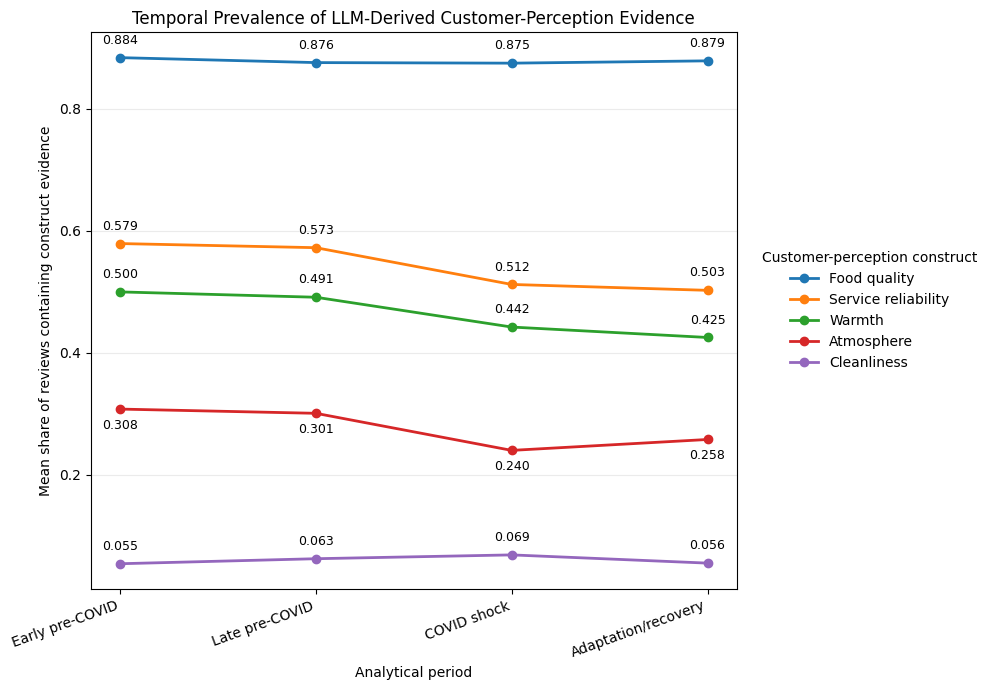

In [ ]:

# Plotting Balanced Temporal Development of LLM Evidence Shares

import matplotlib.pyplot as plt

# 1. Defining the constructs shown in the figure

evidence_plot_constructs = [
    "food_quality",
    "service_reliability",
    "warmth",
    "atmosphere",
    "cleanliness"
]

evidence_plot_labels = {
    "food_quality": "Food quality",
    "service_reliability": "Service reliability",
    "warmth": "Warmth",
    "atmosphere": "Atmosphere",
    "cleanliness": "Cleanliness"
}

evidence_plot_periods = [
    "Early pre-COVID",
    "Late pre-COVID",
    "COVID shock",
    "Adaptation/recovery"
]

# small vertical offsets so labels do not sit directly on the markers
label_offsets = {
    "food_quality": 10,
    "service_reliability": 10,
    "warmth": 10,
    "atmosphere": -14,
    "cleanliness": 10
}

# 2. Drawing one evidence-share trajectory for each construct


fig, ax = plt.subplots(figsize=(10, 7))

for construct in evidence_plot_constructs:

    construct_values = (
        balanced_evidence_mean_table
        .loc[construct, evidence_plot_periods]
        .values
    )

    line = ax.plot(
        evidence_plot_periods,
        construct_values,
        marker="o",
        linewidth=2,
        label=evidence_plot_labels[construct]
    )[0]

    # value labels to each point
    for x, y in zip(evidence_plot_periods, construct_values):
        ax.annotate(
            f"{y:.3f}",
            xy=(x, y),
            xytext=(0, label_offsets[construct]),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )


ax.set_title(
    "Temporal Prevalence of LLM-Derived Customer-Perception Evidence"
)

ax.set_xlabel("Analytical period")
ax.set_ylabel("Mean share of reviews containing construct evidence")

ax.legend(
    title="Customer-perception construct",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False
)

ax.grid(axis="y", alpha=0.25)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**8.7 Repetition and Review-Activity Continuity**

In [ ]:

# Repetition and Review-Activity Continuity Model


# In this step, I estimate the final repetition and review-activity
# continuity model used in the thesis.

# The model includes:

# - early pre-COVID average rating;
# - early pre-COVID log review count;
# - repeated high shares of low-star reviews;
# - continuity of Yelp review activity across the four periods.

# All predictors are standardized within the estimation sample.

# I report odds ratios, confidence intervals, p-values,
# average marginal effects, and model-level fit statistics.


import numpy as np
import pandas as pd
import statsmodels.api as sm

from sklearn.metrics import roc_auc_score



# 1. Defining predictors and readable labels


final_repetition_predictors = [
    "period_avg_stars_early_pre",
    "log_review_count_early_pre",
    "high_low_star_repetition_rate",
    "periods_with_reviews"
]


final_repetition_labels = {
    "period_avg_stars_early_pre":
        "Early pre-COVID average rating",

    "log_review_count_early_pre":
        "Early pre-COVID log review count",

    "high_low_star_repetition_rate":
        "High low-star repetition rate",

    "periods_with_reviews":
        "Periods with reviews"
}

# 2. Creating the complete-case estimation sample


final_repetition_model_df = (
    analysis_df[
        [
            "business_id",
            "closed"
        ]
        +
        final_repetition_predictors
    ]
    .dropna()
    .copy()
)


y = (
    final_repetition_model_df[
        "closed"
    ]
    .astype(int)
)


X = (
    final_repetition_model_df[
        final_repetition_predictors
    ]
    .copy()
)


print(
    "Repetition / continuity estimation sample:",
    len(
        final_repetition_model_df
    )
)


print(
    "Open restaurants:",
    int(
        (
            y
            ==
            0
        )
        .sum()
    )
)


print(
    "Closed restaurants:",
    int(
        y.sum()
    )
)


# 3. Standardizing all predictors

predictor_means = (
    X.mean()
)


predictor_stds = (
    X.std(
        ddof=0
    )
)


zero_variance_predictors = (
    predictor_stds[
        predictor_stds
        ==
        0
    ]
    .index
    .tolist()
)


if zero_variance_predictors:

    raise ValueError(
        "Zero-variance predictors found: "
        f"{zero_variance_predictors}"
    )


X_standardized = (
    X
    -
    predictor_means
) / predictor_stds


X_model = sm.add_constant(
    X_standardized,
    has_constant="add"
)


# 4. Estimating the logistic regression


final_repetition_result = (
    sm.Logit(
        y,
        X_model
    )
    .fit(
        disp=False,
        maxiter=300
    )
)


# 5. Calculating odds ratios and confidence intervals

confidence_intervals = (
    final_repetition_result
    .conf_int()
)


# 6. Calculating average marginal effects

marginal_effects = (
    final_repetition_result
    .get_margeff(
        at="overall",
        method="dydx"
    )
)


marginal_effects_df = (
    marginal_effects
    .summary_frame()
)


# 7. Building the complete predictor-level results table

final_repetition_rows = []


for predictor in (
    final_repetition_predictors
):

    coefficient = (
        final_repetition_result
        .params[
            predictor
        ]
    )


    ci_lower = np.exp(
        confidence_intervals
        .loc[
            predictor,
            0
        ]
    )


    ci_upper = np.exp(
        confidence_intervals
        .loc[
            predictor,
            1
        ]
    )


    average_marginal_effect = (
        marginal_effects_df
        .loc[
            predictor,
            "dy/dx"
        ]
    )


    ame_ci_lower = (
        marginal_effects_df
        .loc[
            predictor,
            "Conf. Int. Low"
        ]
    )


    if "Conf. Int. Hi." in (
        marginal_effects_df.columns
    ):

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                predictor,
                "Conf. Int. Hi."
            ]
        )

    else:

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                predictor,
                "Cont. Int. Hi."
            ]
        )


    final_repetition_rows.append(
        {
            "predictor": predictor,

            "predictor_label": (
                final_repetition_labels[
                    predictor
                ]
            ),

            "odds_ratio": np.exp(
                coefficient
            ),

            "ci_lower": ci_lower,

            "ci_upper": ci_upper,

            "p_value": (
                final_repetition_result
                .pvalues[
                    predictor
                ]
            ),

            "average_marginal_effect": (
                average_marginal_effect
            ),

            "ame_ci_lower": (
                ame_ci_lower
            ),

            "ame_ci_upper": (
                ame_ci_upper
            )
        }
    )


final_repetition_results_df = (
    pd.DataFrame(
        final_repetition_rows
    )
)


final_repetition_results_df[
    "ame_percentage_points"
] = (
    final_repetition_results_df[
        "average_marginal_effect"
    ]
    * 100
)


final_repetition_results_df[
    "ame_ci_lower_pp"
] = (
    final_repetition_results_df[
        "ame_ci_lower"
    ]
    * 100
)


final_repetition_results_df[
    "ame_ci_upper_pp"
] = (
    final_repetition_results_df[
        "ame_ci_upper"
    ]
    * 100
)


# 8. Calculating model-level fit statistics


predicted_probability = (
    final_repetition_result
    .predict(
        X_model
    )
)


final_repetition_auc = (
    roc_auc_score(
        y,
        predicted_probability
    )
)


final_repetition_mcfadden_r2 = (
    1
    -
    (
        final_repetition_result.llf
        /
        final_repetition_result.llnull
    )
)


final_repetition_model_summary_df = (
    pd.DataFrame(
        {
            "N": [
                len(
                    final_repetition_model_df
                )
            ],

            "Closed": [
                int(
                    y.sum()
                )
            ],

            "AIC": [
                final_repetition_result.aic
            ],

            "McFadden_R2": [
                final_repetition_mcfadden_r2
            ],

            "In_sample_AUC": [
                final_repetition_auc
            ]
        }
    )
)


# 9. Displaying full predictor results


print(
    "\n" + "=" * 130
)

print(
    "FINAL REPETITION AND REVIEW-ACTIVITY CONTINUITY RESULTS"
)

print(
    "=" * 130
)


display(
    final_repetition_results_df[
        [
            "predictor_label",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp"
        ]
    ]
    .round(
        4
    )
)


# 10. Displaying model-level statistics


print(
    "\nMODEL-LEVEL SUMMARY"
)


display(
    final_repetition_model_summary_df
    .round(
        {
            "AIC": 3,
            "McFadden_R2": 4,
            "In_sample_AUC": 4
        }
    )
)


# 11. Showing original-scale values by endpoint status


print(
    "\nORIGINAL-SCALE MEANS BY YELP ENDPOINT STATUS"
)


final_repetition_endpoint_means_df = (
    final_repetition_model_df
    .groupby(
        "closed"
    )[
        [
            "high_low_star_repetition_rate",
            "periods_with_reviews"
        ]
    ]
    .mean()
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
)


display(
    final_repetition_endpoint_means_df
    .round(
        4
    )
)

Repetition / continuity estimation sample: 957
Open restaurants: 789
Closed restaurants: 168

FINAL REPETITION AND REVIEW-ACTIVITY CONTINUITY RESULTS


,predictor_label,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp
0,Early pre-COVID average rating,0.9323,0.6953,1.2499,0.6391,-0.5504,-2.8505,1.7498
1,Early pre-COVID log review count,1.7211,1.3555,2.1851,0.0000,4.2594,2.4202,6.0985
2,High low-star repetition rate,1.0355,0.7552,1.4199,0.8285,0.2737,-2.2021,2.7495
3,Periods with reviews,0.1646,0.1282,0.2115,0.0000,-14.1525,-15.5315,-12.7735



MODEL-LEVEL SUMMARY


,N,Closed,AIC,McFadden_R2,In_sample_AUC
0,957,168,533.967,0.4107,0.8828



ORIGINAL-SCALE MEANS BY YELP ENDPOINT STATUS


,high_low_star_repetition_rate,periods_with_reviews
closed,,
Open,0.4030,3.7643
Closed,0.5104,2.2857


**8.8 Image-Based Extension and Incremental Visual Information**

In [ ]:

# Inspecting Candidate Visual Features for the Image Extension


# In this step, I inspect the restaurant-level visual indicators
# before estimating the image-based extension.

# The image features are supplementary and non-temporal because
# Yelp does not provide upload dates for the photos.

# I focus on the seven substantive visual constructs with sufficient
# theoretical relevance and exclude exterior condition and negative
# visual signals from the main specification because their support
# or variation is limited.

# I first examine:
# - coverage of each visual construct;
# - coverage by Yelp endpoint status;
# - restaurant-level distributions;
# - pairwise correlations;
# - and the complete-case sample that would remain if all seven
#   visual constructs were entered together.



# 1. Defining the candidate image features


image_extension_features = [
    "visual_food_appeal_mean",
    "presentation_quality_mean",
    "portion_signal_mean",
    "visual_cleanliness_mean",
    "atmosphere_visual_mean",
    "environment_visual_mean",
    "crowding_signal_mean"
]

image_extension_labels = {
    "visual_food_appeal_mean": "Visual food appeal",
    "presentation_quality_mean": "Presentation quality",
    "portion_signal_mean": "Portion signal",
    "visual_cleanliness_mean": "Visual cleanliness",
    "atmosphere_visual_mean": "Visual atmosphere",
    "environment_visual_mean": "Visual environment",
    "crowding_signal_mean": "Crowding"
}


# 2. Inspecting overall coverage and endpoint support


image_support_rows = []

for feature in image_extension_features:

    feature_df = (
        analysis_df[
            [
                "business_id",
                "closed",
                feature
            ]
        ]
        .dropna(
            subset=[
                feature
            ]
        )
        .copy()
    )

    total_n = len(
        feature_df
    )

    closed_n = int(
        feature_df[
            "closed"
        ].sum()
    )

    open_n = (
        total_n
        -
        closed_n
    )

    image_support_rows.append(
        {
            "feature": feature,
            "label": image_extension_labels[
                feature
            ],
            "available_restaurants": total_n,
            "coverage_full_cohort": (
                total_n
                /
                len(
                    analysis_df
                )
            ),
            "open_restaurants": open_n,
            "closed_restaurants": closed_n
        }
    )


image_extension_support_df = pd.DataFrame(
    image_support_rows
)

print(
    "=" * 115
)

print(
    "SUPPORT FOR CANDIDATE VISUAL FEATURES"
)

print(
    "=" * 115
)

display(
    image_extension_support_df
    .round(
        {
            "coverage_full_cohort": 3
        }
    )
)

# 3. Inspecting restaurant-level visual-feature distributions


image_extension_distribution_df = (
    analysis_df[
        image_extension_features
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max"
        ]
    )
    .T
    .reset_index()
    .rename(
        columns={
            "index": "feature"
        }
    )
)

image_extension_distribution_df[
    "label"
] = (
    image_extension_distribution_df[
        "feature"
    ]
    .map(
        image_extension_labels
    )
)

image_extension_distribution_df = (
    image_extension_distribution_df[
        [
            "feature",
            "label",
            "count",
            "mean",
            "std",
            "min",
            "median",
            "max"
        ]
    ]
)

print(
    "\n" + "=" * 115
)

print(
    "DISTRIBUTIONS OF CANDIDATE VISUAL FEATURES"
)

print(
    "=" * 115
)

display(
    image_extension_distribution_df
    .round(
        3
    )
)


# 4. Inspecting pairwise Spearman correlations


image_extension_correlation_df = (
    analysis_df[
        image_extension_features
    ]
    .corr(
        method="spearman",
        min_periods=20
    )
)

print(
    "\n" + "=" * 115
)

print(
    "SPEARMAN CORRELATIONS AMONG CANDIDATE VISUAL FEATURES"
)

print(
    "=" * 115
)

display(
    image_extension_correlation_df
    .round(
        3
    )
)


# 5. Identifying strongly correlated visual-feature pairs

strong_image_correlation_rows = []

for i, feature_1 in enumerate(
    image_extension_features
):

    for feature_2 in (
        image_extension_features[
            i + 1:
        ]
    ):

        pair_df = (
            analysis_df[
                [
                    feature_1,
                    feature_2
                ]
            ]
            .dropna()
        )

        if len(
            pair_df
        ) < 20:
            continue

        rho = (
            pair_df[
                feature_1
            ]
            .corr(
                pair_df[
                    feature_2
                ],
                method="spearman"
            )
        )

        if abs(
            rho
        ) >= 0.70:

            strong_image_correlation_rows.append(
                {
                    "feature_1": image_extension_labels[
                        feature_1
                    ],
                    "feature_2": image_extension_labels[
                        feature_2
                    ],
                    "pairwise_n": len(
                        pair_df
                    ),
                    "spearman_rho": rho
                }
            )


strong_image_correlations_df = pd.DataFrame(
    strong_image_correlation_rows
)

print(
    "\n" + "=" * 115
)

print(
    "VISUAL-FEATURE PAIRS WITH |SPEARMAN RHO| >= 0.70"
)

print(
    "=" * 115
)

if len(
    strong_image_correlations_df
) > 0:

    display(
        strong_image_correlations_df
        .round(
            {
                "spearman_rho": 3
            }
        )
    )

else:

    print(
        "No candidate visual-feature pairs reached |rho| >= 0.70."
    )



# 6. Checking the complete-case sample for all seven image features

joint_image_complete_df = (
    analysis_df[
        [
            "business_id",
            "closed"
        ]
        +
        image_extension_features
    ]
    .dropna()
    .copy()
)

joint_image_n = len(
    joint_image_complete_df
)

joint_image_closed_n = int(
    joint_image_complete_df[
        "closed"
    ].sum()
)

joint_image_open_n = (
    joint_image_n
    -
    joint_image_closed_n
)

print(
    "\n" + "=" * 115
)

print(
    "JOINT COMPLETE-CASE SUPPORT FOR ALL SEVEN VISUAL FEATURES"
)

print(
    "=" * 115
)

print(
    "Total restaurants:",
    joint_image_n
)

print(
    "Open restaurants:",
    joint_image_open_n
)

print(
    "Closed restaurants:",
    joint_image_closed_n
)

print(
    "Closure share:",
    round(
        joint_image_closed_n
        /
        joint_image_n,
        3
    )
    if joint_image_n > 0
    else np.nan
)

print(
    "Closed events per visual predictor:",
    round(
        joint_image_closed_n
        /
        len(
            image_extension_features
        ),
        2
    )
    if joint_image_n > 0
    else np.nan
)


# 7. Comparing mean visual scores by Yelp endpoint status

image_means_by_status_df = (
    analysis_df
    .groupby(
        "closed"
    )[
        image_extension_features
    ]
    .mean()
    .rename(
        index={
            0: "Open",
            1: "Closed"
        }
    )
    .T
    .reset_index()
    .rename(
        columns={
            "index": "feature"
        }
    )
)

image_means_by_status_df[
    "label"
] = (
    image_means_by_status_df[
        "feature"
    ]
    .map(
        image_extension_labels
    )
)

image_means_by_status_df = (
    image_means_by_status_df[
        [
            "label",
            "Open",
            "Closed"
        ]
    ]
)

print(
    "\n" + "=" * 115
)

print(
    "MEAN VISUAL SCORES BY YELP ENDPOINT STATUS"
)

print(
    "=" * 115
)

display(
    image_means_by_status_df
    .round(
        3
    )
)

SUPPORT FOR CANDIDATE VISUAL FEATURES


,feature,label,available_restaurants,coverage_full_cohort,open_restaurants,closed_restaurants
0,visual_food_appeal_mean,Visual food appeal,530,0.554,437,93
1,presentation_quality_mean,Presentation quality,530,0.554,436,94
2,portion_signal_mean,Portion signal,530,0.554,437,93
3,visual_cleanliness_mean,Visual cleanliness,496,0.518,410,86
4,atmosphere_visual_mean,Visual atmosphere,471,0.492,388,83
5,environment_visual_mean,Visual environment,456,0.476,376,80
6,crowding_signal_mean,Crowding,527,0.551,443,84



DISTRIBUTIONS OF CANDIDATE VISUAL FEATURES


,feature,label,count,mean,std,min,median,max
0,visual_food_appeal_mean,Visual food appeal,530.0,0.530,0.183,-0.5,0.567,0.80
1,presentation_quality_mean,Presentation quality,530.0,0.518,0.180,-0.5,0.567,0.85
2,portion_signal_mean,Portion signal,530.0,0.588,0.174,-0.5,0.600,0.90
3,visual_cleanliness_mean,Visual cleanliness,496.0,0.827,0.108,-0.5,0.850,0.90
4,atmosphere_visual_mean,Visual atmosphere,471.0,0.401,0.116,0.1,0.400,0.70
5,environment_visual_mean,Visual environment,456.0,0.430,0.161,0.1,0.400,0.80
6,crowding_signal_mean,Crowding,527.0,0.040,0.084,0.0,0.000,0.70



SPEARMAN CORRELATIONS AMONG CANDIDATE VISUAL FEATURES


,visual_food_appeal_mean,presentation_quality_mean,portion_signal_mean,visual_cleanliness_mean,atmosphere_visual_mean,environment_visual_mean,crowding_signal_mean
visual_food_appeal_mean,1.000,0.806,0.500,0.760,0.068,-0.397,-0.191
presentation_quality_mean,0.806,1.000,0.252,0.708,0.135,-0.306,-0.222
portion_signal_mean,0.500,0.252,1.000,0.527,0.030,-0.254,-0.143
visual_cleanliness_mean,0.760,0.708,0.527,1.000,0.087,-0.345,-0.210
atmosphere_visual_mean,0.068,0.135,0.030,0.087,1.000,0.484,0.008
environment_visual_mean,-0.397,-0.306,-0.254,-0.345,0.484,1.000,0.279
crowding_signal_mean,-0.191,-0.222,-0.143,-0.210,0.008,0.279,1.000



VISUAL-FEATURE PAIRS WITH |SPEARMAN RHO| >= 0.70


,feature_1,feature_2,pairwise_n,spearman_rho
0,Visual food appeal,Presentation quality,529,0.806
1,Visual food appeal,Visual cleanliness,492,0.760
2,Presentation quality,Visual cleanliness,492,0.708



JOINT COMPLETE-CASE SUPPORT FOR ALL SEVEN VISUAL FEATURES
Total restaurants: 393
Open restaurants: 331
Closed restaurants: 62
Closure share: 0.158
Closed events per visual predictor: 8.86

MEAN VISUAL SCORES BY YELP ENDPOINT STATUS


closed,label,Open,Closed
0,Visual food appeal,0.528,0.539
1,Presentation quality,0.519,0.516
2,Portion signal,0.585,0.601
3,Visual cleanliness,0.828,0.819
4,Visual atmosphere,0.400,0.406
5,Visual environment,0.431,0.422
6,Crowding,0.042,0.034


In [ ]:

# Image-Based Extension


# In this step, I estimate the final image-based analyses

# The image indicators are static restaurant-level variables
# because Yelp does not provide usable photo upload timestamps.

# I examine seven visual constructs:

# - visual food appeal;
# - presentation quality;
# - portion signal;
# - visual cleanliness;
# - visual atmosphere;
# - visual environment;
# - crowding.

# I first summarize the restaurant-level visual indicators.

# I then estimate:

# 1. one visual-only logistic regression for each construct;
# 2. one Yelp-adjusted model for each construct.

# The adjusted model controls for:
# - early pre-COVID average rating;
# - early pre-COVID log review count.

# All continuous predictors are standardized within each
# complete-case estimation sample.

# I report odds ratios, confidence intervals, p-values,
# average marginal effects, and incremental model-fit statistics.




import numpy as np
import pandas as pd
import statsmodels.api as sm
import warnings

from scipy.stats import chi2
from sklearn.metrics import roc_auc_score


# 1. Defining the seven visual constructs


final_image_features = [
    "visual_food_appeal_mean",
    "presentation_quality_mean",
    "portion_signal_mean",
    "visual_cleanliness_mean",
    "atmosphere_visual_mean",
    "environment_visual_mean",
    "crowding_signal_mean"
]


final_image_labels = {
    "visual_food_appeal_mean":
        "Visual food appeal",

    "presentation_quality_mean":
        "Presentation quality",

    "portion_signal_mean":
        "Portion signal",

    "visual_cleanliness_mean":
        "Visual cleanliness",

    "atmosphere_visual_mean":
        "Visual atmosphere",

    "environment_visual_mean":
        "Visual environment",

    "crowding_signal_mean":
        "Crowding"
}


final_image_baseline = [
    "period_avg_stars_early_pre",
    "log_review_count_early_pre"
]


# 2. Creating the final descriptive table

final_image_descriptive_df = (
    analysis_df[
        final_image_features
    ]
    .agg(
        [
            "count",
            "mean",
            "std",
            "median"
        ]
    )
    .T
    .reset_index()
    .rename(
        columns={
            "index": "feature",
            "count": "N",
            "std": "SD"
        }
    )
)


final_image_descriptive_df[
    "construct"
] = (
    final_image_descriptive_df[
        "feature"
    ]
    .map(
        final_image_labels
    )
)


final_image_descriptive_df = (
    final_image_descriptive_df[
        [
            "feature",
            "construct",
            "N",
            "mean",
            "SD",
            "median"
        ]
    ]
)


print(
    "\n" + "=" * 120
)

print(
    "FINAL DESCRIPTIVE STATISTICS FOR VISUAL INDICATORS"
)

print(
    "=" * 120
)


display(
    final_image_descriptive_df
    .round(
        4
    )
)


# 3. Function for one visual-only logistic regression


def fit_final_visual_only_model(
    data,
    visual_predictor,
    construct_label
):

    model_df = (
        data[
            [
                "closed",
                visual_predictor
            ]
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    X = (
        model_df[
            [
                visual_predictor
            ]
        ]
        .copy()
    )


    predictor_mean = (
        X[
            visual_predictor
        ]
        .mean()
    )


    predictor_std = (
        X[
            visual_predictor
        ]
        .std(
            ddof=0
        )
    )


    if predictor_std == 0:

        raise ValueError(
            f"{construct_label}: zero predictor variance"
        )


    X_standardized = (
        (
            X[
                visual_predictor
            ]
            -
            predictor_mean
        )
        /
        predictor_std
    ).to_frame(
        name=visual_predictor
    )


    X_model = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        result = (
            sm.Logit(
                y,
                X_model
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    coefficient = (
        result.params[
            visual_predictor
        ]
    )


    confidence_interval = (
        result
        .conf_int()
        .loc[
            visual_predictor
        ]
    )



    # Average marginal effect


    marginal_effects = (
        result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )


    marginal_effects_df = (
        marginal_effects
        .summary_frame()
    )


    average_marginal_effect = (
        marginal_effects_df
        .loc[
            visual_predictor,
            "dy/dx"
        ]
    )


    ame_ci_lower = (
        marginal_effects_df
        .loc[
            visual_predictor,
            "Conf. Int. Low"
        ]
    )


    if "Conf. Int. Hi." in (
        marginal_effects_df.columns
    ):

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                visual_predictor,
                "Conf. Int. Hi."
            ]
        )

    else:

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                visual_predictor,
                "Cont. Int. Hi."
            ]
        )


    predicted_probability = (
        result.predict(
            X_model
        )
    )


    auc = roc_auc_score(
        y,
        predicted_probability
    )


    pseudo_r2 = (
        1
        -
        (
            result.llf
            /
            result.llnull
        )
    )


    return {
        "feature": visual_predictor,
        "construct": construct_label,
        "N": len(model_df),
        "Closed": int(y.sum()),
        "odds_ratio": np.exp(
            coefficient
        ),
        "ci_lower": np.exp(
            confidence_interval.iloc[0]
        ),
        "ci_upper": np.exp(
            confidence_interval.iloc[1]
        ),
        "p_value": (
            result.pvalues[
                visual_predictor
            ]
        ),
        "average_marginal_effect": (
            average_marginal_effect
        ),
        "ame_ci_lower": ame_ci_lower,
        "ame_ci_upper": ame_ci_upper,
        "pseudo_r2": pseudo_r2,
        "auc": auc
    }


# 4. Estimating all visual-only models

final_visual_only_rows = []


for visual_feature in (
    final_image_features
):

    final_visual_only_rows.append(
        fit_final_visual_only_model(
            data=analysis_df,
            visual_predictor=visual_feature,
            construct_label=(
                final_image_labels[
                    visual_feature
                ]
            )
        )
    )


final_visual_only_df = (
    pd.DataFrame(
        final_visual_only_rows
    )
)


final_visual_only_df[
    "ame_percentage_points"
] = (
    final_visual_only_df[
        "average_marginal_effect"
    ]
    * 100
)


print(
    "\n" + "=" * 135
)

print(
    "FINAL VISUAL-ONLY LOGISTIC REGRESSION RESULTS"
)

print(
    "=" * 135
)


display(
    final_visual_only_df[
        [
            "construct",
            "N",
            "Closed",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "pseudo_r2",
            "auc"
        ]
    ]
    .round(
        4
    )
)


# 5. Function for one Yelp-adjusted image model


def fit_final_image_adjusted_model(
    data,
    visual_predictor,
    construct_label
):

    required_columns = (
        ["closed"]
        +
        final_image_baseline
        +
        [visual_predictor]
    )


    model_df = (
        data[
            required_columns
        ]
        .dropna()
        .copy()
    )


    y = (
        model_df[
            "closed"
        ]
        .astype(int)
    )


    all_predictors = (
        final_image_baseline
        +
        [visual_predictor]
    )


    X = (
        model_df[
            all_predictors
        ]
        .copy()
    )


    predictor_means = (
        X.mean()
    )


    predictor_stds = (
        X.std(
            ddof=0
        )
    )


    zero_variance_predictors = (
        predictor_stds[
            predictor_stds
            ==
            0
        ]
        .index
        .tolist()
    )


    if zero_variance_predictors:

        raise ValueError(
            f"{construct_label}: "
            f"zero-variance predictors "
            f"{zero_variance_predictors}"
        )


    X_standardized = (
        X
        -
        predictor_means
    ) / predictor_stds

    # Benchmark model


    X_benchmark = sm.add_constant(
        X_standardized[
            final_image_baseline
        ],
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        benchmark_result = (
            sm.Logit(
                y,
                X_benchmark
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    # Image-augmented model


    X_augmented = sm.add_constant(
        X_standardized,
        has_constant="add"
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        augmented_result = (
            sm.Logit(
                y,
                X_augmented
            )
            .fit(
                disp=False,
                maxiter=300
            )
        )


    coefficient = (
        augmented_result
        .params[
            visual_predictor
        ]
    )


    confidence_interval = (
        augmented_result
        .conf_int()
        .loc[
            visual_predictor
        ]
    )


    p_value = (
        augmented_result
        .pvalues[
            visual_predictor
        ]
    )


    # Average marginal effect


    marginal_effects = (
        augmented_result
        .get_margeff(
            at="overall",
            method="dydx"
        )
    )


    marginal_effects_df = (
        marginal_effects
        .summary_frame()
    )


    average_marginal_effect = (
        marginal_effects_df
        .loc[
            visual_predictor,
            "dy/dx"
        ]
    )


    ame_ci_lower = (
        marginal_effects_df
        .loc[
            visual_predictor,
            "Conf. Int. Low"
        ]
    )


    if "Conf. Int. Hi." in (
        marginal_effects_df.columns
    ):

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                visual_predictor,
                "Conf. Int. Hi."
            ]
        )

    else:

        ame_ci_upper = (
            marginal_effects_df
            .loc[
                visual_predictor,
                "Cont. Int. Hi."
            ]
        )


    # Model-fit statistics


    benchmark_probability = (
        benchmark_result
        .predict(
            X_benchmark
        )
    )


    augmented_probability = (
        augmented_result
        .predict(
            X_augmented
        )
    )


    benchmark_auc = (
        roc_auc_score(
            y,
            benchmark_probability
        )
    )


    augmented_auc = (
        roc_auc_score(
            y,
            augmented_probability
        )
    )


    benchmark_pseudo_r2 = (
        1
        -
        (
            benchmark_result.llf
            /
            benchmark_result.llnull
        )
    )


    augmented_pseudo_r2 = (
        1
        -
        (
            augmented_result.llf
            /
            augmented_result.llnull
        )
    )


    lr_statistic = (
        2
        *
        (
            augmented_result.llf
            -
            benchmark_result.llf
        )
    )


    lr_p_value = (
        chi2.sf(
            lr_statistic,
            df=1
        )
    )


    return {
        "feature": visual_predictor,
        "construct": construct_label,
        "N": len(model_df),
        "Open": int(
            (
                y
                ==
                0
            )
            .sum()
        ),
        "Closed": int(
            y.sum()
        ),
        "odds_ratio": np.exp(
            coefficient
        ),
        "ci_lower": np.exp(
            confidence_interval.iloc[0]
        ),
        "ci_upper": np.exp(
            confidence_interval.iloc[1]
        ),
        "p_value": p_value,
        "average_marginal_effect": (
            average_marginal_effect
        ),
        "ame_ci_lower": ame_ci_lower,
        "ame_ci_upper": ame_ci_upper,
        "benchmark_aic": (
            benchmark_result.aic
        ),
        "augmented_aic": (
            augmented_result.aic
        ),
        "delta_aic": (
            augmented_result.aic
            -
            benchmark_result.aic
        ),
        "benchmark_pseudo_r2": (
            benchmark_pseudo_r2
        ),
        "augmented_pseudo_r2": (
            augmented_pseudo_r2
        ),
        "delta_pseudo_r2": (
            augmented_pseudo_r2
            -
            benchmark_pseudo_r2
        ),
        "benchmark_auc": (
            benchmark_auc
        ),
        "augmented_auc": (
            augmented_auc
        ),
        "delta_auc": (
            augmented_auc
            -
            benchmark_auc
        ),
        "lr_p_value": (
            lr_p_value
        )
    }


# 6. Estimating all seven adjusted image models


final_image_adjusted_rows = []


for visual_feature in (
    final_image_features
):

    final_image_adjusted_rows.append(
        fit_final_image_adjusted_model(
            data=analysis_df,
            visual_predictor=visual_feature,
            construct_label=(
                final_image_labels[
                    visual_feature
                ]
            )
        )
    )


final_image_adjusted_df = (
    pd.DataFrame(
        final_image_adjusted_rows
    )
)


final_image_adjusted_df[
    "ame_percentage_points"
] = (
    final_image_adjusted_df[
        "average_marginal_effect"
    ]
    * 100
)


final_image_adjusted_df[
    "ame_ci_lower_pp"
] = (
    final_image_adjusted_df[
        "ame_ci_lower"
    ]
    * 100
)


final_image_adjusted_df[
    "ame_ci_upper_pp"
] = (
    final_image_adjusted_df[
        "ame_ci_upper"
    ]
    * 100
)


# 7. Displaying final adjusted image results

print(
    "\n" + "=" * 150
)

print(
    "FINAL YELP-ADJUSTED IMAGE EXTENSION RESULTS"
)

print(
    "=" * 150
)


display(
    final_image_adjusted_df[
        [
            "construct",
            "N",
            "Closed",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "ame_ci_lower_pp",
            "ame_ci_upper_pp",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc",
            "lr_p_value"
        ]
    ]
    .round(
        4
    )
)


# 8. Displaying any p < 0.05 adjusted associations

final_image_significant_df = (
    final_image_adjusted_df[
        final_image_adjusted_df[
            "p_value"
        ]
        <
        0.05
    ]
    .copy()
)


print(
    "\nADJUSTED IMAGE ASSOCIATIONS WITH p < 0.05"
)


display(
    final_image_significant_df[
        [
            "construct",
            "N",
            "Closed",
            "odds_ratio",
            "ci_lower",
            "ci_upper",
            "p_value",
            "ame_percentage_points",
            "delta_aic",
            "delta_pseudo_r2",
            "delta_auc"
        ]
    ]
    .round(
        4
    )
)



print(
    "\n" + "=" * 120
)

print(
    "FINAL IMAGE EXTENSION COMPLETE"
)

print(
    "=" * 120
)


print(
    "Visual constructs analysed:",
    len(
        final_image_adjusted_df
    )
)


print(
    "Adjusted associations with p < 0.05:",
    int(
        (
            final_image_adjusted_df[
                "p_value"
            ]
            <
            0.05
        )
        .sum()
    )
)


FINAL DESCRIPTIVE STATISTICS FOR VISUAL INDICATORS


,feature,construct,N,mean,SD,median
0,visual_food_appeal_mean,Visual food appeal,530.0,0.5298,0.1825,0.5667
1,presentation_quality_mean,Presentation quality,530.0,0.5182,0.1801,0.5667
2,portion_signal_mean,Portion signal,530.0,0.5879,0.1738,0.6000
3,visual_cleanliness_mean,Visual cleanliness,496.0,0.8265,0.1078,0.8500
4,atmosphere_visual_mean,Visual atmosphere,471.0,0.4012,0.1163,0.4000
5,environment_visual_mean,Visual environment,456.0,0.4298,0.1611,0.4000
6,crowding_signal_mean,Crowding,527.0,0.0405,0.0844,0.0000



FINAL VISUAL-ONLY LOGISTIC REGRESSION RESULTS


,construct,N,Closed,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,pseudo_r2,auc
0,Visual food appeal,530,93,1.0638,0.8470,1.3360,0.5950,0.8939,0.0006,0.5270
1,Presentation quality,530,94,0.9880,0.7912,1.2338,0.9154,-0.1757,0.0000,0.4980
2,Portion signal,530,93,1.0970,0.8706,1.3823,0.4325,1.3379,0.0013,0.5561
3,Visual cleanliness,496,86,0.9286,0.7535,1.1445,0.4874,-1.0603,0.0010,0.4594
4,Visual atmosphere,471,83,1.0506,0.8295,1.3305,0.6824,0.7157,0.0004,0.5201
5,Visual environment,456,80,0.9439,0.7399,1.2042,0.6423,-0.8346,0.0005,0.5242
6,Crowding,527,84,0.8977,0.6888,1.1700,0.4245,-1.4446,0.0015,0.5182



FINAL YELP-ADJUSTED IMAGE EXTENSION RESULTS


,construct,N,Closed,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,ame_ci_lower_pp,ame_ci_upper_pp,delta_aic,delta_pseudo_r2,delta_auc,lr_p_value
0,Visual food appeal,530,93,0.9654,0.7673,1.2146,0.7636,-0.4831,-3.6307,2.6644,1.9099,0.0002,0.0001,0.7641
1,Presentation quality,530,94,0.9232,0.7344,1.1606,0.4939,-1.1080,-4.2789,2.0629,1.5354,0.0009,0.0002,0.4955
2,Portion signal,530,93,0.9878,0.7797,1.2514,0.9191,-0.1682,-3.4118,3.0754,1.9897,0.0000,-0.0003,0.9191
3,Visual cleanliness,496,86,0.9114,0.7344,1.1310,0.3997,-1.2575,-4.1771,1.6621,1.2801,0.0016,-0.0016,0.3962
4,Visual atmosphere,471,83,1.1060,0.8674,1.4101,0.4166,1.3973,-1.9706,4.7652,1.3424,0.0015,0.0066,0.4174
5,Visual environment,456,80,1.1172,0.8604,1.4507,0.4056,1.5347,-2.0793,5.1487,1.3132,0.0016,0.0096,0.4073
6,Crowding,527,84,0.9386,0.7255,1.2143,0.6297,-0.8180,-4.1427,2.5068,1.7559,0.0005,-0.0018,0.6213



ADJUSTED IMAGE ASSOCIATIONS WITH p < 0.05


,construct,N,Closed,odds_ratio,ci_lower,ci_upper,p_value,ame_percentage_points,delta_aic,delta_pseudo_r2,delta_auc



FINAL IMAGE EXTENSION COMPLETE
Visual constructs analysed: 7
Adjusted associations with p < 0.05: 0


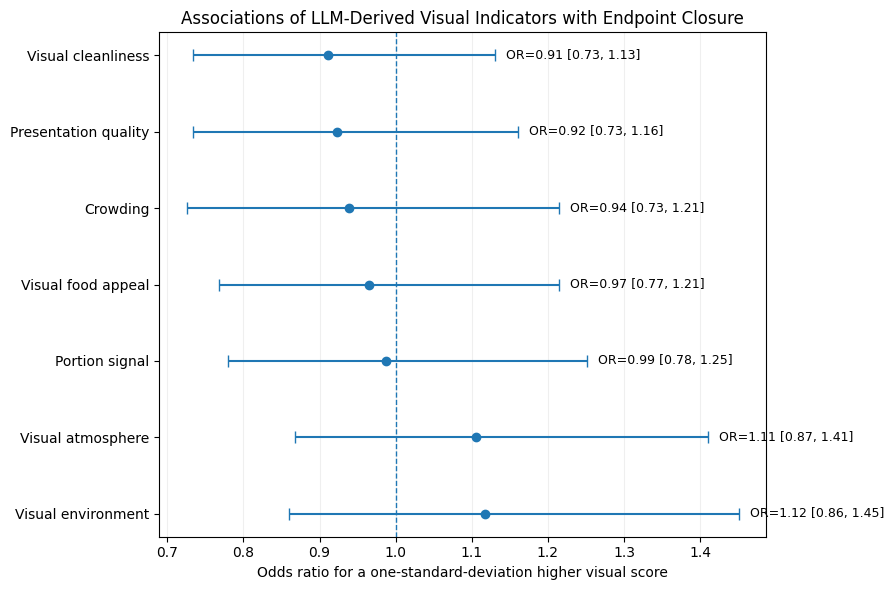

Saved final image-extension forest plot to:
/content/drive/MyDrive/TUM_thesis_digital_marketing/image_visual_associations_forest.png


In [ ]:

# Saving the Final Image-Extension Forest Plot


# In this figure, I summarize the final Yelp-adjusted image models.

# Each point shows the odds ratio for a one-standard-deviation
# increase in the visual indicator, and each horizontal line shows
# its 95% confidence interval.

# The vertical reference line at OR = 1 represents no association
# with Yelp endpoint closure.

# I create the figure directly from final_image_adjusted_df so that
# the plot uses the same results reported in the final analysis.


import matplotlib.pyplot as plt
import numpy as np



# 1. Preparing the final image-model results for plotting


final_image_forest_df = (
    final_image_adjusted_df[
        [
            "construct",
            "odds_ratio",
            "ci_lower",
            "ci_upper"
        ]
    ]
    .copy()
    .sort_values(
        "odds_ratio",
        ascending=False
    )
    .reset_index(
        drop=True
    )
)


# 2. Creating plotting positions


y_positions = np.arange(
    len(
        final_image_forest_df
    )
)


# 3. Drawing odds ratios and 95% confidence intervals

fig, ax = plt.subplots(
    figsize=(
        9,
        6
    )
)


ax.errorbar(
    final_image_forest_df[
        "odds_ratio"
    ],
    y_positions,
    xerr=[
        final_image_forest_df[
            "odds_ratio"
        ]
        -
        final_image_forest_df[
            "ci_lower"
        ],

        final_image_forest_df[
            "ci_upper"
        ]
        -
        final_image_forest_df[
            "odds_ratio"
        ]
    ],
    fmt="o",
    capsize=4
)


# 4. Adding numerical odds-ratio labels


for row_index, row in (
    final_image_forest_df.iterrows()
):

    ax.annotate(
        (
            f"OR={row['odds_ratio']:.2f} "
            f"[{row['ci_lower']:.2f}, "
            f"{row['ci_upper']:.2f}]"
        ),
        xy=(
            row[
                "ci_upper"
            ],
            row_index
        ),
        xytext=(
            8,
            0
        ),
        textcoords="offset points",
        va="center",
        fontsize=9
    )


# 5. Adding the no-association reference line


ax.axvline(
    1,
    linestyle="--",
    linewidth=1
)


# 6. Formatting the figure


ax.set_yticks(
    y_positions
)


ax.set_yticklabels(
    final_image_forest_df[
        "construct"
    ]
)


ax.set_xlabel(
    "Odds ratio for a one-standard-deviation higher visual score"
)


ax.set_title(
    "Associations of LLM-Derived Visual Indicators with Endpoint Closure"
)


ax.grid(
    axis="x",
    alpha=0.2
)


plt.tight_layout()



final_image_forest_path = (
    BASE_DIR
    /
    "image_visual_associations_forest.png"
)


plt.savefig(
    final_image_forest_path,
    dpi=300,
    bbox_inches="tight"
)


plt.show()


print(
    "Saved final image-extension forest plot to:"
)

print(
    final_image_forest_path
)